In [1]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 150,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# # ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()




In [2]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd
from tqdm.auto import tqdm 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc


import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import importlib
%load_ext autoreload
%autoreload 2

import roboarmanalysis as ra
from tqdm.auto import tqdm
from contextlib import contextmanager


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 50,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()



import re
from math import inf
from typing import Iterable

# Variant order for sorting (unknowns last)
_VARIANT_ORDER = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

def assign_conditions(m) -> None:
    """
    Parse m's path/filename and write:
      m.stator_variant ∈ {'A','B','C','D','E'} (or None)
      m.bias_voltage_V : float (or None)
      m.time_halfcycle_s : float seconds (or None)
      m.source_path : str (best-guess source path/filename)
      m._detect_notes : str (human-readable summary)
    Side effects only. Returns None.

    All helpers are defined locally to keep the API surface minimal.
    """

    # -------- helpers (local only) --------
    def _path_of(obj) -> str:
        for a in ("path","filepath","file","filename","source","source_file",
                  "hdf5_path","hdf5","directory","dirpath"):
            v = getattr(obj, a, None)
            if isinstance(v, str) and v:
                return v
        for a in ("meta","info","attrs","props"):
            d = getattr(obj, a, None)
            if isinstance(d, dict):
                for k in ("path","filepath","file","filename","source","source_file",
                          "hdf5_path","hdf5","directory","dirpath"):
                    v = d.get(k)
                    if isinstance(v, str) and v:
                        return v
        return str(obj)

    # Precedence: more specific first; restricted to A..E as requested
    _VARIANT_RULES = [
        (re.compile(r'[/\\]ratchet2_eds([/\\]|_|$)', re.I), 'F'),  # map EDS → E (change if you need 'F')
        (re.compile(r'[/\\]ratchet2_e([/\\]|_|$)',   re.I), 'C'),
        (re.compile(r'[/\\]ratchet2_8ds([/\\]|_|$)', re.I), 'E'),
        (re.compile(r'[/\\]ratchet2_8([/\\]|_|$)',   re.I), 'D'),
        (re.compile(r'[/\\]ratchet2_0([/\\]|_|$)',   re.I), 'B'),
        (re.compile(r'[/\\]ratchet1_0([/\\]|_|$)',   re.I), 'A'),
    ]
    def _detect_variant(s: str):
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(s):
                return lab
        # defensive second pass with separators flattened
        snk = s.replace('\\', '_').replace('/', '_')
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(snk):
                return lab
        return None

    # -------- /helpers --------

    s = _path_of(m)
    notes = []

    v = _detect_variant(s)
    try: setattr(m, "stator_variant", v)
    except Exception: notes.append("warn: cannot set stator_variant")
    notes.append(f"variant: {v}" if v else "variant: not found")


    try: setattr(m, "source_path", s)
    except Exception: pass
    try: setattr(m, "_detect_notes", "; ".join(notes))
    except Exception: pass


def reorder_by_variant(m_list: Iterable, annotate: bool = True):
    """
    Return a NEW list ordered by:
      1) stator_variant (A<B<C<D<E<Unknown),
      2) bias_voltage_V ascending (unknowns last),
      3) time_halfcycle_s ascending (unknowns last),
      4) original index (stable).
    If annotate=True, runs assign_conditions(m) for each m first.
    """
    packed = []
    for i, m in enumerate(m_list):
        if annotate:
            assign_conditions(m)

        v = getattr(m, "stator_variant", None)
        vkey = _VARIANT_ORDER.get(v, 10**6)

        packed.append((vkey, i, m))

    packed.sort(key=lambda t: (t[0], t[1]))
    return [t[-1] for t in packed]




def purge_locscolumns(m, cols=None):
    LOC_COLUMNS_TO_DROP = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']    
    if cols is None:
        cols = LOC_COLUMNS_TO_DROP
    if hasattr(m, 'locs') and isinstance(m.locs, pd.DataFrame):
        drop = [c for c in cols if c in m.locs.columns]
        if drop:
            m.locs = m.locs.drop(columns=drop)



# -------- optional vik colormap (fallback to coolwarm) --------
try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")
    cmc = None

# -------- style --------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 180,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)

In [3]:
import matplotlib as mpl
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 300
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CK_colors = {
    "orange":    (215/255, 131/255,  41/255),
    "beige":     (225/255, 209/255, 180/255),
    "gold":      (226/255, 172/255,  72/255),
    "olive":     (140/255, 135/255,  59/255),
    "offwhite":  (222/255, 224/255, 213/255),
    "palecyan":  (167/255, 197/255, 197/255),
    "darkcyan":  (105/255, 155/255, 155/255),
    "lightblue": ( 73/255, 139/255, 167/255),
    "darkblue":  ( 46/255,  89/255, 108/255),
    "darkred":   (102/255,  27/255,  35/255),
    "grey":      (0.25, 0.25, 0.25),
    "midgrey":   (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black":      (0, 0, 0),
    "white":      (1, 1, 1),
    "warmgold":   (198/255, 161/255,  91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey":      (201/255, 201/255, 201/255),  # #C9C9C9
    "fit_darkgrey":   ( 46/255,  46/255,  46/255),  # #2E2E2E
}

## Load and trim dataset

In [4]:
save_dir = Path(r"R:\_06__Umbrella_Sampling\01_Dataset\260707_L2ss")
keywords = ["fov01"]

exclude_keywords = []


stator_variant = None
full_execution = False

t_UMB = 5
t_DIFF = 30
dt_s = 0.005
t_diff = 1

allowed_missed_percentage = 20
umbrella_step_deg = 20


m_list_loaded = ra.load_multiple_measurements(
    save_dir,
    keywords=keywords,
    exclude_keywords=exclude_keywords,
)

save_dir = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Figure_2")
save_dir_SI = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_2")


 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06__Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: R:\_06__Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1\260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5

 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06__Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_

In [5]:
m_list = m_list_loaded

# for m in m_list:
#     if "UMB" in Path(m.path).name:
#         m.get_flat_particles = types.MethodType(_get_flat_particles, m)

## Process dataset - assign phases, compute polar coordinates, trajectories

In [6]:
def flag_radial_outliers_by_std(
    m,
    *,
    group_col='group',
    rho_col='rho',
    R_col='R',
    flag_col='radial_outlier',
    n_sigma_inner=3.0,
    n_sigma_outer=3.0,
    min_points_sigma=50,
    verbose=True,
):
    """
    Per-particle radial outlier flagger, based on deviations from the per-particle
    radius R_i and per-particle σ(rho)_i.

        R_i      = m.particle_data.loc[i, R_col]
        σ_i      = std of rho over all locs of particle i (finite values only)
        keep if  R_i - n_sigma_inner * σ_i <= rho <= R_i + n_sigma_outer * σ_i

    ALWAYS overwrites `flag_col` completely on each call.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")
    if not hasattr(m, "particle_data"):
        raise AttributeError("m has no attribute 'particle_data'.")

    L = m.locs
    if group_col not in L.columns:
        raise KeyError(f"Column '{group_col}' not found in m.locs.")
    if rho_col not in L.columns:
        raise KeyError(f"Column '{rho_col}' not found in m.locs.")
    if R_col not in m.particle_data.columns:
        raise KeyError(f"Column '{R_col}' not found in m.particle_data.")

    # particle IDs and rho as arrays (no copy of sub-DataFrame)
    pid = L[group_col].astype("Int64")          # nullable ints
    rho = L[rho_col].to_numpy(float)

    # ------------------------------------------------------------------
    # 1) per-particle σ(rho) using a single groupby
    # ------------------------------------------------------------------
    # rows with a defined particle id and finite rho
    mask_valid = pid.notna().to_numpy() & np.isfinite(rho)
    if not np.any(mask_valid):
        if verbose:
            print("RadialOutliers(std): no finite rho values; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    df_valid = L.loc[mask_valid, [group_col, rho_col]]
    # one groupby pass: count + std
    stats = df_valid.groupby(group_col)[rho_col].agg(['count', 'std'])
    # require enough points and finite positive sigma
    good = (stats['count'] >= min_points_sigma) & np.isfinite(stats['std']) & (stats['std'] > 0)
    sigmas_rho = stats.loc[good, 'std']
    n_particles_sigma = int(sigmas_rho.shape[0])

    if n_particles_sigma == 0:
        if verbose:
            print("RadialOutliers(std): no particle met the min_points_sigma criterion; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    # ------------------------------------------------------------------
    # 2) map R_i and σ_i to each row (vectorised)
    # ------------------------------------------------------------------
    R_series = m.particle_data[R_col].astype(float)

    # pandas Int64 -> normal int index series for fast .map
    pid_int = pid.astype("Int64")   # already Int64, but ensures dtype
    R_for_row     = pid_int.map(R_series).to_numpy(float)
    sigma_for_row = pid_int.map(sigmas_rho).to_numpy(float)

    ok = (np.isfinite(rho) &
          np.isfinite(R_for_row) &
          np.isfinite(sigma_for_row) &
          (sigma_for_row > 0))

    lo = R_for_row - n_sigma_inner * sigma_for_row
    hi = R_for_row + n_sigma_outer * sigma_for_row

    mask_out = ok & ((rho < lo) | (rho > hi))

    # ALWAYS overwrite flag column
    L[flag_col] = mask_out
    m.locs = L

    total_flagged = int(mask_out.sum())
    if total_flagged > 0:
        # pid_int is nullable; dropna() then numpy(int)
        pids_flagged = np.unique(pid_int[mask_out].dropna().to_numpy(int))
        n_particles_with_flags = int(pids_flagged.size)
    else:
        n_particles_with_flags = 0

    summary = dict(
        total_flagged_points=total_flagged,
        n_particles_with_flags=n_particles_with_flags,
        n_particles_with_sigma=n_particles_sigma,
    )

    if verbose:
        print(
            f"RadialOutliers(std): σ(rho) estimated for {summary['n_particles_with_sigma']} particles; "
            f"flagged {summary['total_flagged_points']} points "
            f"in {summary['n_particles_with_flags']} particles."
        )

    return summary


import numpy as np

def purge_outlier_rows(
    m,
    flag_cols=('radial_outlier',),
    *,
    verbose=True,
):
    """
    Remove all rows from m.locs where ANY of the given flag columns is True,
    and then drop those flag columns from m.locs.

    Parameters
    ----------
    m : measurement object with .locs DataFrame
    flag_cols : str or iterable of str
        Boolean columns in m.locs that mark rows to remove.
    verbose : bool
        If True, print a short summary.

    Returns
    -------
    n_dropped : int
        Number of rows removed.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")

    L = m.locs
    if isinstance(flag_cols, str):
        flag_cols = [flag_cols]
    else:
        flag_cols = list(flag_cols)

    # sanity: all must exist
    for c in flag_cols:
        if c not in L.columns:
            raise KeyError(f"Column '{c}' not found in m.locs.")

    n0 = len(L)

    # build combined mask of rows to drop
    drop_mask = np.zeros(n0, dtype=bool)
    for c in flag_cols:
        col = L[c]
        if col.dtype != bool:
            flags = col.astype(bool).to_numpy()
        else:
            flags = col.to_numpy()
        drop_mask |= flags

    n_drop = int(drop_mask.sum())

    # keep unflagged rows only
    if n_drop > 0:
        L = L.loc[~drop_mask].copy()
    else:
        L = L.copy()

    # write back
    m.locs = L

def heal_trajectories_nan_sequences(
    m,
    *,
    phases=('ratch-y', 'ratch-x'),
    max_interp_gap=3,
    snapshot_attr='trajectories_raw',
    verbose=True
):
    """
    Heal short NaN runs in m.trajectories[phase] (DataFrames) and flag long runs.

    Assumptions
    -----------
    - m.trajectories[phase][pid] contains UNWRAPPED, cumulative angles
      (can run over many multiples of 2π).
    - No angular wrapping or modulo logic is applied here; we just interpolate
      in the numeric space already present.

    Behaviour
    ---------
    - For each phase and each particle (column):
        * Detect contiguous NaN runs in the 1D series.
        * If run length <= max_interp_gap and both endpoints are finite:
              linearly interpolate between endpoints.
              These points are marked True in nan_interp_mask[phase].
        * Otherwise:
              keep NaNs; mark them as long in nan_long_mask[phase].
    - A one-time snapshot of the original trajectories is stored as:
          getattr(m, snapshot_attr)
      if that attribute does not yet exist.
    - Masks are stored as DataFrames with same index/columns:
          m.nan_long_mask[phase]
          m.nan_interp_mask[phase]
    - A per-phase summary is stored as:
          m.nan_healing_summary[phase] = dict(...)
    - If verbose=True, prints:
          "HealNaN: healed <total_runs> NaN-sequences in <n_rotors> rotors."
      aggregated over all requested phases.
    """

    # ----------------------- one-time snapshot ------------------------
    if not hasattr(m, snapshot_attr):
        traj = getattr(m, 'trajectories', {})
        setattr(m, snapshot_attr, {ph: df.copy() for ph, df in traj.items()})

    # ensure containers on m
    if not hasattr(m, 'nan_long_mask'):
        m.nan_long_mask = {}
    if not hasattr(m, 'nan_interp_mask'):
        m.nan_interp_mask = {}
    if not hasattr(m, 'nan_healing_summary'):
        m.nan_healing_summary = {}

    nan_long_dict = {}
    nan_interp_dict = {}
    summary_per_phase = {}

    # -------------------- main per-phase loop -------------------------
    for phase in phases:
        if not hasattr(m, 'trajectories') or phase not in m.trajectories:
            continue

        df = m.trajectories[phase]
        if not isinstance(df, pd.DataFrame) or df.empty:
            continue

        healed = df.copy()
        long_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
        interp_mask = pd.DataFrame(False, index=df.index, columns=df.columns)

        n_rotors = len(df.columns)
        n_rotors_with_interp = 0
        n_rotors_with_long = 0
        n_runs_short = 0
        n_runs_long = 0

        for col in df.columns:
            s = df[col].to_numpy()
            isnan = np.isnan(s)
            if not isnan.any():
                continue

            n = len(s)
            i = 0
            col_interp = interp_mask[col].to_numpy()
            col_long = long_mask[col].to_numpy()

            has_interp_here = False
            has_long_here = False

            while i < n:
                if not isnan[i]:
                    i += 1
                    continue

                # start of NaN run
                start = i
                while i < n and isnan[i]:
                    i += 1
                end = i  # NaN run is [start, end)

                run_len = end - start
                before = start - 1
                after = end

                has_before = (before >= 0) and np.isfinite(s[before])
                has_after = (after < n) and np.isfinite(s[after])

                if run_len <= max_interp_gap and has_before and has_after:
                    # short, bridgeable gap → plain linear interpolation
                    y0 = s[before]
                    y1 = s[after]
                    t = np.arange(1, run_len + 1, dtype=float) / (run_len + 1)
                    vals = (1.0 - t) * y0 + t * y1

                    healed[col].iloc[start:end] = vals
                    col_interp[start:end] = True
                    has_interp_here = True
                    n_runs_short += 1
                else:
                    # long gap or missing endpoints → keep NaNs, mark as long
                    col_long[start:end] = True
                    has_long_here = True
                    n_runs_long += 1

            interp_mask[col] = col_interp
            long_mask[col] = col_long

            if has_interp_here:
                n_rotors_with_interp += 1
            if has_long_here:
                n_rotors_with_long += 1

        # write back per phase
        m.trajectories[phase] = healed
        m.nan_long_mask[phase] = long_mask
        m.nan_interp_mask[phase] = interp_mask

        summary = dict(
            n_rotors=n_rotors,
            n_rotors_with_interp=n_rotors_with_interp,
            n_rotors_with_long=n_rotors_with_long,
            n_runs_short=n_runs_short,
            n_runs_long=n_runs_long,
            max_interp_gap=max_interp_gap,
        )
        m.nan_healing_summary[phase] = summary

        nan_long_dict[phase] = long_mask
        nan_interp_dict[phase] = interp_mask
        summary_per_phase[phase] = summary

    # ------------------------- minimal verbose output -------------------------
    if verbose and summary_per_phase:
        # total number of healed NaN-runs over all phases
        total_healed_runs = sum(s["n_runs_short"] for s in summary_per_phase.values())

        # set of rotors that had at least one healed point in any phase
        healed_rotors = set()
        for df_interp in nan_interp_dict.values():
            cols = df_interp.columns[(df_interp.sum(axis=0) > 0).to_numpy()]
            for c in cols:
                try:
                    healed_rotors.add(int(c))
                except Exception:
                    healed_rotors.add(c)

        print(
            f"HealNaN: healed {total_healed_runs} NaN-sequences "
            f"in {len(healed_rotors)} rotors."
        )


In [7]:
# Assign phases, convert to polar coordinates, compute trajectories
columns_to_drop = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']
allowed_missed_percentage = 20

t_UMB = 5
t_DIFF = 30
dt_s = 0.005
t_diff = 1


for idx, m in enumerate(m_list):
    name = Path(m.path).name.lower()

    if "umb" in name:
        m.protocol = {}
        m.protocol["diff"] = (0, t_diff)

        n_windows = int(round(360 / umbrella_step_deg))
        if abs(n_windows * umbrella_step_deg - 360) > 1e-9:
            raise ValueError(
                f"umbrella_step_deg={umbrella_step_deg} does not divide 360 cleanly."
            )

        # Important:
        # Check "ccw" before "cw", because "ccw" contains the substring "cw".
        if "ccw" in name:
            direction = "ccw"
        elif "cw" in name:
            direction = "cw"
        else:
            direction = "ccw"

        if direction == "cw":
            umbrella_degs = [(360 - i * umbrella_step_deg) % 360 for i in range(n_windows)]
        else:
            umbrella_degs = [(i * umbrella_step_deg) % 360 for i in range(n_windows)]

        for i, deg in enumerate(umbrella_degs):
            start = t_diff + t_UMB * i
            m.protocol[f"deg-{deg}"] = (start, start + t_UMB)

        umbrella_end = t_diff + t_UMB * n_windows

        m.protocol["umbrella"] = (t_diff, umbrella_end)
        m.protocol["all"] = (0, umbrella_end)

    if "diff" in name:
        m.protocol = {"diff": (0, t_DIFF)}

    m._has_protocol = True
    m._num_phases = len(m.protocol)


In [8]:
ra.fit_circles_with_reference_measurement(m_list, m_list, particles=None)


for idx, m in enumerate(m_list):
    if hasattr(m, "protocol") and "all" in m.protocol:
        t0, t1 = m.protocol["all"]
        duration_s = t1 - t0
    else:
        duration_s = (m.locs["frame"].max() - m.locs["frame"].min() + 1) * dt_s

    expected_frames = duration_s / dt_s
    frame_threshold = (1 - allowed_missed_percentage / 100) * expected_frames


    counts = m.locs.groupby("group")["frame"].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    purge_locscolumns(m, cols = columns_to_drop)
    
    print(str(idx) + ': ' + Path(m.path).name + ' ' + str(len(m.whitelist)) + ' particles.')


for idx, m in enumerate(m_list):
    flag_radial_outliers_by_std(m, n_sigma_inner=4, n_sigma_outer=4)
    purge_outlier_rows(m)
    m.calc_trajectories()
    heal_trajectories_nan_sequences(m,phases=('umbrella'),max_interp_gap=3,verbose=True)


Fitting circles for whitelist:


  0%|          | 0/241 [00:00<?, ?it/s]

Compute polar coordinates for all measurements.
0: 260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 217 particles.
1: 260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5 215 particles.
2: 260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_render_picked.hdf5 214 particles.
RadialOutliers(std): σ(rho) estimated for 241 particles; flagged 3719 points in 241 particles.


Phases:   0%|          | 0/21 [00:00<?, ?it/s]

  diff:   0%|          | 0/217 [00:00<?, ?it/s]

  deg-0:   0%|          | 0/217 [00:00<?, ?it/s]

... (41 outputs left out)

  all:   0%|          | 0/215 [00:00<?, ?it/s]

RadialOutliers(std): σ(rho) estimated for 241 particles; flagged 4447 points in 229 particles.


Phases:   0%|          | 0/1 [00:00<?, ?it/s]

  diff:   0%|          | 0/214 [00:00<?, ?it/s]

### _[Inspect individual particle behavior]_

In [9]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps


try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = colormaps.get_cmap("coolwarm")


def plot_diff_multi_umb_quickcheck(
    m_list,
    particles=None,
    diff_phase="diff",
    umb_phase="umbrella",
    flat_threshold_kbt=1.0,
    polar_rmax=500,
    bins=np.deg2rad(np.arange(-180, 185, 5)),
    max_particles=None,
    show_only_flat=False,

    # filters
    min_radius_nm=None,
    max_radius_nm=None,
    min_diff_barrier_kbt=None,
    max_diff_barrier_kbt=None,

    # lightweight controls
    figsize=None,
    dpi=80,
    scatter_max_points_diff=3500,
    scatter_max_points_umb_per_window=700,
    trajectory_max_points=3000,
    close_after_show=True,
    random_seed=1,

    # compact layout
    width_ratios=(0.95, 1.45, 0.95, 1.45, 1.35),
    left=0.04,
    right=0.99,
    bottom=0.11,
    top=0.86,
    wspace=0.28,
    hspace=0.42,

    # appearance
    diff_marker_size=5,
    umb_marker_size=4,
    diff_alpha=0.20,
    umb_alpha=0.28,
    traj_lw=0.8,
    energy_lw_diff=1.7,
    energy_lw_umb=1.4,
    circle_lw=1.15,
    circle_color="#D99A00",
):
    """
    Lightweight quickcheck plot:
      - one figure per rotor
      - all scatter clouds rasterized
      - compact default figure size
      - no umbrella shading
      - chronological umbrella window order
      - circle overlay
      - radius / barrier filters
      - figures closed after display
    """

    rng = np.random.default_rng(random_seed)

    c_diff = _vik(0.22)
    c_flat = "#AA752F"
    c_grey = "0.25"
    umb_cmap = colormaps.get_cmap("tab10")
    reds = colormaps.get_cmap("Reds")

    def is_umb(m):
        return "umb" in Path(str(m.path)).name.lower()

    def is_diff(m):
        name = Path(str(m.path)).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def short_name(m):
        name = Path(str(m.path)).name
        m_step = re.search(r"_(\d+)deg_", name)
        m_volt = re.search(r"_(\d+)V_", name)
        step = f"{m_step.group(1)}deg" if m_step else "UMB"
        volt = f"{m_volt.group(1)}V" if m_volt else ""
        return f"{volt} {step}".strip()

    def locs_with_time(m):
        locs = m.locs.copy()
        if "t" not in locs.columns:
            if "frame" not in locs.columns:
                raise ValueError(f"{Path(str(m.path)).name}: neither 't' nor 'frame' found in m.locs.")
            locs["t"] = locs["frame"] * float(m._average_tpf)
        return locs

    def phase_df(m, particle, phase):
        if not hasattr(m, "protocol") or phase not in m.protocol:
            return locs_with_time(m).iloc[0:0].copy()
        locs = locs_with_time(m)
        t0, t1 = m.protocol[phase][:2]
        return locs[
            (locs["group"].astype(int) == int(particle))
            & (locs["t"] >= t0)
            & (locs["t"] < t1)
        ].copy()

    def downsample_df(df, nmax):
        if nmax is None or len(df) <= nmax:
            return df
        idx = rng.choice(df.index.to_numpy(), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return df.loc[idx]

    def downsample_xy(x, y, nmax):
        x = np.asarray(x)
        y = np.asarray(y)
        if nmax is None or len(x) <= nmax:
            return x, y
        idx = rng.choice(np.arange(len(x)), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return x[idx], y[idx]

    def energy_from_phi(phi):
        phi = np.asarray(phi, dtype=float)
        phi = ((phi + np.pi) % (2 * np.pi)) - np.pi
        phi = phi[np.isfinite(phi)]

        counts, edges = np.histogram(phi, bins=bins, density=False)
        centers = 0.5 * (edges[:-1] + edges[1:])

        p = counts.astype(float)
        if p.sum() > 0:
            p /= p.sum()

        E = np.full_like(p, np.nan, dtype=float)
        mask = p > 0
        E[mask] = -np.log(p[mask])

        if np.isfinite(E).any():
            E -= np.nanmin(E)
            amp = float(np.nanmax(E) - np.nanmin(E))
        else:
            amp = np.nan

        return centers, E, amp

    def style_ax(ax):
        for s in ax.spines.values():
            s.set_linewidth(0.6)
            s.set_color(c_grey)
        ax.tick_params(length=2.0, width=0.6, colors=c_grey, labelsize=7)
        ax.xaxis.label.set_color(c_grey)
        ax.yaxis.label.set_color(c_grey)
        ax.title.set_color(c_grey)
        ax.grid(False)

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"], fontsize=7)

    def get_particle_circle(m, particle):
        xc = yc = R = np.nan

        if not hasattr(m, "particle_data"):
            return xc, yc, R

        pd = m.particle_data

        try:
            row = None

            if hasattr(pd, "index") and int(particle) in pd.index:
                row = pd.loc[int(particle)]
            else:
                for col in ["particle", "particle_id", "pid", "group", "track", "trajectory"]:
                    if hasattr(pd, "columns") and col in pd.columns:
                        hit = pd[pd[col].astype(int) == int(particle)]
                        if len(hit):
                            row = hit.iloc[0]
                            break

            if row is None:
                return xc, yc, R

            for key in ["xc", "x0", "center_x", "cx"]:
                if key in row:
                    xc = float(row[key])
                    break
            for key in ["yc", "y0", "center_y", "cy"]:
                if key in row:
                    yc = float(row[key])
                    break
            for key in ["R", "r", "radius", "radius_nm"]:
                if key in row:
                    R = float(row[key])
                    break

        except Exception:
            pass

        return xc, yc, R

    def chronological_umb_windows(m_umb):
        if not hasattr(m_umb, "protocol"):
            return []

        windows = []
        for name, val in m_umb.protocol.items():
            if not str(name).startswith("deg-"):
                continue
            try:
                t0 = float(val[0])
                deg = float(str(name).replace("deg-", ""))
                windows.append((t0, deg, name))
            except Exception:
                continue

        windows = sorted(windows, key=lambda x: (x[0], x[1]))
        return [w[2] for w in windows]

    def draw_xy_or_polar_scatter(ax, df, m, particle, color, title, marker_size, alpha, open_marker=False, nmax=1000):
        xc, yc, R = get_particle_circle(m, particle)
        has_xy = ("x" in df.columns) and ("y" in df.columns)
        has_phi_rho = ("phi" in df.columns) and ("rho" in df.columns)

        d = downsample_df(df, nmax)

        if has_xy:
            if open_marker:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(xc) and np.isfinite(yc) and np.isfinite(R) and R > 0:
                th = np.linspace(0, 2 * np.pi, 361)
                ax.plot(
                    xc + R * np.cos(th),
                    yc + R * np.sin(th),
                    color=circle_color,
                    lw=circle_lw,
                    zorder=10,
                )
                ax.plot([xc], [yc], marker="+", ms=4.5, mew=0.8, color=circle_color, zorder=11)

                rr = max(float(polar_rmax), float(R * 1.15))
                ax.set_xlim(xc - rr, xc + rr)
                ax.set_ylim(yc - rr, yc + rr)

            ax.set_aspect("equal", adjustable="box")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

        elif has_phi_rho:
            if open_marker:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(R) and R > 0:
                th = np.linspace(-np.pi, np.pi, 361)
                ax.plot(th, np.full_like(th, R), color=circle_color, lw=circle_lw, zorder=10)

            ax.set_rlim(0, polar_rmax)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(True, lw=0.35, alpha=0.30)
            ax.set_title(title, fontsize=8)

        else:
            ax.text(
                0.5, 0.5, "no x/y or phi/rho",
                ha="center", va="center",
                transform=ax.transAxes,
                fontsize=8, color=c_grey,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

    m_diff = next((m for m in m_list if is_diff(m)), None)
    m_umbs = [m for m in m_list if is_umb(m)]

    if m_diff is None:
        raise ValueError("No standalone DIFF dataset found from m.path.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB datasets found from m.path.")

    if particles is None:
        if hasattr(m_diff, "whitelist"):
            particles = sorted(map(int, m_diff.whitelist))
        else:
            particles = sorted(map(int, m_diff.locs["group"].unique()))
    else:
        particles = list(map(int, particles))

    present_diff = set(map(int, m_diff.locs["group"].unique()))
    present_umbs = [set(map(int, m.locs["group"].unique())) for m in m_umbs]

    particles = [
        p for p in particles
        if p in present_diff and any(p in present for present in present_umbs)
    ]

    particle_records = []
    for particle in particles:
        df_diff = phase_df(m_diff, particle, diff_phase)
        if df_diff.empty or "phi" not in df_diff.columns:
            continue

        _, _, amp_diff = energy_from_phi(df_diff["phi"].to_numpy())
        _, _, R = get_particle_circle(m_diff, particle)

        if min_radius_nm is not None and (not np.isfinite(R) or R < min_radius_nm):
            continue
        if max_radius_nm is not None and (not np.isfinite(R) or R > max_radius_nm):
            continue
        if min_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff < min_diff_barrier_kbt):
            continue
        if max_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff > max_diff_barrier_kbt):
            continue

        particle_records.append((particle, amp_diff, R))

    if max_particles is not None:
        particle_records = particle_records[:int(max_particles)]

    flat_particles = []

    n_umbs = len(m_umbs)
    if figsize is None:
        figsize = (13.2, 2.8 + 1.55 * max(0, n_umbs - 1))

    for particle, amp_diff, R_particle in particle_records:
        df_diff = phase_df(m_diff, particle, diff_phase)
        is_flat_particle = np.isfinite(amp_diff) and amp_diff <= flat_threshold_kbt

        if show_only_flat and not is_flat_particle:
            continue

        if is_flat_particle:
            flat_particles.append(int(particle))

        has_xy_diff = ("x" in df_diff.columns) and ("y" in df_diff.columns)

        fig = plt.figure(figsize=figsize, dpi=dpi)

        gs = fig.add_gridspec(
            n_umbs,
            5,
            width_ratios=width_ratios,
            left=left,
            right=right,
            bottom=bottom,
            top=top,
            wspace=wspace,
            hspace=hspace,
        )

        if has_xy_diff:
            ax_diff_scatter = fig.add_subplot(gs[:, 0])
        else:
            ax_diff_scatter = fig.add_subplot(gs[:, 0], projection="polar")

        ax_diff_traj = fig.add_subplot(gs[:, 1])
        ax_energy = fig.add_subplot(gs[:, 4])

        draw_xy_or_polar_scatter(
            ax=ax_diff_scatter,
            df=df_diff,
            m=m_diff,
            particle=particle,
            color=c_diff,
            title="free diffusion scatter",
            marker_size=diff_marker_size,
            alpha=diff_alpha,
            open_marker=False,
            nmax=scatter_max_points_diff,
        )

        t = df_diff["t"].to_numpy() - df_diff["t"].iloc[0]
        phi_u = np.unwrap(df_diff["phi"].to_numpy()) / (2 * np.pi)
        t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
        ax_diff_traj.plot(t_ds, phi_ds, color=c_diff, lw=traj_lw)
        ax_diff_traj.set_title("free diffusion trajectory", fontsize=8)
        ax_diff_traj.set_xlabel("time / s", fontsize=7)
        ax_diff_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
        style_ax(ax_diff_traj)

        c, E, amp = energy_from_phi(df_diff["phi"].to_numpy())
        ax_energy.plot(c, E, color=c_diff, lw=energy_lw_diff, label=f"free diff, ΔE={amp:.2f}")

        for umb_idx, m_umb in enumerate(m_umbs):
            umb_color = umb_cmap(umb_idx % 10)
            umb_label = short_name(m_umb)
            umb_windows = chronological_umb_windows(m_umb)

            window_colors = [
                reds(v) for v in np.linspace(0.25, 1.0, max(len(umb_windows), 1))
            ]

            df_umb = phase_df(m_umb, particle, umb_phase)
            has_xy_umb = ("x" in df_umb.columns) and ("y" in df_umb.columns)

            if has_xy_umb:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2])
            else:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2], projection="polar")

            ax_umb_traj = fig.add_subplot(gs[umb_idx, 3])

            any_window_data = False
            for phase_name, window_color in zip(umb_windows, window_colors):
                dfw = phase_df(m_umb, particle, phase_name)
                if dfw.empty:
                    continue
                any_window_data = True

                draw_xy_or_polar_scatter(
                    ax=ax_umb_scatter,
                    df=dfw,
                    m=m_umb,
                    particle=particle,
                    color=window_color,
                    title=f"umbrella windows: {umb_label}",
                    marker_size=umb_marker_size,
                    alpha=umb_alpha,
                    open_marker=True,
                    nmax=scatter_max_points_umb_per_window,
                )

            if not any_window_data:
                ax_umb_scatter.text(
                    0.5, 0.5, "no window localizations",
                    ha="center", va="center",
                    transform=ax_umb_scatter.transAxes,
                    fontsize=8, color=c_grey,
                )
                ax_umb_scatter.set_xticks([])
                ax_umb_scatter.set_yticks([])
                ax_umb_scatter.set_title(f"umbrella windows: {umb_label}", fontsize=8)

            if not df_umb.empty and "phi" in df_umb.columns:
                t = df_umb["t"].to_numpy() - df_umb["t"].iloc[0]
                phi_u = np.unwrap(df_umb["phi"].to_numpy()) / (2 * np.pi)
                t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
                ax_umb_traj.plot(t_ds, phi_ds, color=umb_color, lw=traj_lw)

                c, E, amp = energy_from_phi(df_umb["phi"].to_numpy())
                ax_energy.plot(c, E, color=umb_color, lw=energy_lw_umb, label=f"{umb_label}, raw ΔE={amp:.2f}")
            else:
                ax_umb_traj.text(
                    0.5, 0.5, "no localizations",
                    ha="center", va="center",
                    transform=ax_umb_traj.transAxes,
                    fontsize=8, color=c_grey,
                )

            ax_umb_traj.set_title(f"umbrella trajectory: {umb_label}", fontsize=8)
            ax_umb_traj.set_xlabel("time / s", fontsize=7)
            ax_umb_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
            style_ax(ax_umb_traj)

        ax_energy.axhline(
            flat_threshold_kbt,
            color=c_flat,
            lw=0.8,
            ls="--",
            alpha=0.8,
            label=f"flat threshold {flat_threshold_kbt:.1f} kBT",
        )
        ax_energy.set_title("Boltzmann inversion consistency", fontsize=8)
        ax_energy.set_xlabel(r"$\varphi$", fontsize=7)
        ax_energy.set_ylabel(r"$E-E_\mathrm{min}$ / $k_BT$", fontsize=7)
        pi_axis(ax_energy)
        style_ax(ax_energy)
        ax_energy.legend(frameon=False, fontsize=6, loc="best")

        title_color = c_flat if is_flat_particle else c_grey
        flat_txt = " | FLAT" if is_flat_particle else ""
        radius_txt = f"   R = {R_particle:.1f} nm" if np.isfinite(R_particle) else ""

        fig.suptitle(
            f"Particle {particle}{flat_txt}   ΔE_diff = {amp_diff:.2f} kBT{radius_txt}",
            x=0.04,
            y=0.965,
            ha="left",
            fontsize=10,
            fontweight="bold",
            color=title_color,
        )

        plt.show()
        plt.close(fig)

    m_diff.flat_particles = flat_particles

    for m_umb in m_umbs:
        present_umb = set(map(int, m_umb.locs["group"].unique()))
        m_umb.flat_particles = [p for p in flat_particles if p in present_umb]

    return flat_particles

In [10]:
# %matplotlib inline

# flat_particles = plot_diff_multi_umb_quickcheck(
#     m_list,
#     particles=None,
#     flat_threshold_kbt=1.5,
#     max_particles=None,
#     show_only_flat=False,
#     min_radius_nm=None,
#     max_radius_nm=None,
#     min_diff_barrier_kbt=None,
#     max_diff_barrier_kbt=None,
#     figsize=(11.2, 3.8),
#     scatter_max_points_diff=2500,
#     scatter_max_points_umb_per_window=500,
#     trajectory_max_points=2000,
# )

# stop

## Identify calibration rotors and compute in situ bias strength

####  i. Identify calibration rotors based on radii and flat energy landscape

In [11]:
def identify_calibration_target_rotors(
    m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=1.0,
    threshold_kBT=1.0,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=None,
    save_prefix="SI_flat_calibration_rotors",
    stator_variant=None,
    show_marginals=True,
    show_target_rotors=False,
    nbins_radius_marginal=36,
    nbins_energy_marginal=36,
    energy_lw=1.15,
    energy_alpha=0.72,
    scatter_s_other=11,
    scatter_s_selected=15,
    C=None,
    radius_selection_mode="gmm2",      # "gmm2" or "fixed"
    radius_filter_source="gmm",        # "manual" or "gmm"
    gmm_n_init=12,
    gmm_max_iter=300,
    gmm_tol=1e-6,
    gmm_min_sigma_nm=1.0,
    print_radius_fit=True,
    overlay_radius_fit=True,
    store_rotors_to_m=True,
    target_radius_n_sigma=1.0,
    target_min_dG_kBT=None,            # None -> use threshold_kBT
):
    """
    Identify rotor candidates from radius, DIFF landscape, and UMB-window coverage.

    Stores only:
        m.flat_rotors
        m.target_rotors

    Does not return anything.
    Does not create:
        m.flat_particles
        m.target_particles
        m.flat_particles_reliable
        m.calibration_rotors

    flat_rotors:
        small-radius GMM/manual component
        low DIFF energy landscape
        sufficient UMB-window coverage

    target_rotors:
        large-radius GMM component
        high DIFF energy landscape
        sufficient UMB-window coverage

    Figure behavior:
        always shows flat/calibration candidates in the scatter and energy panels
        optionally highlights target candidates in the scatter panel only
        never shows target energy landscapes
    """

    from pathlib import Path
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    required_colors = [
        "orange", "gold", "olive", "lightblue", "darkblue", "darkcyan",
        "darkred", "grey", "lightgrey", "black",
    ]
    missing = [k for k in required_colors if k not in C]
    if missing:
        raise ValueError(f"C is missing required color keys: {missing}")

    C = dict(C)

    nbins = int(nbins)
    smooth_bins = int(smooth_bins)

    if target_min_dG_kBT is None:
        target_min_dG_kBT = float(threshold_kBT)

    if nbins < 4:
        raise ValueError("nbins must be >= 4.")
    if smooth_bins < 1:
        raise ValueError("smooth_bins must be >= 1.")
    if smooth_bins % 2 == 0:
        raise ValueError("smooth_bins must be odd, e.g. 1, 3, 5, 7.")
    if radius_selection_mode not in ("gmm2", "fixed"):
        raise ValueError("radius_selection_mode must be 'gmm2' or 'fixed'.")
    if radius_filter_source not in ("manual", "gmm"):
        raise ValueError("radius_filter_source must be 'manual' or 'gmm'.")
    if radius_selection_mode == "fixed" and radius_filter_source == "gmm":
        raise ValueError("radius_filter_source='gmm' requires radius_selection_mode='gmm2'.")
    if float(radius_sigma_nm) <= 0:
        raise ValueError("radius_sigma_nm must be > 0.")
    if float(radius_n_sigma) <= 0:
        raise ValueError("radius_n_sigma must be > 0.")
    if float(target_radius_n_sigma) <= 0:
        raise ValueError("target_radius_n_sigma must be > 0.")

    bins = np.linspace(-np.pi, np.pi, nbins + 1)
    phi_centers = 0.5 * (bins[:-1] + bins[1:])

    def is_standalone_diff(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def is_umb(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        if "diff" in name:
            return False
        if "umb" in name:
            return True
        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def get_group_array(m):
        if "group" not in m.locs.columns:
            raise ValueError("m.locs must contain 'group'.")
        return m.locs["group"].to_numpy(dtype=int)

    def get_phi_array(m):
        if "phi" not in m.locs.columns:
            raise ValueError("m.locs must contain 'phi'. Run polar_coordinates() first.")
        return m.locs["phi"].to_numpy(dtype=float)

    def get_time_array(m):
        if "t" in m.locs.columns:
            return m.locs["t"].to_numpy(dtype=float)
        if "averagetime" in m.locs.columns:
            return m.locs["averagetime"].to_numpy(dtype=float)
        if "time" in m.locs.columns:
            return m.locs["time"].to_numpy(dtype=float)
        if "time_s" in m.locs.columns:
            return m.locs["time_s"].to_numpy(dtype=float)
        if hasattr(m, "_average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m._average_tpf)
        if hasattr(m, "average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m.average_tpf)
        if hasattr(m, "fps") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) / float(m.fps)

        raise ValueError(
            f"UMB file {Path(str(getattr(m, 'path', ''))).name} needs time information."
        )

    def get_particles(m):
        return set(get_group_array(m))

    def get_R_nm(m, p):
        if not hasattr(m, "particle_data"):
            return np.nan

        pd_ = m.particle_data
        p = int(p)

        if hasattr(pd_, "loc"):
            if p in pd_.index and "R" in pd_.columns:
                return float(pd_.loc[p, "R"])
            if "group" in pd_.columns and "R" in pd_.columns:
                d = pd_[pd_["group"].astype(int) == p]
                if len(d):
                    return float(d["R"].iloc[0])
            return np.nan

        if isinstance(pd_, dict):
            try:
                if "R" in pd_:
                    R = pd_["R"]
                    if isinstance(R, dict):
                        return float(R[p])
                    return float(np.asarray(R, dtype=float)[p])
                if p in pd_ and isinstance(pd_[p], dict) and "R" in pd_[p]:
                    return float(pd_[p]["R"])
            except Exception:
                return np.nan

        try:
            return float(pd_[p]["R"])
        except Exception:
            return np.nan

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            match = re.match(r"^deg-(\d+(?:\.\d+)?)$", str(key))
            if not match:
                continue

            while (
                isinstance(value, (tuple, list))
                and len(value) == 1
                and isinstance(value[0], (tuple, list))
            ):
                value = value[0]

            deg = float(match.group(1))
            t0 = float(value[0])
            t1 = float(value[1])
            windows.append((t0, deg, str(key), t0, t1))

        return [(deg, key, t0, t1) for _, deg, key, t0, t1 in sorted(windows, key=lambda x: (x[0], x[1]))]

    def circular_fill_nan(y):
        y = np.asarray(y, dtype=float)
        out = y.copy()
        finite = np.isfinite(out)

        if finite.all():
            return out
        if finite.sum() == 0:
            return out
        if finite.sum() == 1:
            out[~finite] = out[finite][0]
            return out

        idx = np.arange(len(out))
        valid_idx = idx[finite]
        valid_y = out[finite]

        idx_ext = np.concatenate([valid_idx - len(out), valid_idx, valid_idx + len(out)])
        y_ext = np.concatenate([valid_y, valid_y, valid_y])

        out[~finite] = np.interp(idx[~finite], idx_ext, y_ext)
        return out

    def circular_moving_mean(y, window_bins):
        y = np.asarray(y, dtype=float)

        if window_bins <= 1:
            return y.copy()

        y_filled = circular_fill_nan(y)
        half = window_bins // 2
        padded = np.concatenate([y_filled[-half:], y_filled, y_filled[:half]])
        kernel = np.ones(window_bins, dtype=float) / float(window_bins)

        return np.convolve(padded, kernel, mode="valid")

    def boltzmann_inverse_from_phi(phi):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        n_phi = int(len(phi))
        E_raw = np.full(nbins, np.nan, dtype=float)
        E = np.full(nbins, np.nan, dtype=float)

        if n_phi < int(min_diff_locs):
            return E_raw, E, np.nan, n_phi

        counts, _ = np.histogram(phi, bins=bins)
        p = counts.astype(float)

        if p.sum() <= 0:
            return E_raw, E, np.nan, n_phi

        p /= p.sum()
        occupied = p > 0
        E_raw[occupied] = -np.log(p[occupied])

        if not np.isfinite(E_raw).any():
            return E_raw, E, np.nan, n_phi

        E_raw -= np.nanmin(E_raw)
        E = circular_moving_mean(E_raw, smooth_bins)
        E -= np.nanmin(E)

        dG = float(np.nanmax(E) - np.nanmin(E))
        return E_raw, E, dG, n_phi

    def normal_pdf(x, mu, sigma):
        x = np.asarray(x, dtype=float)
        sigma = max(float(sigma), float(gmm_min_sigma_nm))
        return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (np.sqrt(2.0 * np.pi) * sigma)

    def fit_two_gaussian_mixture_1d(x, n_init=12, max_iter=300, tol=1e-6, min_sigma=1.0):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if len(x) < 6:
            return None

        best = None
        eps = 1e-12

        spread = np.std(x)
        if not np.isfinite(spread) or spread < min_sigma:
            spread = max(min_sigma, 1.0)

        qs = np.quantile(x, [0.2, 0.35, 0.65, 0.8])
        init_pairs = [
            (qs[0], qs[3]),
            (qs[1], qs[2]),
            (np.min(x), np.max(x)),
        ]

        rng = np.random.default_rng(12345)
        while len(init_pairs) < int(n_init):
            q1 = rng.uniform(0.10, 0.40)
            q2 = rng.uniform(0.60, 0.90)
            init_pairs.append(tuple(np.quantile(x, [q1, q2])))

        for mu1_init, mu2_init in init_pairs[:int(n_init)]:
            mu1 = float(mu1_init)
            mu2 = float(mu2_init)
            s1 = float(max(spread * 0.5, min_sigma))
            s2 = float(max(spread * 0.5, min_sigma))
            w1 = 0.5
            w2 = 0.5
            prev_ll = -np.inf

            for _ in range(int(max_iter)):
                p1 = w1 * normal_pdf(x, mu1, s1)
                p2 = w2 * normal_pdf(x, mu2, s2)
                denom = p1 + p2 + eps

                r1 = p1 / denom
                r2 = p2 / denom

                N1 = np.sum(r1)
                N2 = np.sum(r2)

                if N1 < eps or N2 < eps:
                    break

                w1 = float(N1 / len(x))
                w2 = float(N2 / len(x))

                mu1 = float(np.sum(r1 * x) / N1)
                mu2 = float(np.sum(r2 * x) / N2)

                s1 = float(np.sqrt(np.sum(r1 * (x - mu1) ** 2) / N1))
                s2 = float(np.sqrt(np.sum(r2 * (x - mu2) ** 2) / N2))

                s1 = max(s1, min_sigma)
                s2 = max(s2, min_sigma)

                ll = float(np.sum(np.log(denom)))

                if abs(ll - prev_ll) < tol:
                    break

                prev_ll = ll

            p1 = w1 * normal_pdf(x, mu1, s1)
            p2 = w2 * normal_pdf(x, mu2, s2)
            ll = float(np.sum(np.log(p1 + p2 + eps)))

            cand = {
                "weights": np.array([w1, w2], dtype=float),
                "mus": np.array([mu1, mu2], dtype=float),
                "sigmas": np.array([s1, s2], dtype=float),
                "loglik": ll,
            }

            if best is None or cand["loglik"] > best["loglik"]:
                best = cand

        if best is None:
            return None

        order = np.argsort(best["mus"])
        w = best["weights"][order]
        mu = best["mus"][order]
        sigma = best["sigmas"][order]

        return {
            "mode": "gmm2",
            "small": {
                "weight": float(w[0]),
                "mu": float(mu[0]),
                "sigma": float(sigma[0]),
            },
            "large": {
                "weight": float(w[1]),
                "mu": float(mu[1]),
                "sigma": float(sigma[1]),
            },
            "loglik": float(best["loglik"]),
        }

    def get_radius_table():
        radius_values = {}

        for m in m_list:
            for p in get_particles(m):
                R = get_R_nm(m, p)
                if np.isfinite(R):
                    radius_values.setdefault(int(p), []).append(float(R))

        rows = []

        for p, values in radius_values.items():
            values = np.asarray(values, dtype=float)
            values = values[np.isfinite(values)]

            if len(values):
                rows.append({
                    "particle": int(p),
                    "R_nm": float(np.median(values)),
                    "R_std_nm": float(np.std(values)),
                })

        return pd.DataFrame(rows)

    def get_radius_fit_and_filter(radius_df):
        x = radius_df["R_nm"].to_numpy(float)
        x = x[np.isfinite(x)]

        radius_fit = None

        if radius_selection_mode == "gmm2":
            radius_fit = fit_two_gaussian_mixture_1d(
                x,
                n_init=gmm_n_init,
                max_iter=gmm_max_iter,
                tol=gmm_tol,
                min_sigma=gmm_min_sigma_nm,
            )

        if radius_fit is None:
            radius_fit = {
                "mode": "fixed",
                "small": {
                    "weight": np.nan,
                    "mu": float(radius_mu_nm),
                    "sigma": float(max(radius_sigma_nm, gmm_min_sigma_nm)),
                },
                "large": {
                    "weight": np.nan,
                    "mu": np.nan,
                    "sigma": np.nan,
                },
                "loglik": np.nan,
            }

        if radius_filter_source == "gmm":
            mu_filter = float(radius_fit["small"]["mu"])
            sigma_filter = float(max(radius_fit["small"]["sigma"], gmm_min_sigma_nm))
        else:
            mu_filter = float(radius_mu_nm)
            sigma_filter = float(radius_sigma_nm)

        r_low = mu_filter - float(radius_n_sigma) * sigma_filter
        r_high = mu_filter + float(radius_n_sigma) * sigma_filter

        radius_fit["filter"] = {
            "source": str(radius_filter_source),
            "mu": float(mu_filter),
            "sigma": float(sigma_filter),
            "n_sigma": float(radius_n_sigma),
            "low": float(r_low),
            "high": float(r_high),
        }

        if radius_fit["mode"] == "gmm2" and np.isfinite(radius_fit["large"]["mu"]):
            target_mu = float(radius_fit["large"]["mu"])
            target_sigma = float(max(radius_fit["large"]["sigma"], gmm_min_sigma_nm))
            target_low = target_mu - float(target_radius_n_sigma) * target_sigma
            target_high = target_mu + float(target_radius_n_sigma) * target_sigma
        else:
            target_mu = np.nan
            target_sigma = np.nan
            target_low = r_high
            target_high = np.inf

        radius_fit["target_filter"] = {
            "source": "large_radius_gmm_component" if np.isfinite(target_mu) else "above_flat_filter",
            "mu": float(target_mu) if np.isfinite(target_mu) else np.nan,
            "sigma": float(target_sigma) if np.isfinite(target_sigma) else np.nan,
            "n_sigma": float(target_radius_n_sigma),
            "low": float(target_low),
            "high": float(target_high) if np.isfinite(target_high) else np.inf,
            "target_min_dG_kBT": float(target_min_dG_kBT),
        }

        return radius_fit

    def get_umb_coverage_table(m_umbs):
        all_particles = set()
        min_counts_by_particle = {}
        ok_by_particle = {}

        for m in m_umbs:
            windows = get_deg_windows(m)

            if len(windows) == 0:
                raise ValueError(
                    f"UMB file {Path(str(getattr(m, 'path', ''))).name} has no deg-* windows."
                )

            group = get_group_array(m)
            frame = m.locs["frame"].to_numpy() if "frame" in m.locs.columns else np.arange(len(group))
            time = get_time_array(m)

            particles_here = set(group)
            all_particles |= particles_here

            starts = np.array([w[2] for w in windows], dtype=float)
            ends = np.array([w[3] for w in windows], dtype=float)

            idx = np.searchsorted(starts, time, side="right") - 1
            valid = (idx >= 0) & (idx < len(windows))
            valid &= time < ends[np.clip(idx, 0, len(windows) - 1)]

            if not np.any(valid):
                for p in particles_here:
                    p = int(p)
                    min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), 0)
                    ok_by_particle[p] = False
                continue

            tmp = pd.DataFrame({
                "particle": group[valid].astype(int),
                "window": idx[valid].astype(int),
                "frame": frame[valid],
            })

            counts = (
                tmp.groupby(["particle", "window"], observed=True)["frame"]
                .nunique()
                .unstack(fill_value=0)
            )

            counts = counts.reindex(columns=np.arange(len(windows)), fill_value=0)

            for p in particles_here:
                p = int(p)

                if p in counts.index:
                    mc = int(counts.loc[p].min())
                else:
                    mc = 0

                min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), mc)
                ok_by_particle[p] = bool(ok_by_particle.get(p, True) and (mc >= int(min_umb_window_locs)))

        rows = []

        for p in sorted(all_particles):
            p = int(p)
            rows.append({
                "particle": p,
                "has_UMB": True,
                "min_umb_window_locs": int(min_counts_by_particle.get(p, 0)),
                "umb_window_ok": bool(ok_by_particle.get(p, False)),
            })

        return pd.DataFrame(rows)

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=2.0,
            width=0.55,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
            pad=1.4,
        )

    def style_marginal_ax(ax):
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_linewidth(0.55)
            ax.spines[side].set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=1.8,
            width=0.5,
            labelsize=6,
            color="black",
            labelcolor="black",
            pad=1.2,
        )

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels(["−π", "−π/2", "0", "π/2", "π"])

    if store_rotors_to_m:
        for m in m_list:
            m.flat_rotors = []
            m.target_rotors = []

    m_diffs = [m for m in m_list if is_standalone_diff(m)]
    m_umbs = [m for m in m_list if is_umb(m)]

    if len(m_diffs) == 0:
        raise ValueError("No standalone DIFF file found. UMB-internal diff is not used.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB file found. UMB files are needed for deg-* window coverage.")

    radius_df = get_radius_table()
    radius_fit = get_radius_fit_and_filter(radius_df)
    umb_df = get_umb_coverage_table(m_umbs)

    r_low = float(radius_fit["filter"]["low"])
    r_high = float(radius_fit["filter"]["high"])
    target_low = float(radius_fit["target_filter"]["low"])
    target_high = float(radius_fit["target_filter"]["high"])

    if print_radius_fit:
        print(
            f"GMM/fitted small-radius component: "
            f"mu = {radius_fit['small']['mu']:.2f} nm, "
            f"sigma = {radius_fit['small']['sigma']:.2f} nm"
            + (
                f", weight = {radius_fit['small']['weight']:.3f}"
                if np.isfinite(radius_fit["small"]["weight"])
                else ""
            )
        )

        if radius_fit["mode"] == "gmm2":
            print(
                f"GMM/fitted large-radius component: "
                f"mu = {radius_fit['large']['mu']:.2f} nm, "
                f"sigma = {radius_fit['large']['sigma']:.2f} nm, "
                f"weight = {radius_fit['large']['weight']:.3f}"
            )

        print(
            f"flat radius filter source: {radius_fit['filter']['source']}; "
            f"interval = [{r_low:.2f}, {r_high:.2f}] nm"
        )

        target_high_text = f"{target_high:.2f}" if np.isfinite(target_high) else "inf"
        print(
            f"target radius filter source: {radius_fit['target_filter']['source']}; "
            f"interval = [{target_low:.2f}, {target_high_text}] nm"
        )
        print(f"target ΔG filter: ΔG >= {float(target_min_dG_kBT):.2f} kBT")

    phi_chunks = {}

    for m in m_diffs:
        group = get_group_array(m)
        phi = get_phi_array(m)
        good = np.isfinite(phi)

        for p in np.unique(group[good]):
            p = int(p)
            phi_chunks.setdefault(p, []).append(phi[good & (group == p)])

    all_rotors = sorted(
        set(radius_df["particle"].astype(int).tolist())
        | set(umb_df["particle"].astype(int).tolist())
        | set(phi_chunks.keys())
    )

    radius_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_nm"].astype(float)))
    radius_std_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_std_nm"].astype(float)))
    umb_min_map = dict(zip(umb_df["particle"].astype(int), umb_df["min_umb_window_locs"].astype(int)))
    umb_ok_map = dict(zip(umb_df["particle"].astype(int), umb_df["umb_window_ok"].astype(bool)))
    has_umb_set = set(umb_df["particle"].astype(int).tolist())

    rows = []
    flat_energy_curves = []

    for p in all_rotors:
        p = int(p)

        if p in phi_chunks:
            phi_p = phi_chunks[p][0] if len(phi_chunks[p]) == 1 else np.concatenate(phi_chunks[p])
        else:
            phi_p = np.array([], dtype=float)

        _, E, dG, n_diff_locs = boltzmann_inverse_from_phi(phi_p)

        R_nm = float(radius_map.get(p, np.nan))
        has_diff = bool(p in phi_chunks)
        has_umb = bool(p in has_umb_set)
        umb_ok = bool(umb_ok_map.get(p, False))

        common_ok = bool(
            has_diff
            and has_umb
            and n_diff_locs >= int(min_diff_locs)
            and umb_ok
            and np.isfinite(R_nm)
            and np.isfinite(dG)
        )

        flat_radius_ok = bool(np.isfinite(R_nm) and (r_low <= R_nm <= r_high))
        flat_energy_ok = bool(np.isfinite(dG) and dG <= float(threshold_kBT))

        if np.isfinite(target_high):
            target_radius_ok = bool(np.isfinite(R_nm) and (target_low <= R_nm <= target_high))
        else:
            target_radius_ok = bool(np.isfinite(R_nm) and R_nm >= target_low)

        target_energy_ok = bool(np.isfinite(dG) and dG >= float(target_min_dG_kBT))

        is_flat_rotor = bool(common_ok and flat_radius_ok and flat_energy_ok)
        is_target_rotor = bool(common_ok and target_radius_ok and target_energy_ok and not is_flat_rotor)

        rows.append({
            "rotor": p,
            "R_nm": R_nm,
            "R_std_nm": float(radius_std_map.get(p, np.nan)),
            "dG": float(dG) if np.isfinite(dG) else np.nan,
            "n_diff_locs": int(n_diff_locs),
            "min_umb_window_locs": int(umb_min_map.get(p, 0)),
            "has_DIFF": has_diff,
            "has_UMB": has_umb,
            "umb_window_ok": umb_ok,
            "flat_radius_ok": flat_radius_ok,
            "flat_energy_ok": flat_energy_ok,
            "target_radius_ok": target_radius_ok,
            "target_energy_ok": target_energy_ok,
            "flat_rotors": is_flat_rotor,
            "target_rotors": is_target_rotor,
        })

        if is_flat_rotor and np.isfinite(E).any():
            flat_energy_curves.append((p, E.copy()))

    info = pd.DataFrame(rows)

    flat_rotors = info.loc[info["flat_rotors"], "rotor"].astype(int).tolist()
    target_rotors = info.loc[info["target_rotors"], "rotor"].astype(int).tolist()

    flat_set = set(flat_rotors)
    target_set = set(target_rotors)

    for m in m_list:
        present = get_particles(m)
        m.flat_rotors = sorted([int(p) for p in present if int(p) in flat_set])
        m.target_rotors = sorted([int(p) for p in present if int(p) in target_set])

    if print_radius_fit:
        print(f"selected flat rotor candidates: {len(flat_rotors)}")
        if len(flat_rotors):
            print("flat rotor IDs:", flat_rotors)

        print(f"selected target rotor candidates: {len(target_rotors)}")
        if len(target_rotors):
            print("target rotor IDs:", target_rotors)

    if save_dir is not None:
        plt.rcParams.update({
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "DejaVu Sans"],
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "axes.linewidth": 0.55,
            "svg.fonttype": "none",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        })

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        outer = fig.add_gridspec(
            1,
            2,
            width_ratios=[1.18 if show_marginals else 1.0, 1.0],
            left=0.075,
            right=0.985,
            bottom=0.20,
            top=0.90,
            wspace=0.15,
        )

        if show_marginals:
            gs_left = outer[0, 0].subgridspec(
                2,
                2,
                height_ratios=[0.28, 1.0],
                width_ratios=[1.0, 0.25],
                hspace=0.06,
                wspace=0.06,
            )
            ax_histx = fig.add_subplot(gs_left[0, 0])
            ax0 = fig.add_subplot(gs_left[1, 0])
            ax_histy = fig.add_subplot(gs_left[1, 1], sharey=ax0)
        else:
            ax0 = fig.add_subplot(outer[0, 0])
            ax_histx = None
            ax_histy = None

        ax1 = fig.add_subplot(outer[0, 1])

        fig.canvas.draw()

        left_reference_ax = ax_histx if show_marginals else ax0
        panel_label_y = max(left_reference_ax.get_position().y1, ax1.get_position().y1) + 0.020

        panel_label_x_offset = 0.05

        for x, panel_label in [
            (left_reference_ax.get_position().x0 - panel_label_x_offset, "a"),
            (ax1.get_position().x0 - panel_label_x_offset, "b"),
        ]:
            fig.text(
                x,
                panel_label_y,
                panel_label,
                ha="left",
                va="bottom",
                fontsize=10,
                fontweight="bold",
                fontfamily="Arial",
                color=C["black"],
            )

        finite = np.isfinite(info["R_nm"]) & np.isfinite(info["dG"])

        if finite.any():
            x = info.loc[finite, "R_nm"].to_numpy(float)
            y = info.loc[finite, "dG"].to_numpy(float)

            x_pad = 0.07 * max(np.nanmax(x) - np.nanmin(x), 1)
            y_pad = 0.08 * max(np.nanmax(y) - np.nanmin(y), 1)

            xlim = (np.nanmin(x) - x_pad, np.nanmax(x) + x_pad)
            ylim = (max(0, np.nanmin(y) - y_pad), np.nanmax(y) + y_pad)
        else:
            xlim = (r_low - 20, r_high + 20)
            ylim = (0, max(3, threshold_kBT * 1.8))

        mu_sel = float(radius_fit["filter"]["mu"])

        ax0.axvspan(r_low, r_high, color=C["orange"], alpha=0.08, lw=0)
        ax0.axhspan(ylim[0], threshold_kBT, color=C["orange"], alpha=0.04, lw=0)
        ax0.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
        ax0.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
        ax0.axvline(r_high, color=C["orange"], lw=0.7, ls="--")
        ax0.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")

        selected = finite & info["flat_rotors"].astype(bool)
        target_selected = finite & info["target_rotors"].astype(bool)

        coverage_fail = finite & (
            ~info["has_UMB"].astype(bool)
            | ~info["umb_window_ok"].astype(bool)
            | (info["n_diff_locs"] < int(min_diff_locs))
        )

        hidden_target = target_selected if show_target_rotors else np.zeros(len(info), dtype=bool)

        other = finite & ~selected & ~hidden_target & ~coverage_fail
        radius_only = other & info["flat_radius_ok"].astype(bool) & ~info["flat_energy_ok"].astype(bool)
        flat_only = other & ~info["flat_radius_ok"].astype(bool) & info["flat_energy_ok"].astype(bool)
        neither = other & ~radius_only & ~flat_only

        ax0.scatter(
            info.loc[neither, "R_nm"],
            info.loc[neither, "dG"],
            s=scatter_s_other,
            color=C["darkblue"],
            alpha=0.30,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[coverage_fail, "R_nm"],
            info.loc[coverage_fail, "dG"],
            s=scatter_s_other,
            facecolors="none",
            edgecolors=C["lightgrey"],
            linewidths=0.45,
            alpha=0.8,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[radius_only, "R_nm"],
            info.loc[radius_only, "dG"],
            s=scatter_s_other + 4,
            color=C["gold"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[flat_only, "R_nm"],
            info.loc[flat_only, "dG"],
            s=scatter_s_other + 4,
            color=C["lightblue"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        if show_target_rotors:
            ax0.scatter(
                info.loc[target_selected, "R_nm"],
                info.loc[target_selected, "dG"],
                s=scatter_s_selected + 3,
                color=C["lightblue"],
                edgecolors=C["black"],
                linewidths=0.45,
                alpha=0.98,
                zorder=5,
                rasterized=True,
                label="target rotors",
            )

        ax0.scatter(
            info.loc[selected, "R_nm"],
            info.loc[selected, "dG"],
            s=scatter_s_selected,
            color=C["orange"],
            edgecolors=C["black"],
            linewidths=0.45,
            alpha=0.98,
            zorder=6,
            rasterized=True,
            label="calibration rotors" if show_target_rotors else None,
        )

        if show_target_rotors:
            ax0.legend(frameon=False, fontsize=6, loc="upper left", handlelength=1.0)

        ax0.set_xlim(*xlim)
        ax0.set_ylim(*ylim)
        ax0.set_xlabel(r"$r$ / nm", fontsize=7)
        ax0.set_ylabel(r"$\Delta G_\mathrm{max}$ / $k_\mathrm{B}T$", fontsize=7)
        style_ax(ax0)

        if show_marginals:
            x_all = info.loc[finite, "R_nm"].to_numpy(float)
            x_sel = info.loc[selected, "R_nm"].to_numpy(float)
            y_all = info.loc[finite, "dG"].to_numpy(float)
            y_sel = info.loc[selected, "dG"].to_numpy(float)

            x_bins = np.linspace(xlim[0], xlim[1], int(nbins_radius_marginal) + 1)
            y_bins = np.linspace(ylim[0], ylim[1], int(nbins_energy_marginal) + 1)

            ax_histx.hist(
                x_all,
                bins=x_bins,
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(x_sel):
                ax_histx.hist(
                    x_sel,
                    bins=x_bins,
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histx.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
            ax_histx.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
            ax_histx.axvline(r_high, color=C["orange"], lw=0.7, ls="--")

            if overlay_radius_fit and radius_fit["mode"] == "gmm2" and np.isfinite(x_all).sum() > 2:
                xg = np.linspace(xlim[0], xlim[1], 600)
                bw = float(np.mean(np.diff(x_bins)))
                N = len(x_all)

                y_small = N * bw * radius_fit["small"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["small"]["mu"],
                    radius_fit["small"]["sigma"],
                )

                y_large = N * bw * radius_fit["large"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["large"]["mu"],
                    radius_fit["large"]["sigma"],
                )

                ax_histx.plot(xg, y_small, color=C["orange"], lw=1.0)
                ax_histx.plot(xg, y_large, color=C["darkblue"], lw=1.0)
                ax_histx.plot(xg, y_small + y_large, color=C["grey"], lw=0.9, ls="--")

            ax_histx.set_xlim(*xlim)
            ax_histx.set_ylabel("count", fontsize=6)
            ax_histx.tick_params(labelbottom=False)
            style_marginal_ax(ax_histx)

            ax_histy.hist(
                y_all,
                bins=y_bins,
                orientation="horizontal",
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(y_sel):
                ax_histy.hist(
                    y_sel,
                    bins=y_bins,
                    orientation="horizontal",
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histy.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")
            ax_histy.set_ylim(*ylim)
            ax_histy.set_xlabel("count", fontsize=6)
            ax_histy.tick_params(labelleft=False)
            style_marginal_ax(ax_histy)

        energy_colors = [
            C["darkblue"],
            C["lightblue"],
            C.get("darkcyan", C["darkblue"]),
            C["olive"],
            C["gold"],
            C["orange"],
            C["darkred"],
        ]

        for idx, (_, E) in enumerate(flat_energy_curves):
            if not np.isfinite(E).any():
                continue

            ax1.plot(
                phi_centers,
                E,
                color=energy_colors[idx % len(energy_colors)],
                lw=energy_lw,
                alpha=energy_alpha,
                zorder=2,
            )

        ax1.axhline(threshold_kBT, color=C["orange"], lw=0.75, ls="--", zorder=1)
        ax1.set_ylim(0, threshold_kBT * 1.2)

        yticks = np.arange(0, threshold_kBT * 1.21, 0.5)
        ax1.set_yticks(yticks)
        ax1.set_yticklabels([f"{v:g}" for v in yticks])

        ax1.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)
        ax1.set_ylabel(r"$G(\mathrm{\varphi})$ / $k_\mathrm{B}T$", fontsize=7)

        pi_axis(ax1)
        style_ax(ax1)

        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        save_prefix_final = f"{stator_variant}__{save_prefix}" if stator_variant is not None else save_prefix

        # save_prefix_final = f"{save_prefix}"

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

        plt.show()
        plt.close(fig)

    return None

GMM/fitted small-radius component: mu = 310.35 nm, sigma = 14.93 nm, weight = 0.633
GMM/fitted large-radius component: mu = 346.37 nm, sigma = 8.12 nm, weight = 0.367
flat radius filter source: gmm; interval = [302.89, 317.82] nm
target radius filter source: large_radius_gmm_component; interval = [313.90, 378.84] nm
target ΔG filter: ΔG >= 3.00 kBT
selected flat rotor candidates: 65
flat rotor IDs: [1, 2, 3, 10, 13, 14, 19, 22, 27, 28, 31, 39, 40, 42, 44, 50, 56, 69, 70, 73, 74, 79, 85, 86, 87, 91, 93, 99, 103, 104, 108, 110, 112, 113, 114, 115, 118, 122, 125, 129, 133, 137, 139, 144, 145, 146, 150, 152, 154, 157, 165, 171, 175, 176, 179, 180, 181, 186, 197, 198, 199, 201, 208, 213, 223]
selected target rotor candidates: 104
target rotor IDs: [0, 4, 5, 6, 8, 9, 11, 12, 15, 16, 17, 18, 23, 24, 29, 33, 36, 38, 52, 55, 58, 59, 61, 62, 63, 65, 66, 68, 71, 72, 76, 77, 81, 82, 84, 88, 89, 90, 92, 96, 97, 100, 101, 105, 107, 116, 117, 119, 120, 123, 124, 126, 127, 130, 132, 134, 135, 138, 140

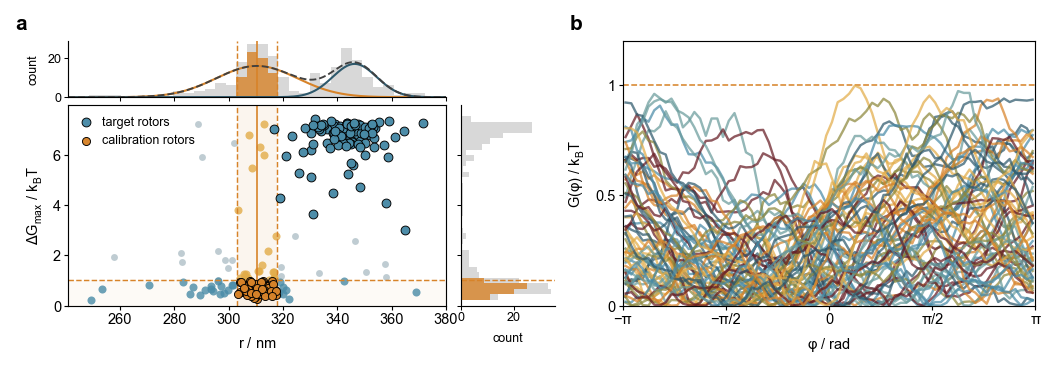

In [12]:
identify_calibration_target_rotors(
    m_list=m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=0.5,
    threshold_kBT=1.0,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2c_identify_calibration_rotors",
    stator_variant=None, #stator_varian,
    C=CK_colors,
    radius_selection_mode="gmm2",
    radius_filter_source="gmm",
    target_radius_n_sigma=4.0,
    target_min_dG_kBT=3.0,
    show_target_rotors=True,
)

#### ii. Filter calibration rotors based on umbrella measurements

In [13]:
def filter_calibration_rotors(
    m_list,
    min_locs_per_window=20,
    save_dir=None,
    raw_fig_name="SI_calibration_rotors_rawdata",
    summary_fig_name="SI_calibration_rotors_ensemble",
    stator_variant=None,
    C=None,
    selection_preset="standard",   # "loose", "standard", "strict"
    summary_mode="overlay",        # "overlay", "separate", "both", "none"
    max_raw_particles=12,
    raw_particle_sort="best",      # "best", "particle"
    raw_fig_width_mm=180,
    raw_panel_height_mm=28,
    summary_fig_width_mm=220,
    summary_fig_height_mm=102,
    raw_hist_bins=90,
    kappa_hist_bins=24,
    rolling_mean_n=3,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    from pathlib import Path

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = dict(C)

    required = [
        "orange", "beige", "gold", "olive", "palecyan", "lightblue",
        "darkblue", "darkred", "grey", "lightgrey", "black", "white", "warmgold",
    ]
    missing = [k for k in required if k not in C]
    if missing:
        raise ValueError(f"C is missing required color keys: {missing}")

    presets = {
        "loose": dict(
            min_Rbar=0.50, max_center_error=18.0, max_center_rmse=14.0, max_center_range=30.0,
            min_kappa=0.25, max_kappa=30.0, max_kappa_std=5.0, max_kappa_cv=0.22,
            max_kappa_fold=1.55, min_tracking_corr=0.95, min_slope=0.85, max_slope=1.15,
            max_cross_kappa_cv=0.16, max_cross_window_kappa_cv=0.25, max_cross_mu_rmse=10.0,
            ensemble_center_mad=6.0, ensemble_kappa_mad=6.0,
        ),
        "standard": dict(
            min_Rbar=0.55, max_center_error=15.0, max_center_rmse=12.0, max_center_range=25.0,
            min_kappa=0.50, max_kappa=25.0, max_kappa_std=3.0, max_kappa_cv=0.15,
            max_kappa_fold=1.35, min_tracking_corr=0.97, min_slope=0.90, max_slope=1.10,
            max_cross_kappa_cv=0.12, max_cross_window_kappa_cv=0.20, max_cross_mu_rmse=8.0,
            ensemble_center_mad=3.5, ensemble_kappa_mad=3.5,
        ),
        "strict": dict(
            min_Rbar=0.55, max_center_error=10.0, max_center_rmse=12.0, max_center_range=25.0,
            min_kappa=0.50, max_kappa=25.0, max_kappa_std=3.0, max_kappa_cv=0.10,
            max_kappa_fold=1.35, min_tracking_corr=0.97, min_slope=0.90, max_slope=1.10,
            max_cross_kappa_cv=0.12, max_cross_window_kappa_cv=0.20, max_cross_mu_rmse=8.0,
            ensemble_center_mad=3.5, ensemble_kappa_mad=3.5,
        ),
    }

    selection_preset = str(selection_preset).lower()
    summary_mode = str(summary_mode).lower()
    raw_particle_sort = str(raw_particle_sort).lower()

    if selection_preset not in presets:
        raise ValueError("selection_preset must be 'loose', 'standard', or 'strict'.")
    if summary_mode not in {"overlay", "separate", "both", "none"}:
        raise ValueError("summary_mode must be 'overlay', 'separate', 'both', or 'none'.")
    if raw_particle_sort not in {"best", "particle"}:
        raise ValueError("raw_particle_sort must be 'best' or 'particle'.")

    P = presets[selection_preset]
    min_locs_per_window = int(np.ceil(float(min_locs_per_window)))
    rolling_mean_n = int(max(1, rolling_mean_n))
    command_shift_rad = np.deg2rad(-90.0)

    CALIB_VOLTAGE_COLORS = {
        200: (238 / 255, 196 / 255, 105 / 255),
        250: (226 / 255, 172 / 255, 72 / 255),
        300: (198 / 255, 131 / 255, 41 / 255),
    }

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def finite(a):
        a = np.asarray(a, dtype=float)
        return a[np.isfinite(a)]

    def circ_mean(phi):
        phi = finite(phi)
        return float(np.angle(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def circ_R(phi):
        phi = finite(phi)
        return float(np.abs(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def circ_std(phi):
        R = circ_R(phi)
        return float(np.sqrt(-2 * np.log(R))) if np.isfinite(R) and R > 0 else np.nan

    def robust_mad_z(x):
        x = np.asarray(x, dtype=float)
        med = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - med))
        if not np.isfinite(mad) or mad <= 0:
            return np.zeros_like(x, dtype=float)
        return 0.6745 * (x - med) / mad

    def kappa_from_R(R, n=None):
        R = float(R)
        if not np.isfinite(R) or R <= 0:
            return np.nan
        R = min(R, 0.999999)
        if R < 0.53:
            k = 2 * R + R**3 + 5 * R**5 / 6
        elif R < 0.85:
            k = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            k = 1 / (R**3 - 4 * R**2 + 3 * R)
        if n is not None and np.isfinite(n) and n > 0 and n < 15:
            if k < 2:
                k = max(k - 2 / (n * k), 0) if k > 0 else np.nan
            else:
                k = ((n - 1)**3 * k) / (n**3 + n)
        return float(k) if np.isfinite(k) else np.nan

    def vonmises_pdf(x, mu, k):
        if not np.isfinite(mu) or not np.isfinite(k) or k <= 0:
            return np.full_like(np.asarray(x, dtype=float), np.nan)
        return np.exp(k * np.cos(wrap_pi(np.asarray(x) - mu))) / (2 * np.pi * np.i0(k))

    def cosine_U(psi, k):
        return k * (1 - np.cos(np.asarray(psi, dtype=float)))

    def roll_periodic(y, n):
        y = np.asarray(y, dtype=float)
        if len(y) == 0 or n <= 1:
            return y.copy()
        out = np.full_like(y, np.nan, dtype=float)
        left = n // 2
        right = n - left - 1
        for i in range(len(y)):
            idx = [(i + j) % len(y) for j in range(-left, right + 1)]
            vals = finite(y[idx])
            if len(vals):
                out[i] = np.nanmean(vals)
        return out

    def m_name(m, i=None):
        try:
            return Path(m.path).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown"

    def voltage(m):
        mt = re.search(r"_(\d+)V_", m_name(m))
        return int(mt.group(1)) if mt else None

    def is_umb(m):
        n = m_name(m).upper()
        return ("UMB" in n) and ("DIFF" not in n)

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            out = []
            for xx in x:
                out.extend(flatten(xx))
            return out
        return [x]

    def ensure_columns(m):
        if "group_int" not in m.locs.columns:
            if "group" not in m.locs.columns:
                raise ValueError(f"{m_name(m)}: m.locs must contain 'group'.")
            m.locs["group_int"] = m.locs["group"].astype(int)

        if "t" not in m.locs.columns:
            if "averagetime" in m.locs.columns:
                m.locs["t"] = m.locs["averagetime"].astype(float)
            elif "time" in m.locs.columns:
                m.locs["t"] = m.locs["time"].astype(float)
            elif "time_s" in m.locs.columns:
                m.locs["t"] = m.locs["time_s"].astype(float)
            elif hasattr(m, "_average_tpf"):
                m.locs["t"] = m.locs["frame"].astype(float) * float(m._average_tpf)
            elif hasattr(m, "average_tpf"):
                m.locs["t"] = m.locs["frame"].astype(float) * float(m.average_tpf)
            elif hasattr(m, "fps"):
                m.locs["t"] = m.locs["frame"].astype(float) / float(m.fps)
            else:
                raise ValueError(f"{m_name(m)} needs time information.")

        if "phi" not in m.locs.columns:
            raise ValueError(f"{m_name(m)}: m.locs needs 'phi'.")

    def angle_from_key(key):
        s = str(key).lower()
        if any(bad in s for bad in ["diff", "umbrella", "all", "drift", "dark", "pause"]):
            return np.nan
        for pat in [
            r"^deg[-_]?(-?\d+(?:\.\d+)?)$",
            r"(-?\d+(?:\.\d+)?)\s*deg",
            r"pos[-_]?(-?\d+(?:\.\d+)?)",
            r"angle[-_]?(-?\d+(?:\.\d+)?)",
            r"phi[-_]?(-?\d+(?:\.\d+)?)",
            r"cmd[-_]?(-?\d+(?:\.\d+)?)",
        ]:
            mt = re.search(pat, s)
            if mt:
                return float(mt.group(1)) % 360.0
        return np.nan

    def phase_bounds(m, phase):
        v = m.protocol[phase]
        while isinstance(v, (tuple, list)) and len(v) == 1 and isinstance(v[0], (tuple, list, dict)):
            v = v[0]
        if isinstance(v, dict):
            start = next((v[k] for k in ["start", "start_time", "t_start", "begin"] if k in v), None)
            end = next((v[k] for k in ["end", "end_time", "t_end", "stop"] if k in v), None)
            if start is None or end is None:
                raise ValueError(f"Could not parse protocol entry {phase}: {v}")
            return float(start), float(end)
        if isinstance(v, (tuple, list)) and len(v) >= 2:
            return float(v[0]), float(v[1])
        raise ValueError(f"Could not parse protocol entry {phase}: {v}")

    def phi_cmd_from_phase(phase):
        deg = angle_from_key(phase)
        deg = ((deg + 180) % 360) - 180
        return float(wrap_pi(np.deg2rad(deg)))

    def deg_phases(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []
        phases = []
        for k in m.protocol.keys():
            if np.isfinite(angle_from_key(k)):
                phases.append((phi_cmd_from_phase(k), k))
        return [k for _, k in sorted(phases, key=lambda z: z[0])]

    # def label_measurements(ms):
    #     base = []
    #     for i, m in enumerate(ms):
    #         n = m_name(m, i)
    #         v = voltage(m)
    #         step = re.search(r"_(\d+)deg_", n)
    #         direction = "ccw" if "ccw" in n.lower() else ("cw" if "cw" in n.lower() else "")
    #         s = f"{v} V" if v is not None else f"m{i}"
    #         if step:
    #             s += f" {step.group(1)}°"
    #         if direction:
    #             s += f" {direction}"
    #         base.append(s.strip())
    #     counts = {x: base.count(x) for x in base}
    #     seen = {}
    #     labels = []
    #     for b in base:
    #         if counts[b] == 1:
    #             labels.append(b)
    #         else:
    #             seen[b] = seen.get(b, 0) + 1
    #             labels.append(f"{b} run {seen[b]}")
    #     return labels
    def label_measurements(ms):
        labels = []
        voltage_counts = {}
    
        for i, m in enumerate(ms):
            v = voltage(m)
    
            if v is None:
                labels.append(f"measurement {i + 1}")
                continue
    
            voltage_counts[v] = voltage_counts.get(v, 0) + 1
            labels.append(f"{v} V, replicate {voltage_counts[v]}")
    
        return labels

    def color_run(i, ms):
        if i == 0:
            return C["warmgold"]
        v = voltage(ms[i])
        if v in CALIB_VOLTAGE_COLORS:
            return CALIB_VOLTAGE_COLORS[v]
        fallback = [C["gold"], C["orange"], C["darkred"], C["olive"], C["beige"]]
        return fallback[(i - 1) % len(fallback)]

    def particle_candidates(ms):
        sets = []
        for m in ms:
            vals = [int(p) for p in list(getattr(m, "flat_rotors", []))]
            if vals:
                sets.append(set(vals))
        if not sets:
            raise ValueError(
                "No non-empty m.flat_rotors found. "
                "Run identify_calibration_target_rotors(..., store_rotors_to_m=True) first."
            )
        return sorted(set.intersection(*sets))

    def get_radius(m, p):
        if not hasattr(m, "particle_data"):
            return np.nan
        pdta = m.particle_data
        p = int(p)
        try:
            if hasattr(pdta, "loc"):
                if p in pdta.index and "R" in pdta.columns:
                    return float(pdta.loc[p, "R"])
                if "group" in pdta.columns and "R" in pdta.columns:
                    r = pdta[pdta["group"].astype(int) == p]
                    return float(r.iloc[0]["R"]) if len(r) else np.nan
            if isinstance(pdta, dict):
                if "R" in pdta:
                    R = pdta["R"]
                    if isinstance(R, dict):
                        return float(R[p])
                    return float(R[p])
                if p in pdta and isinstance(pdta[p], dict) and "R" in pdta[p]:
                    return float(pdta[p]["R"])
        except Exception:
            return np.nan
        return np.nan

    def phase_phi(m, p, phase):
        t0, t1 = phase_bounds(m, phase)
        sub = m.locs[
            (m.locs["group_int"].astype(int) == int(p))
            & (m.locs["t"] >= t0)
            & (m.locs["t"] < t1)
        ]
        if sub is None or "phi" not in sub.columns:
            return np.array([], dtype=float)
        phi = wrap_pi(sub["phi"].to_numpy(float))
        return phi[np.isfinite(phi)]

    def compute_windows(ms, particles, labels):
        rows = []
        for mi, m in enumerate(ms):
            phases = deg_phases(m)
            for p in particles:
                r_nm = get_radius(m, p)
                for wi, ph in enumerate(phases):
                    pcmd = phi_cmd_from_phase(ph)
                    phi = phase_phi(m, p, ph)
                    n = int(len(phi))

                    if n >= min_locs_per_window:
                        mu_fit = circ_mean(phi)
                        mu = float(wrap_pi(mu_fit - command_shift_rad))
                        R = circ_R(phi)
                        k = kappa_from_R(R, n=n)
                        err = float(np.rad2deg(wrap_pi(mu - pcmd)))
                    else:
                        mu_fit, mu, R, k, err = np.nan, np.nan, np.nan, np.nan, np.nan

                    abs_err = abs(err) if np.isfinite(err) else np.nan
                    ok = (
                        n >= min_locs_per_window
                        and np.isfinite(R) and R >= P["min_Rbar"]
                        and np.isfinite(k) and P["min_kappa"] <= k <= P["max_kappa"]
                        and np.isfinite(abs_err) and abs_err <= P["max_center_error"]
                    )

                    rows.append((
                        mi, labels[mi], int(p), str(ph), wi, len(phases), pcmd, r_nm, n,
                        mu_fit, mu, R, k, err, abs_err, bool(ok)
                    ))

        return pd.DataFrame(
            rows,
            columns=[
                "m", "label", "particle", "phase", "wi", "n_windows", "phi_cmd", "r_nm", "n_locs",
                "mu_fit", "mu", "Rbar", "kappa", "center_error_deg", "abs_center_error_deg", "window_ok",
            ],
        )

    def per_m_metrics(df):
        rows = []
        for (mi, label, p), g in df.groupby(["m", "label", "particle"], dropna=False):
            g = g.sort_values("phi_cmd")

            k = g["kappa"].to_numpy(float)
            kg = k[np.isfinite(k) & (k > 0)]
            e = finite(g["center_error_deg"].to_numpy(float))
            R = finite(g["Rbar"].to_numpy(float))
            x = g["phi_cmd"].to_numpy(float)
            y = g["mu"].to_numpy(float)

            k_mean = float(np.nanmean(kg)) if len(kg) else np.nan
            k_std = float(np.nanstd(kg, ddof=1)) if len(kg) > 1 else 0.0
            k_cv = k_std / k_mean if np.isfinite(k_mean) and k_mean > 0 else np.nan
            k_med = float(np.nanmedian(kg)) if len(kg) else np.nan
            k_fold = float(np.nanmax(np.maximum(kg / k_med, k_med / kg))) if len(kg) and k_med > 0 else np.nan

            rmse = float(np.sqrt(np.nanmean(e**2))) if len(e) else np.nan
            max_err = float(np.nanmax(np.abs(e))) if len(e) else np.nan
            err_range = float(np.nanmax(e) - np.nanmin(e)) if len(e) else np.nan
            R_mean = float(np.nanmean(R)) if len(R) else np.nan

            corr, slope = np.nan, np.nan
            keep = np.isfinite(x) & np.isfinite(y)
            if keep.sum() >= 4:
                xu = np.unwrap(x[keep])
                yu = np.unwrap(y[keep])
                yu = yu - 2 * np.pi * np.round(np.nanmedian(yu - xu) / (2 * np.pi))

                if np.nanstd(xu) > 0 and np.nanstd(yu) > 0:
                    corr = float(np.corrcoef(xu, yu)[0, 1])

                try:
                    slope = float(np.polyfit(xu, yu, 1)[0])
                except Exception:
                    slope = np.nan

            n_ok = int(np.sum(g["window_ok"].to_numpy(bool)))
            n_exp = int(np.nanmax(g["n_windows"].to_numpy(float)))
            n_valid = int(np.sum(np.isfinite(k)))

            passes = (
                n_valid > 0
                and n_ok >= n_exp
                and np.isfinite(k_mean) and np.isfinite(k_std) and np.isfinite(k_cv) and np.isfinite(k_fold)
                and np.isfinite(corr) and np.isfinite(slope)
                and np.isfinite(rmse) and np.isfinite(max_err) and np.isfinite(err_range) and np.isfinite(R_mean)
                and R_mean >= P["min_Rbar"]
                and rmse <= P["max_center_rmse"]
                and max_err <= P["max_center_error"]
                and err_range <= P["max_center_range"]
                and k_std <= P["max_kappa_std"]
                and k_cv <= P["max_kappa_cv"]
                and k_fold <= P["max_kappa_fold"]
                and corr >= P["min_tracking_corr"]
                and P["min_slope"] <= slope <= P["max_slope"]
            )

            rows.append((
                mi, label, int(p), n_valid, n_ok, n_exp, R_mean, rmse, max_err,
                err_range, k_mean, k_std, k_cv, k_fold, corr, slope, bool(passes)
            ))

        return pd.DataFrame(
            rows,
            columns=[
                "m", "label", "particle", "n_valid", "n_ok", "n_exp", "Rbar_mean", "center_rmse_deg",
                "max_center_error_deg", "center_error_range_deg", "kappa_mean", "kappa_std", "kappa_cv",
                "kappa_fold", "tracking_corr", "tracking_slope", "passes_m",
            ],
        )

    def particle_metrics(df, pm, n_m):
        rows = []

        for p, g in df.groupby("particle", dropna=False):
            gm = pm[pm["particle"].astype(int) == int(p)]

            k = g["kappa"].to_numpy(float)
            kg = k[np.isfinite(k) & (k > 0)]

            k_mean = float(np.nanmean(kg)) if len(kg) else np.nan
            k_std = float(np.nanstd(kg, ddof=1)) if len(kg) > 1 else np.nan

            km = gm["kappa_mean"].to_numpy(float)
            km = km[np.isfinite(km) & (km > 0)]
            cross_k_cv = (
                float(np.nanstd(km, ddof=1) / np.nanmean(km))
                if len(km) >= 2
                else (0.0 if len(km) == 1 else np.nan)
            )

            mu_resid, kw_cvs = [], []

            for _, gw in g.groupby("phi_cmd"):
                mu = finite(gw["mu"].to_numpy(float))

                if len(mu) >= 2:
                    m0 = circ_mean(mu)
                    mu_resid.extend(np.rad2deg(wrap_pi(mu - m0)).tolist())

                kw = gw["kappa"].to_numpy(float)
                kw = kw[np.isfinite(kw) & (kw > 0)]

                if len(kw) >= 2 and np.nanmean(kw) > 0:
                    kw_cvs.append(float(np.nanstd(kw, ddof=1) / np.nanmean(kw)))

            cross_mu_rmse = float(np.sqrt(np.nanmean(np.asarray(mu_resid) ** 2))) if len(mu_resid) else np.nan
            cross_window_k_cv = float(np.nanmedian(kw_cvs)) if len(kw_cvs) else np.nan

            pre = (
                len(gm) == n_m
                and bool(gm["passes_m"].all())
                and np.isfinite(cross_k_cv) and cross_k_cv <= P["max_cross_kappa_cv"]
                and np.isfinite(cross_window_k_cv) and cross_window_k_cv <= P["max_cross_window_kappa_cv"]
                and np.isfinite(cross_mu_rmse) and cross_mu_rmse <= P["max_cross_mu_rmse"]
            )

            rows.append((
                int(p),
                np.nanmedian(g["r_nm"].to_numpy(float)),
                k_mean,
                k_std,
                cross_k_cv,
                cross_window_k_cv,
                cross_mu_rmse,
                int(np.sum(gm["passes_m"].to_numpy(bool))),
                bool(pre),
            ))

        return pd.DataFrame(
            rows,
            columns=[
                "particle", "r_nm", "kappa_mean", "kappa_std", "cross_kappa_cv",
                "cross_window_kappa_cv", "cross_mu_rmse_deg", "n_umb_pass", "pre_reliable",
            ],
        )

    def ensemble_filter(df, ps):
        s = ps.copy()
        pre = set(s.loc[s["pre_reliable"], "particle"].astype(int))

        if len(pre) < 5:
            s["is_reliable"] = s["pre_reliable"]
            return s

        d = df[df["particle"].isin(pre)].copy()
        bad = set()

        for _, g in d.groupby(["m", "phi_cmd"]):
            for col, maxz in [
                ("center_error_deg", P["ensemble_center_mad"]),
                ("kappa", P["ensemble_kappa_mad"]),
            ]:
                z = robust_mad_z(g[col].to_numpy(float))
                for p, zz in zip(g["particle"].to_numpy(int), z):
                    if np.isfinite(zz) and abs(zz) > maxz:
                        bad.add(int(p))

        s["is_reliable"] = s["pre_reliable"] & (~s["particle"].astype(int).isin(bad))
        return s

    def win_summary(df):
        rows = []

        for (mi, label, pcmd), g in df.groupby(["m", "label", "phi_cmd"], dropna=False):
            k = finite(g["kappa"].to_numpy(float))
            e = finite(g["center_error_deg"].to_numpy(float))
            mu = finite(g["mu"].to_numpy(float))

            rows.append((
                mi,
                label,
                pcmd,
                float(np.nanmean(k)) if len(k) else np.nan,
                float(np.nanstd(k, ddof=1)) if len(k) > 1 else np.nan,
                float(np.nanmean(e)) if len(e) else np.nan,
                float(np.nanstd(e, ddof=1)) if len(e) > 1 else np.nan,
                circ_mean(mu),
                circ_std(mu),
            ))

        out = pd.DataFrame(
            rows,
            columns=["m", "label", "phi_cmd", "k_mean", "k_std", "e_mean", "e_std", "mu_mean", "mu_std"],
        )

        if len(out):
            out = out.sort_values(["m", "phi_cmd"]).reset_index(drop=True)
            out["k_roll"] = np.nan

            for mi, idx in out.groupby("m").groups.items():
                idx = list(idx)
                out.loc[idx, "k_roll"] = roll_periodic(
                    out.loc[idx, "k_mean"].to_numpy(float),
                    rolling_mean_n,
                )

        return out

    def style(ax):
        for sp in ax.spines.values():
            sp.set_linewidth(0.55)
            sp.set_color(C["black"])

        ax.tick_params(
            width=0.55,
            length=2.2,
            labelsize=6,
            color=C["black"],
            labelcolor=C["black"],
            pad=1.4,
        )

    def set_pi_x(ax, half=False):
        if half:
            ax.set_xlim(-np.pi / 2, np.pi / 2)
            ax.set_xticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_xticklabels([r"$-\mathrm{\pi}/2$", "0", r"$\mathrm{\pi}/2$"])
        else:
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_xticklabels([
                r"$-\mathrm{\pi}$",
                r"$-\mathrm{\pi}/2$",
                "0",
                r"$\mathrm{\pi}/2$",
                r"$\mathrm{\pi}$",
            ])

    def command_axis(ax):
        set_pi_x(ax)
        ax.set_xlabel(r"$\mathrm{\varphi}_\mathrm{cmd}$ / rad", fontsize=7)

        top = ax.secondary_xaxis(
            "top",
            functions=(lambda x: np.rad2deg(x), lambda x: np.deg2rad(x)),
        )
        top.set_xticks([-180, -90, 0, 90, 180])
        top.set_xticklabels(["−180°", "−90°", "0°", "90°", "180°"])
        top.tick_params(
            width=0.55,
            length=2.2,
            labelsize=6,
            color=C["black"],
            labelcolor=C["black"],
            pad=1.4,
        )

        for sp in top.spines.values():
            sp.set_linewidth(0.55)
            sp.set_color(C["black"])

    def raw_colors(n):
        anchors = np.array(
            [C["darkblue"], C["lightblue"], C["palecyan"], C["olive"], C["gold"], C["orange"], C["darkred"]],
            dtype=float,
        )

        if n <= 1:
            return np.array([C["warmgold"]], dtype=float)

        x0 = np.linspace(0, 1, len(anchors))
        x = np.linspace(0, 1, n)

        return np.column_stack([np.interp(x, x0, anchors[:, j]) for j in range(3)])

    def raw_panel(ax, m, mi, p, df):
        phases = deg_phases(m)
        colors = raw_colors(len(phases))
        bins = np.linspace(-np.pi, np.pi, raw_hist_bins + 1)
        xfit = np.linspace(-np.pi, np.pi, 1200)
        g = df[(df["m"] == mi) & (df["particle"] == int(p))]

        for ph, col in zip(phases, colors):
            row = g[g["phase"].astype(str) == str(ph)]

            if len(row) == 0:
                continue

            row = row.iloc[0]
            phi = phase_phi(m, p, ph)

            if len(phi) < min_locs_per_window:
                continue

            h, e = np.histogram(phi, bins=bins, density=True)
            centers = 0.5 * (e[:-1] + e[1:])
            ok = bool(row["window_ok"])

            ax.plot(
                centers,
                h,
                color=col,
                lw=0.65 if ok else 0.45,
                alpha=0.58 if ok else 0.18,
            )

            if np.isfinite(row["mu_fit"]) and np.isfinite(row["kappa"]) and row["kappa"] > 0:
                ax.plot(
                    xfit,
                    vonmises_pdf(xfit, row["mu_fit"], row["kappa"]),
                    color=col,
                    lw=1.05 if ok else 0.65,
                    alpha=0.95 if ok else 0.25,
                )

        if len(g):
            k = g["kappa"].to_numpy(float)
            e = g["center_error_deg"].to_numpy(float)
            mk = np.nanmean(k)
            sk = np.nanstd(k)
            cv = sk / mk if np.isfinite(mk) and mk > 0 else np.nan

            ax.text(
                0.02,
                0.95,
                rf"$r={np.nanmedian(g['r_nm'].to_numpy(float)):.0f}$ nm"
                + "\n" + rf"$\mu_\kappa={mk:.2f}$, $\sigma_\kappa={sk:.2f}$"
                + "\n" + rf"$\mathrm{{CV}}_\kappa={cv:.2f}$",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=5.2,
                color=C["black"],
            )

        set_pi_x(ax)
        style(ax)

    def make_raw_fig(ms, labels, df, particles):
        nrows = max(1, len(particles))
        ncols = len(ms)

        fig = plt.figure(
            figsize=(
                mm_to_inch(max(raw_fig_width_mm, 52 * ncols)),
                mm_to_inch(max(50, 20 + raw_panel_height_mm * nrows)),
            )
        )

        gs = fig.add_gridspec(
            nrows,
            ncols,
            left=0.06,
            right=0.99,
            bottom=0.07,
            top=0.94,
            wspace=0.22,
            hspace=0.30,
        )

        for r, p in enumerate(particles):
            for mi, m in enumerate(ms):
                ax = fig.add_subplot(gs[r, mi])
                raw_panel(ax, m, mi, p, df)

                # if r == 0:
                #     ax.set_title(labels[mi], fontsize=7, pad=3)

                if mi == 0:
                    ax.set_ylabel("density", fontsize=7)
                else:
                    ax.set_ylabel("")
                    ax.set_yticklabels([])

                if r < nrows - 1:
                    ax.set_xlabel("")
                    ax.set_xticklabels([])
                else:
                    ax.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)

        return fig

    def make_summary_fig(df, pm, ps, ms, labels, mi_filter=None):
        if mi_filter is None:
            d_all = df
            d_rel = df[df["is_reliable"]]
            pm_plot = pm
            title, overlay = "all UMBs overlay", True
        else:
            d_all = df[df["m"] == int(mi_filter)]
            d_rel = d_all[d_all["is_reliable"]]
            pm_plot = pm[pm["m"] == int(mi_filter)]
            title, overlay = labels[int(mi_filter)], False

        w_all = win_summary(d_all)
        w_rel = win_summary(d_rel)

        fig = plt.figure(
            figsize=(mm_to_inch(summary_fig_width_mm), mm_to_inch(summary_fig_height_mm))
        )

        gs = GridSpec(
            2,
            4,
            figure=fig,
            left=0.055,
            right=0.985,
            bottom=0.12,
            top=0.88,
            wspace=0.48,
            hspace=0.52,
        )

        axA, axB, axC, axD, axE, axF, axG, axH = [
            fig.add_subplot(gs[i, j]) for i in range(2) for j in range(4)
        ]

        for mi, g in w_all.groupby("m") if len(w_all) else []:
            col = color_run(int(mi), ms) if overlay else C["warmgold"]
            lab = labels[int(mi)]
            x = g["phi_cmd"].to_numpy(float)

            for ax, ycol, ecol in [(axA, "e_mean", "e_std"), (axB, "k_mean", "k_std")]:
                y = g[ycol].to_numpy(float)
                e = g[ecol].to_numpy(float)
                keep = np.isfinite(x) & np.isfinite(y)

                ax.errorbar(
                    x[keep],
                    y[keep],
                    yerr=e[keep],
                    fmt="o-",
                    color=col,
                    ecolor=col,
                    lw=1.15,
                    elinewidth=0.55,
                    ms=2.6,
                    capsize=1.4,
                    alpha=0.90,
                    label=lab,
                )

        for mi, g in pm_plot.groupby("m") if len(pm_plot) else []:
            col = color_run(int(mi), ms) if overlay else C["warmgold"]
            rel = g["passes_m"].to_numpy(bool)

            axC.scatter(
                g.loc[~rel, "max_center_error_deg"],
                g.loc[~rel, "kappa_fold"],
                s=18,
                facecolor=C["white"],
                edgecolor=col,
                linewidth=0.7,
                alpha=0.75,
            )

            axC.scatter(
                g.loc[rel, "max_center_error_deg"],
                g.loc[rel, "kappa_fold"],
                s=26,
                facecolor=col,
                edgecolor=col,
                linewidth=0.5,
                alpha=0.90,
                label=labels[int(mi)] if overlay else None,
            )

        rel = ps["is_reliable"].to_numpy(bool)

        axD.scatter(
            ps.loc[~rel, "cross_kappa_cv"],
            ps.loc[~rel, "cross_mu_rmse_deg"],
            s=18,
            facecolor=C["white"],
            edgecolor=C["warmgold"],
            linewidth=0.7,
            alpha=0.75,
        )

        axD.scatter(
            ps.loc[rel, "cross_kappa_cv"],
            ps.loc[rel, "cross_mu_rmse_deg"],
            s=28,
            facecolor=C["orange"],
            edgecolor=C["warmgold"],
            linewidth=0.6,
            alpha=0.95,
        )

        bins = np.linspace(0, 20, kappa_hist_bins + 1)

        kall = d_all["kappa"].to_numpy(float)
        krel = d_rel["kappa"].to_numpy(float)

        kall = kall[np.isfinite(kall) & (kall > 0)]
        krel = krel[np.isfinite(krel) & (krel > 0)]

        if len(kall):
            axE.hist(
                kall[(kall >= 0) & (kall <= 20)],
                bins=bins,
                color=C["warmgold"],
                edgecolor=C["grey"],
                linewidth=0.45,
                alpha=0.22,
                label="all flat",
            )

        if len(krel):
            axE.hist(
                krel[(krel >= 0) & (krel <= 20)],
                bins=bins,
                color=C["orange"],
                edgecolor=C["grey"],
                linewidth=0.65,
                alpha=0.58,
                label="reliable",
            )
            axE.axvline(np.nanmean(krel), color=C["black"], lw=0.9, ls="--", alpha=0.85)

        for mi, g in w_rel.groupby("m") if len(w_rel) else []:
            col = color_run(int(mi), ms) if overlay else C["orange"]
            lab = labels[int(mi)]
            x = g["phi_cmd"].to_numpy(float)

            y = g["mu_mean"].to_numpy(float)
            e = g["mu_std"].to_numpy(float)
            keep = np.isfinite(x) & np.isfinite(y)

            axF.plot(x[keep], x[keep], "--", color=C["grey"], lw=0.7, alpha=0.45)
            axF.errorbar(
                x[keep],
                y[keep],
                yerr=e[keep],
                fmt="o-",
                color=col,
                ecolor=col,
                lw=1.05,
                elinewidth=0.60,
                ms=2.8,
                capsize=1.6,
                alpha=0.95,
                label=lab,
            )

            y = g["k_mean"].to_numpy(float)
            e = g["k_std"].to_numpy(float)
            yr = g["k_roll"].to_numpy(float)

            keep = np.isfinite(x) & np.isfinite(y)
            axG.errorbar(
                x[keep],
                y[keep],
                yerr=e[keep],
                fmt="o-",
                color=col,
                ecolor=col,
                lw=1.05,
                elinewidth=0.60,
                ms=2.8,
                capsize=1.6,
                alpha=0.95,
                label=lab,
            )

            keep_r = np.isfinite(x) & np.isfinite(yr)
            axG.plot(x[keep_r], yr[keep_r], "--", color=col, lw=1.0)

            psi = np.linspace(-np.pi / 2, np.pi / 2, 500)
            ks = yr[np.isfinite(yr) & (yr > 0)]

            if len(ks):
                km = float(np.nanmean(ks))
                q16, q84 = np.nanpercentile(ks, [16, 84])
                axH.fill_between(
                    psi,
                    cosine_U(psi, q16),
                    cosine_U(psi, q84),
                    color=col,
                    alpha=0.15 if overlay else 0.35,
                    lw=0,
                )
                axH.plot(psi, cosine_U(psi, km), color=col, lw=1.25, label=lab)

        axA.axhline(0, color=C["grey"], lw=0.7, ls="--", alpha=0.7)
        command_axis(axA)
        axA.set_ylabel(r"$\mathrm{\Delta\varphi}_i$ / °", fontsize=7)
        axA.set_ylim(-20, 20)
        style(axA)

        command_axis(axB)
        axB.set_ylabel(r"${\kappa}$ / $k_\mathrm{B}T$ rad$^{-2}$", fontsize=7)
        axB.set_ylim(8, 16.5)
        style(axB)

        axC.axvline(P["max_center_error"], color=C["grey"], lw=0.8, ls="--", alpha=0.75)
        axC.axhline(P["max_kappa_fold"], color=C["grey"], lw=0.8, ls="--", alpha=0.75)
        axC.set_xlabel(r"worst center error / °", fontsize=7)
        axC.set_ylabel(r"worst $\kappa$ / median $\kappa$", fontsize=7)
        axC.set_xlim(0, 25)
        axC.set_ylim(1.0, 2.2)
        style(axC)

        axD.axvline(P["max_cross_kappa_cv"], color=C["grey"], lw=0.8, ls="--", alpha=0.75)
        axD.axhline(P["max_cross_mu_rmse"], color=C["grey"], lw=0.8, ls="--", alpha=0.75)
        axD.set_xlabel(r"$\Delta \langle\kappa_i\rangle$ across replica", fontsize=7)
        axD.set_ylabel(r"$\Delta \langle\Delta\varphi\rangle$ across replica / °", fontsize=7)
        axD.set_xlim(0, 0.20)
        axD.set_ylim(0, 10)
        style(axD)

        axE.set_xlabel(r"$\mathrm{\kappa}_i$ / $k_\mathrm{B}T$ rad$^{-2}$", fontsize=7)
        axE.set_ylabel("count", fontsize=7)
        axE.set_xlim(0, 20)
        axE.legend(frameon=False, fontsize=5.4, loc="upper right")
        style(axE)

        command_axis(axF)
        axF.set_ylabel(r"$\langle\mathrm{\varphi}_i\rangle$ / rad", fontsize=7)
        axF.set_ylim(-np.pi, np.pi)
        axF.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        axF.set_yticklabels([
            r"$-\mathrm{\pi}$",
            r"$-\mathrm{\pi}/2$",
            "0",
            r"$\mathrm{\pi}/2$",
            r"$\mathrm{\pi}$",
        ])
        style(axF)

        command_axis(axG)
        axG.set_ylabel(r"$\langle{\kappa_i}\rangle$ / $k_\mathrm{B}T$ rad$^{-2}$", fontsize=7)
        axG.set_ylim(8, 16.5)
        style(axG)

        set_pi_x(axH, half=True)
        axH.set_xlabel(r"$\mathrm{\psi}$ / rad", fontsize=7)
        axH.set_ylabel(r"$\mathrm{U}_i$ / $k_\mathrm{B}T$", fontsize=7)
        axH.legend(frameon=False, fontsize=5.4, loc="upper center")
        style(axH)

        # if overlay:
        #     axA.legend(frameon=False, fontsize=5.4, loc="best")
        #     axC.legend(frameon=False, fontsize=5.4, loc="upper left")

        # # fig.text(
        # #     0.055,
        # #     0.965,
        # #     f"Calibration kappa dashboard: {title}",
        # #     ha="left",
        # #     va="top",
        # #     fontsize=7,
        # #     color=C["black"],
        # # )

        # return fig
        if overlay:
            axA.legend(frameon=False, fontsize=5.4, loc="best")
            axC.legend(frameon=False, fontsize=5.4, loc="upper left")
        
        fig.canvas.draw()
        
        panel_label_x_offset = 0.05
        panel_label_y_offset = 0.018
        
        panel_rows = [
            ([axA, axB, axC, axD], ["a", "b", "c", "d"]),
            ([axE, axF, axG, axH], ["e", "f", "g", "h"]),
        ]
        
        for row_axes, row_labels in panel_rows:
            panel_label_y = max(ax.get_position().y1 for ax in row_axes) + panel_label_y_offset
        
            for ax, panel_label in zip(row_axes, row_labels):
                fig.text(
                    ax.get_position().x0 - panel_label_x_offset,
                    panel_label_y,
                    panel_label,
                    ha="left",
                    va="bottom",
                    fontsize=10,
                    fontweight="bold",
                    fontfamily="Arial",
                    color=C["black"],
                )
        
        return fig

    m_all = flatten(m_list)
    ms = [m for m in m_all if is_umb(m) and len(deg_phases(m))]

    if not ms:
        raise ValueError("No valid UMB measurement found.")

    labels = label_measurements(ms)

    for m in ms:
        ensure_columns(m)

    candidates = particle_candidates(ms)

    df = compute_windows(ms, candidates, labels)
    pm = per_m_metrics(df)
    ps = ensemble_filter(df, particle_metrics(df, pm, len(ms)))

    reliable = sorted(ps.loc[ps["is_reliable"], "particle"].astype(int).tolist())
    df["is_reliable"] = df["particle"].astype(int).isin(set(reliable))

    for mi, m in enumerate(ms):
        m.kappa_calibration_by_window = df[df["m"] == mi].copy()

    reliable_set = set(int(p) for p in reliable)

    for m in m_all:
        if not hasattr(m, "locs") or m.locs is None:
            continue

        if "group_int" in m.locs.columns:
            present = set(m.locs["group_int"].astype(int).unique())
        elif "group" in m.locs.columns:
            present = set(m.locs["group"].astype(int).unique())
        else:
            continue

        m.calibration_rotors = sorted([int(p) for p in present if int(p) in reliable_set])

    print(f"candidate m.flat_rotors: n = {len(candidates)}")
    print(f"m.calibration_rotors: n = {len(reliable)}: {reliable}")
    print("UMB measurements used:")

    for i, m in enumerate(ms):
        print(f"  {i:02d} | {labels[i]} | {m_name(m)}")

    plt.rcParams.update({
        "font.size": 7,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.55,
        "axes.labelsize": 7,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    raw_particles = list(reliable)

    if raw_particle_sort == "best" and raw_particles:
        raw_particles = ps[ps["particle"].isin(raw_particles)].sort_values(
            ["cross_mu_rmse_deg", "cross_kappa_cv", "particle"]
        )["particle"].astype(int).tolist()
    else:
        raw_particles = sorted(raw_particles)

    if not raw_particles:
        raw_particles = list(candidates)

    if max_raw_particles is not None:
        raw_particles = raw_particles[:int(max_raw_particles)]

    fig_raw = make_raw_fig(ms, labels, df, raw_particles)

    summary_figs = []

    if summary_mode in {"overlay", "both"}:
        summary_figs.append(("overlay", make_summary_fig(df, pm, ps, ms, labels, mi_filter=None)))

    if summary_mode in {"separate", "both"}:
        for mi, _ in enumerate(ms):
            safe = labels[mi].replace(" ", "_").replace("°", "deg")
            summary_figs.append((f"m{mi:02d}_{safe}", make_summary_fig(df, pm, ps, ms, labels, mi_filter=mi)))

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = f"{stator_variant}__" if stator_variant is not None and str(stator_variant).strip() else ""

        fig_raw.savefig(save_dir / f"{prefix}{raw_fig_name}.png", dpi=300, bbox_inches="tight")
        fig_raw.savefig(save_dir / f"{prefix}{raw_fig_name}.svg", bbox_inches="tight")

        for suffix, fig in summary_figs:
            if suffix == "overlay":
                fig.savefig(save_dir / f"{prefix}{summary_fig_name}.png", dpi=300, bbox_inches="tight")
                fig.savefig(save_dir / f"{prefix}{summary_fig_name}.svg", bbox_inches="tight")
            else:
                fig.savefig(save_dir / f"{prefix}{summary_fig_name}_{suffix}.png", dpi=300, bbox_inches="tight")
                fig.savefig(save_dir / f"{prefix}{summary_fig_name}_{suffix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig_raw)

    for _, fig in summary_figs:
        plt.close(fig)

    return None


def plot_panel2c_calibration_rotors(
    m_list,
    measurement_index=0,
    C=None,
    fig_width_mm=55,
    fig_height_mm=100,
    save_dir=None,
    save_prefix="Fig2c_calibration_rotors",
    stator_variant=None,
    potential_psi_max=None,
    show_degree_axis=False,
    kappa_ylim=None,
    kappa_ylim_top_extra_fraction=0.55,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    marker_size=2.8,
    linewidth_axis=0.55,
    linewidth_main=1.15,
    inset_delta_bounds=(0.58, 0.24, 0.34, 0.34),
    inset_potential_bounds=(0.58, 0.54, 0.34, 0.34),
    inset_fontsize=7,
    n_rotors_shown=None,
    rotor_random_seed=1,
):
    """
    Fig. 2c-style panel: in situ umbrella-bias calibration.

    Requires:
        m.calibration_rotors
        m.kappa_calibration_by_window

    Uses only rotors listed in m.calibration_rotors.
    If n_rotors_shown is None, all available calibration rotors are plotted.
    If n_rotors_shown is an integer, n calibration rotors are randomly selected.
    Only these rotors are drawn, and the bold average/errorbars are computed
    from these rotors only.

    Saves png/svg if save_dir is given.
    Shows and closes the figure.
    Returns nothing.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    if C is None:
        raise ValueError("Pass your color palette explicitly, e.g. C=CK_colors.")

    if potential_psi_max is None:
        potential_psi_max = np.pi / 2

    warmgold = C["warmgold"]
    beige = C["beige"]
    grey = C["grey"]
    lightgrey = C["lightgrey"]
    black = C["black"]

    def flatten_measurement_list(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten_measurement_list(item))
            return out
        return [obj]

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if len(phi) == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan
        return float(np.angle(z))

    def circ_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if len(phi) < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def cosine_potential(psi, kappa):
        return float(kappa) * (1.0 - np.cos(np.asarray(psi, dtype=float)))

    def harmonic_approximation(psi, kappa):
        return 0.5 * float(kappa) * np.asarray(psi, dtype=float) ** 2

    def style_axis(ax, labelsize=tick_label_size):
        for spine in ax.spines.values():
            spine.set_linewidth(linewidth_axis)
            spine.set_color(black)
        ax.tick_params(
            width=linewidth_axis,
            length=2.2,
            labelsize=labelsize,
            color=black,
            labelcolor=black,
            pad=1.4,
        )
        ax.grid(False)

    def style_inset_axis(ax):
        ax.set_facecolor((1, 1, 1, 0.90))
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
            spine.set_color(black)
        ax.tick_params(
            width=0.45,
            length=1.5,
            labelsize=inset_fontsize,
            color=black,
            labelcolor=black,
            pad=1.0,
        )
        ax.grid(False)

    def set_pi_ticks_x(ax, half=False, labelsize=None):
        if labelsize is None:
            labelsize = tick_label_size

        if half:
            ax.set_xlim(-np.pi / 2, np.pi / 2)
            ax.set_xticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_xticklabels(
                [r"$-\mathrm{\pi}/2$", "0", r"$\mathrm{\pi}/2$"],
                fontsize=labelsize,
            )
        else:
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_xticklabels(
                [
                    r"$-\mathrm{\pi}$",
                    r"$-\mathrm{\pi}/2$",
                    "0",
                    r"$\mathrm{\pi}/2$",
                    r"$\mathrm{\pi}$",
                ],
                fontsize=labelsize,
            )

    def set_pi_ticks_y(ax, half=False, labelsize=None):
        if labelsize is None:
            labelsize = tick_label_size

        if half:
            ax.set_ylim(-np.pi / 2, np.pi / 2)
            ax.set_yticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_yticklabels(
                [r"$-\mathrm{\pi}/2$", "0", r"$\mathrm{\pi}/2$"],
                fontsize=labelsize,
            )
        else:
            ax.set_ylim(-np.pi, np.pi)
            ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_yticklabels(
                [
                    r"$-\mathrm{\pi}$",
                    r"$-\mathrm{\pi}/2$",
                    "0",
                    r"$\mathrm{\pi}/2$",
                    r"$\mathrm{\pi}$",
                ],
                fontsize=labelsize,
            )

    def add_top_degree_axis(ax, fontsize_use=None):
        if fontsize_use is None:
            fontsize_use = tick_label_size

        top = ax.secondary_xaxis(
            "top",
            functions=(lambda x: np.rad2deg(x), lambda x: np.deg2rad(x)),
        )
        top.set_xlabel("")
        top.set_xticks([-180, -90, 0, 90, 180])
        top.set_xticklabels(["−180°", "−90°", "0°", "90°", "180°"])
        top.tick_params(
            width=linewidth_axis,
            length=2.2,
            labelsize=fontsize_use,
            color=black,
            labelcolor=black,
            pad=1.4,
        )
        for spine in top.spines.values():
            spine.set_linewidth(linewidth_axis)
            spine.set_color(black)
        return top

    def set_command_axis(ax):
        set_pi_ticks_x(ax, half=False)
        ax.set_xlabel(r"$\mathrm{\varphi}_\mathrm{cmd}$ / rad", fontsize=axis_label_size)
        if bool(show_degree_axis):
            add_top_degree_axis(ax)

    def get_col(df, candidates):
        for c in candidates:
            if c in df.columns:
                return c
        raise KeyError(
            "Could not find any of these columns:\n"
            f"{candidates}\n\nAvailable columns:\n{list(df.columns)}"
        )

    def select_stored_umb_measurement(m_list_flat, measurement_index):
        candidates = [
            m for m in m_list_flat
            if hasattr(m, "kappa_calibration_by_window")
        ]

        if len(candidates) == 0:
            raise ValueError(
                "No measurement contains m.kappa_calibration_by_window. "
                "Run filter_calibration_rotors(...) first."
            )

        measurement_index_int = int(measurement_index)
        if measurement_index_int >= len(candidates):
            raise IndexError(
                f"measurement_index={measurement_index} but only {len(candidates)} "
                "stored UMB measurements were found."
            )

        return candidates[measurement_index_int]

    def build_window_summary_from_df(df, phi_cmd_col, mu_col, kappa_col):
        rows = []

        for phi_cmd, g in df.groupby(phi_cmd_col, dropna=False):
            phi_cmd = float(phi_cmd)

            mu_vals = g[mu_col].to_numpy(float)
            mu_vals = mu_vals[np.isfinite(mu_vals)]

            kappa_vals = g[kappa_col].to_numpy(float)
            kappa_vals = kappa_vals[np.isfinite(kappa_vals)]

            rows.append(
                {
                    "phi_cmd_rad": phi_cmd,
                    "mu_display_mean_rad": circ_mean(mu_vals),
                    "mu_display_std_rad": circ_std(mu_vals),
                    "kappa_mean": float(np.nanmean(kappa_vals)) if len(kappa_vals) else np.nan,
                    "kappa_std": float(np.nanstd(kappa_vals, ddof=1)) if len(kappa_vals) > 1 else np.nan,
                }
            )

        return pd.DataFrame(rows).sort_values("phi_cmd_rad").reset_index(drop=True)

    def add_horizontal_scalebar(ax, length, label, y_frac=0.13):
        xmin, xmax = ax.get_xlim()
        ymin, ymax = ax.get_ylim()

        x2 = xmax - 0.08 * (xmax - xmin)
        x1 = x2 - length
        y = ymin + y_frac * (ymax - ymin)

        ax.plot([x1, x2], [y, y], color=black, lw=0.65, clip_on=False, zorder=20)
        ax.plot(
            [x1, x1],
            [y - 0.035 * (ymax - ymin), y + 0.035 * (ymax - ymin)],
            color=black,
            lw=0.65,
            clip_on=False,
            zorder=20,
        )
        ax.plot(
            [x2, x2],
            [y - 0.035 * (ymax - ymin), y + 0.035 * (ymax - ymin)],
            color=black,
            lw=0.65,
            clip_on=False,
            zorder=20,
        )
        ax.text(
            0.5 * (x1 + x2),
            y - 0.085 * (ymax - ymin),
            label,
            ha="center",
            va="top",
            fontsize=inset_fontsize,
            color=black,
            clip_on=False,
        )

    def add_pi_over_2_scalebar(ax, y_frac=0.13):
        add_horizontal_scalebar(
            ax=ax,
            length=np.pi / 2,
            label=r"$\mathrm{\pi}/2$",
            y_frac=y_frac,
        )

    def expanded_kappa_ylim(kappa_values):
        vals = np.asarray(kappa_values, dtype=float)
        vals = vals[np.isfinite(vals)]

        if len(vals) == 0:
            return (0, 1)

        ymin = float(np.nanmin(vals))
        ymax = float(np.nanmax(vals))

        if not np.isfinite(ymin) or not np.isfinite(ymax):
            return (0, 1)

        if np.isclose(ymin, ymax):
            ymin = max(0.0, ymin - 1.0)
            ymax = ymax + 1.0

        yr = ymax - ymin
        ymin = max(0.0, ymin - 0.12 * yr)
        ymax = ymax + float(kappa_ylim_top_extra_fraction) * yr

        return (ymin, ymax)

    def select_calibration_rotors_to_show(df, particle_col, m):
        if not hasattr(m, "calibration_rotors"):
            raise AttributeError("m.calibration_rotors is missing.")

        calibration_rotors = np.asarray(
            sorted(set(map(int, m.calibration_rotors))),
            dtype=int,
        )

        stored_particles = set(pd.unique(df[particle_col]).astype(int))
        available_rotors = np.asarray(
            [p for p in calibration_rotors if int(p) in stored_particles],
            dtype=int,
        )

        if len(available_rotors) == 0:
            raise ValueError(
                "None of m.calibration_rotors are present in "
                "m.kappa_calibration_by_window."
            )

        if n_rotors_shown is None:
            return available_rotors

        n_show = int(n_rotors_shown)
        if n_show <= 0:
            raise ValueError("n_rotors_shown must be None or a positive integer.")

        n_show = min(n_show, len(available_rotors))
        rng = np.random.default_rng(int(rotor_random_seed))

        return np.asarray(
            sorted(rng.choice(available_rotors, size=n_show, replace=False).astype(int)),
            dtype=int,
        )

    m_list_flat = flatten_measurement_list(m_list)
    if len(m_list_flat) == 0:
        raise ValueError("m_list is empty.")

    m = select_stored_umb_measurement(m_list_flat, measurement_index)

    df_plot = getattr(m, "kappa_calibration_by_window", None)
    if df_plot is None or len(df_plot) == 0:
        raise ValueError("m.kappa_calibration_by_window is missing or empty.")

    df_plot = df_plot.copy()

    phi_cmd_col = get_col(df_plot, ["phi_cmd_rad", "phi_cmd"])
    kappa_col = get_col(df_plot, ["kappa_theta_over_kBT_rad2", "kappa_vm", "kappa"])
    mu_col = get_col(df_plot, ["mu_display_rad", "mu", "mu_fit_rad"])
    particle_col = get_col(df_plot, ["particle"])

    df_plot = df_plot.sort_values([particle_col, phi_cmd_col]).reset_index(drop=True)

    shown_particles = select_calibration_rotors_to_show(df_plot, particle_col, m)
    shown_set = set(map(int, shown_particles))

    df_plot = df_plot[df_plot[particle_col].astype(int).isin(shown_set)].copy()
    if len(df_plot) == 0:
        raise ValueError("No calibration rotors selected for plotting.")

    win = build_window_summary_from_df(
        df=df_plot,
        phi_cmd_col=phi_cmd_col,
        mu_col=mu_col,
        kappa_col=kappa_col,
    )

    plt.rcParams.update(
        {
            "font.size": fontsize,
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "DejaVu Sans"],
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "axes.linewidth": linewidth_axis,
            "axes.labelsize": axis_label_size,
            "xtick.labelsize": tick_label_size,
            "ytick.labelsize": tick_label_size,
            "svg.fonttype": "none",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left = 0.135
    right = 0.975
    bottom = 0.105
    top = 0.90 if not show_degree_axis else 0.86
    hspace = 0.145

    h = (top - bottom - hspace) / 2.0
    w = right - left

    axA = fig.add_axes([left, bottom + h + hspace, w, h])
    axB = fig.add_axes([left, bottom, w, h])

    ax_delta = axA.inset_axes(inset_delta_bounds)
    ax_potential = axB.inset_axes(inset_potential_bounds)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = wrap_pi(g[mu_col].to_numpy(float))
        keep = np.isfinite(x_i) & np.isfinite(y_i)

        if keep.sum() >= 2:
            axA.plot(
                x_i[keep],
                y_i[keep],
                "-o",
                color=warmgold,
                lw=0.55,
                ms=1.7,
                alpha=0.35,
                markeredgewidth=0,
                zorder=2,
            )

    x = win["phi_cmd_rad"].to_numpy(float)
    phi_mean = wrap_pi(win["mu_display_mean_rad"].to_numpy(float))
    phi_std = win["mu_display_std_rad"].to_numpy(float)
    keep = np.isfinite(x) & np.isfinite(phi_mean)

    axA.errorbar(
        x[keep],
        phi_mean[keep],
        yerr=phi_std[keep] if np.any(np.isfinite(phi_std[keep])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=linewidth_main,
        elinewidth=0.0,
        ms=marker_size,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    set_command_axis(axA)
    set_pi_ticks_y(axA, half=False)
    axA.set_ylabel(r"$\langle\mathrm{\varphi}_i\rangle$ / rad", fontsize=axis_label_size)
    style_axis(axA)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = wrap_pi(g[mu_col].to_numpy(float) - x_i)
        keep_i = np.isfinite(x_i) & np.isfinite(y_i)

        if keep_i.sum() >= 2:
            ax_delta.plot(
                x_i[keep_i],
                np.rad2deg(y_i[keep_i]),
                "-o",
                color=warmgold,
                lw=0.42,
                ms=1.25,
                alpha=0.30,
                markeredgewidth=0,
                zorder=2,
            )

    delta_mean = wrap_pi(phi_mean - x)
    delta_deg = np.rad2deg(delta_mean)
    delta_err_deg = np.rad2deg(phi_std)
    keep_delta = np.isfinite(x) & np.isfinite(delta_deg)

    ax_delta.axhline(0, color=grey, lw=0.55, ls="--", alpha=0.70)
    ax_delta.errorbar(
        x[keep_delta],
        delta_deg[keep_delta],
        yerr=delta_err_deg[keep_delta] if np.any(np.isfinite(delta_err_deg[keep_delta])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=0.85,
        elinewidth=0.0,
        ms=1.9,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    ax_delta.set_xlim(-np.pi, np.pi)
    ax_delta.set_xticks([])
    ax_delta.set_xlabel("")
    ax_delta.set_ylabel(r"$\Delta\mathrm{\varphi}_i$ / °", fontsize=axis_label_size)
    style_inset_axis(ax_delta)
    add_pi_over_2_scalebar(ax_delta)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = g[kappa_col].to_numpy(float)
        keep_i = np.isfinite(x_i) & np.isfinite(y_i)

        if keep_i.sum() >= 2:
            axB.plot(
                x_i[keep_i],
                y_i[keep_i],
                "-o",
                color=warmgold,
                lw=0.55,
                ms=1.7,
                alpha=0.32,
                markeredgewidth=0,
                zorder=2,
            )

    k_x = win["phi_cmd_rad"].to_numpy(float)
    k_y = win["kappa_mean"].to_numpy(float)
    k_yerr = win["kappa_std"].to_numpy(float)
    keep_k = np.isfinite(k_x) & np.isfinite(k_y)

    axB.errorbar(
        k_x[keep_k],
        k_y[keep_k],
        yerr=k_yerr[keep_k] if np.any(np.isfinite(k_yerr[keep_k])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=linewidth_main,
        elinewidth=0.0,
        ms=marker_size,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    set_command_axis(axB)
    axB.set_ylabel(
        r"$\langle{\kappa}_i\rangle$ / $k_\mathrm{B}T$ rad$^{-2}$",
        fontsize=axis_label_size,
    )

    if kappa_ylim is None:
        all_k_for_ylim = np.r_[
            df_plot[kappa_col].to_numpy(float),
            k_y,
            k_y + np.nan_to_num(k_yerr, nan=0.0),
            k_y - np.nan_to_num(k_yerr, nan=0.0),
        ]
        axB.set_ylim(*expanded_kappa_ylim(all_k_for_ylim))
    else:
        axB.set_ylim(*kappa_ylim)

    style_axis(axB)

    psi = np.linspace(-float(potential_psi_max), float(potential_psi_max), 600)

    k_for_pot = win["kappa_mean"].to_numpy(float)
    k_for_pot = k_for_pot[np.isfinite(k_for_pot) & (k_for_pot > 0)]

    for k in k_for_pot:
        ax_potential.plot(
            psi,
            cosine_potential(psi, k),
            color=lightgrey,
            lw=0.50,
            alpha=0.40,
            zorder=1,
        )

    if len(k_for_pot):
        k_mean = float(np.nanmean(k_for_pot))
        q16, q84 = np.nanpercentile(k_for_pot, [16, 84])

        ax_potential.fill_between(
            psi,
            cosine_potential(psi, q16),
            cosine_potential(psi, q84),
            color=beige,
            alpha=0.45,
            lw=0,
            zorder=2,
        )

        ax_potential.plot(
            psi,
            cosine_potential(psi, k_mean),
            color=warmgold,
            lw=0.95,
            zorder=4,
        )

        ax_potential.plot(
            psi,
            harmonic_approximation(psi, k_mean),
            color=black,
            lw=0.75,
            ls="--",
            zorder=5,
        )

    ax_potential.set_xlim(-float(potential_psi_max), float(potential_psi_max))
    ax_potential.set_xticks([])
    ax_potential.set_xlabel("")
    ax_potential.set_ylabel(r"$\mathrm{U}_i$ / $k_\mathrm{B}T$", fontsize=axis_label_size)
    style_inset_axis(ax_potential)
    add_pi_over_2_scalebar(ax_potential)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        if stator_variant is not None and str(stator_variant).strip() != "":
            save_prefix_final = f"{stator_variant}__{save_prefix}"
        else:
            save_prefix_final = save_prefix

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

candidate m.flat_rotors: n = 65
m.calibration_rotors: n = 33: [1, 10, 19, 22, 27, 28, 40, 42, 44, 56, 69, 70, 74, 85, 93, 103, 112, 115, 122, 129, 137, 139, 144, 150, 157, 176, 179, 180, 197, 199, 201, 213, 223]
UMB measurements used:
  00 | 300 V, replicate 1 | 260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
  01 | 300 V, replicate 2 | 260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5


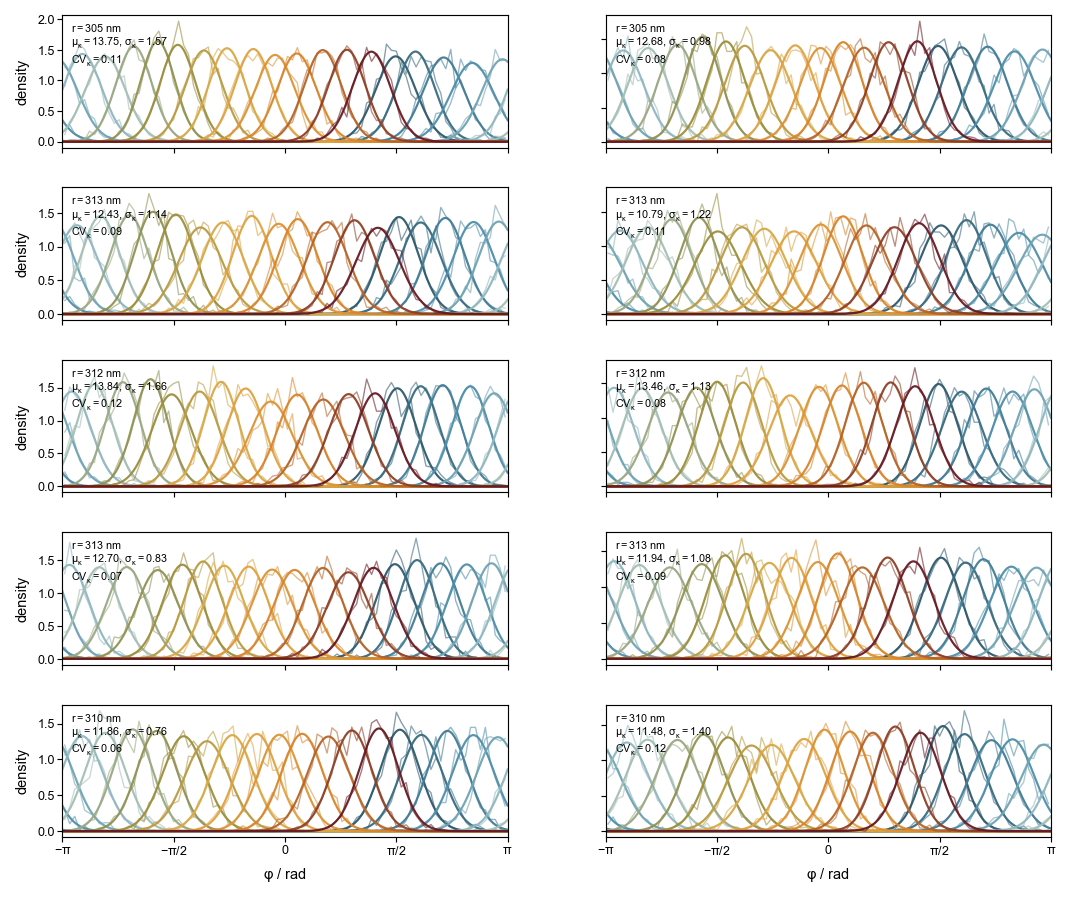

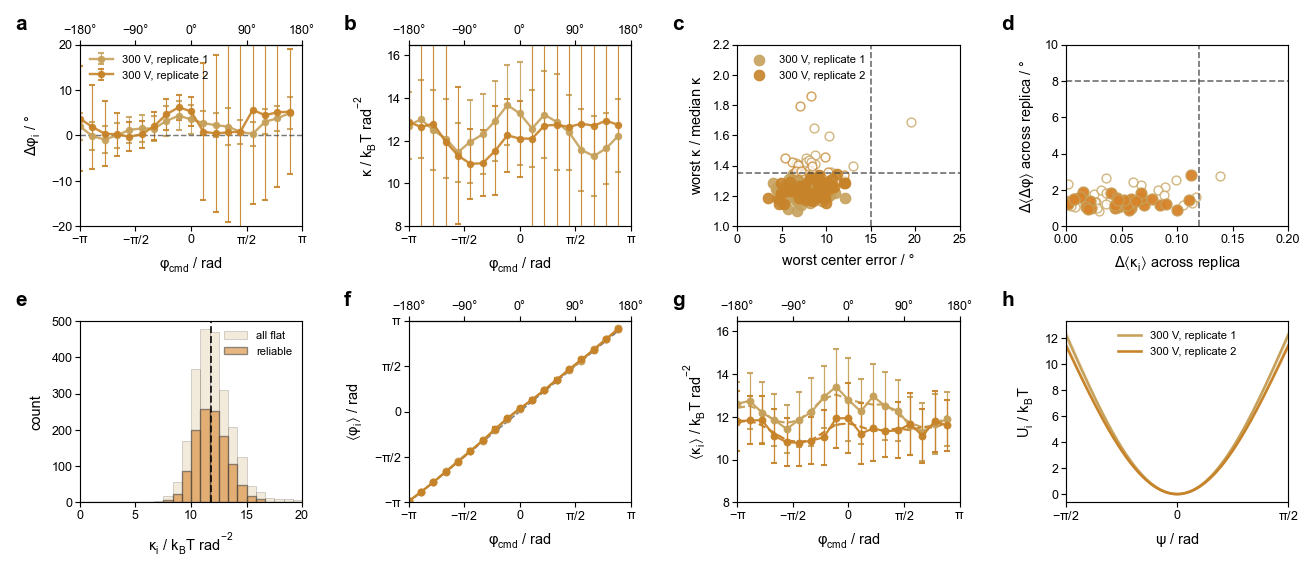

In [14]:
filter_calibration_rotors(
    m_list=m_list,
    min_locs_per_window=20,
    save_dir=save_dir_SI,
    raw_fig_name="SI_toFig2c__calibration_rotors__exemplary_rotors",
    summary_fig_name="SI_toFig2c__filter_calibration_rotors__ensemble_metrics",
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    C=CK_colors,
    selection_preset="standard",
    summary_mode="overlay",
    max_raw_particles=5,
)

## Plot Figure 2c – in situ bias calibration

In [15]:
def plot_panel2c_calibration_rotors(
    m_list,
    measurement_index=0,
    C=None,
    fig_width_mm=55,
    fig_height_mm=100,
    save_dir=None,
    save_prefix="Fig2c_calibration_rotors",
    stator_variant=None,
    potential_psi_max=None,
    show_degree_axis=False,
    kappa_ylim=None,
    kappa_ylim_top_extra_fraction=0.55,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    marker_size=2.8,
    linewidth_axis=0.55,
    linewidth_main=1.15,
    inset_delta_bounds=(0.58, 0.24, 0.34, 0.34),
    inset_potential_bounds=(0.58, 0.54, 0.34, 0.34),
    inset_fontsize=7,
    n_rotors_shown=None,
    rotor_random_seed=1,
):
    """
    Fig. 2c-style panel: in situ umbrella-bias calibration.

    Requires:
        m.calibration_rotors
        m.kappa_calibration_by_window

    Uses only rotors listed in m.calibration_rotors.
    If n_rotors_shown is None, all available calibration rotors are plotted.
    If n_rotors_shown is an integer, a random subset is plotted and averaged.

    Saves png/svg if save_dir is given.
    Shows and closes the figure.
    Returns nothing.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    if C is None:
        raise ValueError("Pass your color palette explicitly, e.g. C=CK_colors.")

    if potential_psi_max is None:
        potential_psi_max = np.pi / 2

    warmgold = C["warmgold"]
    beige = C["beige"]
    grey = C["grey"]
    lightgrey = C["lightgrey"]
    black = C["black"]

    def flatten_measurement_list(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten_measurement_list(item))
            return out
        return [obj]

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if len(phi) == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan
        return float(np.angle(z))

    def circ_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if len(phi) < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def cosine_potential(psi, kappa):
        return float(kappa) * (1.0 - np.cos(np.asarray(psi, dtype=float)))

    def harmonic_approximation(psi, kappa):
        return 0.5 * float(kappa) * np.asarray(psi, dtype=float) ** 2

    def style_axis(ax, labelsize=tick_label_size):
        for spine in ax.spines.values():
            spine.set_linewidth(linewidth_axis)
            spine.set_color(black)
        ax.tick_params(
            width=linewidth_axis,
            length=2.2,
            labelsize=labelsize,
            color=black,
            labelcolor=black,
            pad=1.4,
        )
        ax.grid(False)

    def style_inset_axis(ax):
        ax.set_facecolor((1, 1, 1, 0.90))
        for spine in ax.spines.values():
            spine.set_linewidth(0.45)
            spine.set_color(black)
        ax.tick_params(
            width=0.45,
            length=1.5,
            labelsize=inset_fontsize,
            color=black,
            labelcolor=black,
            pad=1.0,
        )
        ax.grid(False)

    def set_pi_ticks_x(ax, half=False, labelsize=None):
        if labelsize is None:
            labelsize = tick_label_size

        if half:
            ax.set_xlim(-np.pi / 2, np.pi / 2)
            ax.set_xticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_xticklabels(
                [r"$-\mathrm{\pi}/2$", "0", r"$\mathrm{\pi}/2$"],
                fontsize=labelsize,
            )
        else:
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_xticklabels(
                [
                    r"$-\mathrm{\pi}$",
                    r"$-\mathrm{\pi}/2$",
                    "0",
                    r"$\mathrm{\pi}/2$",
                    r"$\mathrm{\pi}$",
                ],
                fontsize=labelsize,
            )

    def set_pi_ticks_y(ax, half=False, labelsize=None):
        if labelsize is None:
            labelsize = tick_label_size

        if half:
            ax.set_ylim(-np.pi / 2, np.pi / 2)
            ax.set_yticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_yticklabels(
                [r"$-\mathrm{\pi}/2$", "0", r"$\mathrm{\pi}/2$"],
                fontsize=labelsize,
            )
        else:
            ax.set_ylim(-np.pi, np.pi)
            ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_yticklabels(
                [
                    r"$-\mathrm{\pi}$",
                    r"$-\mathrm{\pi}/2$",
                    "0",
                    r"$\mathrm{\pi}/2$",
                    r"$\mathrm{\pi}$",
                ],
                fontsize=labelsize,
            )

    def add_top_degree_axis(ax, fontsize_use=None):
        if fontsize_use is None:
            fontsize_use = tick_label_size

        top = ax.secondary_xaxis(
            "top",
            functions=(lambda x: np.rad2deg(x), lambda x: np.deg2rad(x)),
        )
        top.set_xlabel("")
        top.set_xticks([-180, -90, 0, 90, 180])
        top.set_xticklabels(["−180°", "−90°", "0°", "90°", "180°"])
        top.tick_params(
            width=linewidth_axis,
            length=2.2,
            labelsize=fontsize_use,
            color=black,
            labelcolor=black,
            pad=1.4,
        )
        for spine in top.spines.values():
            spine.set_linewidth(linewidth_axis)
            spine.set_color(black)
        return top

    def set_command_axis(ax):
        set_pi_ticks_x(ax, half=False)
        ax.set_xlabel(r"$\mathrm{\varphi}_\mathrm{cmd}$ / rad", fontsize=axis_label_size)
        if bool(show_degree_axis):
            add_top_degree_axis(ax)

    def get_col(df, candidates):
        for c in candidates:
            if c in df.columns:
                return c
        raise KeyError(
            "Could not find any of these columns:\n"
            f"{candidates}\n\nAvailable columns:\n{list(df.columns)}"
        )

    def select_stored_umb_measurement(m_list_flat, measurement_index):
        candidates = [
            m for m in m_list_flat
            if hasattr(m, "kappa_calibration_by_window")
        ]

        if len(candidates) == 0:
            raise ValueError(
                "No measurement contains m.kappa_calibration_by_window. "
                "Run filter_calibration_rotors(...) first."
            )

        measurement_index_int = int(measurement_index)
        if measurement_index_int >= len(candidates):
            raise IndexError(
                f"measurement_index={measurement_index} but only {len(candidates)} "
                "stored UMB measurements were found."
            )

        return candidates[measurement_index_int]

    def build_window_summary_from_df(df, phi_cmd_col, mu_col, kappa_col):
        rows = []

        for phi_cmd, g in df.groupby(phi_cmd_col, dropna=False):
            phi_cmd = float(phi_cmd)

            mu_vals = g[mu_col].to_numpy(float)
            mu_vals = mu_vals[np.isfinite(mu_vals)]

            kappa_vals = g[kappa_col].to_numpy(float)
            kappa_vals = kappa_vals[np.isfinite(kappa_vals)]

            rows.append(
                {
                    "phi_cmd_rad": phi_cmd,
                    "mu_display_mean_rad": circ_mean(mu_vals),
                    "mu_display_std_rad": circ_std(mu_vals),
                    "kappa_mean": float(np.nanmean(kappa_vals)) if len(kappa_vals) else np.nan,
                    "kappa_std": float(np.nanstd(kappa_vals, ddof=1)) if len(kappa_vals) > 1 else np.nan,
                }
            )

        return pd.DataFrame(rows).sort_values("phi_cmd_rad").reset_index(drop=True)

    def add_horizontal_scalebar(ax, length, label, y_frac=0.13):
        xmin, xmax = ax.get_xlim()
        ymin, ymax = ax.get_ylim()

        x2 = xmax - 0.08 * (xmax - xmin)
        x1 = x2 - length
        y = ymin + y_frac * (ymax - ymin)

        ax.plot([x1, x2], [y, y], color=black, lw=0.65, clip_on=False, zorder=20)
        ax.plot(
            [x1, x1],
            [y - 0.035 * (ymax - ymin), y + 0.035 * (ymax - ymin)],
            color=black,
            lw=0.65,
            clip_on=False,
            zorder=20,
        )
        ax.plot(
            [x2, x2],
            [y - 0.035 * (ymax - ymin), y + 0.035 * (ymax - ymin)],
            color=black,
            lw=0.65,
            clip_on=False,
            zorder=20,
        )
        ax.text(
            0.5 * (x1 + x2),
            y - 0.085 * (ymax - ymin),
            label,
            ha="center",
            va="top",
            fontsize=inset_fontsize,
            color=black,
            clip_on=False,
        )

    def add_pi_over_2_scalebar(ax, y_frac=0.13):
        add_horizontal_scalebar(
            ax=ax,
            length=np.pi / 2,
            label=r"$\mathrm{\pi}/2$",
            y_frac=y_frac,
        )

    def expanded_kappa_ylim(kappa_values):
        vals = np.asarray(kappa_values, dtype=float)
        vals = vals[np.isfinite(vals)]

        if len(vals) == 0:
            return (0, 1)

        ymin = float(np.nanmin(vals))
        ymax = float(np.nanmax(vals))

        if not np.isfinite(ymin) or not np.isfinite(ymax):
            return (0, 1)

        if np.isclose(ymin, ymax):
            ymin = max(0.0, ymin - 1.0)
            ymax = ymax + 1.0

        yr = ymax - ymin
        ymin = max(0.0, ymin - 0.12 * yr)
        ymax = ymax + float(kappa_ylim_top_extra_fraction) * yr

        return (ymin, ymax)

    def select_calibration_rotors_to_show(df, particle_col, m):
        if not hasattr(m, "calibration_rotors"):
            raise AttributeError("m.calibration_rotors is missing.")

        calibration_rotors = np.asarray(
            sorted(set(map(int, m.calibration_rotors))),
            dtype=int,
        )

        stored_particles = set(pd.unique(df[particle_col]).astype(int))
        available_rotors = np.asarray(
            [p for p in calibration_rotors if int(p) in stored_particles],
            dtype=int,
        )

        if len(available_rotors) == 0:
            raise ValueError(
                "None of m.calibration_rotors are present in "
                "m.kappa_calibration_by_window."
            )

        if n_rotors_shown is None:
            return available_rotors

        n_show = int(n_rotors_shown)
        if n_show <= 0:
            raise ValueError("n_rotors_shown must be None or a positive integer.")

        n_show = min(n_show, len(available_rotors))
        rng = np.random.default_rng(int(rotor_random_seed))

        return np.asarray(
            sorted(rng.choice(available_rotors, size=n_show, replace=False).astype(int)),
            dtype=int,
        )

    m_list_flat = flatten_measurement_list(m_list)
    if len(m_list_flat) == 0:
        raise ValueError("m_list is empty.")

    m = select_stored_umb_measurement(m_list_flat, measurement_index)

    df_plot = getattr(m, "kappa_calibration_by_window", None)
    if df_plot is None or len(df_plot) == 0:
        raise ValueError("m.kappa_calibration_by_window is missing or empty.")

    df_plot = df_plot.copy()

    phi_cmd_col = get_col(df_plot, ["phi_cmd_rad", "phi_cmd"])
    kappa_col = get_col(df_plot, ["kappa_theta_over_kBT_rad2", "kappa_vm", "kappa"])
    mu_col = get_col(df_plot, ["mu_display_rad", "mu", "mu_fit_rad"])
    particle_col = get_col(df_plot, ["particle"])

    df_plot = df_plot.sort_values([particle_col, phi_cmd_col]).reset_index(drop=True)

    shown_particles = select_calibration_rotors_to_show(df_plot, particle_col, m)
    shown_set = set(map(int, shown_particles))

    df_plot = df_plot[df_plot[particle_col].astype(int).isin(shown_set)].copy()
    if len(df_plot) == 0:
        raise ValueError("No calibration rotors selected for plotting.")

    win = build_window_summary_from_df(
        df=df_plot,
        phi_cmd_col=phi_cmd_col,
        mu_col=mu_col,
        kappa_col=kappa_col,
    )

    plt.rcParams.update(
        {
            "font.size": fontsize,
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "DejaVu Sans"],
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "axes.linewidth": linewidth_axis,
            "axes.labelsize": axis_label_size,
            "xtick.labelsize": tick_label_size,
            "ytick.labelsize": tick_label_size,
            "svg.fonttype": "none",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left = 0.135
    right = 0.975
    bottom = 0.105
    top = 0.90 if not show_degree_axis else 0.86
    hspace = 0.145

    h = (top - bottom - hspace) / 2.0
    w = right - left

    axA = fig.add_axes([left, bottom + h + hspace, w, h])
    axB = fig.add_axes([left, bottom, w, h])

    ax_delta = axA.inset_axes(inset_delta_bounds)
    ax_potential = axB.inset_axes(inset_potential_bounds)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = wrap_pi(g[mu_col].to_numpy(float))
        keep = np.isfinite(x_i) & np.isfinite(y_i)

        if keep.sum() >= 2:
            axA.plot(
                x_i[keep],
                y_i[keep],
                "-o",
                color=warmgold,
                lw=0.55,
                ms=1.7,
                alpha=0.35,
                markeredgewidth=0,
                zorder=2,
            )

    x = win["phi_cmd_rad"].to_numpy(float)
    phi_mean = wrap_pi(win["mu_display_mean_rad"].to_numpy(float))
    phi_std = win["mu_display_std_rad"].to_numpy(float)
    keep = np.isfinite(x) & np.isfinite(phi_mean)

    axA.errorbar(
        x[keep],
        phi_mean[keep],
        yerr=phi_std[keep] if np.any(np.isfinite(phi_std[keep])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=linewidth_main,
        elinewidth=0.0,
        ms=marker_size,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    set_command_axis(axA)
    set_pi_ticks_y(axA, half=False)
    axA.set_ylabel(r"$\langle\mathrm{\varphi}_i\rangle$ / rad", fontsize=axis_label_size)
    style_axis(axA)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = wrap_pi(g[mu_col].to_numpy(float) - x_i)
        keep_i = np.isfinite(x_i) & np.isfinite(y_i)

        if keep_i.sum() >= 2:
            ax_delta.plot(
                x_i[keep_i],
                np.rad2deg(y_i[keep_i]),
                "-o",
                color=warmgold,
                lw=0.42,
                ms=1.25,
                alpha=0.30,
                markeredgewidth=0,
                zorder=2,
            )

    delta_mean = wrap_pi(phi_mean - x)
    delta_deg = np.rad2deg(delta_mean)
    delta_err_deg = np.rad2deg(phi_std)
    keep_delta = np.isfinite(x) & np.isfinite(delta_deg)

    ax_delta.axhline(0, color=grey, lw=0.55, ls="--", alpha=0.70)
    ax_delta.errorbar(
        x[keep_delta],
        delta_deg[keep_delta],
        yerr=delta_err_deg[keep_delta] if np.any(np.isfinite(delta_err_deg[keep_delta])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=0.85,
        elinewidth=0.0,
        ms=1.9,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    ax_delta.set_xlim(-np.pi, np.pi)
    ax_delta.set_xticks([])
    ax_delta.set_xlabel("")
    ax_delta.set_ylabel(r"$\Delta\mathrm{\varphi}_i$ / °", fontsize=axis_label_size)
    style_inset_axis(ax_delta)
    add_pi_over_2_scalebar(ax_delta)

    for _, g in df_plot.groupby(particle_col):
        g = g.sort_values(phi_cmd_col)
        x_i = g[phi_cmd_col].to_numpy(float)
        y_i = g[kappa_col].to_numpy(float)
        keep_i = np.isfinite(x_i) & np.isfinite(y_i)

        if keep_i.sum() >= 2:
            axB.plot(
                x_i[keep_i],
                y_i[keep_i],
                "-o",
                color=warmgold,
                lw=0.55,
                ms=1.7,
                alpha=0.32,
                markeredgewidth=0,
                zorder=2,
            )

    k_x = win["phi_cmd_rad"].to_numpy(float)
    k_y = win["kappa_mean"].to_numpy(float)
    k_yerr = win["kappa_std"].to_numpy(float)
    keep_k = np.isfinite(k_x) & np.isfinite(k_y)

    axB.errorbar(
        k_x[keep_k],
        k_y[keep_k],
        yerr=k_yerr[keep_k] if np.any(np.isfinite(k_yerr[keep_k])) else None,
        fmt="o-",
        color=warmgold,
        ecolor=warmgold,
        lw=linewidth_main,
        elinewidth=0.0,
        ms=marker_size,
        capsize=0,
        alpha=0.98,
        zorder=5,
    )

    set_command_axis(axB)
    axB.set_ylabel(
        r"$\langle{\kappa}_i\rangle$ / $k_\mathrm{B}T$ rad$^{-2}$",
        fontsize=axis_label_size,
    )

    if kappa_ylim is None:
        all_k_for_ylim = np.r_[
            df_plot[kappa_col].to_numpy(float),
            k_y,
            k_y + np.nan_to_num(k_yerr, nan=0.0),
            k_y - np.nan_to_num(k_yerr, nan=0.0),
        ]
        axB.set_ylim(*expanded_kappa_ylim(all_k_for_ylim))
    else:
        axB.set_ylim(*kappa_ylim)

    style_axis(axB)

    psi = np.linspace(-float(potential_psi_max), float(potential_psi_max), 600)

    k_for_pot = win["kappa_mean"].to_numpy(float)
    k_for_pot = k_for_pot[np.isfinite(k_for_pot) & (k_for_pot > 0)]

    for k in k_for_pot:
        ax_potential.plot(
            psi,
            cosine_potential(psi, k),
            color=lightgrey,
            lw=0.50,
            alpha=0.40,
            zorder=1,
        )

    if len(k_for_pot):
        k_mean = float(np.nanmean(k_for_pot))
        q16, q84 = np.nanpercentile(k_for_pot, [16, 84])

        ax_potential.fill_between(
            psi,
            cosine_potential(psi, q16),
            cosine_potential(psi, q84),
            color=beige,
            alpha=0.45,
            lw=0,
            zorder=2,
        )

        ax_potential.plot(
            psi,
            cosine_potential(psi, k_mean),
            color=warmgold,
            lw=0.95,
            zorder=4,
        )

        ax_potential.plot(
            psi,
            harmonic_approximation(psi, k_mean),
            color=black,
            lw=0.75,
            ls="--",
            zorder=5,
        )

    ax_potential.set_xlim(-float(potential_psi_max), float(potential_psi_max))
    ax_potential.set_xticks([])
    ax_potential.set_xlabel("")
    ax_potential.set_ylabel(r"$\mathrm{U}_i$ / $k_\mathrm{B}T$", fontsize=axis_label_size)
    style_inset_axis(ax_potential)
    add_pi_over_2_scalebar(ax_potential)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        if stator_variant is not None and str(stator_variant).strip() != "":
            save_prefix_final = f"{stator_variant}__{save_prefix}"
        else:
            save_prefix_final = save_prefix

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

#### i. show all reliable rotors and draw global mean

In [16]:
# if full_execution:
#     data_panel2c = plot_panel2c_calibration_rotors(
#         m_list,
#         measurement_index=0,
#         C=CK_colors,
#         fig_width_mm=55,
#         fig_height_mm=100,
#         save_dir=save_dir,
#         save_prefix="Fig2c_calibration_rotors",
#         stator_variant = stator_variant,
#         potential_psi_max=None,
#         show_degree_axis=False,
#         kappa_ylim=None,
#         n_rotors_shown=None, # if none it shows all
#         rotor_random_seed=3,
#         inset_delta_bounds=(0.55, 0.05, 0.4, 0.37),
#         inset_potential_bounds=(0.60, 0.55, 0.34, 0.40),
#     )

#### ii. randomly select n calibration rotors and draw mean

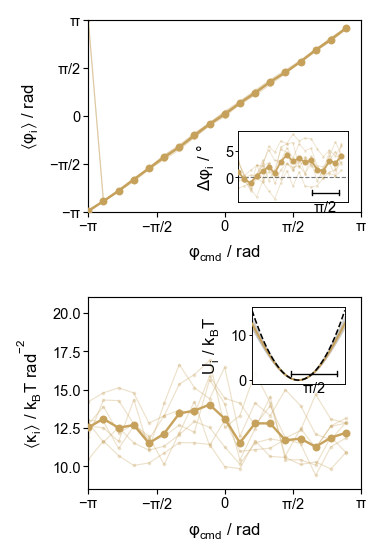

In [17]:
full_execution = True
if full_execution:
    data_panel2c = plot_panel2c_calibration_rotors(
        m_list,
        measurement_index=0,
        C=CK_colors,
        fig_width_mm=55,
        fig_height_mm=100,
        save_dir=save_dir,
        save_prefix="Fig2c_bias_inference_from_calibration_rotors___L2ss-fov01",
        stator_variant = stator_variant,
        n_rotors_shown=7, # if none it shows all
        rotor_random_seed=8,
        inset_delta_bounds=(0.55, 0.05, 0.4, 0.37),
        inset_potential_bounds=(0.60, 0.55, 0.34, 0.40),
    )
full_execution= False

## Estimate consensus trim time for umbrella windows with restraint potentials for target rotors

#### i. Check autocorrelation function per rotor / window

In [18]:
def calc_autocorrelation_times(
    m_list,
    include_diff=True,
    min_locs_for_tau=500,
    max_lag_s=1.0,
    f_trim=2.0,
):
    """
    Compute autocorrelation times for angular traces.

    Stored on each measurement:
        m.autocorrelation_df
        m.autocorrelation_trim_s

    The trim is measurement-specific:
        m.autocorrelation_trim_s = f_trim * q75(tau_s over UMB rows of this m)

    DIFF rows can be stored in m.autocorrelation_df, but DIFF is never used
    to determine m.autocorrelation_trim_s.
    """

    import re
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def parse_voltage(m):
        s = path_string(m)
        matches = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not matches:
            return np.nan
        return float(matches[-1])

    def voltage_label(v):
        if not np.isfinite(v):
            return "unknownV"
        if float(v).is_integer():
            return f"{int(v)}V"
        return f"{float(v):g}V"

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def as_int_list(x):
        if x is None:
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError(f"{measurement_name(m)} needs m.locs['{particle_col}'].")
            m.locs["group_int"] = m.locs[particle_col].astype(int)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
            return

        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
            return

        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
            return

        if "frame" in m.locs.columns and hasattr(m, "_average_tpf"):
            m.locs["t"] = m.locs["frame"].astype(float) * float(m._average_tpf)
            return

        if "frame" in m.locs.columns and hasattr(m, "fps"):
            m.locs["t"] = m.locs["frame"].astype(float) / float(m.fps)
            return

        raise ValueError("Need t, averagetime, time, time_s, or frame + _average_tpf/fps.")

    def infer_dt_default(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", value.get("t_start", None)))
            t1 = value.get("end", value.get("t1", value.get("t_end", value.get("stop", None))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def acf_fft(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        n = x.size

        if n < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        nfft = 1 << (2 * n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]

        max_lag = int(min(max_lag, n - 1))
        lags = np.arange(max_lag + 1)

        return acf[: max_lag + 1], lags

    def tau_from_acf(acf, dt):
        acf = np.asarray(acf, dtype=float)

        if acf.size < 2:
            return float(dt), 1.0

        rho = acf[1:].copy()
        rho = rho[np.isfinite(rho)]

        if rho.size == 0:
            g = 1.0
        else:
            first_non_positive = np.where(rho <= 0)[0]
            if first_non_positive.size:
                rho = rho[: first_non_positive[0]]

            rho = rho[np.isfinite(rho)]

            if rho.size == 0:
                g = 1.0
            else:
                g = 1.0 + 2.0 * np.sum(rho)

        g = float(max(g, 1.0))
        tau_s = float(0.5 * g * dt)

        return tau_s, g

    def get_particle_radius_dict(m):
        radius = {}
        pdata = getattr(m, "particle_data", None)

        if pdata is None:
            return radius

        if isinstance(pdata, pd.DataFrame):
            if "R" not in pdata.columns:
                return radius

            for idx, row in pdata.iterrows():
                try:
                    radius[int(idx)] = float(row["R"])
                except Exception:
                    pass

            if "group" in pdata.columns:
                for _, row in pdata.iterrows():
                    try:
                        radius[int(row["group"])] = float(row["R"])
                    except Exception:
                        pass

            return radius

        if isinstance(pdata, dict):
            if "R" not in pdata:
                return radius

            R = pdata["R"]

            if isinstance(R, dict):
                for k, v in R.items():
                    try:
                        radius[int(k)] = float(v)
                    except Exception:
                        pass
                return radius

            try:
                arr = np.asarray(R, dtype=float)
                for i, val in enumerate(arr):
                    if np.isfinite(val):
                        radius[int(i)] = float(val)
            except Exception:
                pass

        return radius

    def get_particles_and_classes(m):
        whitelist = as_int_list(getattr(m, "whitelist", None))

        if not whitelist:
            if hasattr(m, "locs") and m.locs is not None and "group_int" in m.locs.columns:
                whitelist = sorted(set(m.locs["group_int"].astype(int).tolist()))
            elif hasattr(m, "locs") and m.locs is not None and particle_col in m.locs.columns:
                whitelist = sorted(set(m.locs[particle_col].astype(int).tolist()))

        whitelist = sorted(set(int(p) for p in whitelist))

        calibration = set(as_int_list(getattr(m, "calibration_rotors", None)))
        target = set(as_int_list(getattr(m, "target_rotors", None)))

        overlap = calibration & target
        if overlap:
            raise ValueError(
                f"{measurement_name(m)} has rotors in both m.calibration_rotors and "
                f"m.target_rotors: {sorted(overlap)}"
            )

        class_by_particle = {}

        for p in whitelist:
            if p in calibration:
                class_by_particle[int(p)] = "calibration"
            elif p in target:
                class_by_particle[int(p)] = "target"
            else:
                class_by_particle[int(p)] = "other"

        return whitelist, class_by_particle

    def iter_phases(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError(f"{measurement_name(m)} needs m.protocol.")

        phases = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1])
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            deg_display = ((deg + 180.0) % 360.0) - 180.0
            phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))

            phases.append({
                "phase": str(label),
                "phase_type": "umbrella",
                "window_index": None,
                "deg": float(deg),
                "deg_display": float(deg_display),
                "phi0": float(phi0),
                "start": float(start),
                "stop": float(stop),
            })

        phases = sorted(phases, key=lambda d: d["deg"])

        for i, row in enumerate(phases):
            row["window_index"] = int(i)

        if include_diff and "diff" in m.protocol:
            start, stop = protocol_bounds(m.protocol["diff"])
            phases.insert(0, {
                "phase": "diff",
                "phase_type": "diff",
                "window_index": -1,
                "deg": np.nan,
                "deg_display": np.nan,
                "phi0": np.nan,
                "start": float(start),
                "stop": float(stop),
            })

        return phases

    def compute_row(
        m,
        measurement_index,
        particle,
        rotor_class,
        radius_dict,
        phase_info,
        t_particle,
        phi_particle,
        dt_default,
        voltage,
        vlabel,
    ):
        start = float(phase_info["start"])
        stop = float(phase_info["stop"])

        sel = (t_particle >= start) & (t_particle < stop)

        if not np.any(sel):
            return None

        t = t_particle[sel] - start
        phi = wrap_pi(phi_particle[sel])

        order = np.argsort(t, kind="mergesort")
        t = t[order]
        phi = phi[order]

        n_locs = int(phi.size)

        if n_locs < int(min_locs_for_tau):
            return None

        if t.size >= 3:
            dt = float(np.nanmedian(np.diff(t)))
            if not np.isfinite(dt) or dt <= 0:
                dt = float(dt_default)
        else:
            dt = float(dt_default)

        if phase_info["phase_type"] == "umbrella":
            psi = wrap_pi(phi - float(phase_info["phi0"]))
        else:
            mu = circular_mean(phi)
            if np.isfinite(mu):
                psi = wrap_pi(phi - mu)
            else:
                psi = wrap_pi(phi)

        max_lag = int(max(1, min(n_locs - 1, np.ceil(float(max_lag_s) / float(dt)))))
        acf, lags = acf_fft(psi, max_lag=max_lag)
        tau_s, g_stat = tau_from_acf(acf, dt)

        return {
            "measurement_index": int(measurement_index),
            "measurement_name": measurement_name(m, measurement_index),
            "voltage": float(voltage) if np.isfinite(voltage) else np.nan,
            "voltage_label": str(vlabel),
            "particle": int(particle),
            "rotor_class": str(rotor_class),
            "R_nm": float(radius_dict.get(int(particle), np.nan)),
            "phase": str(phase_info["phase"]),
            "phase_type": str(phase_info["phase_type"]),
            "window_index": int(phase_info["window_index"]),
            "deg": float(phase_info["deg"]) if np.isfinite(phase_info["deg"]) else np.nan,
            "deg_display": float(phase_info["deg_display"]) if np.isfinite(phase_info["deg_display"]) else np.nan,
            "phase_start_s": float(start),
            "phase_stop_s": float(stop),
            "phase_duration_s": float(stop - start),
            "n_locs": int(n_locs),
            "dt_s": float(dt),
            "max_lag_s": float(max_lag * dt),
            "tau_s": float(tau_s),
            "tau_rho_s": float(tau_s),
            "tau_int_s": float(tau_s),
            "g_statistical_inefficiency": float(g_stat),
        }

    m_flat = flatten(m_list)

    for measurement_index, m in enumerate(m_flat):
        if not hasattr(m, "locs") or m.locs is None:
            continue

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            continue

        phases = iter_phases(m)

        if len(phases) == 0:
            continue

        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError(f"{measurement_name(m, measurement_index)}: m.locs needs '{phi_col}'.")

        particles, class_by_particle = get_particles_and_classes(m)

        if len(particles) == 0:
            m.autocorrelation_df = pd.DataFrame()
            m.autocorrelation_trim_s = np.nan
            continue

        radius_dict = get_particle_radius_dict(m)
        voltage = parse_voltage(m)
        vlabel = voltage_label(voltage)
        dt_default = infer_dt_default(m)

        g_all = m.locs["group_int"].to_numpy(dtype=int, copy=False)
        t_all = m.locs["t"].to_numpy(dtype=float, copy=False)
        phi_all = wrap_pi(m.locs[phi_col].to_numpy(dtype=float, copy=False))

        ok = np.isfinite(t_all) & np.isfinite(phi_all)
        ok &= np.isin(g_all, np.asarray(particles, dtype=int))

        g_all = g_all[ok]
        t_all = t_all[ok]
        phi_all = phi_all[ok]

        rows = []

        for particle in particles:
            psel = g_all == int(particle)

            if not np.any(psel):
                continue

            t_particle = t_all[psel]
            phi_particle = phi_all[psel]

            for phase_info in phases:
                row = compute_row(
                    m=m,
                    measurement_index=measurement_index,
                    particle=int(particle),
                    rotor_class=class_by_particle[int(particle)],
                    radius_dict=radius_dict,
                    phase_info=phase_info,
                    t_particle=t_particle,
                    phi_particle=phi_particle,
                    dt_default=dt_default,
                    voltage=voltage,
                    vlabel=vlabel,
                )

                if row is not None:
                    rows.append(row)

        df = pd.DataFrame(rows)

        if len(df):
            d_umb = df[df["phase_type"].astype(str) == "umbrella"].copy()
            tau_vals = d_umb["tau_s"].to_numpy(float) if len(d_umb) else np.array([], dtype=float)
            tau_vals = tau_vals[np.isfinite(tau_vals) & (tau_vals > 0)]

            if tau_vals.size:
                measurement_trim_s = float(f_trim) * float(np.nanquantile(tau_vals, 0.75))
            else:
                measurement_trim_s = np.nan
        else:
            measurement_trim_s = np.nan

        m.autocorrelation_df = df
        m.autocorrelation_trim_s = measurement_trim_s

    return None

In [19]:
calc_autocorrelation_times(
    m_list=m_list,
    include_diff=True,
    min_locs_for_tau=t_UMB*0.5,
    max_lag_s=1.0,
    f_trim=2.0,
)


#### ii. Plot autocorrelation overview across measurements

In [20]:
def plot_autocorrelation_from_measurements(
    m_list,
    rotor_classes=("calibration", "target"),
    include_diff_column=False,
    show_other_rotors=False,
    n_max_rotors_per_subset=20,
    max_lag_s=0.5,
    acf_grid_n=160,
    random_seed=7,
    stator_variant=None,
    save_dir=None,
    save_prefix="SI_measurement_resolved_autocorrelation_curves",
    fig_width_mm=180,
    fig_height_mm=78,
    panel_label_x=-0.3,
    panel_label_y=1.18,
    panel_label_fontsize=10,
    C=CK_colors,
):
    """
    Plot measurement-resolved angular autocorrelation curves.

    The figure contains one column per measurement and one row per rotor class.
    No pooled tau-summary column and no empirical-tau vertical markers are shown.

    One panel label is added per measurement column. The horizontal and vertical
    positions are controlled in top-axis coordinates using panel_label_x and
    panel_label_y.

    Requires
    --------
    calc_autocorrelation_times(...)

    Uses
    ----
    m.autocorrelation_df
    m.locs

    Returns
    -------
    None
    """

    import re
    import numpy as np
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.gridspec import GridSpec

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    dt_s = 0.005
    acf_xlim_s = (dt_s, float(max_lag_s))

    C = C() if callable(C) else dict(C)

    CALIB_COLORS = [
        (231 / 255, 174 / 255, 57 / 255),
        (220 / 255, 126 / 255, 30 / 255),
        (141 / 255, 48 / 255, 9 / 255),
        (102 / 255, 27 / 255, 35 / 255),
    ]

    TARGET_COLORS = [
        (190 / 255, 220 / 255, 218 / 255),
        (111 / 255, 166 / 255, 166 / 255),
        (46 / 255, 89 / 255, 108 / 255),
        (32 / 255, 62 / 255, 78 / 255),
    ]

    OTHER_COLORS = [
        (0.72, 0.72, 0.72),
        (0.52, 0.52, 0.52),
        (0.34, 0.34, 0.34),
        (0.18, 0.18, 0.18),
    ]

    rotor_classes = [str(x) for x in rotor_classes]

    if show_other_rotors and "other" not in rotor_classes:
        rotor_classes.append("other")

    if not show_other_rotors:
        rotor_classes = [rc for rc in rotor_classes if rc != "other"]

    rng = np.random.default_rng(int(random_seed))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []

        if isinstance(obj, (list, tuple)):
            out = []

            for item in obj:
                out.extend(flatten(item))

            return out

        return [obj]

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)

        return f"{str(stator_variant).strip()}__{name}"

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def is_umb_measurement(m):
        s = path_string(m).upper()

        if "UMB" in s:
            return True

        if hasattr(m, "protocol") and isinstance(m.protocol, dict):
            return any(
                isinstance(k, str) and k.startswith("deg-")
                for k in m.protocol
            )

        return False

    # def short_measurement_label(m, fallback):
    #     name = (
    #         Path(path_string(m)).name
    #         if path_string(m)
    #         else f"m_list[{fallback}]"
    #     )

    #     voltage_match = re.findall(
    #         r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
    #         name,
    #         flags=re.IGNORECASE,
    #     )

    #     if voltage_match:
    #         return f"{voltage_match[-1]} V"

    #     return f"measurement {fallback + 1}"
    def short_measurement_label(m, fallback):
        umb_index = sum(
            1
            for item in flatten(m_list)[:fallback + 1]
            if is_umb_measurement(item)
        )
        return f"replica {umb_index}"

    def class_measurement_color(rotor_class, measurement_col):
        measurement_col = int(measurement_col)

        if str(rotor_class) == "calibration":
            return CALIB_COLORS[
                measurement_col % len(CALIB_COLORS)
            ]

        if str(rotor_class) == "target":
            return TARGET_COLORS[
                measurement_col % len(TARGET_COLORS)
            ]

        return OTHER_COLORS[
            measurement_col % len(OTHER_COLORS)
        ]

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.55,
            labelsize=6.5,
            color="black",
            labelcolor="black",
            pad=1.4,
        )

        ax.grid(False)

    def wrap_pi(x):
        return (
            np.asarray(x, dtype=float) + np.pi
        ) % (2.0 * np.pi) - np.pi

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError("m.locs needs column 'group'.")

            m.locs["group_int"] = m.locs[
                particle_col
            ].astype(int)

    def ensure_time_column(m):
        if "t" in m.locs.columns:
            return

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs[
                "averagetime"
            ].astype(float)
            return

        if "time" in m.locs.columns:
            m.locs["t"] = m.locs[
                "time"
            ].astype(float)
            return

        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs[
                "time_s"
            ].astype(float)
            return

        if "frame" in m.locs.columns:
            m.locs["t"] = (
                m.locs["frame"].astype(float) * dt_s
            )
            return

        raise ValueError(
            "Need t, averagetime, time, time_s, or frame."
        )

    def acf_fft_regularized(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if x.size < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        n = x.size
        max_lag = int(min(max_lag, n - 1))
        nfft = 1 << (2 * n - 1).bit_length()

        fx = np.fft.fft(x, n=nfft)

        acf = np.fft.ifft(
            fx * np.conjugate(fx)
        ).real[:n]

        acf = acf / (
            var * np.arange(n, 0, -1)
        )

        acf = acf / acf[0]

        return (
            acf[:max_lag + 1],
            np.arange(max_lag + 1),
        )

    def interpolate_to_grid(lag_s, acf, lag_grid):
        lag_s = np.asarray(lag_s, dtype=float)
        acf = np.asarray(acf, dtype=float)

        keep = (
            np.isfinite(lag_s)
            & np.isfinite(acf)
            & (lag_s >= dt_s)
        )

        if keep.sum() < 3:
            return None

        lag_s = lag_s[keep]
        acf = acf[keep]

        order = np.argsort(
            lag_s,
            kind="mergesort",
        )

        lag_s = lag_s[order]
        acf = acf[order]

        y = np.interp(
            lag_grid,
            lag_s,
            acf,
            left=np.nan,
            right=np.nan,
        )

        return y if np.isfinite(y).any() else None

    def robust_summary(curves):
        if len(curves) == 0:
            return None, None, None

        arr = np.vstack(curves)

        med = np.full(
            arr.shape[1],
            np.nan,
        )

        q25 = np.full(
            arr.shape[1],
            np.nan,
        )

        q75 = np.full(
            arr.shape[1],
            np.nan,
        )

        for j in range(arr.shape[1]):
            x = arr[:, j]
            x = x[np.isfinite(x)]

            if x.size == 0:
                continue

            med[j] = np.median(x)
            q25[j] = np.percentile(x, 25)
            q75[j] = np.percentile(x, 75)

        if not np.isfinite(med).any():
            return None, None, None

        return med, q25, q75

    def get_phi_trace_from_locs(m, particle, row):
        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'phi'.")

        start = float(row["phase_start_s"])
        stop = float(row["phase_stop_s"])

        d = m.locs.loc[
            m.locs["group_int"].astype(int)
            == int(particle),
            ["group_int", "t", phi_col],
        ].copy()

        if len(d) == 0:
            return None

        t = d["t"].to_numpy(float)

        phi = wrap_pi(
            d[phi_col].to_numpy(float)
        )

        sel = (
            np.isfinite(t)
            & np.isfinite(phi)
            & (t >= start)
            & (t < stop)
        )

        if not np.any(sel):
            return None

        t = t[sel] - start
        phi = phi[sel]

        order = np.argsort(
            t,
            kind="mergesort",
        )

        t = t[order]
        phi = phi[order]

        if len(phi) < 4:
            return None

        if str(row["phase_type"]) == "umbrella":
            deg_display = float(row["deg_display"])

            phi0 = float(
                wrap_pi(
                    np.deg2rad(deg_display)
                    + phi0_offset_rad
                )
            )

            psi = wrap_pi(phi - phi0)

        else:
            mu = circular_mean(phi)

            psi = (
                wrap_pi(phi - mu)
                if np.isfinite(mu)
                else wrap_pi(phi)
            )

        psi = psi - np.nanmean(psi)

        return t, psi

    def collect_panel_items(m_list):
        m_flat = flatten(m_list)
        items = []

        if include_diff_column:
            diff_rows = []

            for mi, m in enumerate(m_flat):
                df = getattr(
                    m,
                    "autocorrelation_df",
                    None,
                )

                if df is None or len(df) == 0:
                    continue

                d = df.copy()

                d = d[
                    d["phase_type"].astype(str)
                    == "diff"
                ].copy()

                d = d[
                    d["rotor_class"].astype(str).isin(
                        rotor_classes
                    )
                ].copy()

                if len(d) == 0:
                    continue

                d["_source_measurement_index"] = int(mi)

                d["_source_measurement_object"] = (
                    [m] * len(d)
                )

                diff_rows.append(d)

            if diff_rows:
                import pandas as pd

                diff_df = pd.concat(
                    diff_rows,
                    ignore_index=True,
                )

                items.append(
                    (
                        0,
                        -1,
                        None,
                        "diffusion",
                        diff_df,
                        "diff",
                    )
                )

        for mi, m in enumerate(m_flat):
            df = getattr(
                m,
                "autocorrelation_df",
                None,
            )

            if df is None or len(df) == 0:
                continue

            if not is_umb_measurement(m):
                continue

            d = df.copy()

            d = d[
                d["phase_type"].astype(str)
                == "umbrella"
            ].copy()

            d = d[
                d["rotor_class"].astype(str).isin(
                    rotor_classes
                )
            ].copy()

            if len(d) == 0:
                continue

            d["_source_measurement_index"] = int(mi)

            d["_source_measurement_object"] = (
                [m] * len(d)
            )

            items.append(
                (
                    len(items),
                    int(mi),
                    m,
                    short_measurement_label(
                        m,
                        len(items),
                    ),
                    d,
                    "umbrella",
                )
            )

        return items

    panel_items = collect_panel_items(m_list)

    if len(panel_items) == 0:
        raise ValueError(
            "No usable m.autocorrelation_df found. "
            "Run calc_autocorrelation_times(...) first."
        )

    required_cols = {
        "particle",
        "rotor_class",
        "phase_type",
        "phase_start_s",
        "phase_stop_s",
    }

    for _, _, _, _, d, _ in panel_items:
        missing = sorted(
            required_cols - set(d.columns)
        )

        if missing:
            raise ValueError(
                f"m.autocorrelation_df is missing columns: "
                f"{missing}. Run the current "
                "calc_autocorrelation_times() first."
            )

    n_panels = len(panel_items)
    n_rows = len(rotor_classes)

    lag_grid = np.geomspace(
        dt_s,
        float(max_lag_s),
        int(acf_grid_n),
    )

    selected_particles_by_subset = {
        (str(rc), int(panel_index)): set()
        for rc in rotor_classes
        for panel_index, _, _, _, _, _ in panel_items
    }

    curves_by_subset = {
        (str(rc), int(panel_index)): []
        for rc in rotor_classes
        for panel_index, _, _, _, _, _ in panel_items
    }

    for (
        panel_index,
        _,
        _,
        _,
        df_panel,
        _,
    ) in panel_items:

        for rc in rotor_classes:
            d_rc = df_panel[
                df_panel["rotor_class"].astype(str)
                == str(rc)
            ].copy()

            if len(d_rc) == 0:
                continue

            particles = sorted(
                set(
                    d_rc["particle"]
                    .astype(int)
                    .tolist()
                )
            )

            if (
                n_max_rotors_per_subset is not None
                and len(particles)
                > int(n_max_rotors_per_subset)
            ):
                particles = sorted(
                    rng.choice(
                        np.asarray(
                            particles,
                            dtype=int,
                        ),
                        size=int(
                            n_max_rotors_per_subset
                        ),
                        replace=False,
                    )
                    .astype(int)
                    .tolist()
                )

            selected_particles_by_subset[
                (str(rc), int(panel_index))
            ].update(particles)

            d_rc = d_rc[
                d_rc["particle"]
                .astype(int)
                .isin(particles)
            ].copy()

            for _, row in d_rc.iterrows():
                particle = int(row["particle"])

                m_source = row[
                    "_source_measurement_object"
                ]

                out = get_phi_trace_from_locs(
                    m_source,
                    particle,
                    row,
                )

                if out is None:
                    continue

                _, psi = out

                max_lag = int(
                    max(
                        1,
                        min(
                            len(psi) - 1,
                            np.ceil(
                                float(max_lag_s)
                                / dt_s
                            ),
                        ),
                    )
                )

                acf, lags = acf_fft_regularized(
                    psi,
                    max_lag=max_lag,
                )

                lag_s = (
                    lags.astype(float) * dt_s
                )

                y = interpolate_to_grid(
                    lag_s,
                    acf,
                    lag_grid,
                )

                if y is not None:
                    curves_by_subset[
                        (
                            str(rc),
                            int(panel_index),
                        )
                    ].append(y)

    if not any(
        len(curves)
        for curves in curves_by_subset.values()
    ):
        raise ValueError(
            "No ACF curves could be generated from "
            "m.autocorrelation_df and m.locs."
        )

    fig = plt.figure(
        figsize=(
            mm_to_inch(fig_width_mm),
            mm_to_inch(fig_height_mm),
        )
    )

    gs = GridSpec(
        n_rows,
        n_panels,
        figure=fig,
        left=0.065,
        right=0.985,
        bottom=0.165,
        top=0.885,
        wspace=0.22,
        hspace=0.22,
        width_ratios=[1.0] * n_panels,
    )

    axes = np.empty(
        (n_rows, n_panels),
        dtype=object,
    )

    for ri, rc in enumerate(rotor_classes):
        for ci, (
            panel_index,
            _,
            _,
            label,
            _,
            _,
        ) in enumerate(panel_items):

            ax = fig.add_subplot(gs[ri, ci])
            axes[ri, ci] = ax

            ax.set_rasterization_zorder(2)

            col = class_measurement_color(
                rc,
                panel_index,
            )

            curves = curves_by_subset.get(
                (
                    str(rc),
                    int(panel_index),
                ),
                [],
            )

            for y in curves:
                ax.plot(
                    lag_grid,
                    y,
                    color=col,
                    lw=0.50,
                    alpha=0.26,
                    rasterized=True,
                    zorder=1,
                )

            med, q25, q75 = robust_summary(
                curves
            )

            if med is not None:
                ax.fill_between(
                    lag_grid,
                    q25,
                    q75,
                    color=col,
                    alpha=0.15,
                    linewidth=0,
                    zorder=2,
                )

                ax.plot(
                    lag_grid,
                    med,
                    color="black",
                    lw=1.05,
                    ls="--",
                    alpha=0.90,
                    zorder=4,
                )

            ax.axhline(
                0,
                color="black",
                lw=0.45,
                alpha=0.35,
            )

            ax.set_xscale("log")

            ax.set_xlim(
                float(acf_xlim_s[0]),
                float(acf_xlim_s[1]),
            )

            ax.set_ylim(-0.18, 1.02)

            ax.set_yticks(
                [0.0, 0.5, 1.0]
            )

            ax.set_yticklabels(
                ["0", "0.5", "1"]
            )

            xticks = [
                x
                for x in [
                    0.005,
                    0.01,
                    0.05,
                    0.1,
                    0.5,
                ]
                if float(acf_xlim_s[0])
                <= x
                <= float(acf_xlim_s[1])
            ]

            ax.set_xticks(xticks)

            ax.set_xticklabels(
                [f"{x:g}" for x in xticks]
            )

            if ri == n_rows - 1:
                ax.set_xlabel(
                    r"$\delta t$ / s",
                    fontsize=7.5,
                )
            else:
                ax.set_xticklabels([])

            if ci == 0:
                ax.set_ylabel(
                    str(rc)
                    + "\n"
                    + r"$\rho_{\psi\psi}(\delta t)$",
                    fontsize=7.5,
                )
            else:
                ax.set_yticklabels([])

            if ri == 0:
                ax.set_title(
                    label,
                    fontsize=8,
                    pad=3,
                )

            n_rotors_here = len(
                selected_particles_by_subset.get(
                    (
                        str(rc),
                        int(panel_index),
                    ),
                    [],
                )
            )

            ax.text(
                0.98,
                0.97,
                f"n={n_rotors_here}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=5.8,
                color="black",
            )

            style_axis(ax)

    panel_labels = [
        chr(ord("a") + ci)
        for ci in range(n_panels)
    ]

    for ci, panel_label in enumerate(
        panel_labels
    ):
        axes[0, ci].text(
            float(panel_label_x),
            float(panel_label_y),
            panel_label,
            transform=axes[0, ci].transAxes,
            ha="left",
            va="top",
            fontsize=float(panel_label_fontsize),
            fontweight="bold",
            fontfamily="Arial",
            color=C.get("black", "black"),
            clip_on=False,
        )

    if (
        save_dir is not None
        and save_prefix is not None
        and str(save_prefix).strip() != ""
    ):
        save_dir = Path(save_dir)

        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            save_dir
            / f"{prefixed_name(save_prefix)}.png",
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir
            / f"{prefixed_name(save_prefix)}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

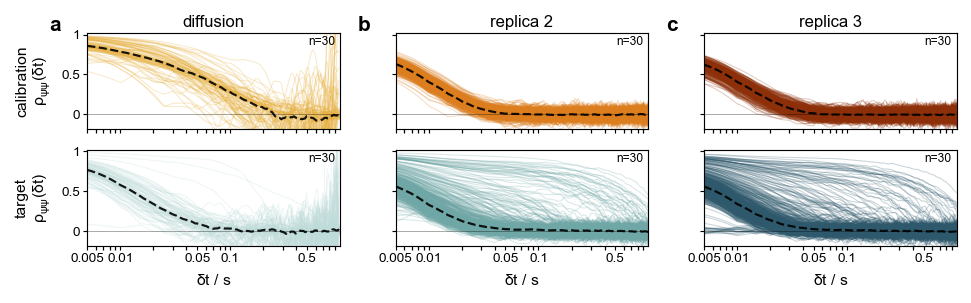

In [21]:
# if full_execution:
plot_autocorrelation_from_measurements(
    m_list,
    include_diff_column=True,
    show_other_rotors=False,
    n_max_rotors_per_subset=30,
    max_lag_s=1,
    save_dir = save_dir_SI,
    save_prefix="SI_toFig2d_autocorrelation_curves",
    panel_label_x=-0.15,
    panel_label_y=1.18,
    panel_label_fontsize=10,
    fig_width_mm=160,
    fig_height_mm=50,
    C=CK_colors,
)

#### iii. Plot exemplary target rotor data for SI figure

In [22]:
def plot_example_autocorrelation_target_rotor(
    m_list,
    particle=None,
    measurement_index=None,
    example_phases=None,
    n_examples=3,
    C=CK_colors,
    rolling_mean_s=0.15,
    max_lag_s=2,
    hist_bins_particle=72,
    fig_width_mm=180,
    fig_height_mm=78,
    save_dir=None,
    save_prefix="SI_consensus_tau",
    stator_variant=None,
):
    """
    Exemplary UMB autocorrelation diagnostic plot with three columns:

    1. Angular probability densities from all umbrella windows.
    2. Angular trajectories for selected example windows.
    3. Corresponding angular autocorrelation functions.

    Requires
    --------
    calc_autocorrelation_times(...)

    Uses
    ----
    m.autocorrelation_df
    m.autocorrelation_trim_s
    m.locs

    Only rows with
    ----------------
    m.autocorrelation_df["phase_type"] == "umbrella"

    Returns
    -------
    None
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    C = C() if callable(C) else dict(C)

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    dt_s = 0.005

    phase_base_colors = [C["target_teal"], C["darkcyan"], C["olive"]]
    tau_color = C["orange"]

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=7,
            color="black",
            labelcolor="black",
        )
        ax.grid(False)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return
        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
            return
        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
            return
        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
            return
        if "frame" in m.locs.columns:
            m.locs["t"] = m.locs["frame"].astype(float) * dt_s
            return

        raise ValueError("Need t, averagetime, time, time_s, or frame.")

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError("m.locs needs column 'group'.")
            m.locs["group_int"] = m.locs[particle_col].astype(int)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def rolling_circular_mean(t, phi, window_s):
        t = np.asarray(t, dtype=float)
        phi = np.asarray(phi, dtype=float)
        out = np.full_like(phi, np.nan, dtype=float)

        if phi.size == 0:
            return out

        half = 0.5 * float(window_s)

        for i, ti in enumerate(t):
            sel = (t >= ti - half) & (t <= ti + half)
            if np.sum(sel) >= 3:
                out[i] = circular_mean(phi[sel])

        return out

    def make_phase_colors(n):
        if n <= len(phase_base_colors):
            return phase_base_colors[:n]

        cmap = LinearSegmentedColormap.from_list("phase_cols", phase_base_colors, N=n)
        return [cmap(i / max(n - 1, 1)) for i in range(n)]

    def get_tau_col(df):
        if "tau_s" in df.columns:
            return "tau_s"
        if "tau_rho_s" in df.columns:
            return "tau_rho_s"
        if "tau_int_s" in df.columns:
            return "tau_int_s"

        raise KeyError("m.autocorrelation_df needs tau_s, tau_rho_s, or tau_int_s.")

    def collect_autocorrelation_df():
        rows = []

        for i, m in enumerate(flatten(m_list)):
            df = getattr(m, "autocorrelation_df", None)

            if df is None or len(df) == 0:
                continue

            required = {
                "particle",
                "rotor_class",
                "phase",
                "phase_type",
                "phase_start_s",
                "phase_stop_s",
                "deg_display",
            }

            missing = sorted(required - set(df.columns))

            if missing:
                raise ValueError(
                    f"m_list[{i}].autocorrelation_df is missing columns: {missing}. "
                    "Run calc_autocorrelation_times(...) first."
                )

            d = df.copy()
            d = d[d["phase_type"].astype(str) == "umbrella"].copy()

            if len(d) == 0:
                continue

            d["measurement_index"] = int(i)
            d["measurement_name"] = measurement_name(m, i)
            rows.append(d)

        if len(rows) == 0:
            raise ValueError(
                "No UMB rows found in m.autocorrelation_df. "
                "Run calc_autocorrelation_times(...) first and check that deg-* phases were processed."
            )

        out = pd.concat(rows, ignore_index=True)
        get_tau_col(out)

        return out

    def auto_choose_particle_and_measurement(tau_df):
        tau_col = get_tau_col(tau_df)
        d = tau_df.copy()
        d = d[np.isfinite(d[tau_col].astype(float))].copy()

        if len(d) == 0:
            raise ValueError("No finite UMB tau values available for automatic example selection.")

        counts = d.groupby(["measurement_index", "particle"], dropna=False).size().reset_index(name="n")
        stats = (
            d.groupby(["measurement_index", "particle"], dropna=False)[tau_col]
            .median()
            .reset_index(name="tau_med")
        )

        merged = counts.merge(stats, on=["measurement_index", "particle"], how="left")
        row = merged.sort_values(["n", "tau_med"], ascending=[False, True]).iloc[0]

        return int(row["measurement_index"]), int(row["particle"])

    def auto_choose_example_phases(df_this, n_examples):
        tau_col = get_tau_col(df_this)
        d = df_this.copy()
        d = d[np.isfinite(d[tau_col].astype(float))].copy()

        if len(d) == 0:
            return []

        ex = []

        row_fast = d.sort_values(tau_col, ascending=True).iloc[0]
        ex.append(str(row_fast["phase"]))

        tau_median = float(np.nanmedian(d[tau_col].to_numpy(float)))
        i_mid = int(np.argmin(np.abs(d[tau_col].to_numpy(float) - tau_median)))
        ph_mid = str(d.iloc[i_mid]["phase"])

        if ph_mid not in ex:
            ex.append(ph_mid)

        row_slow = d.sort_values(tau_col, ascending=False).iloc[0]
        ph_slow = str(row_slow["phase"])

        if ph_slow not in ex:
            ex.append(ph_slow)

        if len(ex) < int(n_examples):
            for _, row in d.sort_values(tau_col, ascending=False).iterrows():
                ph = str(row["phase"])
                if ph not in ex:
                    ex.append(ph)
                if len(ex) >= int(n_examples):
                    break

        return ex[:int(n_examples)]

    def get_phase_info_from_row(row):
        phase = str(row["phase"])
        start = float(row["phase_start_s"])
        stop = float(row["phase_stop_s"])
        deg_display = float(row["deg_display"])
        phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))

        return phase, deg_display, phi0, start, stop

    def get_trace_from_locs(m, particle, row):
        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'phi'.")

        phase, deg_display, phi0, start, stop = get_phase_info_from_row(row)

        d = m.locs.loc[
            m.locs["group_int"].astype(int) == int(particle),
            ["group_int", "t", phi_col],
        ].copy()

        if len(d) == 0:
            return None

        t_all = d["t"].to_numpy(float)
        phi_all = wrap_pi(d[phi_col].to_numpy(float))

        sel = np.isfinite(t_all) & np.isfinite(phi_all)
        sel &= t_all >= start
        sel &= t_all < stop

        if not np.any(sel):
            return None

        t = t_all[sel] - start
        phi = phi_all[sel]

        order = np.argsort(t, kind="mergesort")
        t = t[order]
        phi = phi[order]

        if phi.size < 4:
            return None

        psi = wrap_pi(phi - phi0)

        return t, phi, psi

    def get_raw_phi_histogram(m, particle, row, bins):
        out = get_trace_from_locs(m, particle, row)

        if out is None:
            return None

        _, phi, _ = out
        h, edges = np.histogram(phi, bins=bins, density=True)
        centers = 0.5 * (edges[:-1] + edges[1:])

        return centers, h

    def acf_fft(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if x.size < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        n = x.size
        max_lag = int(min(max_lag, n - 1))
        nfft = 1 << (2 * n - 1).bit_length()

        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]

        return acf[:max_lag + 1], np.arange(max_lag + 1)

    def get_rho_from_locs(m, particle, row):
        out = get_trace_from_locs(m, particle, row)

        if out is None:
            raise ValueError(f"Could not extract trace for particle={particle}, phase={row['phase']}.")

        _, _, psi = out
        psi = psi - np.nanmean(psi)

        max_lag = int(max(1, min(len(psi) - 1, np.ceil(float(max_lag_s) / dt_s))))
        rho, lags = acf_fft(psi, max_lag=max_lag)
        lag_s = lags.astype(float) * dt_s

        return lag_s, rho

    tau_df = collect_autocorrelation_df()
    m_flat = flatten(m_list)

    if particle is None or measurement_index is None:
        mi_auto, pid_auto = auto_choose_particle_and_measurement(tau_df)

        if measurement_index is None:
            measurement_index = mi_auto
        if particle is None:
            particle = pid_auto

    measurement_index = int(measurement_index)
    particle = int(particle)

    if measurement_index >= len(m_flat):
        raise IndexError(
            f"measurement_index={measurement_index} but m_list only has {len(m_flat)} entries."
        )

    m = m_flat[measurement_index]

    df_this = tau_df[
        (tau_df["measurement_index"].astype(int) == measurement_index)
        & (tau_df["particle"].astype(int) == particle)
    ].copy()

    if len(df_this) == 0:
        raise ValueError(
            f"No UMB autocorrelation rows found for measurement_index={measurement_index}, "
            f"particle={particle}."
        )

    tau_col = get_tau_col(df_this)

    if example_phases is None:
        example_phases = auto_choose_example_phases(df_this, int(n_examples))
    else:
        example_phases = list(example_phases)[:int(n_examples)]

    if len(example_phases) == 0:
        raise ValueError("No example phases available.")

    df_examples = df_this[
        df_this["phase"].astype(str).isin([str(p) for p in example_phases])
    ].copy()

    if len(df_examples) == 0:
        raise ValueError("None of the requested example_phases are present in the UMB autocorrelation rows.")

    example_colors = make_phase_colors(len(example_phases))
    phase_to_color = {str(ph): col for ph, col in zip(example_phases, example_colors)}
    example_phase_set = set(str(ph) for ph in example_phases)

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left_margin = 0.055
    right_margin = 0.985
    top = 0.92
    bottom = 0.15

    hist_x = left_margin
    hist_w = 0.34

    trace_x = hist_x + hist_w + 0.075
    trace_w = 0.31

    acf_x = trace_x + trace_w + 0.055
    acf_w = right_margin - acf_x

    nrows = len(example_phases)
    row_gap = 0.045
    row_h = (top - bottom - row_gap * (nrows - 1)) / nrows

    ax_hist_phi = fig.add_axes([hist_x, bottom, hist_w, top - bottom])
    bins_phi = np.linspace(-np.pi, np.pi, int(hist_bins_particle) + 1)

    for _, row in df_this.iterrows():
        out = get_raw_phi_histogram(m, particle, row, bins_phi)

        if out is None:
            continue

        centers, h = out
        ph = str(row["phase"])
        is_example = ph in example_phase_set
        color = phase_to_color[ph] if is_example else C["lightgrey"]

        ax_hist_phi.plot(
            centers,
            h,
            lw=1.5 if is_example else 0.85,
            color=color,
            alpha=0.98 if is_example else 0.30,
            zorder=3 if is_example else 1,
        )

    ax_hist_phi.set_xlim(-np.pi, np.pi)
    ax_hist_phi.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=8)
    ax_hist_phi.set_ylabel("density", fontsize=8)
    ax_hist_phi.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax_hist_phi.set_xticklabels(
        [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"],
        fontsize=7,
    )
    style_ax(ax_hist_phi)

    for i, ph in enumerate(example_phases):
        y = top - (i + 1) * row_h - i * row_gap

        ax_trace = fig.add_axes([trace_x, y, trace_w, row_h])
        ax_rho = fig.add_axes([acf_x, y, acf_w, row_h])

        row_match = df_this[df_this["phase"].astype(str) == str(ph)].copy()

        if len(row_match) == 0:
            ax_trace.axis("off")
            ax_rho.axis("off")
            continue

        row = row_match.iloc[0]
        out = get_trace_from_locs(m, particle, row)

        if out is None:
            ax_trace.axis("off")
            ax_rho.axis("off")
            continue

        t_win, _, psi_sparse = out
        roll = rolling_circular_mean(t_win, psi_sparse, rolling_mean_s)
        lag_s, rho = get_rho_from_locs(m, particle, row)

        tau_here = float(row[tau_col]) if np.isfinite(float(row[tau_col])) else np.nan
        trim_here = getattr(m, "autocorrelation_trim_s", np.nan)
        trim_here = float(trim_here) if np.isfinite(trim_here) else np.nan
        phase_color = phase_to_color[str(ph)]

        ax_trace.plot(
            t_win,
            np.rad2deg(psi_sparse),
            lw=0.45,
            color=C["lightgrey"],
            alpha=0.90,
            rasterized=True,
        )

        ax_trace.plot(
            t_win,
            np.rad2deg(roll),
            lw=1.0,
            color=phase_color,
        )

        # if np.isfinite(trim_here):
        #     ax_trace.axvline(
        #         trim_here,
        #         lw=1.0,
        #         ls="--",
        #         color=tau_color,
        #         alpha=0.95,
        #     )

        ax_trace.axhline(0, lw=0.45, color="black", alpha=0.35)
        ax_trace.set_xlim(0, max(float(np.nanmax(t_win)), 1e-9))
        ax_trace.set_ylim(-55, 55)
        ax_trace.set_yticks([-30, 0, 30])
        ax_trace.set_ylabel(r"$\mathrm{\psi}$ / °", fontsize=7)

        if i == nrows - 1:
            ax_trace.set_xlabel("time / s", fontsize=7)
        else:
            ax_trace.set_xticklabels([])

        style_ax(ax_trace)

        ax_rho.plot(
            lag_s,
            rho,
            lw=1.0,
            color=phase_color,
        )

        # if np.isfinite(tau_here):
        #     ax_rho.axvline(
        #         tau_here,
        #         lw=1.0,
        #         ls="--",
        #         color=tau_color,
        #         alpha=0.95,
        #     )

        ax_rho.axhline(0, lw=0.45, color="black", alpha=0.35)
        ax_rho.set_xlim(dt_s, float(max_lag_s))
        ax_rho.set_xscale("log")
        ax_rho.set_ylim(-0.25, 1.05)
        ax_rho.set_ylabel(r"$\rho_{\psi\psi}(\delta t)$", fontsize=7)

        if i == nrows - 1:
            ax_rho.set_xlabel(r"$\delta t$ / s", fontsize=7)
        else:
            ax_rho.set_xticklabels([])

        style_ax(ax_rho)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        fig.savefig(
            save_dir / f"{prefixed_name(save_prefix)}.png",
            dpi=300,
            bbox_inches="tight",
        )
        fig.savefig(
            save_dir / f"{prefixed_name(save_prefix)}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

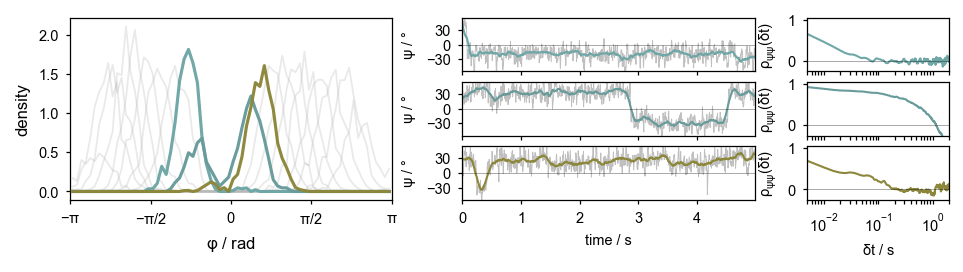

In [23]:
# if full_execution:
plot_example_autocorrelation_target_rotor(
    m_list=m_list[0],
    particle=17,
    example_phases=["deg-60", "deg-80", "deg-100"],
    n_examples=3,
    fig_width_mm=160,
    fig_height_mm=40,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d_autocorrelation_curves_exemplary_target_rotor",
    stator_variant=stator_variant,
)

Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_2\SI_toFig2d_autocorrelation_curves_exemplary_target_rotor.png
Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_2\SI_toFig2d_autocorrelation_curves_exemplary_target_rotor.svg


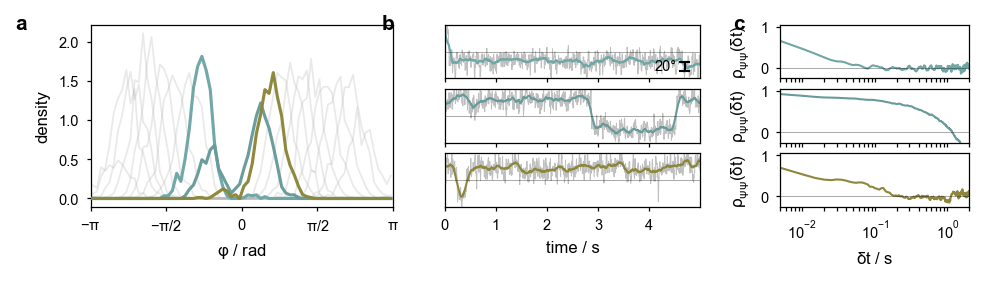

In [24]:
def plot_example_autocorrelation_target_rotor(
    m_list,
    particle=None,
    measurement_index=None,
    example_phases=None,
    n_examples=3,
    C=CK_colors,
    rolling_mean_s=0.15,
    max_lag_s=2,
    hist_bins_particle=72,
    fig_width_mm=180,
    fig_height_mm=78,
    hist_width=0.34,
    trace_width=0.31,
    hist_trace_gap=0.055,
    trace_acf_gap=0.055,
    axis_label_size=8,
    tick_label_size=7,
    trace_ylim_deg=(-55, 55),
    trace_scalebar_deg=20,
    trace_scalebar_x=0.94,
    trace_scalebar_y=0.13,
    trace_scalebar_fontsize=7,
    panel_labels=("a", "b", "c"),
    panel_label_x=-0.15,
    panel_label_y=0.965,
    panel_label_fontsize=10,
    save_dir=None,
    save_prefix="SI_consensus_tau",
    stator_variant=None,
):
    """
    Exemplary UMB autocorrelation diagnostic plot with three columns:

    1. Angular probability densities from all umbrella windows.
    2. Angular trajectories for selected example windows.
    3. Corresponding angular autocorrelation functions.

    The trajectory panels use identical y-limits and one shared angular
    scale bar instead of repeated y-axis labels and ticks.

    Returns
    -------
    None
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    C = C() if callable(C) else dict(C)

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    dt_s = 0.005

    phase_base_colors = [C["target_teal"], C["darkcyan"], C["olive"]]

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=tick_label_size,
            color="black",
            labelcolor="black",
        )
        ax.grid(False)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return
        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
            return
        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
            return
        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
            return
        if "frame" in m.locs.columns:
            m.locs["t"] = m.locs["frame"].astype(float) * dt_s
            return

        raise ValueError("Need t, averagetime, time, time_s, or frame.")

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError("m.locs needs column 'group'.")
            m.locs["group_int"] = m.locs[particle_col].astype(int)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def rolling_circular_mean(t, phi, window_s):
        t = np.asarray(t, dtype=float)
        phi = np.asarray(phi, dtype=float)
        out = np.full_like(phi, np.nan, dtype=float)

        if phi.size == 0:
            return out

        half = 0.5 * float(window_s)

        for i, ti in enumerate(t):
            sel = (t >= ti - half) & (t <= ti + half)
            if np.sum(sel) >= 3:
                out[i] = circular_mean(phi[sel])

        return out

    def make_phase_colors(n):
        if n <= len(phase_base_colors):
            return phase_base_colors[:n]

        cmap = LinearSegmentedColormap.from_list(
            "phase_cols",
            phase_base_colors,
            N=n,
        )

        return [cmap(i / max(n - 1, 1)) for i in range(n)]

    def get_tau_col(df):
        if "tau_s" in df.columns:
            return "tau_s"
        if "tau_rho_s" in df.columns:
            return "tau_rho_s"
        if "tau_int_s" in df.columns:
            return "tau_int_s"

        raise KeyError(
            "m.autocorrelation_df needs tau_s, tau_rho_s, or tau_int_s."
        )

    def collect_autocorrelation_df():
        rows = []

        for i, m in enumerate(flatten(m_list)):
            df = getattr(m, "autocorrelation_df", None)

            if df is None or len(df) == 0:
                continue

            required = {
                "particle",
                "rotor_class",
                "phase",
                "phase_type",
                "phase_start_s",
                "phase_stop_s",
                "deg_display",
            }

            missing = sorted(required - set(df.columns))

            if missing:
                raise ValueError(
                    f"m_list[{i}].autocorrelation_df is missing columns: {missing}. "
                    "Run calc_autocorrelation_times(...) first."
                )

            d = df.copy()
            d = d[d["phase_type"].astype(str) == "umbrella"].copy()

            if len(d) == 0:
                continue

            d["measurement_index"] = int(i)
            d["measurement_name"] = measurement_name(m, i)
            rows.append(d)

        if len(rows) == 0:
            raise ValueError(
                "No UMB rows found in m.autocorrelation_df. "
                "Run calc_autocorrelation_times(...) first."
            )

        out = pd.concat(rows, ignore_index=True)
        get_tau_col(out)

        return out

    def auto_choose_particle_and_measurement(tau_df):
        tau_col = get_tau_col(tau_df)
        d = tau_df.copy()
        d = d[np.isfinite(d[tau_col].astype(float))].copy()

        if len(d) == 0:
            raise ValueError(
                "No finite UMB tau values available for automatic example selection."
            )

        counts = (
            d.groupby(["measurement_index", "particle"], dropna=False)
            .size()
            .reset_index(name="n")
        )

        stats = (
            d.groupby(["measurement_index", "particle"], dropna=False)[tau_col]
            .median()
            .reset_index(name="tau_med")
        )

        merged = counts.merge(
            stats,
            on=["measurement_index", "particle"],
            how="left",
        )

        row = merged.sort_values(
            ["n", "tau_med"],
            ascending=[False, True],
        ).iloc[0]

        return int(row["measurement_index"]), int(row["particle"])

    def auto_choose_example_phases(df_this, n_examples):
        tau_col = get_tau_col(df_this)
        d = df_this.copy()
        d = d[np.isfinite(d[tau_col].astype(float))].copy()

        if len(d) == 0:
            return []

        ex = []

        row_fast = d.sort_values(tau_col, ascending=True).iloc[0]
        ex.append(str(row_fast["phase"]))

        tau_median = float(np.nanmedian(d[tau_col].to_numpy(float)))
        i_mid = int(
            np.argmin(
                np.abs(
                    d[tau_col].to_numpy(float)
                    - tau_median
                )
            )
        )

        ph_mid = str(d.iloc[i_mid]["phase"])

        if ph_mid not in ex:
            ex.append(ph_mid)

        row_slow = d.sort_values(tau_col, ascending=False).iloc[0]
        ph_slow = str(row_slow["phase"])

        if ph_slow not in ex:
            ex.append(ph_slow)

        if len(ex) < int(n_examples):
            for _, row in d.sort_values(tau_col, ascending=False).iterrows():
                ph = str(row["phase"])

                if ph not in ex:
                    ex.append(ph)

                if len(ex) >= int(n_examples):
                    break

        return ex[:int(n_examples)]

    def get_phase_info_from_row(row):
        phase = str(row["phase"])
        start = float(row["phase_start_s"])
        stop = float(row["phase_stop_s"])
        deg_display = float(row["deg_display"])
        phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))

        return phase, deg_display, phi0, start, stop

    def get_trace_from_locs(m, particle, row):
        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'phi'.")

        _, _, phi0, start, stop = get_phase_info_from_row(row)

        d = m.locs.loc[
            m.locs["group_int"].astype(int) == int(particle),
            ["group_int", "t", phi_col],
        ].copy()

        if len(d) == 0:
            return None

        t_all = d["t"].to_numpy(float)
        phi_all = wrap_pi(d[phi_col].to_numpy(float))

        sel = (
            np.isfinite(t_all)
            & np.isfinite(phi_all)
            & (t_all >= start)
            & (t_all < stop)
        )

        if not np.any(sel):
            return None

        t = t_all[sel] - start
        phi = phi_all[sel]

        order = np.argsort(t, kind="mergesort")
        t = t[order]
        phi = phi[order]

        if phi.size < 4:
            return None

        psi = wrap_pi(phi - phi0)

        return t, phi, psi

    def get_raw_phi_histogram(m, particle, row, bins):
        out = get_trace_from_locs(m, particle, row)

        if out is None:
            return None

        _, phi, _ = out
        h, edges = np.histogram(phi, bins=bins, density=True)
        centers = 0.5 * (edges[:-1] + edges[1:])

        return centers, h

    def acf_fft(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if x.size < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        n = x.size
        max_lag = int(min(max_lag, n - 1))
        nfft = 1 << (2 * n - 1).bit_length()

        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]

        return acf[:max_lag + 1], np.arange(max_lag + 1)

    def get_rho_from_locs(m, particle, row):
        out = get_trace_from_locs(m, particle, row)

        if out is None:
            raise ValueError(
                f"Could not extract trace for particle={particle}, "
                f"phase={row['phase']}."
            )

        _, _, psi = out
        psi = psi - np.nanmean(psi)

        max_lag = int(
            max(
                1,
                min(
                    len(psi) - 1,
                    np.ceil(float(max_lag_s) / dt_s),
                ),
            )
        )

        rho, lags = acf_fft(
            psi,
            max_lag=max_lag,
        )

        lag_s = lags.astype(float) * dt_s

        return lag_s, rho

    def add_vertical_scalebar(ax, length_deg, x_fraction, y_fraction):
        xmin, xmax = ax.get_xlim()
        ymin, ymax = ax.get_ylim()

        x = xmin + float(x_fraction) * (xmax - xmin)
        y0 = ymin + float(y_fraction) * (ymax - ymin)
        y1 = y0 + float(length_deg)

        if y1 > ymax:
            y1 = ymax - 0.05 * (ymax - ymin)
            y0 = y1 - float(length_deg)

        cap = 0.018 * (xmax - xmin)

        ax.plot(
            [x, x],
            [y0, y1],
            color="black",
            lw=1.0,
            clip_on=False,
            zorder=20,
        )

        ax.plot(
            [x - cap, x + cap],
            [y0, y0],
            color="black",
            lw=1.0,
            clip_on=False,
            zorder=20,
        )

        ax.plot(
            [x - cap, x + cap],
            [y1, y1],
            color="black",
            lw=1.0,
            clip_on=False,
            zorder=20,
        )

        ax.text(
            x - 1.7 * cap,
            0.5 * (y0 + y1),
            f"{float(length_deg):g}°",
            ha="right",
            va="center",
            fontsize=trace_scalebar_fontsize,
            color="black",
        )

    tau_df = collect_autocorrelation_df()
    m_flat = flatten(m_list)

    if particle is None or measurement_index is None:
        mi_auto, pid_auto = auto_choose_particle_and_measurement(tau_df)

        if measurement_index is None:
            measurement_index = mi_auto

        if particle is None:
            particle = pid_auto

    measurement_index = int(measurement_index)
    particle = int(particle)

    if measurement_index >= len(m_flat):
        raise IndexError(
            f"measurement_index={measurement_index}, "
            f"but m_list only has {len(m_flat)} entries."
        )

    m = m_flat[measurement_index]

    df_this = tau_df[
        (tau_df["measurement_index"].astype(int) == measurement_index)
        & (tau_df["particle"].astype(int) == particle)
    ].copy()

    if len(df_this) == 0:
        raise ValueError(
            f"No UMB autocorrelation rows found for "
            f"measurement_index={measurement_index}, particle={particle}."
        )

    if example_phases is None:
        example_phases = auto_choose_example_phases(df_this, int(n_examples))
    else:
        example_phases = list(example_phases)[:int(n_examples)]

    if len(example_phases) == 0:
        raise ValueError("No example phases available.")

    df_examples = df_this[
        df_this["phase"].astype(str).isin(
            [str(p) for p in example_phases]
        )
    ].copy()

    if len(df_examples) == 0:
        raise ValueError(
            "None of the requested example phases are present."
        )

    example_colors = make_phase_colors(len(example_phases))

    phase_to_color = {
        str(ph): col
        for ph, col in zip(example_phases, example_colors)
    }

    example_phase_set = set(
        str(ph)
        for ph in example_phases
    )

    fig = plt.figure(
        figsize=(
            mm_to_inch(fig_width_mm),
            mm_to_inch(fig_height_mm),
        )
    )

    left_margin = 0.055
    right_margin = 0.985
    top = 0.92
    bottom = 0.15

    hist_x = left_margin
    hist_w = float(hist_width)

    trace_x = hist_x + hist_w + float(hist_trace_gap)
    trace_w = float(trace_width)

    acf_x = trace_x + trace_w + float(trace_acf_gap)
    acf_w = right_margin - acf_x

    if acf_w <= 0.05:
        raise ValueError(
            "Column widths and gaps leave too little space for the ACF column."
        )

    nrows = len(example_phases)
    row_gap = 0.045
    row_h = (
        top
        - bottom
        - row_gap * (nrows - 1)
    ) / nrows

    ax_hist_phi = fig.add_axes([
        hist_x,
        bottom,
        hist_w,
        top - bottom,
    ])

    bins_phi = np.linspace(
        -np.pi,
        np.pi,
        int(hist_bins_particle) + 1,
    )

    for _, row in df_this.iterrows():
        out = get_raw_phi_histogram(
            m,
            particle,
            row,
            bins_phi,
        )

        if out is None:
            continue

        centers, h = out
        ph = str(row["phase"])
        is_example = ph in example_phase_set

        color = (
            phase_to_color[ph]
            if is_example
            else C["lightgrey"]
        )

        ax_hist_phi.plot(
            centers,
            h,
            lw=1.5 if is_example else 0.85,
            color=color,
            alpha=0.98 if is_example else 0.30,
            zorder=3 if is_example else 1,
        )

    ax_hist_phi.set_xlim(-np.pi, np.pi)

    ax_hist_phi.set_xlabel(
        r"$\varphi$ / rad",
        fontsize=axis_label_size,
    )

    ax_hist_phi.set_ylabel(
        "density",
        fontsize=axis_label_size,
    )

    ax_hist_phi.set_xticks([
        -np.pi,
        -np.pi / 2,
        0,
        np.pi / 2,
        np.pi,
    ])

    ax_hist_phi.set_xticklabels([
        r"$-\pi$",
        r"$-\pi/2$",
        "0",
        r"$\pi/2$",
        r"$\pi$",
    ])

    style_ax(ax_hist_phi)

    trace_axes = []
    rho_axes = []

    for i, ph in enumerate(example_phases):
        y = top - (i + 1) * row_h - i * row_gap

        ax_trace = fig.add_axes([
            trace_x,
            y,
            trace_w,
            row_h,
        ])

        ax_rho = fig.add_axes([
            acf_x,
            y,
            acf_w,
            row_h,
        ])

        trace_axes.append(ax_trace)
        rho_axes.append(ax_rho)

        row_match = df_this[
            df_this["phase"].astype(str) == str(ph)
        ].copy()

        if len(row_match) == 0:
            ax_trace.axis("off")
            ax_rho.axis("off")
            continue

        row = row_match.iloc[0]

        out = get_trace_from_locs(
            m,
            particle,
            row,
        )

        if out is None:
            ax_trace.axis("off")
            ax_rho.axis("off")
            continue

        t_win, _, psi_sparse = out

        roll = rolling_circular_mean(
            t_win,
            psi_sparse,
            rolling_mean_s,
        )

        lag_s, rho = get_rho_from_locs(
            m,
            particle,
            row,
        )

        phase_color = phase_to_color[str(ph)]

        ax_trace.plot(
            t_win,
            np.rad2deg(psi_sparse),
            lw=0.45,
            color=C["lightgrey"],
            alpha=0.90,
            rasterized=True,
        )

        ax_trace.plot(
            t_win,
            np.rad2deg(roll),
            lw=1.0,
            color=phase_color,
        )

        ax_trace.axhline(
            0,
            lw=0.45,
            color="black",
            alpha=0.35,
        )

        ax_trace.set_xlim(
            0,
            max(float(np.nanmax(t_win)), 1e-9),
        )

        ax_trace.set_ylim(
            float(trace_ylim_deg[0]),
            float(trace_ylim_deg[1]),
        )

        ax_trace.set_yticks([])
        ax_trace.set_ylabel("")

        if i == nrows - 1:
            ax_trace.set_xlabel(
                "time / s",
                fontsize=axis_label_size,
            )
        else:
            ax_trace.set_xticklabels([])

        style_ax(ax_trace)

        ax_rho.plot(
            lag_s,
            rho,
            lw=1.0,
            color=phase_color,
        )

        ax_rho.axhline(
            0,
            lw=0.45,
            color="black",
            alpha=0.35,
        )

        ax_rho.set_xlim(
            dt_s,
            float(max_lag_s),
        )

        ax_rho.set_xscale("log")
        ax_rho.set_ylim(-0.25, 1.05)

        ax_rho.set_ylabel(
            r"$\rho_{\psi\psi}(\delta t)$",
            fontsize=axis_label_size,
        )

        if i == nrows - 1:
            ax_rho.set_xlabel(
                r"$\delta t$ / s",
                fontsize=axis_label_size,
            )
        else:
            ax_rho.set_xticklabels([])

        style_ax(ax_rho)

    if len(trace_axes) > 0:
        add_vertical_scalebar(
            trace_axes[0],
            length_deg=trace_scalebar_deg,
            x_fraction=trace_scalebar_x,
            y_fraction=trace_scalebar_y,
        )

    panel_axes_info = [
        (hist_x, hist_w),
        (trace_x, trace_w),
        (acf_x, acf_w),
    ]

    for i, label in enumerate(panel_labels[:3]):
        x0, width = panel_axes_info[i]

        fig.text(
            x0 + float(panel_label_x) * width,
            float(panel_label_y),
            str(label),
            ha="left",
            va="top",
            fontsize=panel_label_fontsize,
            fontname="Arial",
            fontweight="bold",
            color="black",
        )

    if save_dir is not None:
        save_dir = Path(save_dir).expanduser()
        save_dir.mkdir(parents=True, exist_ok=True)

        out = prefixed_name(save_prefix)
        png_path = save_dir / f"{out}.png"
        svg_path = save_dir / f"{out}.svg"

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            svg_path,
            bbox_inches="tight",
        )

        print("Saved:", png_path.resolve())
        print("Saved:", svg_path.resolve())

    plt.show()
    plt.close(fig)

    return None


plot_example_autocorrelation_target_rotor(
    m_list=m_list[0],
    particle=17,
    measurement_index=None,
    example_phases=["deg-60", "deg-80", "deg-100"],
    n_examples=3,
    C=CK_colors,
    rolling_mean_s=0.15,
    max_lag_s=2,
    hist_bins_particle=72,
    fig_width_mm=160,
    fig_height_mm=40,

    # Column widths and gaps
    hist_width=0.32,
    trace_width=0.27,
    hist_trace_gap=0.055,
    trace_acf_gap=0.085,

    # Font sizes
    axis_label_size=8,
    tick_label_size=7,

    # Shared trajectory scale
    trace_ylim_deg=(-55, 55),
    trace_scalebar_deg=20,
    trace_scalebar_x=0.94,
    trace_scalebar_y=0.13,
    trace_scalebar_fontsize=7,

    # Panel labels: same vertical position
    panel_labels=("a", "b", "c"),
    panel_label_x=-0.25,
    panel_label_y=0.965,
    panel_label_fontsize=10,

    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d_autocorrelation_curves_exemplary_target_rotor",
    stator_variant=stator_variant,
)

## SI | Stationarity and overlap during umbrella sampling 

#### i. Compute stationarity during umbrella windows and overlap of distributions from neighboring windows

In [25]:
def compute_stationarity_overlap_target_rotors(
    m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
):
    """
    Compute lean UMB QC metrics for already-defined calibration and target rotors.

    Reads from each UMB measurement:
        m.calibration_rotors
        m.target_rotors
        m.trajectories
        m.protocol
        m.autocorrelation_trim_s

    Stores on each UMB measurement:
        m.voltage_stationarity_overlap_window_df

    Stored table contains only plot-relevant columns:
        measurement_index
        measurement_name
        voltage
        rotor_class
        particle
        phase
        window_index
        deg
        deg_display
        phi0_cmd_deg
        mean_phi_deg
        calib_mean_phi_deg
        command_error_deg
        calib_target_error_deg
        half_overlap
        half_mean_shift_deg
        neighbor_overlap_mean
        neighbor2_overlap_mean

    No radius-based target inference.
    No flat-particle logic.
    No particle summary tables.
    No return objects.
    """

    import re
    import gc
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi0_offset_rad = -np.pi / 2
    nbins = 72

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def parse_voltage(m):
        s = path_string(m)
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not hits:
            return np.nan

        v = float(hits[-1])
        if abs(v - round(v)) < 1e-9:
            return int(round(v))
        return v

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (str, bytes)):
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys())
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol is missing or not a dict.")

        rows = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + float(phi0_offset_rad)))

            rows.append({
                "phase": str(label),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if len(rows) == 0:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def infer_frame_time(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def get_trim_s(m):
        trim_s = getattr(m, "autocorrelation_trim_s", np.nan)

        try:
            trim_s = float(trim_s)
        except Exception:
            trim_s = np.nan

        if np.isfinite(trim_s) and trim_s >= 0:
            return trim_s

        return 0.0

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def hist_counts(phi, edges, min_count):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size < int(min_count):
            return np.zeros(len(edges) - 1, dtype=np.int32), 0

        counts, _ = np.histogram(phi, bins=edges, density=False)
        return counts.astype(np.int32), int(phi.size)

    def hist_overlap_from_counts(c1, n1, c2, n2):
        if n1 <= 0 or n2 <= 0:
            return np.nan

        p1 = np.asarray(c1, dtype=float) / float(n1)
        p2 = np.asarray(c2, dtype=float) / float(n2)

        return float(np.sum(np.minimum(p1, p2)))

    def get_rotor_subsets(m):
        calibration = as_int_list(getattr(m, "calibration_rotors", None))
        target = as_int_list(getattr(m, "target_rotors", None))

        if len(calibration) == 0:
            raise ValueError(f"{measurement_name(m)}: m.calibration_rotors is missing or empty.")

        if len(target) == 0:
            raise ValueError(f"{measurement_name(m)}: m.target_rotors is missing or empty.")

        overlap = set(calibration) & set(target)

        if overlap:
            raise ValueError(
                f"{measurement_name(m)}: rotors are both calibration and target: {sorted(overlap)}"
            )

        return sorted(set(calibration)), sorted(set(target))

    def pick_phase_column(df):
        for col in ["phase", "protocol", "phase_name", "window", "segment"]:
            if col in df.columns:
                return col
        return None

    def pick_group_column(df):
        for col in ["group", "group_int", "particle", "particle_id"]:
            if col in df.columns:
                return col
        return None

    def pick_phi_column(df):
        for col in [
            "phi_unwrapped",
            "phi_unwrap",
            "phi_unwrapped_rad",
            "unwrapped_phi",
            "phi_cont",
            "phi_continuous",
            "phi_trajectory",
            "phi",
        ]:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        if not hasattr(m, "trajectories") or m.trajectories is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        tr = m.trajectories

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr.keys():
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_phase_column(tr)

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return None

    def extract_particle_trace(obj, particle):
        particle = int(particle)

        if obj is None:
            return None

        if isinstance(obj, pd.DataFrame):
            df = obj

            group_col = pick_group_column(df)
            phi_col = pick_phi_column(df)

            if group_col is not None and phi_col is not None:
                d = df[df[group_col].astype(int) == particle].copy()

                if len(d) == 0:
                    return None

                if "frame" in d.columns:
                    d = d.sort_values("frame", kind="mergesort")
                elif "t" in d.columns:
                    d = d.sort_values("t", kind="mergesort")
                elif "time_s" in d.columns:
                    d = d.sort_values("time_s", kind="mergesort")
                elif "time" in d.columns:
                    d = d.sort_values("time", kind="mergesort")

                return np.asarray(d[phi_col].to_numpy(float), dtype=float)

            possible_cols = [
                particle,
                str(particle),
                f"{particle}",
                f"p{particle}",
                f"particle_{particle}",
            ]

            for col in possible_cols:
                if col in df.columns:
                    return np.asarray(df[col].to_numpy(float), dtype=float)

            return None

        if isinstance(obj, dict):
            if particle in obj:
                return extract_particle_trace(obj[particle], particle)
            if str(particle) in obj:
                return extract_particle_trace(obj[str(particle)], particle)

            for key in obj.keys():
                if str(key) == str(particle):
                    return extract_particle_trace(obj[key], particle)

            return None

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if particle < arr.shape[0]:
                return arr[particle, :].astype(float)
            if particle < arr.shape[1]:
                return arr[:, particle].astype(float)

        return None

    def trim_trace_by_frames(phi, trim_s, dt):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return phi

        n_trim = int(np.floor(float(trim_s) / float(dt)))
        n_trim = max(0, min(n_trim, phi.size))

        return phi[n_trim:]

    def frame_coverage_of(phi):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.nan

        return float(np.isfinite(phi).sum() / phi.size)

    def passes_frame_coverage(phi):
        if min_frame_coverage is None:
            return True

        cov = frame_coverage_of(phi)

        if not np.isfinite(cov):
            return False

        return cov >= float(min_frame_coverage)

    def compute_half_stationarity(phi, edges):
        phi = np.asarray(phi, dtype=float)

        if phi.size < 2:
            return np.nan, np.nan

        half_idx = phi.size // 2
        phi_first = phi[:half_idx]
        phi_second = phi[half_idx:]

        if np.isfinite(phi_first).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        if np.isfinite(phi_second).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        c1, n1 = hist_counts(phi_first, edges, min_count=min_locs_after_trim)
        c2, n2 = hist_counts(phi_second, edges, min_count=min_locs_after_trim)

        half_overlap = hist_overlap_from_counts(c1, n1, c2, n2)

        mu_first = circular_mean(phi_first)
        mu_second = circular_mean(phi_second)

        half_mean_shift = (
            float(wrap_pi(mu_second - mu_first))
            if np.isfinite(mu_first) and np.isfinite(mu_second)
            else np.nan
        )

        return half_overlap, half_mean_shift

    def finite_pair_mean(a, b):
        vals = np.asarray([a, b], dtype=float)
        return float(np.nanmean(vals)) if np.any(np.isfinite(vals)) else np.nan

    m_flat = flatten(m_list)
    umb_measurements = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements found in m_list.")

    edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)

    for measurement_index, m in umb_measurements:
        name = measurement_name(m, measurement_index)
        voltage = parse_voltage(m)
        dt = infer_frame_time(m)
        trim_s = get_trim_s(m)
        windows = get_deg_windows(m)

        calibration_particles, target_particles = get_rotor_subsets(m)
        all_particles_needed = sorted(set(calibration_particles).union(set(target_particles)))

        phase_objects = {}
        for _, w in windows.iterrows():
            phase = str(w["phase"])
            phase_objects[phase] = get_phase_container(m, phase)

        trace_cache = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            obj = phase_objects.get(phase, None)

            phase_cache = {}

            for pid in all_particles_needed:
                phi = extract_particle_trace(obj, int(pid))

                if phi is None:
                    continue

                phi = trim_trace_by_frames(phi, trim_s=trim_s, dt=dt)
                phase_cache[int(pid)] = phi

            trace_cache[phase] = phase_cache

        calib_mu_by_wi = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            wi = int(w["window_index"])

            phi_pool = []

            for pid in calibration_particles:
                phi = trace_cache.get(phase, {}).get(int(pid), None)

                if phi is None or not passes_frame_coverage(phi):
                    continue

                finite_phi = phi[np.isfinite(phi)]

                if finite_phi.size >= int(min_locs_calibration_center):
                    phi_pool.append(finite_phi)

            if len(phi_pool):
                phi_concat = np.concatenate(phi_pool)
                calib_mu_by_wi[wi] = circular_mean(phi_concat)
            else:
                calib_mu_by_wi[wi] = np.nan

        row_cache = []
        counts_by_particle_window = {}

        ensemble_particles = [
            ("calibration", calibration_particles),
            ("target", target_particles),
        ]

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for _, w in windows.iterrows():
                    phase = str(w["phase"])
                    wi = int(w["window_index"])
                    phi0_cmd_deg = float(w["phi0_cmd_deg"])

                    phi = trace_cache.get(phase, {}).get(particle, None)

                    if phi is None:
                        finite_phi = np.array([], dtype=float)
                    else:
                        usable_for_window = passes_frame_coverage(phi)
                        finite_phi = phi[np.isfinite(phi)] if usable_for_window else np.array([], dtype=float)

                    if finite_phi.size >= int(min_locs_after_trim):
                        mu = circular_mean(finite_phi)
                        counts, n_hist = hist_counts(finite_phi, edges, min_count=min_locs_after_trim)
                    else:
                        mu = np.nan
                        counts = np.zeros(int(nbins), dtype=np.int32)
                        n_hist = 0

                    counts_by_particle_window[(rotor_class, particle, wi)] = (counts, int(n_hist))

                    half_overlap, half_mean_shift = (
                        compute_half_stationarity(phi, edges)
                        if phi is not None and passes_frame_coverage(phi)
                        else (np.nan, np.nan)
                    )

                    mean_phi_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    calib_mu = calib_mu_by_wi.get(wi, np.nan)
                    calib_mean_phi_deg = float(np.rad2deg(calib_mu)) if np.isfinite(calib_mu) else np.nan

                    command_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - phi0_cmd_deg)))
                        if np.isfinite(mean_phi_deg) and np.isfinite(phi0_cmd_deg)
                        else np.nan
                    )

                    calib_target_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - calib_mean_phi_deg)))
                        if rotor_class == "target"
                        and np.isfinite(mean_phi_deg)
                        and np.isfinite(calib_mean_phi_deg)
                        else np.nan
                    )

                    row_cache.append({
                        "measurement_index": int(measurement_index),
                        "measurement_name": name,
                        "voltage": voltage,
                        "rotor_class": str(rotor_class),
                        "particle": int(particle),
                        "phase": phase,
                        "window_index": wi,
                        "deg": float(w["deg"]),
                        "deg_display": float(w["deg_display"]),
                        "phi0_cmd_deg": phi0_cmd_deg,
                        "mean_phi_deg": mean_phi_deg,
                        "calib_mean_phi_deg": calib_mean_phi_deg,
                        "command_error_deg": command_error_deg,
                        "calib_target_error_deg": calib_target_error_deg,
                        "half_overlap": float(half_overlap) if np.isfinite(half_overlap) else np.nan,
                        "half_mean_shift_deg": (
                            float(np.rad2deg(half_mean_shift))
                            if np.isfinite(half_mean_shift)
                            else np.nan
                        ),
                    })

        wis = windows["window_index"].astype(int).to_numpy()
        nwin = len(wis)

        overlap_map = {}

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for k, wi in enumerate(wis):
                    wi = int(wi)

                    wprev1 = int(wis[(k - 1) % nwin])
                    wnext1 = int(wis[(k + 1) % nwin])
                    wprev2 = int(wis[(k - 2) % nwin])
                    wnext2 = int(wis[(k + 2) % nwin])

                    c_i, n_i = counts_by_particle_window.get(
                        (rotor_class, particle, wi),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p1, n_p1 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n1, n_n1 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p2, n_p2 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n2, n_n2 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    overlap_prev1 = hist_overlap_from_counts(c_i, n_i, c_p1, n_p1)
                    overlap_next1 = hist_overlap_from_counts(c_i, n_i, c_n1, n_n1)

                    overlap_prev2 = hist_overlap_from_counts(c_i, n_i, c_p2, n_p2)
                    overlap_next2 = hist_overlap_from_counts(c_i, n_i, c_n2, n_n2)

                    overlap_map[(rotor_class, particle, wi)] = {
                        "neighbor_overlap_mean": finite_pair_mean(overlap_prev1, overlap_next1),
                        "neighbor2_overlap_mean": finite_pair_mean(overlap_prev2, overlap_next2),
                    }

        for row in row_cache:
            key = (row["rotor_class"], int(row["particle"]), int(row["window_index"]))
            vals = overlap_map.get(key, {})
            row["neighbor_overlap_mean"] = vals.get("neighbor_overlap_mean", np.nan)
            row["neighbor2_overlap_mean"] = vals.get("neighbor2_overlap_mean", np.nan)

        m.voltage_stationarity_overlap_window_df = pd.DataFrame(row_cache)

        del phase_objects
        del trace_cache
        del counts_by_particle_window
        del overlap_map
        gc.collect()

    return None

In [26]:
compute_stationarity_overlap_target_rotors(
    m_list=m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
)

#### ii. Plot stationarity overview across measurements

In [27]:
def plot_stationarity_from_measurements(
    m_list,
    failure_threshold_deg=25.0,
    metric_source="window",          # "window" or "particle"
    rotor_classes=("calibration", "target"),
    fig_width_mm=180,
    fig_height_mm=145,
    stator_variant="L4",
    save_dir=None,
    save_prefix="stationarity_steering_connectivity_by_UMB",
    C=CK_colors,
    point_size=8,
    point_alpha=0.28,
    max_points_per_box=350,
    strip_jitter=0.045,
    box_width=0.28,
    group_gap=1.12,
    class_offset=0.18,
    box_face_alpha=0.24,
    steering_ylim=None,
    failure_ylim=None,
    stationarity_ylim=None,
    shift_ylim=None,
    neighbor_ylim=None,
    neighbor2_ylim=None,
    print_summary=False,
    dpi=300,
):
    """
    UMB-resolved umbrella QC plot with three conceptual rows.

    Required beforehand
    -------------------
    compute_stationarity_overlap_target_rotors(...)

    Reads from each UMB measurement:
        m.voltage_stationarity_overlap_window_df

    Expected columns
    ----------------
    measurement_index
    measurement_name
    voltage
    rotor_class
    particle
    phase
    window_index
    deg
    deg_display
    phi0_cmd_deg
    mean_phi_deg
    calib_mean_phi_deg
    command_error_deg
    calib_target_error_deg
    half_overlap
    half_mean_shift_deg
    neighbor_overlap_mean
    neighbor2_overlap_mean

    Layout
    ------
    Row 1:
        left:  steering error |mean_phi - phi_cmd| for calibration and target rotors
        right: failed target windows per target rotor,
               where failure is |target_mean_phi - calib_mean_phi| > failure_threshold_deg

    Row 2:
        left:  O_{1/2}
        right: |Delta phi_{1/2}|

    Row 3:
        left:  O_{i,i+1}
        right: O_{n,n+2}

    Notes
    -----
    - Every UMB measurement gets its own x-position.
    - Measurements with the same voltage are not collapsed.
    - Stationarity/connectivity panels exclude failed target windows.
      Calibration windows are retained.
    - Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator

    if metric_source not in ("window", "particle"):
        raise ValueError("metric_source must be 'window' or 'particle'.")

    C = C() if callable(C) else dict(C)

    black = C.get("black", (0, 0, 0))
    fit_darkgrey = C.get("fit_darkgrey", (46 / 255, 46 / 255, 46 / 255))
    warmgold = C.get("warmgold", C.get("gold", (226 / 255, 172 / 255, 72 / 255)))
    target_teal = C.get("target_teal", (111 / 255, 166 / 255, 166 / 255))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    rng = np.random.default_rng(1)

    def mm_to_in(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys())
        )

    def parse_voltage_from_name(name):
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            str(name),
            flags=re.IGNORECASE,
        )

        if not hits:
            return None

        v = float(hits[-1])

        if abs(v - round(v)) < 1e-9:
            return int(round(v))

        return v

    def short_umb_label(m, fallback_index):
        name = measurement_name(m, fallback_index)

        v = parse_voltage_from_name(name)

        step = None
        m_step = re.search(r"_(\d+(?:\.\d+)?)deg", name, flags=re.IGNORECASE)
        if m_step:
            step = m_step.group(1)

        low = name.lower()

        direction = None
        if "ccw" in low:
            direction = "ccw"
        elif "cw" in low:
            direction = "cw"

        line1 = f"{v}V" if v is not None else f"UMB {fallback_index + 1}"

        extra = []
        if step is not None:
            extra.append(f"{step}°")
        if direction is not None:
            extra.append(direction)

        line2 = " ".join(extra) if extra else f"m{fallback_index + 1}"

        return f"{line1}\n{line2}"

    def blend(c1, c2, t):
        c1 = np.asarray(c1[:3], dtype=float)
        c2 = np.asarray(c2[:3], dtype=float)
        return tuple((1.0 - float(t)) * c1 + float(t) * c2)

    def get_color(rotor_class):
        if str(rotor_class) == "calibration":
            return warmgold
        if str(rotor_class) == "target":
            return target_teal
        return lightgrey

    def style_boxed_ax(ax):
        for sp in ax.spines.values():
            sp.set_visible(True)
            sp.set_linewidth(0.60)
            sp.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=7,
            colors=black,
            pad=1.4,
            direction="out",
        )
        ax.grid(False)

    def auto_ylim(y, kind):
        y = np.asarray(y, dtype=float)
        y = y[np.isfinite(y)]

        if y.size == 0:
            if kind in ("shift", "steering"):
                return (0.0, 30.0)
            return (0.0, 1.0)

        if kind in ("shift", "steering"):
            hi = np.nanpercentile(y, 98)
            hi = max(float(hi) * 1.15, 8.0)
            return (0.0, float(hi))

        lo = np.nanpercentile(y, 2)
        hi = np.nanpercentile(y, 98)

        if not np.isfinite(lo) or not np.isfinite(hi):
            return (0.0, 1.0)

        span = max(hi - lo, 0.10)
        y0 = max(0.0, lo - 0.16 * span)
        y1 = min(1.02, hi + 0.20 * span)

        if y1 - y0 < 0.18:
            mid = 0.5 * (y0 + y1)
            y0 = max(0.0, mid - 0.09)
            y1 = min(1.02, mid + 0.09)

        return (float(y0), float(y1))

    def collect_window_tables():
        parts = []
        umb_counter = 0

        for i, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            d = df.copy()
            d["_umb_index"] = int(umb_counter)
            d["_umb_source_index"] = int(i)
            d["_umb_label"] = short_umb_label(m, umb_counter)
            d["_umb_name"] = measurement_name(m, i)

            if "measurement_index" not in d.columns:
                d["measurement_index"] = int(i)

            if "measurement_name" not in d.columns:
                d["measurement_name"] = measurement_name(m, i)

            if "voltage" not in d.columns:
                v = parse_voltage_from_name(measurement_name(m, i))
                d["voltage"] = np.nan if v is None else v

            if "rotor_class" not in d.columns:
                if "ensemble" in d.columns:
                    d["rotor_class"] = d["ensemble"].astype(str)
                else:
                    d["rotor_class"] = "target"

            parts.append(d)
            umb_counter += 1

        if not parts:
            raise ValueError(
                "No stored UMB QC tables found. Run compute_stationarity_overlap_target_rotors(...) first."
            )

        out = pd.concat(parts, ignore_index=True)
        out["rotor_class"] = out["rotor_class"].astype(str)

        required = [
            "particle",
            "command_error_deg",
            "calib_target_error_deg",
            "half_overlap",
            "half_mean_shift_deg",
            "neighbor_overlap_mean",
            "neighbor2_overlap_mean",
        ]

        for col in required:
            if col not in out.columns:
                out[col] = np.nan

        out["abs_half_mean_shift_deg"] = np.abs(out["half_mean_shift_deg"].to_numpy(float))

        out["failed_target_vs_calib"] = (
            (out["rotor_class"].astype(str) == "target")
            & np.isfinite(out["calib_target_error_deg"].to_numpy(float))
            & (out["calib_target_error_deg"].to_numpy(float) > float(failure_threshold_deg))
        )

        return out

    def make_metric_table(window_df, source):
        d = window_df.copy()

        d["_use_for_qc_metric"] = True
        d.loc[
            (d["rotor_class"].astype(str) == "target")
            & d["failed_target_vs_calib"].astype(bool),
            "_use_for_qc_metric",
        ] = False

        if source == "window":
            return d

        rows = []

        group_cols = [
            "_umb_index",
            "_umb_label",
            "_umb_name",
            "measurement_index",
            "measurement_name",
            "voltage",
            "rotor_class",
            "particle",
        ]

        for keys, g in d.groupby(group_cols, dropna=False, sort=False):
            (
                umb_index,
                umb_label,
                umb_name,
                measurement_index,
                measurement_name_value,
                voltage,
                rotor_class,
                particle,
            ) = keys

            g_qc = g[g["_use_for_qc_metric"].astype(bool)].copy()

            rows.append({
                "_umb_index": int(umb_index),
                "_umb_label": umb_label,
                "_umb_name": umb_name,
                "measurement_index": measurement_index,
                "measurement_name": measurement_name_value,
                "voltage": voltage,
                "rotor_class": rotor_class,
                "particle": particle,

                "command_error_deg": (
                    float(np.nanmedian(g["command_error_deg"].to_numpy(float)))
                    if np.any(np.isfinite(g["command_error_deg"].to_numpy(float)))
                    else np.nan
                ),

                "half_overlap": (
                    float(np.nanmedian(g_qc["half_overlap"].to_numpy(float)))
                    if len(g_qc) and np.any(np.isfinite(g_qc["half_overlap"].to_numpy(float)))
                    else np.nan
                ),

                "abs_half_mean_shift_deg": (
                    float(np.nanmedian(g_qc["abs_half_mean_shift_deg"].to_numpy(float)))
                    if len(g_qc) and np.any(np.isfinite(g_qc["abs_half_mean_shift_deg"].to_numpy(float)))
                    else np.nan
                ),

                "neighbor_overlap_mean": (
                    float(np.nanmedian(g_qc["neighbor_overlap_mean"].to_numpy(float)))
                    if len(g_qc) and np.any(np.isfinite(g_qc["neighbor_overlap_mean"].to_numpy(float)))
                    else np.nan
                ),

                "neighbor2_overlap_mean": (
                    float(np.nanmedian(g_qc["neighbor2_overlap_mean"].to_numpy(float)))
                    if len(g_qc) and np.any(np.isfinite(g_qc["neighbor2_overlap_mean"].to_numpy(float)))
                    else np.nan
                ),

                "_use_for_qc_metric": True,
            })

        return pd.DataFrame(rows)

    def make_failure_summary(window_df):
        target_df = window_df[window_df["rotor_class"].astype(str) == "target"].copy()
        rows = []

        if len(target_df) == 0:
            return pd.DataFrame(
                columns=[
                    "_umb_index",
                    "_umb_label",
                    "_umb_name",
                    "mean_failed",
                    "std_failed",
                    "n_target_particles",
                ]
            )

        for umb_index, g_u in target_df.groupby("_umb_index", sort=True):
            fail_counts = []

            for particle, g_p in g_u.groupby("particle", sort=True):
                fail_counts.append(int(np.sum(g_p["failed_target_vs_calib"].astype(bool).to_numpy())))

            fail_counts = np.asarray(fail_counts, dtype=float)

            if fail_counts.size:
                rows.append({
                    "_umb_index": int(umb_index),
                    "_umb_label": str(g_u["_umb_label"].iloc[0]),
                    "_umb_name": str(g_u["_umb_name"].iloc[0]),
                    "mean_failed": float(np.nanmean(fail_counts)),
                    "std_failed": float(np.nanstd(fail_counts, ddof=1)) if fail_counts.size > 1 else 0.0,
                    "n_target_particles": int(fail_counts.size),
                })

        return pd.DataFrame(rows)

    def get_values(df, metric_key):
        col = {
            "steering": "command_error_deg",
            "stationarity": "half_overlap",
            "shift": "abs_half_mean_shift_deg",
            "neighbor": "neighbor_overlap_mean",
            "neighbor2": "neighbor2_overlap_mean",
        }[metric_key]

        if col not in df.columns:
            return np.array([], dtype=float)

        y = df[col].to_numpy(float)
        return y[np.isfinite(y)]

    def add_boxplot_panel(ax, plot_df, umb_indices, rotor_classes, pos, metric_key, ylabel, ylim, kind):
        box_data = []
        box_pos = []
        box_colors = []

        for umb_index in umb_indices:
            for rotor_class in rotor_classes:
                if (umb_index, rotor_class) not in pos:
                    continue

                g = plot_df[
                    (plot_df["_umb_index"].astype(int) == int(umb_index))
                    & (plot_df["rotor_class"].astype(str) == str(rotor_class))
                ].copy()

                if metric_key != "steering" and "_use_for_qc_metric" in g.columns:
                    g = g[g["_use_for_qc_metric"].astype(bool)].copy()

                y = get_values(g, metric_key)
                x0 = pos[(umb_index, rotor_class)]
                color = get_color(rotor_class)

                if y.size:
                    y_scatter = y

                    if max_points_per_box is not None and y_scatter.size > int(max_points_per_box):
                        take = rng.choice(
                            np.arange(y_scatter.size),
                            size=int(max_points_per_box),
                            replace=False,
                        )
                        y_scatter = y_scatter[take]

                    jitter = rng.normal(0.0, float(strip_jitter), size=y_scatter.size)
                    jitter = np.clip(jitter, -2.0 * float(strip_jitter), 2.0 * float(strip_jitter))

                    ax.scatter(
                        np.full(y_scatter.size, x0) + jitter,
                        y_scatter,
                        s=float(point_size),
                        facecolor=color,
                        edgecolor=blend(color, fit_darkgrey, 0.18),
                        linewidth=0.18,
                        alpha=float(point_alpha),
                        rasterized=True,
                        zorder=2,
                    )

                box_data.append(y)
                box_pos.append(x0)
                box_colors.append(color)

        bp = ax.boxplot(
            box_data,
            positions=box_pos,
            widths=float(box_width),
            patch_artist=True,
            showfliers=False,
            whis=(5, 95),
            zorder=4,
        )

        for patch, color in zip(bp["boxes"], box_colors):
            patch.set_facecolor((*color[:3], float(box_face_alpha)))
            patch.set_edgecolor(blend(color, fit_darkgrey, 0.14))
            patch.set_linewidth(0.85)

        expanded_colors = []
        for color in box_colors:
            expanded_colors.extend([color, color])

        for whisker, color in zip(bp["whiskers"], expanded_colors):
            whisker.set_color(blend(color, fit_darkgrey, 0.14))
            whisker.set_linewidth(0.75)

        for cap, color in zip(bp["caps"], expanded_colors):
            cap.set_color(blend(color, fit_darkgrey, 0.14))
            cap.set_linewidth(0.75)

        for median in bp["medians"]:
            median.set_color(fit_darkgrey)
            median.set_linewidth(1.15)

        ax.set_ylabel(ylabel, fontsize=8)

        if box_pos:
            ax.set_xlim(min(box_pos) - 0.38, max(box_pos) + 0.38)

        if ylim is not None:
            ax.set_ylim(*ylim)
        else:
            all_y = get_values(plot_df, metric_key)
            ax.set_ylim(*auto_ylim(all_y, kind))

        style_boxed_ax(ax)

    window_df = collect_window_tables()
    metric_df = make_metric_table(window_df, metric_source)
    failure_summary_df = make_failure_summary(window_df)

    umb_order = (
        window_df[["_umb_index", "_umb_label", "_umb_name"]]
        .drop_duplicates()
        .sort_values("_umb_index")
        .reset_index(drop=True)
    )

    if len(umb_order) == 0:
        raise ValueError("No UMB measurements found in stored QC tables.")

    umb_indices = umb_order["_umb_index"].astype(int).tolist()
    umb_labels = umb_order["_umb_label"].astype(str).tolist()

    rotor_classes = [str(x) for x in rotor_classes]

    centers = np.arange(len(umb_indices), dtype=float) * float(group_gap)

    pos = {}
    for i, umb_index in enumerate(umb_indices):
        if len(rotor_classes) == 1:
            pos[(umb_index, rotor_classes[0])] = centers[i]
        else:
            pos[(umb_index, "calibration")] = centers[i] - float(class_offset)
            pos[(umb_index, "target")] = centers[i] + float(class_offset)

            extra = [rc for rc in rotor_classes if rc not in ("calibration", "target")]
            for j, rc in enumerate(extra):
                pos[(umb_index, rc)] = centers[i] + (j + 2) * float(class_offset)

    if print_summary:
        print("")
        print("UMB QC plot statistics")
        print("-----------------------")
        print(
            f"Target failure definition: "
            f"|target mean phi - calibration mean phi| > {float(failure_threshold_deg):g} deg."
        )
        print("Every UMB measurement is plotted separately.")
        print("Stationarity/connectivity panels exclude failed target windows.")
        print("")

    plt.rcParams.update({
        "font.size": 8,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        1,
        6,
        figsize=(mm_to_in(fig_width_mm), mm_to_in(fig_height_mm)),
        constrained_layout=False,
    )

    ax_steer = axes[0]
    ax_fail = axes[1]
    ax_half = axes[2]
    ax_shift = axes[3]
    ax_neigh = axes[4]
    ax_neigh2 = axes[5]

    add_boxplot_panel(
        ax=ax_steer,
        plot_df=metric_df,
        umb_indices=umb_indices,
        rotor_classes=rotor_classes,
        pos=pos,
        metric_key="steering",
        ylabel=r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / deg",
        ylim=steering_ylim,
        kind="steering",
    )

    means = []
    stds = []

    for umb_index in umb_indices:
        g = failure_summary_df[failure_summary_df["_umb_index"].astype(int) == int(umb_index)]

        if len(g):
            means.append(float(g["mean_failed"].iloc[0]))
            stds.append(float(g["std_failed"].iloc[0]))
        else:
            means.append(np.nan)
            stds.append(np.nan)

    for x0, mean, std in zip(centers, means, stds):
        color = target_teal

        if not np.isfinite(mean):
            continue

        ax_fail.bar(
            x0,
            mean,
            width=0.50,
            color=color,
            edgecolor=blend(color, fit_darkgrey, 0.20),
            linewidth=0.60,
            alpha=0.86,
            zorder=3,
        )

        if np.isfinite(std) and std > 0:
            ax_fail.errorbar(
                x0,
                mean,
                yerr=std,
                fmt="+",
                ecolor=fit_darkgrey,
                color=fit_darkgrey,
                elinewidth=0.75,
                capsize=2.2,
                capthick=0.75,
                zorder=4,
            )

    ax_fail.axhline(0, color=fit_darkgrey, lw=0.55, alpha=0.60)

    if failure_ylim is not None:
        ax_fail.set_ylim(*failure_ylim)
    else:
        y = np.asarray(means, dtype=float) + np.asarray(stds, dtype=float)
        y = y[np.isfinite(y)]
        if y.size:
            ax_fail.set_ylim(0, max(1.0, float(np.nanmax(y)) * 1.20))
        else:
            ax_fail.set_ylim(0, 1.0)

    ax_fail.set_xlim(centers[0] - 0.38, centers[-1] + 0.38)
    ax_fail.yaxis.set_major_locator(MaxNLocator(integer=False, nbins=4))
    ax_fail.set_ylabel(r"$N_\mathrm{fail}$ per target rotor", fontsize=8)
    style_boxed_ax(ax_fail)

    add_boxplot_panel(
        ax=ax_half,
        plot_df=metric_df,
        umb_indices=umb_indices,
        rotor_classes=rotor_classes,
        pos=pos,
        metric_key="stationarity",
        ylabel=r"$O_{1/2}$",
        ylim=stationarity_ylim,
        kind="overlap",
    )

    add_boxplot_panel(
        ax=ax_shift,
        plot_df=metric_df,
        umb_indices=umb_indices,
        rotor_classes=rotor_classes,
        pos=pos,
        metric_key="shift",
        ylabel=r"$|\Delta\bar{\varphi}_{1/2}|$ / deg",
        ylim=shift_ylim,
        kind="shift",
    )

    add_boxplot_panel(
        ax=ax_neigh,
        plot_df=metric_df,
        umb_indices=umb_indices,
        rotor_classes=rotor_classes,
        pos=pos,
        metric_key="neighbor",
        ylabel=r"$O_{i,i+1}$",
        ylim=neighbor_ylim,
        kind="overlap",
    )

    add_boxplot_panel(
        ax=ax_neigh2,
        plot_df=metric_df,
        umb_indices=umb_indices,
        rotor_classes=rotor_classes,
        pos=pos,
        metric_key="neighbor2",
        ylabel=r"$O_{n,n+2}$",
        ylim=neighbor2_ylim,
        kind="overlap",
    )

    for ax in axes.ravel():
        ax.set_xticks(centers)
        ax.set_xticklabels([])

    for ax in axes:
        ax.set_xticks(centers)
        ax.set_xticklabels(umb_labels, fontsize=7)

    fig.subplots_adjust(
        left=0.070,
        right=0.995,
        bottom=0.220,
        top=0.960,
        wspace=0.1,
    )
    
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant is not None and len(str(stator_variant))
            else save_prefix
        )

        fig.savefig(save_dir / f"{prefix}.png", dpi=int(dpi), bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight", dpi=int(dpi))

    plt.show()
    plt.close(fig)

    return None

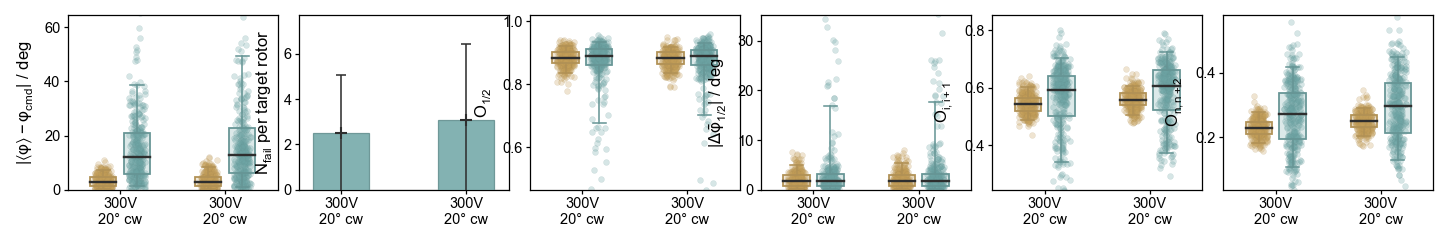

In [28]:

plot_stationarity_from_measurements(
    m_list=m_list,
    failure_threshold_deg=25.0,
    metric_source="window",
    rotor_classes=("calibration", "target"),
    fig_width_mm=250,
    fig_height_mm=40,
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d_stationarity_steering_connectivity",
)

#### iii. Plot exemplary data of calibration rotor and target rotor

In [29]:
def plot_exemplary_data_rotors(
    m_list,
    particle=None,
    rotor_index=None,
    measurement_index=0,
    rotor_class="target",
    center_phase="deg-100",
    example_phases=None,
    n_neighbor_windows=5,
    C=CK_colors,
    hist_bins=72,
    rolling_mean_s=0.10,
    max_trace_points=500,
    fig_width_mm=180,
    fig_height_mm=120,
    save_dir=None,
    save_prefix="umbrella_qc_single_particle_lean",
    stator_variant=None,
):
    """
    Lean single-particle umbrella QC plot.

    Compatible with the new lean QC storage:
        m.voltage_stationarity_overlap_window_df

    Required on each UMB measurement:
        m.voltage_stationarity_overlap_window_df
        m.trajectories
        m.protocol

    Optional rotor lists:
        target:
            m.target_rotors
            m.target_particles

        calibration:
            m.calibration_rotors
            m.flat_rotors
            m.flat_particles_reliable
            m.flat_particles

    Particle selection:
        1) particle=<id> directly uses that particle id.
        2) rotor_index=<i> selects from the corresponding rotor list.
        3) if neither is given, auto-selects from the QC window table.

    Notes
    -----
    - Does not require m.voltage_stationarity_overlap_particle_df.
    - Does not write anything back into m.
    - Derives radian columns locally from degree columns if needed.
    - Recomputes only the traces/histograms needed for the shown particle.
    - Saves only if save_dir is not None.
    - Closes the figure after display.
    - Returns None.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    phi0_offset_rad = -np.pi / 2

    rotor_class = str(rotor_class).lower().strip()
    if rotor_class not in {"target", "calibration"}:
        raise ValueError("rotor_class must be 'target' or 'calibration'.")


    cmd_color = C["black"]
    calib_color = C["warmgold"]
    selected_color = C["target_teal"] if rotor_class == "target" else C["warmgold"]

    overlap_fill_color = (
        (*C["target_teal"][:3], 0.450)
        if rotor_class == "target"
        else (*C["beige"][:3], 0.75)
    )

    raw_trace_color = (0.82, 0.82, 0.82)
    smooth_trace_color = C["black"]
    early_color = C["lightgrey"]
    late_color = C["black"]
    overlap_i_color = C["black"]
    overlap_j_color = C["midgrey"]
    selected_band_color = (0.88, 0.88, 0.88)

    heat_cmap = LinearSegmentedColormap.from_list(
        "white_to_selected",
        [(1, 1, 1, 1), tuple(list(selected_color) + [1.0])],
        N=256,
    )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def align_angle_to_reference(angle, reference):
        angle = np.asarray(angle, dtype=float)
        reference = np.asarray(reference, dtype=float)
        return reference + wrap_pi(angle - reference)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (pd.Series, np.ndarray)):
            x = x.tolist()
        if isinstance(x, (list, tuple, set)):
            out = []
            for v in x:
                try:
                    fv = float(v)
                    if np.isfinite(fv):
                        out.append(int(fv))
                except Exception:
                    pass
            return out
        try:
            return [int(x)]
        except Exception:
            return []

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=6.5):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
        )

    def is_umb(m):
        s = str(getattr(m, "path", "")).upper()

        if "DIFF" in s:
            return False

        if "UMB" in s:
            return True

        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def infer_dt(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def infer_trim_s(m, wdf):
        if hasattr(m, "autocorrelation_trim_s"):
            try:
                v = float(m.autocorrelation_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if hasattr(m, "wham_trim_s"):
            try:
                v = float(m.wham_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if "trim_s" in wdf.columns and len(wdf):
            vals = wdf["trim_s"].to_numpy(float)
            vals = vals[np.isfinite(vals) & (vals >= 0)]
            if vals.size:
                return float(vals[0])

        return 0.0

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or not a dict.")

        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            try:
                deg = float(phase.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def hist_density(phi, edges):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        dphi = float(edges[1] - edges[0])

        return counts.astype(float) / (float(total) * dphi)

    def get_example_window_indices(windows):
        if example_phases is not None:
            out = []

            for ph in list(example_phases):
                hit = windows[windows["phase"].astype(str) == str(ph)]

                if len(hit):
                    out.append(int(hit["window_index"].iloc[0]))

            if not out:
                raise ValueError("None of the requested example_phases were found.")

            return out

        if center_phase is None:
            center_i = len(windows) // 2
        else:
            hit = windows[windows["phase"].astype(str) == str(center_phase)]
            center_i = int(hit["window_index"].iloc[0]) if len(hit) else len(windows) // 2

        n = max(1, int(n_neighbor_windows))
        n_left = n // 2
        n_right = n - n_left - 1
        nwin = len(windows)

        return [int((center_i + j) % nwin) for j in range(-n_left, n_right + 1)]

    def smooth_trace_time(t, y, rolling_mean_s):
        t = np.asarray(t, dtype=float)
        y = np.asarray(y, dtype=float)

        if t.size < 3 or rolling_mean_s is None or rolling_mean_s <= 0:
            return y.copy()

        dt = np.nanmedian(np.diff(t))

        if not np.isfinite(dt) or dt <= 0:
            return y.copy()

        win = max(3, int(round(float(rolling_mean_s) / dt)))

        if win % 2 == 0:
            win += 1

        if win >= y.size:
            win = y.size if y.size % 2 else y.size - 1

        if win < 3:
            return y.copy()

        finite = np.isfinite(y)
        y0 = np.where(finite, y, 0.0)
        w0 = finite.astype(float)

        kernel = np.ones(win, dtype=float)
        pad = win // 2

        ypad = np.pad(y0, pad_width=pad, mode="edge")
        wpad = np.pad(w0, pad_width=pad, mode="edge")

        num = np.convolve(ypad, kernel, mode="valid")
        den = np.convolve(wpad, kernel, mode="valid")

        out = np.full_like(y, np.nan, dtype=float)
        ok = den > 0
        out[ok] = num[ok] / den[ok]

        return out

    def downsample(t, y, nmax):
        t = np.asarray(t)
        y = np.asarray(y)

        if t.size <= int(nmax):
            return t, y

        idx = np.linspace(0, t.size - 1, int(nmax)).astype(int)

        return t[idx], y[idx]

    def pick_col(df, candidates):
        for col in candidates:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        tr = getattr(m, "trajectories", None)

        if tr is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr:
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_col(tr, ["phase", "protocol", "phase_name", "window", "segment"])

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return tr

    def extract_particle_trace(obj, pid):
        pid = int(pid)

        if obj is None:
            return np.array([], dtype=float)

        if isinstance(obj, pd.DataFrame):
            group_col = pick_col(obj, ["group", "group_int", "particle", "particle_id"])
            phi_col = pick_col(
                obj,
                [
                    "phi_unwrapped",
                    "phi_unwrap",
                    "phi_unwrapped_rad",
                    "unwrapped_phi",
                    "phi_cont",
                    "phi_continuous",
                    "phi_trajectory",
                    "phi",
                ],
            )

            if group_col is not None and phi_col is not None:
                d = obj[obj[group_col].astype(int) == pid].copy()

                if len(d) == 0:
                    return np.array([], dtype=float)

                sort_col = pick_col(d, ["frame", "t", "time_s", "time"])

                if sort_col is not None:
                    d = d.sort_values(sort_col, kind="mergesort")

                return d[phi_col].to_numpy(float)

            for col in [pid, str(pid), f"p{pid}", f"particle_{pid}"]:
                if col in obj.columns:
                    return obj[col].to_numpy(float)

            return np.array([], dtype=float)

        if isinstance(obj, dict):
            if pid in obj:
                return extract_particle_trace(obj[pid], pid)
            if str(pid) in obj:
                return extract_particle_trace(obj[str(pid)], pid)

            for key in obj:
                if str(key) == str(pid):
                    return extract_particle_trace(obj[key], pid)

            return np.array([], dtype=float)

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if pid < arr.shape[0]:
                return arr[pid, :].astype(float)
            if pid < arr.shape[1]:
                return arr[:, pid].astype(float)

        return np.array([], dtype=float)

    def get_trace_for_phase(m, pid, phase, trim_s, dt):
        phi = extract_particle_trace(get_phase_container(m, phase), pid)
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.array([], dtype=float), np.array([], dtype=float)

        n_trim = max(0, min(phi.size, int(np.floor(float(trim_s) / float(dt)))))
        phi = phi[n_trim:]

        t = np.arange(phi.size, dtype=float) * float(dt)

        return t, wrap_pi(phi)

    def get_rotor_list(m, rotor_class):
        if rotor_class == "target":
            attrs = ["target_rotors", "target_particles"]
        else:
            attrs = ["calibration_rotors", "flat_rotors", "flat_particles_reliable", "flat_particles"]

        for attr in attrs:
            if hasattr(m, attr):
                vals = as_int_list(getattr(m, attr))

                if vals:
                    return vals, attr

        return [], None

    def resolve_particle(m, particle, rotor_index, rotor_class, window_df):
        if particle is not None:
            return int(particle)

        rotor_list, source_attr = get_rotor_list(m, rotor_class)

        if rotor_index is not None:
            if not rotor_list:
                raise ValueError(
                    f"rotor_index was given, but no {rotor_class} rotor list exists on this measurement."
                )

            idx = int(rotor_index)

            if idx < 0 or idx >= len(rotor_list):
                raise IndexError(
                    f"rotor_index={idx} outside m.{source_attr}, which has n={len(rotor_list)} entries."
                )

            return int(rotor_list[idx])

        d = window_df.copy()

        if "rotor_class" in d.columns:
            d = d[d["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()
        elif rotor_list:
            d = d[d["particle"].astype(int).isin(rotor_list)].copy()

        if len(d) == 0 and rotor_list:
            return int(rotor_list[0])

        if len(d) == 0:
            raise ValueError(
                f"Could not auto-select a {rotor_class} rotor. "
                "Pass particle=<id> or rotor_index=<i>."
            )

        score_rows = []

        for pid, g in d.groupby("particle", sort=True):
            score = 0.0

            if "half_overlap" in g.columns:
                vals = g["half_overlap"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "neighbor_overlap_mean" in g.columns:
                vals = g["neighbor_overlap_mean"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "half_mean_shift_deg" in g.columns:
                vals = np.abs(g["half_mean_shift_deg"].to_numpy(float))
                shift = float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0
                score -= 0.01 * shift

            score_rows.append((int(pid), score))

        if not score_rows:
            row = d.sort_values("particle").iloc[0]
            return int(row["particle"])

        return int(sorted(score_rows, key=lambda x: x[1], reverse=True)[0][0])

    def make_local_plot_columns(wdf):
        wdf = wdf.copy()

        if "phi0_cmd_rad" not in wdf.columns:
            if "phi0_cmd_deg" in wdf.columns:
                wdf["phi0_cmd_rad"] = np.deg2rad(wdf["phi0_cmd_deg"].to_numpy(float))
            else:
                raise KeyError("Need phi0_cmd_deg or phi0_cmd_rad in m.voltage_stationarity_overlap_window_df.")

        if "phi0_cmd_deg" not in wdf.columns:
            wdf["phi0_cmd_deg"] = np.rad2deg(wdf["phi0_cmd_rad"].to_numpy(float))

        if "mean_phi_rad" not in wdf.columns and "mean_phi_deg" in wdf.columns:
            wdf["mean_phi_rad"] = np.deg2rad(wdf["mean_phi_deg"].to_numpy(float))

        if "mean_phi_deg" not in wdf.columns and "mean_phi_rad" in wdf.columns:
            wdf["mean_phi_deg"] = np.rad2deg(wdf["mean_phi_rad"].to_numpy(float))

        if "calib_mean_phi_rad" not in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
            wdf["calib_mean_phi_rad"] = np.deg2rad(wdf["calib_mean_phi_deg"].to_numpy(float))

        if "calib_mean_phi_deg" not in wdf.columns and "calib_mean_phi_rad" in wdf.columns:
            wdf["calib_mean_phi_deg"] = np.rad2deg(wdf["calib_mean_phi_rad"].to_numpy(float))

        if "target_mean_phi_rad" not in wdf.columns and "target_mean_phi_deg" in wdf.columns:
            wdf["target_mean_phi_rad"] = np.deg2rad(wdf["target_mean_phi_deg"].to_numpy(float))

        if "target_mean_phi_deg" not in wdf.columns and "target_mean_phi_rad" in wdf.columns:
            wdf["target_mean_phi_deg"] = np.rad2deg(wdf["target_mean_phi_rad"].to_numpy(float))

        if "delta_target_minus_calib_mean_phi_deg" not in wdf.columns:
            if "mean_phi_deg" in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wrap_deg(
                    wdf["mean_phi_deg"].to_numpy(float)
                    - wdf["calib_mean_phi_deg"].to_numpy(float)
                )
            elif "calib_target_error_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wdf["calib_target_error_deg"].to_numpy(float)
            else:
                wdf["delta_target_minus_calib_mean_phi_deg"] = np.nan

        if "neighbor_overlap_min" not in wdf.columns and "neighbor_overlap_mean" in wdf.columns:
            wdf["neighbor_overlap_min"] = wdf["neighbor_overlap_mean"].to_numpy(float)

        if "neighbor2_overlap_min" not in wdf.columns and "neighbor2_overlap_mean" in wdf.columns:
            wdf["neighbor2_overlap_min"] = wdf["neighbor2_overlap_mean"].to_numpy(float)

        return wdf

    m_flat = flatten(m_list)

    if not m_flat:
        raise ValueError("m_list is empty.")

    measurement_index = int(measurement_index)

    if measurement_index < 0 or measurement_index >= len(m_flat):
        raise IndexError(f"measurement_index={measurement_index} outside m_list length {len(m_flat)}.")

    m = m_flat[measurement_index]

    if not is_umb(m):
        raise ValueError(
            f"measurement_index={measurement_index} does not look like an UMB measurement."
        )

    window_df = getattr(m, "voltage_stationarity_overlap_window_df", None)

    if window_df is None or len(window_df) == 0:
        raise ValueError("m.voltage_stationarity_overlap_window_df is missing or empty.")

    window_df = window_df.copy()

    if "measurement_index" in window_df.columns:
        window_df = window_df[window_df["measurement_index"].astype(int) == measurement_index].copy()

    particle = resolve_particle(
        m=m,
        particle=particle,
        rotor_index=rotor_index,
        rotor_class=rotor_class,
        window_df=window_df,
    )

    wdf = window_df[window_df["particle"].astype(int) == int(particle)].copy()

    if "rotor_class" in wdf.columns:
        wdf_class = wdf[wdf["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()

        if len(wdf_class):
            wdf = wdf_class

    if len(wdf) == 0:
        raise ValueError(
            f"No stored QC rows found for particle={particle}, rotor_class={rotor_class}."
        )

    wdf = wdf.sort_values("window_index").reset_index(drop=True)
    wdf = make_local_plot_columns(wdf)

    windows = get_deg_windows(m)
    dt = infer_dt(m)
    trim_s = infer_trim_s(m, wdf)

    example_wi = get_example_window_indices(windows)

    edges_phi = np.linspace(-np.pi, np.pi, int(hist_bins) + 1)
    centers_phi = 0.5 * (edges_phi[:-1] + edges_phi[1:])

    window_cache = {}

    for _, row in windows.iterrows():
        wi = int(row["window_index"])
        phase = str(row["phase"])
        t, phi = get_trace_for_phase(m, particle, phase, trim_s, dt)

        window_cache[wi] = {
            "phase": phase,
            "t": t,
            "phi": phi,
            "density": hist_density(phi, edges_phi),
        }

    density_arr = np.asarray(
        [window_cache[int(wi)]["density"] for wi in wdf["window_index"].astype(int)],
        dtype=float,
    )

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left = 0.045
    right = 0.985
    bottom = 0.075
    top = 0.94

    nrows = len(example_wi)
    row_gap = 0.016
    row_h = (top - bottom - row_gap * (nrows - 1)) / nrows

    w_heat = 0.18
    w_trace = 0.18
    w_stat = 0.16
    w_overlap = 0.16
    w_metrics = right - left - w_heat - w_trace - w_stat - w_overlap - 4 * 0.035

    x_heat = left
    x_trace = x_heat + w_heat + 0.035
    x_stat = x_trace + w_trace + 0.035
    x_overlap = x_stat + w_stat + 0.035
    x_metrics = x_overlap + w_overlap + 0.035

    ax_heat = fig.add_axes([x_heat, bottom, w_heat, top - bottom])

    vmax = None
    if np.any(np.isfinite(density_arr)):
        vmax0 = float(np.nanpercentile(density_arr, 95))
        if np.isfinite(vmax0) and vmax0 > 0:
            vmax = vmax0

    ax_heat.imshow(
        density_arr,
        aspect="auto",
        interpolation="nearest",
        origin="lower",
        extent=[-np.pi, np.pi, -0.5, len(density_arr) - 0.5],
        cmap=heat_cmap,
        vmin=0,
        vmax=vmax,
        alpha=0.80,
    )

    cmd_phi = wdf["phi0_cmd_rad"].to_numpy(float)
    ywin = np.arange(len(wdf), dtype=float)

    wi_to_rowpos = {int(wi): i for i, wi in enumerate(wdf["window_index"].astype(int))}

    for wi in example_wi:
        if int(wi) in wi_to_rowpos:
            y = wi_to_rowpos[int(wi)]
            ax_heat.axhspan(
                y - 0.45,
                y + 0.45,
                color=selected_band_color,
                alpha=0.20,
                lw=0,
                zorder=0,
            )

    ax_heat.plot(
        cmd_phi,
        ywin,
        lw=1.15,
        ls="--",
        color=cmd_color,
        label=r"$\varphi_\mathrm{cmd}$",
        zorder=4,
    )

    if "calib_mean_phi_rad" in wdf.columns:
        calib_phi = align_angle_to_reference(wdf["calib_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            calib_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=calib_color,
            label="calib.",
            zorder=5,
        )

    if "mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target" if rotor_class == "target" else "selected",
            zorder=6,
        )
    elif "target_mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["target_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target",
            zorder=6,
        )

    ax_heat.set_xlim(-1.10 * np.pi, 1.10 * np.pi)
    ax_heat.set_xlabel(r"$\varphi$ / rad", fontsize=7)
    ax_heat.set_ylabel("window index", fontsize=7)
    ax_heat.set_xticks([-np.pi, 0, np.pi])
    ax_heat.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
    ax_heat.legend(
        frameon=False,
        fontsize=5.4,
        loc="lower right",
        handlelength=1.2,
        borderpad=0.1,
        labelspacing=0.2,
    )
    style_ax(ax_heat)

    stat_share_ax = None
    overlap_share_ax = None

    for r, wi in enumerate(example_wi):
        y0 = top - (r + 1) * row_h - r * row_gap

        win_row = windows[windows["window_index"].astype(int) == int(wi)].iloc[0]
        phi0 = float(win_row["phi0_cmd_rad"])

        t = window_cache[int(wi)]["t"]
        phi = window_cache[int(wi)]["phi"]
        psi = wrap_pi(phi - phi0)

        ax = fig.add_axes([x_trace, y0, w_trace, row_h])

        t_plot, psi_plot = downsample(t, psi, max_trace_points)
        psi_smooth = smooth_trace_time(t_plot, psi_plot, rolling_mean_s)

        ax.plot(
            t_plot,
            np.rad2deg(psi_plot),
            lw=0.40,
            color=raw_trace_color,
            alpha=0.85,
            rasterized=True,
        )
        ax.plot(
            t_plot,
            np.rad2deg(psi_smooth),
            lw=1.00,
            color=smooth_trace_color,
            alpha=0.95,
        )
        ax.axhline(0, lw=0.45, color="black", alpha=0.30)
        ax.set_ylim(-55, 55)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.set_ylabel("")

        if r == 0:
            scale_x = 0.06
            scale_y0 = 0.10
            scale_y1 = scale_y0 + 20.0 / 110.0

            ax.plot(
                [scale_x, scale_x],
                [scale_y0, scale_y1],
                transform=ax.transAxes,
                color=C["black"],
                lw=1.15,
                solid_capstyle="butt",
                clip_on=False,
                zorder=5,
            )
            ax.text(
                scale_x + 0.025,
                0.5 * (scale_y0 + scale_y1),
                "20°",
                transform=ax.transAxes,
                ha="left",
                va="center",
                fontsize=6,
                color=C["black"],
            )

        if r == nrows - 1:
            ax.set_xlabel("time / s", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if stat_share_ax is None:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h])
            stat_share_ax = ax
        else:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h], sharey=stat_share_ax)

        finite_psi = psi[np.isfinite(psi)]

        if finite_psi.size >= 4:
            half = finite_psi.size // 2
            p_first = hist_density(finite_psi[:half], edges_phi)
            p_second = hist_density(finite_psi[half:], edges_phi)

            ax.plot(centers_phi, p_first, lw=1.00, color=early_color, alpha=0.95)
            ax.plot(centers_phi, p_second, lw=1.15, color=late_color, alpha=0.95)

        ax.set_xlim(-0.5 * np.pi, 0.5 * np.pi)
        ax.set_xticks([-0.5 * np.pi, 0, 0.5 * np.pi])
        ax.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"], fontsize=6)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.set_ylabel("")

        if r == nrows - 1:
            ax.set_xlabel(r"$\psi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if overlap_share_ax is None:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h])
            overlap_share_ax = ax
        else:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h], sharey=overlap_share_ax)

        next_wi = int((int(wi) + 1) % len(windows))
        phi_next = window_cache[next_wi]["phi"]

        p_i = hist_density(phi, edges_phi)
        p_j = hist_density(phi_next, edges_phi)
        p_min = np.minimum(p_i, p_j)

        ax.fill_between(
            centers_phi,
            0,
            p_min,
            color=overlap_fill_color,
            linewidth=0,
            zorder=1,
        )
        ax.plot(centers_phi, p_i, lw=1.05, color=overlap_i_color, alpha=0.95, zorder=3)
        ax.plot(centers_phi, p_j, lw=1.05, color=overlap_j_color, alpha=0.95, zorder=2)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.set_ylabel("")

        if r == nrows - 1:
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

    metrics_h_gap = 0.06
    metrics_h = (top - bottom - 2 * metrics_h_gap) / 3

    ax_m1 = fig.add_axes([x_metrics, bottom + 2 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m2 = fig.add_axes([x_metrics, bottom + 1 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m3 = fig.add_axes([x_metrics, bottom, w_metrics, metrics_h])

    x = wdf["phi0_cmd_deg"].to_numpy(float)
    sort = np.argsort(x)
    x_sorted = x[sort]

    def shade_metric_ax(ax):
        xvals = wdf["phi0_cmd_deg"].to_numpy(float)
        xvals = xvals[np.isfinite(xvals)]

        dx = np.nanmedian(np.abs(np.diff(np.sort(xvals)))) if xvals.size > 1 else 20.0

        if not np.isfinite(dx) or dx <= 0:
            dx = 20.0

        for wi in example_wi:
            row = wdf[wdf["window_index"].astype(int) == int(wi)]

            if len(row) == 0:
                continue

            xx = float(row["phi0_cmd_deg"].iloc[0])

            ax.axvspan(
                xx - 0.35 * dx,
                xx + 0.35 * dx,
                color=selected_band_color,
                alpha=0.35,
                lw=0,
                zorder=0,
            )

    for ax in [ax_m1, ax_m2, ax_m3]:
        shade_metric_ax(ax)

    if rotor_class == "target" and "delta_target_minus_calib_mean_phi_deg" in wdf.columns:
        delta = wdf["delta_target_minus_calib_mean_phi_deg"].to_numpy(float)
        delta_label = r"$\langle\varphi_\mathrm{t}\rangle-\langle\varphi_\mathrm{c}\rangle$ / °"
    elif "command_error_deg" in wdf.columns:
        delta = wdf["command_error_deg"].to_numpy(float)
        delta_label = r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °"
    elif "mean_phi_deg" in wdf.columns and "phi0_cmd_deg" in wdf.columns:
        delta = wrap_deg(wdf["mean_phi_deg"].to_numpy(float) - wdf["phi0_cmd_deg"].to_numpy(float))
        delta_label = r"$\langle\varphi\rangle-\varphi_\mathrm{cmd}$ / °"
    else:
        delta = np.full(len(wdf), np.nan)
        delta_label = r"$\Delta\varphi$ / °"

    ax_m1.axhline(0, lw=0.5, color="black", alpha=0.40, zorder=1)
    ax_m1.plot(x_sorted, delta[sort], marker="o", ms=2.1, lw=0.90, color="black", zorder=3)
    ax_m1.set_ylabel(delta_label, fontsize=6.5)
    ax_m1.set_xticklabels([])
    style_ax(ax_m1, labelsize=6)

    if "half_overlap" in wdf.columns:
        ax_m2.plot(
            x_sorted,
            wdf["half_overlap"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            zorder=3,
        )

    ax_m2.set_ylim(0, 1.03)
    ax_m2.set_ylabel(r"$O_{1/2}$", fontsize=6.5)
    ax_m2.set_xticklabels([])
    style_ax(ax_m2, labelsize=6)

    if "neighbor_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor_overlap_mean"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            label=r"$O_{i,i+1}$",
            zorder=3,
        )

    if "neighbor2_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor2_overlap_mean"].to_numpy(float)[sort],
            lw=0.85,
            color=C["midgrey"],
            label=r"$O_{n,n+2}$",
            zorder=2,
        )

    ax_m3.set_ylim(0, 1.03)
    ax_m3.set_ylabel(r"$O_{i,i+1}$", fontsize=6.5)
    ax_m3.set_xlabel(r"$\varphi_\mathrm{cmd}$ / °", fontsize=6.5)
    ax_m3.legend(frameon=False, fontsize=5.8, handlelength=1.0)
    style_ax(ax_m3, labelsize=6)

    xmin = np.nanmin(x_sorted) if np.any(np.isfinite(x_sorted)) else -180
    xmax = np.nanmax(x_sorted) if np.any(np.isfinite(x_sorted)) else 180

    for ax in [ax_m1, ax_m2, ax_m3]:
        ax.set_xlim(xmin - 5, xmax + 5)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        suffix = f"{rotor_class}_p{int(particle)}"

        if rotor_index is not None:
            suffix = f"{rotor_class}_idx{int(rotor_index)}_p{int(particle)}"

        out_name = f"{prefixed_name(save_prefix)}__{suffix}"

        fig.savefig(save_dir / f"{out_name}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{out_name}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

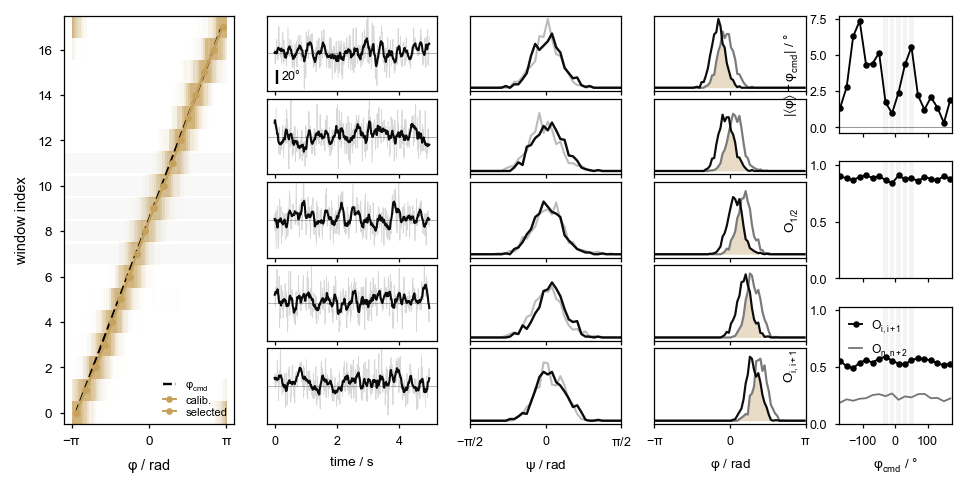

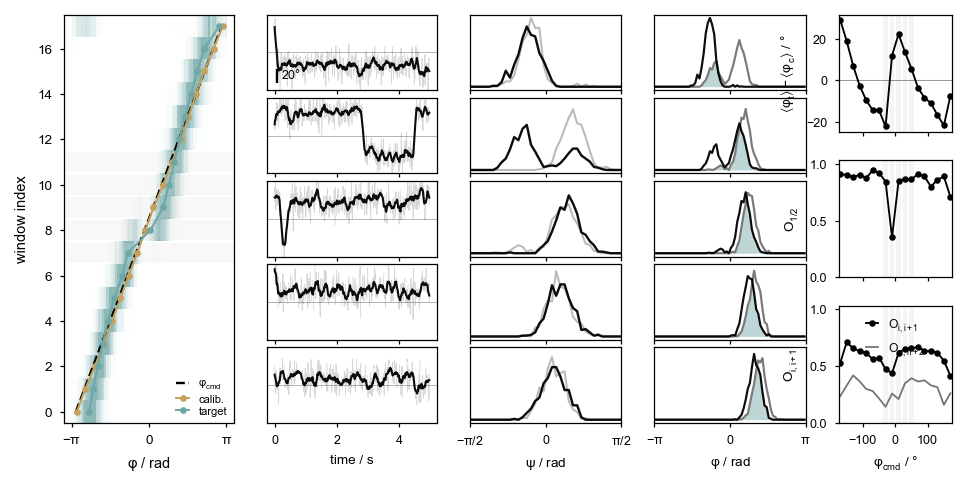

In [30]:
# if full_execution:
plot_exemplary_data_rotors(
    m_list,
    measurement_index=0,
    rotor_class="calibration",
    rotor_index=0,
    C=CK_colors,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__overlap_steering_exemplary_calibration_rotor",
    stator_variant=stator_variant,
    fig_width_mm=160,
    fig_height_mm=80,
    center_phase="deg-100",
)

plot_exemplary_data_rotors(
    m_list,
    measurement_index=0,
    rotor_class="target",
    particle=17,
    save_dir=save_dir_SI,
    C=CK_colors,
    save_prefix="SI_toFig2d__overlap_steering_exemplary_target_rotor",
    stator_variant=stator_variant,
    fig_width_mm=160,
    fig_height_mm=80,
    center_phase="deg-100",
)

#### iv. Plot summary statistics on stationarity and window overlap

In [31]:
def plot_umbrella_qc_histograms_from_measurements(
    m_list,
    C=None,
    fig_width_mm=180,
    row_height_mm=42,
    save_dir=None,
    save_prefix="umbrella_qc_histograms",
    stator_variant=None,
    delta_col=None,
    target_half_overlap_col="half_overlap",
    calib_half_overlap_col="half_overlap",
    neighbor_overlap_col="neighbor_overlap_mean",
    use_abs_delta=True,
    delta_bins=None,
    overlap_bins=None,
    threshold_delta_deg=10.0,
    threshold_half_overlap=0.80,
    threshold_neighbor_overlap=0.25,
    density=True,
    alpha=0.82,
    edge_lw=0.35,
    dpi=300,
):
    """
    Plot umbrella-window QC histograms.

    One row = one UMB measurement in m_list.
    Columns:
        1) calibration O_half
        2) target-calibration steering mismatch
        3) target O_half
        4) target neighbor overlap

    Required beforehand:
        compute_stationarity_overlap_target_rotors(...)

    Reads from each UMB measurement:
        m.voltage_stationarity_overlap_window_df

    Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)

    warmgold = C.get("warmgold", C.get("gold", (226 / 255, 172 / 255, 72 / 255)))
    target_teal = C.get("target_teal", (111 / 255, 166 / 255, 166 / 255))
    black = C.get("black", (0, 0, 0))
    grey = C.get("grey", (0.35, 0.35, 0.35))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys())
        )

    def parse_voltage_from_name(name):
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            str(name),
            flags=re.IGNORECASE,
        )

        if not hits:
            return None

        v = float(hits[-1])
        return int(round(v)) if abs(v - round(v)) < 1e-9 else v

    def short_umb_label(m, fallback_index):
        name = measurement_name(m, fallback_index)
        v = parse_voltage_from_name(name)

        step = None
        m_step = re.search(r"_(\d+(?:\.\d+)?)deg", name, flags=re.IGNORECASE)
        if m_step:
            step = m_step.group(1)

        low = name.lower()
        direction = None
        if "ccw" in low:
            direction = "ccw"
        elif "cw" in low:
            direction = "cw"

        line1 = f"{v}V" if v is not None else f"UMB {fallback_index + 1}"

        extra = []
        if step is not None:
            extra.append(f"{step}°")
        if direction is not None:
            extra.append(direction)

        line2 = " ".join(extra) if extra else f"m{fallback_index + 1}"
        return f"{line1}\n{line2}"

    def collect_measurements_with_qc(m_list):
        rows = []
        umb_counter = 0

        for source_index, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            d = df.copy()

            if "measurement_index" not in d.columns:
                d["measurement_index"] = int(source_index)

            if "measurement_name" not in d.columns:
                d["measurement_name"] = measurement_name(m, source_index)

            if "voltage" not in d.columns:
                v = parse_voltage_from_name(measurement_name(m, source_index))
                d["voltage"] = np.nan if v is None else v

            if "rotor_class" not in d.columns:
                if "ensemble" in d.columns:
                    d["rotor_class"] = d["ensemble"].astype(str)
                else:
                    raise KeyError(
                        f"{measurement_name(m, source_index)} needs a 'rotor_class' column, "
                        "or an older 'ensemble' column."
                    )

            rows.append(
                {
                    "m": m,
                    "source_index": int(source_index),
                    "umb_index": int(umb_counter),
                    "label": short_umb_label(m, umb_counter),
                    "name": measurement_name(m, source_index),
                    "df": d,
                }
            )

            umb_counter += 1

        if not rows:
            raise ValueError(
                "No stored UMB QC tables found. "
                "Run compute_stationarity_overlap_target_rotors(...) first."
            )

        return rows

    def find_col(df, candidates, label):
        for col in candidates:
            if col is not None and col in df.columns:
                return col

        raise KeyError(
            f"Could not find column for {label}.\n"
            f"Tried: {candidates}\n\n"
            f"Available columns:\n{list(df.columns)}"
        )

    def finite_values(df, col):
        x = pd.to_numeric(df[col], errors="coerce").to_numpy(float)
        return x[np.isfinite(x)]

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color=black,
            labelcolor=black,
            direction="out",
        )

        ax.grid(False)

    def draw_hist(
        ax,
        x,
        bins,
        color,
        xlabel,
        threshold=None,
        threshold_kind=None,
        xlim=None,
        ylabel=None,
    ):
        ax.hist(
            x,
            bins=bins,
            density=bool(density),
            color=color,
            alpha=float(alpha),
            edgecolor=black,
            linewidth=float(edge_lw),
        )

        if threshold is not None and np.isfinite(threshold):
            ax.axvline(
                float(threshold),
                color=grey,
                lw=0.8,
                ls=(0, (2.2, 1.6)),
                zorder=5,
            )

            x0, x1 = ax.get_xlim()

            if threshold_kind == "below_good":
                ax.axvspan(
                    x0,
                    float(threshold),
                    color=lightgrey,
                    alpha=0.12,
                    zorder=-10,
                    linewidth=0,
                )

            elif threshold_kind == "above_good":
                ax.axvspan(
                    float(threshold),
                    x1,
                    color=lightgrey,
                    alpha=0.12,
                    zorder=-10,
                    linewidth=0,
                )

        if xlim is not None:
            ax.set_xlim(*xlim)

        if xlim == (0.0, 1.0):
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.set_xticklabels(["0", "", "0.5", "", "1"])

        ax.set_xlabel(xlabel, fontsize=8)

        if ylabel is not None:
            ax.set_ylabel(ylabel, fontsize=8)

        style_ax(ax)

    rows = collect_measurements_with_qc(m_list)

    if overlap_bins is None:
        overlap_bins = np.linspace(0.0, 1.0, 31)

    prepared = []

    for row in rows:
        df = row["df"].copy()
        df["rotor_class"] = df["rotor_class"].astype(str)

        target_df = df[df["rotor_class"] == "target"].copy()
        calib_df = df[df["rotor_class"] == "calibration"].copy()

        if len(target_df) == 0:
            continue

        if len(calib_df) == 0:
            continue

        delta_col_use = find_col(
            target_df,
            [
                delta_col,
                "calib_target_error_deg",
                "delta_target_minus_calib_mean_phi_deg",
                "target_minus_calib_mean_phi_deg",
                "target_calib_error_deg",
            ],
            "target-calibration steering mismatch",
        )

        target_half_overlap_col_use = find_col(
            target_df,
            [target_half_overlap_col, "half_overlap", "O_half"],
            "target half-window overlap",
        )

        calib_half_overlap_col_use = find_col(
            calib_df,
            [calib_half_overlap_col, "half_overlap", "O_half"],
            "calibration half-window overlap",
        )

        neighbor_overlap_col_use = find_col(
            target_df,
            [
                neighbor_overlap_col,
                "neighbor_overlap_mean",
                "neighbor_overlap_min",
                "neighbor_overlap",
                "O_neighbor",
            ],
            "target neighbor-window overlap",
        )

        delta = finite_values(target_df, delta_col_use)
        delta_plot = np.abs(delta) if bool(use_abs_delta) else delta.copy()

        O_half_target = finite_values(target_df, target_half_overlap_col_use)
        O_neighbor_target = finite_values(target_df, neighbor_overlap_col_use)
        O_half_calib = finite_values(calib_df, calib_half_overlap_col_use)

        O_half_target = O_half_target[(O_half_target >= 0.0) & (O_half_target <= 1.0)]
        O_neighbor_target = O_neighbor_target[(O_neighbor_target >= 0.0) & (O_neighbor_target <= 1.0)]
        O_half_calib = O_half_calib[(O_half_calib >= 0.0) & (O_half_calib <= 1.0)]

        if (
            O_half_calib.size == 0
            or O_half_target.size == 0
            or O_neighbor_target.size == 0
            or delta_plot.size == 0
        ):
            continue

        prepared.append(
            {
                "label": row["label"],
                "name": row["name"],
                "target_df": target_df,
                "calib_df": calib_df,
                "O_half_calib": O_half_calib,
                "delta_plot": delta_plot,
                "O_half_target": O_half_target,
                "O_neighbor_target": O_neighbor_target,
            }
        )

    if not prepared:
        raise ValueError("No UMB measurement had complete calibration and target QC values to plot.")

    if delta_bins is None:
        all_delta = np.concatenate([p["delta_plot"] for p in prepared])
        q98 = float(np.nanquantile(all_delta, 0.98))
        xmax = max(
            5.0,
            q98,
            float(threshold_delta_deg) * 1.35 if threshold_delta_deg is not None else q98,
        )

        if np.nanmax(all_delta) > 0:
            xmax = min(xmax, float(np.nanmax(all_delta)))

        xmax = max(xmax, 10.0)
        delta_bins = np.linspace(0.0, xmax, 31) if bool(use_abs_delta) else 31

    plt.rcParams.update({
        "font.size": 8,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    nrows = len(prepared)
    fig_height_mm = float(row_height_mm) * float(nrows)

    fig, axes = plt.subplots(
        nrows,
        4,
        figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)),
        squeeze=False,
        constrained_layout=False,
    )

    for r, p in enumerate(prepared):
        ax0, ax1, ax2, ax3 = axes[r, :]

        ylabel = "density" if bool(density) else "counts"

        draw_hist(
            ax0,
            p["O_half_calib"],
            bins=overlap_bins,
            color=warmgold,
            xlabel=r"$O_{1/2}$",
            threshold=threshold_half_overlap,
            threshold_kind="above_good",
            xlim=(0.0, 1.0),
            ylabel=ylabel,
        )

        draw_hist(
            ax1,
            p["delta_plot"],
            bins=delta_bins,
            color=target_teal,
            xlabel=r"$|\Delta\varphi_i^\mathrm{target-calib}|$ / °",
            threshold=threshold_delta_deg,
            threshold_kind="below_good",
            xlim=(0.0, max(delta_bins)) if bool(use_abs_delta) and np.ndim(delta_bins) > 0 else None,
            ylabel=ylabel,
        )

        draw_hist(
            ax2,
            p["O_half_target"],
            bins=overlap_bins,
            color=target_teal,
            xlabel=r"$O_{1/2}$",
            threshold=threshold_half_overlap,
            threshold_kind="above_good",
            xlim=(0.0, 1.0),
            ylabel=ylabel,
        )

        draw_hist(
            ax3,
            p["O_neighbor_target"],
            bins=overlap_bins,
            color=target_teal,
            xlabel=r"$O_\mathrm{n,n+1}$",
            threshold=threshold_neighbor_overlap,
            threshold_kind="above_good",
            xlim=(0.0, 1.0),
            ylabel=ylabel,
        )

        for ax in axes[r, :]:
            ax.set_yticks([])
            ax.tick_params(axis="y", length=0)

        n_target_particles = (
            p["target_df"]["particle"].nunique()
            if "particle" in p["target_df"].columns
            else np.nan
        )
        n_calib_particles = (
            p["calib_df"]["particle"].nunique()
            if "particle" in p["calib_df"].columns
            else np.nan
        )

        n_target_windows = len(p["target_df"])
        n_calib_windows = len(p["calib_df"])

        txt = (
            f"{p['label']}\n"
            f"calib.: {int(n_calib_particles)} particles, {int(n_calib_windows)} windows\n"
            f"target: {int(n_target_particles)} particles, {int(n_target_windows)} windows"
        )

        ax0.text(
            0.02,
            0.98,
            txt,
            transform=ax0.transAxes,
            ha="left",
            va="top",
            fontsize=6.3,
            color=grey,
        )

    axes[0, 0].set_title("calibration", fontsize=8, pad=3)
    axes[0, 1].set_title("target vs calibration", fontsize=8, pad=3)
    axes[0, 2].set_title("target", fontsize=8, pad=3)
    axes[0, 3].set_title("target", fontsize=8, pad=3)

    fig.subplots_adjust(
        left=0.055,
        right=0.990,
        bottom=0.105,
        top=0.930 if nrows == 1 else 0.965,
        wspace=0.28,
        hspace=0.58,
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        if stator_variant is not None and str(stator_variant).strip() != "":
            save_prefix_final = f"{stator_variant}__{save_prefix}"
        else:
            save_prefix_final = save_prefix

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=int(dpi), bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

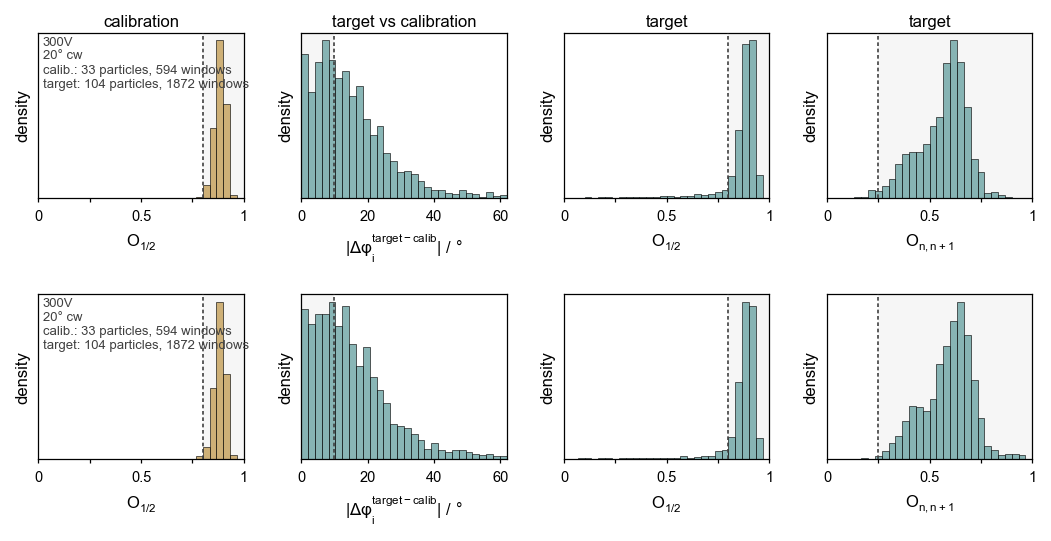

In [32]:

plot_umbrella_qc_histograms_from_measurements(
    m_list,
    C=CK_colors,
    fig_width_mm=180,
    row_height_mm=42,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d_comparison_different_umbrella_measurements",
    stator_variant=stator_variant,
    threshold_delta_deg=10.0,
    threshold_half_overlap=0.80,
    threshold_neighbor_overlap=0.25,
    density=True,
)

## SI | Calibration rotor metrics

#### i. Plot examples of calibration rotor metrics during umbrella sampling

In [33]:
def plot_calibration_bias_metric_convergence_heatmaps(
    m_list,
    durations_s=(1, 2, 3, 4, 5),
    example_window_deg=None,
    example_particles=None,
    example_xlim_deg=55,
    fig_width_mm=180,
    row_height_mm=62,
    save_dir=None,
    save_prefix="SI_calibration_bias_metric_convergence_heatmaps",
    stator_variant=None,
    C=CK_colors,
):
    """
    Per-UMB calibration-bias convergence diagnostic.

    For each UMB measurement, show:
        1) three exemplary calibration-rotor distributions
        2) median absolute center error
        3) median angular stiffness
        4) median neighboring-window overlap

    Example distributions use 1, 2, 3, 4, and 5 s.
    Only the 5 s distribution receives a dashed Gaussian approximation.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap, Normalize

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    min_locs_per_window = 20
    overlap_bins = 72
    density_bins_internal = 96
    dpi = 300

    C = C() if callable(C) else dict(C)
    black = C["black"]
    lightgrey = C["lightgrey"]
    warmgold = C["warmgold"]
    beige = C["beige"]

    def mm(x):
        return float(x) / 25.4

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)
        ax.tick_params(length=2.0, width=0.6, labelsize=labelsize, color=black, labelcolor=black, pad=1.4)
        ax.xaxis.label.set_color(black)
        ax.yaxis.label.set_color(black)
        ax.title.set_color(black)
        ax.grid(False)

    def add_row_panel_labels(fig, axes, labels, y_offset=0.012):
        y = max(ax.get_position().y1 for ax in axes) + float(y_offset)
        for ax, label in zip(axes, labels):
            fig.text(
                ax.get_position().x0,
                y,
                str(label),
                ha="left",
                va="bottom",
                fontsize=10,
                fontweight="bold",
                fontfamily="Arial",
                color=black,
            )

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for x in obj:
                out.extend(flatten(x))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown"

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        if "DIFF" in name and "UMB" not in name:
            return False
        if "UMB" in name:
            return True
        if hasattr(m, "protocol") and isinstance(m.protocol, dict):
            return any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)
        return False

    def protocol_bounds(value):
        while isinstance(value, (tuple, list)) and len(value) == 1 and isinstance(value[0], (tuple, list, dict)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def iter_deg_windows(m):
        out = []

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return out

        for key, val in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1].split("_")[0]) % 360.0
                t0, t1 = protocol_bounds(val)
                phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
                out.append((str(key), float(deg), phi0, float(t0), float(t1)))
            except Exception:
                continue

        out.sort(key=lambda x: x[1])
        return out

    def prepare_locs(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError(f"{measurement_name(m)} has no m.locs.")

        locs = m.locs.copy()

        if particle_col not in locs.columns:
            if "group_int" in locs.columns:
                locs[particle_col] = locs["group_int"].astype(int)
            else:
                raise KeyError(f"{measurement_name(m)} needs 'group' or 'group_int'.")

        if "t" not in locs.columns:
            if "averagetime" in locs.columns:
                locs["t"] = locs["averagetime"].astype(float)
            elif "time" in locs.columns:
                locs["t"] = locs["time"].astype(float)
            elif "time_s" in locs.columns:
                locs["t"] = locs["time_s"].astype(float)
            elif "frame" in locs.columns and hasattr(m, "_average_tpf"):
                locs["t"] = locs["frame"].astype(float) * float(m._average_tpf)
            elif "frame" in locs.columns:
                locs["t"] = locs["frame"].astype(float) * 0.005
            else:
                raise KeyError(f"{measurement_name(m)} needs t, averagetime, time, time_s, or frame.")

        if phi_col not in locs.columns:
            raise KeyError(f"{measurement_name(m)} needs phi column {phi_col!r}.")

        locs = locs[[particle_col, phi_col, "t"]].dropna().copy()
        locs[particle_col] = locs[particle_col].astype(int)
        locs = locs.sort_values([particle_col, "t"])

        return locs

    def as_int_list(x):
        if x is None or isinstance(x, (str, bytes)):
            return []

        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def get_calibration_particles(m):
        vals = as_int_list(getattr(m, "calibration_rotors", None))

        if len(vals) == 0:
            raise ValueError(
                f"{measurement_name(m)}: no calibration rotors found. "
                "Expected m.calibration_rotors."
            )

        return sorted(set(vals))

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def circ_resultant(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        return float(np.abs(np.mean(np.exp(1j * phi))))

    def circ_std(phi):
        R = circ_resultant(phi)

        if not np.isfinite(R) or R <= 0:
            return np.nan

        return float(np.sqrt(max(0.0, -2.0 * np.log(R))))

    def overlap_coefficient(a, b, bins):
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if a.size < 5 or b.size < 5:
            return np.nan

        ha, edges = np.histogram(a, bins=bins, density=True)
        hb, _ = np.histogram(b, bins=bins, density=True)
        dx = float(edges[1] - edges[0])

        return float(np.sum(np.minimum(ha, hb)) * dx)

    def hist_density(vals, bins):
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]

        centers = 0.5 * (bins[:-1] + bins[1:])

        if vals.size < 3:
            return centers, np.full_like(centers, np.nan, dtype=float)

        h, edges = np.histogram(vals, bins=bins, density=True)
        centers = 0.5 * (edges[:-1] + edges[1:])

        return centers, h

    def gaussian_pdf(x, mu, sigma):
        x = np.asarray(x, dtype=float)

        if not np.isfinite(mu) or not np.isfinite(sigma) or sigma <= 0:
            return np.full_like(x, np.nan, dtype=float)

        return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (np.sqrt(2.0 * np.pi) * sigma)

    def get_actual_limits(arr, qlo=2, qhi=98, pad_frac=0.14, min_pad=1e-6):
        arr = np.asarray(arr, dtype=float)
        finite = arr[np.isfinite(arr)]

        if finite.size == 0:
            return 0.0, 1.0

        vmin = float(np.nanpercentile(finite, qlo))
        vmax = float(np.nanpercentile(finite, qhi))

        if not np.isfinite(vmin) or not np.isfinite(vmax):
            vmin = float(np.nanmin(finite))
            vmax = float(np.nanmax(finite))

        if vmax < vmin:
            vmin, vmax = vmax, vmin

        if np.isclose(vmax, vmin):
            pad = max(abs(vmin) * pad_frac, min_pad)
            return vmin - pad, vmax + pad

        pad = max((vmax - vmin) * pad_frac, min_pad)
        return vmin - pad, vmax + pad

    dur_sorted = sorted(float(d) for d in durations_s)
    dur_plot = [d for d in dur_sorted if np.isclose(d, round(d)) and 1 <= int(round(d)) <= 5]

    if len(dur_plot) == 0:
        dur_plot = dur_sorted

    dur_plot = [float(d) for d in dur_plot]
    fit_duration = 5.0 if any(np.isclose(d, 5.0) for d in dur_plot) else float(max(dur_plot))

    duration_cmap = LinearSegmentedColormap.from_list(
        "duration_cmap",
        [
            (0.995, 0.985, 0.945),
            tuple(beige[:3]),
            tuple(warmgold[:3]),
            (0.55, 0.32, 0.06),
        ],
        N=256,
    )

    duration_norm = Normalize(vmin=float(min(dur_plot)), vmax=float(max(dur_plot)))
    duration_colors = {float(d): duration_cmap(duration_norm(float(d))) for d in dur_plot}

    m_flat = flatten(m_list)
    m_umbs = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(m_umbs) == 0:
        raise ValueError("No UMB-like measurements found.")

    all_rows = []
    all_overlap_rows = []
    example_density_rows = []
    example_fit_rows = []
    measurement_meta = []

    bins_density = np.linspace(-np.pi, np.pi, density_bins_internal + 1)
    bins_overlap = np.linspace(-np.pi, np.pi, overlap_bins + 1)

    for umb_order, (mi, m) in enumerate(m_umbs):
        name = measurement_name(m, mi)
        windows = iter_deg_windows(m)

        if len(windows) == 0:
            continue

        cal_particles = get_calibration_particles(m)
        locs = prepare_locs(m)
        locs = locs[locs[particle_col].isin(cal_particles)].copy()

        if len(locs) == 0:
            continue

        this_example_window_deg = (
            float(windows[len(windows) // 4][1])
            if example_window_deg is None
            else float(example_window_deg)
        )

        this_example_window = min(
            windows,
            key=lambda w: abs(float(w[1]) - this_example_window_deg),
        )

        _, this_example_window_deg, _, _, _ = this_example_window
        this_example_window_deg = float(this_example_window_deg)

        if example_particles is None:
            this_example_particles = cal_particles[:3]
        else:
            requested = [int(p) for p in example_particles]
            valid = [p for p in requested if p in set(cal_particles)]
            this_example_particles = valid[:3]

            if len(this_example_particles) < 3:
                remaining = [p for p in cal_particles if p not in set(this_example_particles)]
                this_example_particles += remaining[:3 - len(this_example_particles)]

        if len(this_example_particles) < 3:
            raise ValueError(f"{name}: need at least 3 calibration rotors for the example panels.")

        particle_cache = {}

        for pid, g in locs.groupby(particle_col, sort=False):
            pid = int(pid)
            particle_cache[pid] = {
                "t": g["t"].to_numpy(float),
                "phi": wrap_pi(g[phi_col].to_numpy(float)),
            }

        measurement_meta.append(
            {
                "measurement_index": int(mi),
                "umb_order": int(umb_order),
                "measurement_name": str(name),
                "example_window_deg": float(this_example_window_deg),
                "example_particles": list(this_example_particles),
            }
        )

        for duration_s in dur_plot:
            pooled_abs_by_deg = {}

            for phase, deg, phi0, t0, t1_full in windows:
                t1 = min(float(t1_full), float(t0) + float(duration_s))
                pooled_abs = []

                for pid in cal_particles:
                    pid = int(pid)

                    if pid not in particle_cache:
                        continue

                    t_all = particle_cache[pid]["t"]
                    phi_all = particle_cache[pid]["phi"]

                    i0 = np.searchsorted(t_all, float(t0), side="left")
                    i1 = np.searchsorted(t_all, float(t1), side="left")

                    if i1 <= i0:
                        continue

                    phi = phi_all[i0:i1]
                    n = int(phi.size)

                    if n < min_locs_per_window:
                        continue

                    psi_cmd = wrap_pi(phi - phi0)
                    mu = circ_mean(psi_cmd)

                    center_error_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    psi_centered = wrap_pi(psi_cmd - mu) if np.isfinite(mu) else psi_cmd.copy()

                    var_centered = float(np.nanvar(psi_centered))
                    kappa = (
                        float(1.0 / var_centered)
                        if np.isfinite(var_centered) and var_centered > 1e-12
                        else np.nan
                    )

                    all_rows.append(
                        {
                            "measurement_index": int(mi),
                            "umb_order": int(umb_order),
                            "measurement_name": str(name),
                            "duration_s": float(duration_s),
                            "particle": int(pid),
                            "phase": str(phase),
                            "deg": float(deg),
                            "n_locs": int(n),
                            "abs_center_error_deg": (
                                float(abs(center_error_deg))
                                if np.isfinite(center_error_deg)
                                else np.nan
                            ),
                            "kappa_theta_over_kBT_rad2": float(kappa),
                            "circular_std_rad": float(circ_std(psi_centered)),
                        }
                    )

                    pooled_abs.append(wrap_pi(psi_centered + np.deg2rad(deg)))

                    if (
                        int(pid) in set(this_example_particles)
                        and abs(float(deg) - this_example_window_deg) < 1e-9
                    ):
                        centers, dens = hist_density(psi_cmd, bins_density)

                        for xval, yval in zip(centers, dens):
                            example_density_rows.append(
                                {
                                    "measurement_index": int(mi),
                                    "particle": int(pid),
                                    "duration_s": float(duration_s),
                                    "x_rad": float(xval),
                                    "density": float(yval),
                                }
                            )

                        if np.isclose(float(duration_s), fit_duration):
                            sigma = circ_std(wrap_pi(psi_cmd - mu)) if np.isfinite(mu) else np.nan

                            example_fit_rows.append(
                                {
                                    "measurement_index": int(mi),
                                    "particle": int(pid),
                                    "duration_s": float(duration_s),
                                    "mu_rad": float(mu),
                                    "sigma_rad": float(sigma),
                                }
                            )

                if len(pooled_abs):
                    pooled_abs_by_deg[float(deg)] = np.concatenate(pooled_abs)

            degs = sorted(pooled_abs_by_deg.keys())

            for jj, deg_a in enumerate(degs):
                deg_b = degs[(jj + 1) % len(degs)]

                ov = overlap_coefficient(
                    pooled_abs_by_deg[deg_a],
                    pooled_abs_by_deg[deg_b],
                    bins_overlap,
                )

                all_overlap_rows.append(
                    {
                        "measurement_index": int(mi),
                        "umb_order": int(umb_order),
                        "measurement_name": str(name),
                        "duration_s": float(duration_s),
                        "deg": float(deg_a),
                        "deg_next": float(deg_b),
                        "neighbor_overlap": float(ov),
                    }
                )

    df = pd.DataFrame(all_rows)
    overlap_df = pd.DataFrame(all_overlap_rows)
    example_density_df = pd.DataFrame(example_density_rows)
    example_fit_df = pd.DataFrame(example_fit_rows)
    meta_df = pd.DataFrame(measurement_meta)

    if len(df) == 0:
        raise ValueError("No calibration convergence rows computed.")

    n_umb = len(meta_df)
    fig_height_mm = float(row_height_mm) * float(n_umb)

    heatmap_cmap = LinearSegmentedColormap.from_list(
        "white_to_gold",
        [(1, 1, 1), tuple(warmgold[:3])],
        N=256,
    )

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = fig.add_gridspec(
        n_umb,
        4,
        left=0.05,
        right=0.985,
        bottom=0.04,
        top=0.965,
        wspace=0.45,
        hspace=0.34,
        width_ratios=[1.18, 1.0, 1.0, 1.0],
    )

    def draw_heatmap(
        ax,
        pivot_df,
        ylabel,
        cbar_label,
        panel_title,
        show_ylabels=True,
    ):
        arr = pivot_df.to_numpy(dtype=float)

        if arr.size == 0:
            ax.axis("off")
            return

        vmin, vmax = get_actual_limits(arr, qlo=2, qhi=98, pad_frac=0.14)

        im = ax.imshow(
            arr,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=heatmap_cmap,
            vmin=vmin,
            vmax=vmax,
        )

        ax.set_xticks(np.arange(len(pivot_df.columns)))
        ax.set_xticklabels([f"{int(round(x))}" for x in pivot_df.columns], fontsize=6.5)
        ax.set_xlabel("time / s", fontsize=7)

        yvals = list(pivot_df.index)
        yticks = np.arange(0, len(yvals), 2, dtype=int)
        ax.set_yticks(yticks)

        if show_ylabels:
            ax.set_yticklabels([f"{float(yvals[i]):.0f}" for i in yticks], fontsize=6.5)
            ax.set_ylabel(ylabel, fontsize=7)
        else:
            ax.set_yticklabels([])
            ax.set_ylabel("")

        ax.set_title(panel_title, fontsize=7, pad=4)

        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        cbar.ax.tick_params(labelsize=6, width=0.6, length=2)
        cbar.set_label(cbar_label, fontsize=7)

        style_ax(ax, labelsize=6.5)

    rotor_labels = ["calib. rotor i", "calib. rotor ii", "calib. rotor iii"]
    panel_letters = [chr(ord("a") + i) for i in range(26)]
    letter_idx = 0

    for row_i, meta in meta_df.sort_values("umb_order").reset_index(drop=True).iterrows():
        mi = int(meta["measurement_index"])
        ex_window_deg = float(meta["example_window_deg"])
        ex_particles = list(meta["example_particles"])

        example_gs = outer[row_i, 0].subgridspec(3, 1, hspace=0.10)
        ax_ex_list = [fig.add_subplot(example_gs[k, 0]) for k in range(3)]

        ax_err = fig.add_subplot(outer[row_i, 1])
        ax_kappa = fig.add_subplot(outer[row_i, 2])
        ax_ov = fig.add_subplot(outer[row_i, 3])

        xlim_rad = np.deg2rad(float(example_xlim_deg))
        xfit = np.linspace(-xlim_rad, xlim_rad, 500)

        tick = np.pi / 4

        if example_xlim_deg <= 35:
            tick = np.pi / 6

        if example_xlim_deg <= 25:
            tick = np.pi / 9

        if np.isclose(tick, np.pi / 4):
            ticklabels = [r"$-\pi/4$", r"$0$", r"$\pi/4$"]
        elif np.isclose(tick, np.pi / 6):
            ticklabels = [r"$-\pi/6$", r"$0$", r"$\pi/6$"]
        elif np.isclose(tick, np.pi / 9):
            ticklabels = [r"$-\pi/9$", r"$0$", r"$\pi/9$"]
        else:
            ticklabels = [f"{-tick:.2f}", "0", f"{tick:.2f}"]

        ymax = 0.0
        fit_marker_info = []

        for k, pid in enumerate(ex_particles[:3]):
            ax = ax_ex_list[k]

            subp = example_density_df[
                (example_density_df["measurement_index"].astype(int) == int(mi))
                & (example_density_df["particle"].astype(int) == int(pid))
            ].copy()

            subfit = example_fit_df[
                (example_fit_df["measurement_index"].astype(int) == int(mi))
                & (example_fit_df["particle"].astype(int) == int(pid))
            ].copy()

            for d in dur_plot:
                s = subp[np.isclose(subp["duration_s"].astype(float), float(d))]

                if len(s) == 0:
                    continue

                ax.plot(
                    s["x_rad"],
                    s["density"],
                    color=duration_colors[d],
                    lw=1.0,
                    alpha=0.88,
                )

            sf = subfit[np.isclose(subfit["duration_s"].astype(float), fit_duration)]

            if len(sf):
                mu = float(sf.iloc[0]["mu_rad"])
                sigma = float(sf.iloc[0]["sigma_rad"])

                if np.isfinite(mu) and np.isfinite(sigma) and sigma > 0:
                    ax.plot(
                        xfit,
                        gaussian_pdf(xfit, mu, sigma),
                        color=black,
                        lw=1.15,
                        ls="--",
                        alpha=0.95,
                    )

                    fit_marker_info.append((ax, mu))

            ax.axvline(0, color=lightgrey, lw=0.7, zorder=0)
            ax.set_xlim(-xlim_rad, xlim_rad)
            ax.set_xticks([-tick, 0, tick])

            if k == 2:
                ax.set_xticklabels(ticklabels, fontsize=6.5)
                ax.set_xlabel(r"$\Delta\varphi_i$ / rad", fontsize=7)
            else:
                ax.set_xticklabels([])

            ax.set_yticks([])
            ax.set_ylabel("")

            if k == 0:
                ax.text(
                    0.03,
                    0.95,
                    rf"$\varphi_{{\mathrm{{cmd}}}}={ex_window_deg:.0f}^\circ$",
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=6.2,
                    color=black,
                )

                ax.text(
                    0.03,
                    0.72,
                    rotor_labels[k],
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=6.2,
                    color=black,
                )
            else:
                ax.text(
                    0.03,
                    0.95,
                    rotor_labels[k],
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=6.2,
                    color=black,
                )

            style_ax(ax, labelsize=6)
            ymax = max(ymax, ax.get_ylim()[1])

        for ax in ax_ex_list:
            ax.set_ylim(0, ymax)

        for ax, mu in fit_marker_info:
            ax.plot(
                mu,
                0.045 * ymax,
                marker="v",
                ms=4.5,
                linestyle="none",
                markerfacecolor=black,
                markeredgecolor=black,
                clip_on=False,
                zorder=6,
            )

        cax = ax_ex_list[0].inset_axes([0.86, 0.16, 0.045, 0.68])

        sm = plt.cm.ScalarMappable(norm=duration_norm, cmap=duration_cmap)
        sm.set_array([])

        cbar = fig.colorbar(sm, cax=cax, ticks=dur_plot)
        cbar.ax.tick_params(labelsize=5.5, width=0.6, length=2, pad=1.0)
        cbar.ax.set_yticklabels([f"{int(round(d))}" for d in dur_plot])
        cbar.ax.set_title("time / s", fontsize=5.7, pad=1.5)

        sub_df = df[df["measurement_index"].astype(int) == int(mi)].copy()
        sub_ov_df = overlap_df[overlap_df["measurement_index"].astype(int) == int(mi)].copy()

        err_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
            .agg(value=("abs_center_error_deg", "median"))
        )

        kappa_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
            .agg(value=("kappa_theta_over_kBT_rad2", "median"))
        )

        overlap_heat_df = (
            sub_ov_df.groupby(["deg", "duration_s"], as_index=False)
            .agg(value=("neighbor_overlap", "median"))
        )

        all_degs = sorted(
            set(err_heat_df["deg"].astype(float)).union(
                set(kappa_heat_df["deg"].astype(float))
            )
        )

        all_degs_ov = sorted(set(overlap_heat_df["deg"].astype(float)))

        err_pivot = (
            err_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_plot)
        )

        kappa_pivot = (
            kappa_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_plot)
        )

        overlap_pivot = (
            overlap_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs_ov, columns=dur_plot)
        )

        draw_heatmap(
            ax=ax_err,
            pivot_df=err_pivot,
            ylabel=r"$\varphi_{\mathrm{cmd}}$ / °",
            cbar_label=r"median $|\Delta\varphi_i|$ / °",
            panel_title=r"$|\Delta\varphi_i|$ / °",
            show_ylabels=True,
        )

        draw_heatmap(
            ax=ax_kappa,
            pivot_df=kappa_pivot,
            ylabel="",
            cbar_label=r"median $\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
            panel_title=r"$\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
            show_ylabels=False,
        )

        draw_heatmap(
            ax=ax_ov,
            pivot_df=overlap_pivot,
            ylabel="",
            cbar_label=r"median $O_{i,i+1}$",
            panel_title=r"$O_{i,i+1}$",
            show_ylabels=False,
        )

        row_labels = panel_letters[letter_idx:letter_idx + 4]

        add_row_panel_labels(
            fig,
            [ax_ex_list[0], ax_err, ax_kappa, ax_ov],
            row_labels,
            y_offset=0.010,
        )

        letter_idx += 4

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        out = prefixed_name(save_prefix)

        fig.savefig(
            save_dir / f"{out}.png",
            dpi=dpi,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir / f"{out}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

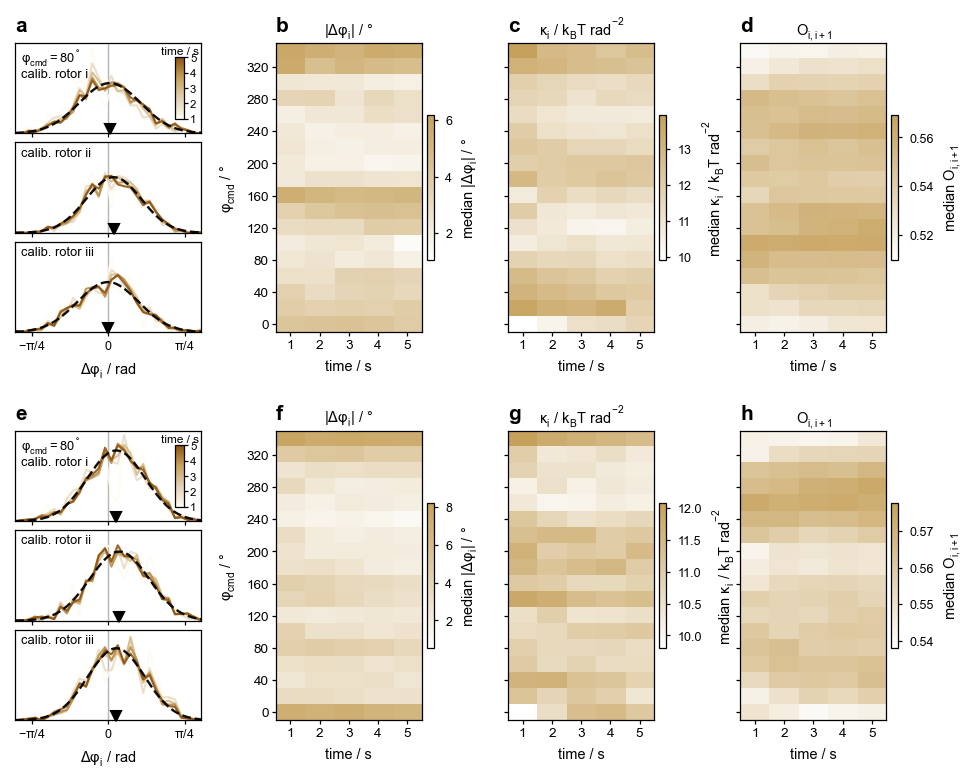

In [34]:
# if full_execution:
plot_calibration_bias_metric_convergence_heatmaps(
    m_list=m_list,
    example_window_deg=80,
    example_particles=None,
    example_xlim_deg=55,
    fig_width_mm=160,
    row_height_mm=62,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2c_calibration_convergence_examples",
    stator_variant=stator_variant,
    C=CK_colors,
)

#### ii. Plot convergence of calibration rotor metrics

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_calibration_metric_convergence(
    m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    min_locs_per_window=20,
    overlap_bins=72,
    replica_labels=("replica 1", "replica 2"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.22,
    panel_label_y=1.05,
    panel_label_fontsize=8,
    fig_width_mm=180,
    fig_height_mm=52,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    save_dir=None,
    save_prefix="calibration_metric_convergence",
    stator_variant=None,
    C=CK_colors,
):
    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    dpi = 300

    C = C() if callable(C) else dict(C)

    def _as_rgb(x):
        arr = np.asarray(x, dtype=float).ravel()[:3]
        return arr / 255.0 if np.nanmax(arr) > 1 else arr

    black = _as_rgb(C.get("black", (0, 0, 0)))
    warmgold = _as_rgb(C.get("warmgold", C.get("gold", (226, 172, 72))))
    beige = _as_rgb(C.get("beige", 0.65 * np.ones(3) + 0.35 * warmgold))

    durations_s = np.asarray(sorted(set(float(d) for d in durations_s)), dtype=float)

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def measurement_name(m, index):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{index}]"

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        if "DIFF" in name and "UMB" not in name:
            return False
        if "UMB" in name:
            return True
        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(isinstance(key, str) and key.startswith("deg-") for key in m.protocol)

    def protocol_bounds(value):
        while isinstance(value, (tuple, list)) and len(value) == 1 and isinstance(value[0], (tuple, list, dict)):
            value = value[0]
        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")
            return float(t0), float(t1)
        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])
        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_windows(m):
        windows = []
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return windows
        for phase, bounds in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue
            try:
                deg = float(phase.split("-")[1].split("_")[0]) % 360
                t0, t1 = protocol_bounds(bounds)
                phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
                windows.append((phase, deg, phi0, t0, t1))
            except Exception:
                continue
        return sorted(windows, key=lambda row: row[1])

    def prepare_locs(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError(f"{getattr(m, 'path', 'measurement')} has no m.locs.")
        locs = m.locs.copy()
        if particle_col not in locs.columns:
            if "group_int" in locs.columns:
                locs[particle_col] = locs["group_int"].astype(int)
            else:
                raise KeyError("m.locs needs 'group' or 'group_int'.")
        if "t" not in locs.columns:
            if "averagetime" in locs.columns:
                locs["t"] = locs["averagetime"].astype(float)
            elif "time" in locs.columns:
                locs["t"] = locs["time"].astype(float)
            elif "time_s" in locs.columns:
                locs["t"] = locs["time_s"].astype(float)
            elif "frame" in locs.columns:
                dt = float(getattr(m, "_average_tpf", getattr(m, "average_tpf", 0.005)))
                locs["t"] = locs["frame"].astype(float) * dt
            else:
                raise KeyError("m.locs needs t, averagetime, time, time_s, or frame.")
        if phi_col not in locs.columns:
            raise KeyError("m.locs needs column 'phi'.")
        locs = locs[[particle_col, phi_col, "t"]].dropna().copy()
        locs[particle_col] = locs[particle_col].astype(int)
        return locs.sort_values([particle_col, "t"], kind="mergesort")

    def calibration_particles(m):
        particles = getattr(m, "calibration_rotors", None)
        if particles is None:
            raise ValueError(f"{getattr(m, 'path', 'measurement')}: m.calibration_rotors is missing.")
        return sorted(set(int(p) for p in particles))

    def overlap_coefficient(a, b):
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)
        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]
        if a.size < 5 or b.size < 5:
            return np.nan
        edges = np.linspace(-np.pi, np.pi, int(overlap_bins) + 1)
        ha, _ = np.histogram(wrap_pi(a), bins=edges, density=True)
        hb, _ = np.histogram(wrap_pi(b), bins=edges, density=True)
        return float(np.sum(np.minimum(ha, hb)) * np.diff(edges)[0])

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)
        ax.tick_params(length=2, width=0.6, labelsize=tick_label_size, color=black, labelcolor=black, pad=1.5)
        ax.grid(False)

    def replica_label(index):
        return str(replica_labels[index]) if index < len(replica_labels) else f"replica {index + 1}"

    m_umbs = [(i, m) for i, m in enumerate(flatten(m_list)) if is_umb(m)]
    if not m_umbs:
        raise ValueError("No UMB measurements found.")

    rows = []

    for umb_order, (measurement_index, m) in enumerate(m_umbs):
        windows = get_windows(m)
        if not windows:
            continue

        particles = calibration_particles(m)
        locs = prepare_locs(m)
        locs = locs[locs[particle_col].isin(particles)].copy()
        if locs.empty:
            continue

        particle_cache = {
            int(pid): {"t": group["t"].to_numpy(float), "phi": wrap_pi(group[phi_col].to_numpy(float))}
            for pid, group in locs.groupby(particle_col, sort=False)
        }

        for duration_s in durations_s:
            center_errors = []
            kappas = []
            half_overlaps = []
            pooled_by_deg = {}

            for phase, deg, phi0, t0, t1_full in windows:
                t1 = min(float(t1_full), float(t0) + float(duration_s))
                pooled_window = []

                for particle in particles:
                    if particle not in particle_cache:
                        continue

                    t = particle_cache[particle]["t"]
                    phi = particle_cache[particle]["phi"]
                    i0 = np.searchsorted(t, float(t0), side="left")
                    i1 = np.searchsorted(t, float(t1), side="left")
                    phi_window = phi[i0:i1]

                    if phi_window.size < int(min_locs_per_window):
                        continue

                    psi_cmd = wrap_pi(phi_window - phi0)
                    mu = circular_mean(psi_cmd)
                    if not np.isfinite(mu):
                        continue

                    center_errors.append(abs(float(np.rad2deg(mu))))

                    psi_centered = wrap_pi(psi_cmd - mu)
                    variance = float(np.nanvar(psi_centered))
                    kappa = 1.0 / variance if np.isfinite(variance) and variance > 1e-12 else np.nan
                    if np.isfinite(kappa):
                        kappas.append(kappa)

                    half = psi_centered.size // 2
                    if half >= 5 and psi_centered.size - half >= 5:
                        half_overlap = overlap_coefficient(psi_centered[:half], psi_centered[half:])
                        if np.isfinite(half_overlap):
                            half_overlaps.append(half_overlap)

                    pooled_window.append(wrap_pi(psi_centered + np.deg2rad(deg)))

                if pooled_window:
                    pooled_by_deg[float(deg)] = np.concatenate(pooled_window)

            neighbor_overlaps = []
            available_degs = sorted(pooled_by_deg)

            if len(available_degs) >= 2:
                for j, deg_a in enumerate(available_degs):
                    deg_b = available_degs[(j + 1) % len(available_degs)]
                    overlap = overlap_coefficient(pooled_by_deg[deg_a], pooled_by_deg[deg_b])
                    if np.isfinite(overlap):
                        neighbor_overlaps.append(overlap)

            for metric, values in (
                ("center_error", center_errors),
                ("kappa", kappas),
                ("half_overlap", half_overlaps),
                ("neighbor_overlap", neighbor_overlaps),
            ):
                values = np.asarray(values, dtype=float)
                values = values[np.isfinite(values)]
                if values.size == 0:
                    continue
                rows.append({
                    "measurement_index": int(measurement_index),
                    "umb_order": int(umb_order),
                    "measurement_name": measurement_name(m, measurement_index),
                    "metric": metric,
                    "duration_s": float(duration_s),
                    "mean": float(np.mean(values)),
                    "std": float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
                    "n": int(values.size),
                })

    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("No calibration convergence metrics could be calculated.")

    umb_orders = sorted(df["umb_order"].unique())
    fractions = np.linspace(0.22, 1.00, max(len(umb_orders), 1))
    umb_colors = {umb_order: tuple((1 - frac) * beige + frac * warmgold) for umb_order, frac in zip(umb_orders, fractions)}
    replica_markers = ("o", "s", "^", "D", "v", "P")
    replica_linestyles = ("-", "--", "-.", ":", (0, (3, 1, 1, 1)), (0, (5, 2)))

    metric_settings = [
        ("center_error", r"$|\Delta \varphi_i|$ / °", None),
        ("kappa", r"$\langle \kappa_i \rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$", None),
        ("half_overlap", r"$\langle O_{1/2} \rangle$", (0, 1.03)),
        ("neighbor_overlap", r"$\langle O_{i,i+1} \rangle$", (0, 1.03)),
    ]

    fig, axes = plt.subplots(1, 4, figsize=(mm(fig_width_mm), mm(fig_height_mm)))
    legend_handles = []

    for ax_index, (ax, (metric, ylabel, fixed_ylim)) in enumerate(zip(axes, metric_settings)):
        sub = df[df["metric"] == metric].copy()

        for index, umb_order in enumerate(umb_orders):
            group = sub[sub["umb_order"].astype(int) == int(umb_order)].sort_values("duration_s")
            if group.empty:
                print(f"No {metric} values for {replica_label(index)} (UMB order {umb_order}).")
                continue

            color = umb_colors[int(umb_order)]
            x = group["duration_s"].to_numpy(float)
            mean = group["mean"].to_numpy(float)
            std = group["std"].to_numpy(float)
            lower = mean - std
            upper = mean + std

            if metric in {"half_overlap", "neighbor_overlap"}:
                lower = np.clip(lower, 0, 1)
                upper = np.clip(upper, 0, 1)

            ax.fill_between(x, lower, upper, color=color, alpha=0.12, linewidth=0, zorder=1 + index)

            line, = ax.plot(
                x,
                mean,
                marker=replica_markers[index % len(replica_markers)],
                ms=3.2,
                markerfacecolor=color,
                markeredgecolor=black,
                markeredgewidth=0.45,
                linestyle=replica_linestyles[index % len(replica_linestyles)],
                lw=1.05,
                color=color,
                alpha=0.98,
                zorder=5 + index,
                label=replica_label(index),
            )

            if metric == "center_error":
                legend_handles.append(line)

        ax.set_xlabel("time / s", fontsize=axis_label_size)
        ax.set_ylabel(ylabel, fontsize=axis_label_size)
        ax.set_xlim(0.85, 5.15)
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.set_xticklabels(["1", "2", "3", "4", "5"])
        # if fixed_ylim is not None:
        #     ax.set_ylim(*fixed_ylim)
        style_axis(ax)

        if ax_index < len(panel_labels):
            ax.text(
                panel_label_x,
                panel_label_y,
                str(panel_labels[ax_index]),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=panel_label_fontsize,
                fontname="Arial",
                fontweight="bold",
                color=black,
            )

    axes[0].legend(
        handles=legend_handles,
        labels=[h.get_label() for h in legend_handles],
        loc="upper right",
        frameon=False,
        fontsize=annotation_size,
        handlelength=1.8,
        borderaxespad=0.2,
    )

    print("\nReplica summary:")
    for index, umb_order in enumerate(umb_orders):
        name = df.loc[df["umb_order"].astype(int) == int(umb_order), "measurement_name"].iloc[0]
        print(f"{replica_label(index)} | UMB order {umb_order} | {name}")

    print("\nO_1/2 convergence data:")
    half_df = df[df["metric"] == "half_overlap"].copy()
    for index, umb_order in enumerate(umb_orders):
        group = half_df[half_df["umb_order"].astype(int) == int(umb_order)].sort_values("duration_s")
        if group.empty:
            print(f"{replica_label(index)}: no O_1/2 data")
        else:
            print(f"{replica_label(index)}: mean O_1/2 = {np.round(group['mean'].to_numpy(float), 4)}")

    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.20, top=0.97, wspace=0.48)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        out = prefixed_name(save_prefix)
        fig.savefig(save_dir / f"{out}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{out}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\matplotlib\lines.py:1204: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  neq = current != val
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\matplotlib\lines.py:1204: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  neq = current != val
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\matplotlib\lines.py:1204: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  neq = current != val
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\matplotlib\lines.py:1204: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  neq = current != val
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\matplotlib\axis.py:1


Replica summary:
replica 1 | UMB order 0 | 260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5
replica 2 | UMB order 1 | 260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked.hdf5

O_1/2 convergence data:
replica 1: mean O_1/2 = [0.7528 0.7969 0.8213 0.8357 0.8515 0.862  0.8709 0.8775 0.8811]
replica 2: mean O_1/2 = [0.751  0.7938 0.8195 0.8362 0.8497 0.8608 0.8694 0.8762 0.8821]


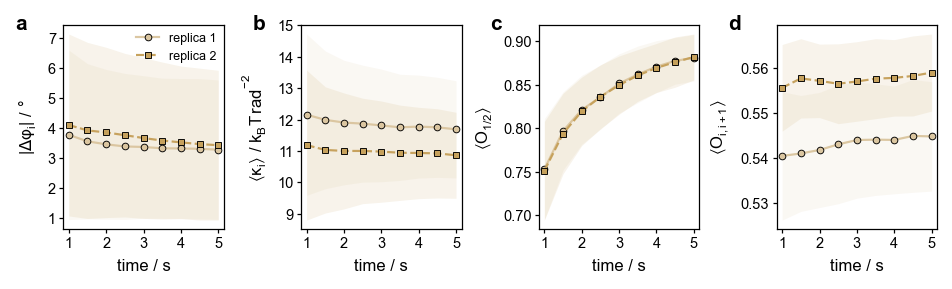

In [36]:
plot_calibration_metric_convergence(
    m_list=m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    min_locs_per_window=20,
    overlap_bins=72,
    replica_labels=("replica 1", "replica 2"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.3,
    panel_label_y=1.05,
    panel_label_fontsize=10,
    fig_width_mm=160,
    fig_height_mm=45,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2c_calibration_convergence_stats",
    stator_variant=stator_variant,
    C=CK_colors,
)

## Reconstruction based on reliable calibration rotors via MBAR

#### i. MBAR based reconstruction for all target rotors

In [37]:
def run_MBAR_reconstruction(
    m_list,
    nbins=72,
    kappa_mode='by_angle',
    bias_potential='cosine',
    center_mode='ensemble',
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388/1.14,
    pmin_nan=1e-12,
    min_keep=200,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-07,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Lean MBAR reconstruction using the calibration already stored by
    filter_calibration_rotors(...).

    Reads
    -----
    m.calibration_rotors
    m.target_rotors
    m.kappa_calibration_by_window
    m.autocorrelation_trim_s
    m.locs
    m.protocol

    Uses from m.kappa_calibration_by_window
    ---------------------------------------
    kappa:
        stored per-calibration-rotor/per-window kappa estimate

    mu_fit:
        stored fitted center in the original m.locs angular coordinate;
        used to calculate the ensemble umbrella center

    The calibration trajectories are therefore not reprocessed to estimate
    kappa or umbrella centers.

    Reconstructs
    ------------
    All rotors in:
        m.calibration_rotors
        m.target_rotors

    Kappa scaling
    -------------
    calibration rotor:
        stored calibrated kappa * kappa_rescale_calibration

    target rotor:
        stored calibrated kappa * kappa_rescale_target

    Stores
    ------
    m.reconstructed_energy_landscapes_by_center
    m.reconstructed_energy_landscapes_by_bias
    m.reconstructed_energy_landscapes

    m.energy_landscapes
    m.energy_landscapes_meta

    m.kappa_bias
    m.center_bias

    Notes
    -----
    - Progress bars are always shown.
    - Nothing is returned.
    - No summary/status DataFrame is generated.
    - MBAR is unbinned internally.
    - nbins controls only the final angular representation.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    particle_col = 'group'
    phi0_offset_rad = -np.pi / 2
    edges_cache = {}

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(values):
        if values is None:
            return []
        if isinstance(values, (str, bytes)):
            return []
        try:
            return sorted(set((int(v) for v in list(values))))
        except Exception:
            try:
                return [int(values)]
            except Exception:
                return []

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f'm_list[{index}]' if index is not None else 'unknown measurement'

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)
        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])
        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))
        if axis is not None:
            out = np.squeeze(out, axis=axis)
        return out

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan
        return float(np.angle(z))

    def circular_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def circular_rolling_nanmean(values, window):
        values = np.asarray(values, dtype=float)
        if values.size == 0:
            return values.copy()
        window = int(window)
        if window <= 1:
            return values.copy()
        if window % 2 == 0:
            window += 1
        half = window // 2
        out = np.full(values.size, np.nan, dtype=float)
        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]
            if local.size:
                out[i] = float(np.mean(local))
        return out

    def bias_names(value):
        value = str(value).lower()
        if value == 'cosine':
            return ['cosine']
        if value == 'harmonic':
            return ['harmonic']
        if value == 'both':
            return ['harmonic', 'cosine']
        raise ValueError("bias_potential must be 'cosine', 'harmonic', or 'both'.")

    def center_names(value):
        value = str(value).lower()
        if value == 'command':
            return ['command']
        if value == 'ensemble':
            return ['ensemble']
        if value == 'both':
            return ['command', 'ensemble']
        raise ValueError("center_mode must be 'command', 'ensemble', or 'both'.")

    def has_deg_protocol(m):
        return (
            hasattr(m, 'protocol')
            and isinstance(m.protocol, dict)
            and any((isinstance(key, str) and key.startswith('deg-') for key in m.protocol))
        )

    def is_umb(m):
        name = str(getattr(m, 'path', '')).upper()
        if 'DIFF' in name:
            return False
        if 'UMB' in name:
            return True
        return has_deg_protocol(m)

    def ensure_time_column(m):
        if not hasattr(m, 'locs') or m.locs is None:
            raise ValueError('m.locs is missing.')
        if 't' in m.locs.columns:
            return
        m.locs = m.locs.copy()
        if 'averagetime' in m.locs.columns:
            m.locs['t'] = m.locs['averagetime'].astype(float)
            return
        if 'time' in m.locs.columns:
            m.locs['t'] = m.locs['time'].astype(float)
            return
        if 'time_s' in m.locs.columns:
            m.locs['t'] = m.locs['time_s'].astype(float)
            return
        if 'frame' not in m.locs.columns:
            raise ValueError("m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'.")
        dt = float(getattr(m, '_average_tpf', 0.005))
        m.locs['t'] = m.locs['frame'].astype(float) * dt

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]
        if isinstance(value, dict):
            start = value.get('start', value.get('start_time', value.get('t_start', value.get('t0', None))))
            stop = value.get(
                'end', value.get('end_time', value.get('t_end', value.get('t1', value.get('stop', None))))
            )
            if start is None or stop is None:
                raise ValueError(f'Cannot parse protocol bounds from {value}.')
            return (float(start), float(stop))
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return (float(value[0]), float(value[1]))
        raise ValueError(f'Cannot parse protocol bounds from {value}.')

    def phase_deg(phase):
        return float(str(phase).split('-')[1].split('_')[0])

    def protocol_windows(m):
        if not has_deg_protocol(m):
            raise ValueError('No deg-* windows found in m.protocol.')
        rows = []
        for phase, bounds in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith('deg-'):
                continue
            try:
                deg = phase_deg(phase)
                start, stop = protocol_bounds(bounds)
            except Exception:
                continue
            command_phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
            rows.append(
                {
                    'phase': str(phase),
                    'deg': float(deg),
                    'command_phi0': command_phi0,
                    'start': float(start),
                    'stop': float(stop),
                }
            )
        if len(rows) == 0:
            raise ValueError('No valid deg-* windows could be parsed.')
        return pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)

    def get_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column
        raise KeyError(
            f'Could not find any of these columns: {candidates}\nAvailable columns:\n{list(df.columns)}'
        )

    def build_stored_calibration(m, calibration_rotors):
        stored = getattr(m, 'kappa_calibration_by_window', None)
        if not isinstance(stored, pd.DataFrame) or len(stored) == 0:
            raise ValueError(
                'm.kappa_calibration_by_window is missing or empty. Run filter_calibration_rotors(...) first.'
            )
        df = stored.copy()
        particle_col_stored = get_column(df, ['particle'])
        phase_col = get_column(df, ['phase'])
        kappa_col = get_column(df, ['kappa', 'kappa_vm', 'kappa_theta_over_kBT_rad2'])
        raw_center_col = get_column(df, ['mu_fit', 'mu_fit_rad'])
        calibration_set = set(map(int, calibration_rotors))
        df = df[df[particle_col_stored].astype(int).isin(calibration_set)].copy()
        if len(df) == 0:
            raise ValueError('None of m.calibration_rotors are present in m.kappa_calibration_by_window.')
        protocol_df = protocol_windows(m)
        rows = []
        for protocol_row in protocol_df.itertuples():
            phase = str(protocol_row.phase)
            g = df[df[phase_col].astype(str) == phase].copy()
            kappa = g[kappa_col].to_numpy(float)
            kappa = kappa[np.isfinite(kappa) & (kappa > 0)]
            fitted_centers = g[raw_center_col].to_numpy(float)
            fitted_centers = fitted_centers[np.isfinite(fitted_centers)]
            if kappa.size:
                kappa_mean = float(np.mean(kappa))
                kappa_std = float(np.std(kappa, ddof=1)) if kappa.size > 1 else np.nan
            else:
                kappa_mean = np.nan
                kappa_std = np.nan
            ensemble_phi0 = circular_mean(fitted_centers)
            if not np.isfinite(ensemble_phi0):
                ensemble_phi0 = float(protocol_row.command_phi0)
            delta = float(wrap_pi(ensemble_phi0 - protocol_row.command_phi0))
            rows.append(
                {
                    'phase': phase,
                    'deg': float(protocol_row.deg),
                    'command_phi0': float(protocol_row.command_phi0),
                    'command_phi0_deg': float(np.rad2deg(protocol_row.command_phi0)),
                    'ensemble_phi0': float(wrap_pi(ensemble_phi0)),
                    'ensemble_phi0_deg': float(np.rad2deg(wrap_pi(ensemble_phi0))),
                    'delta_ensemble_minus_command': delta,
                    'delta_ensemble_minus_command_deg': float(np.rad2deg(delta)),
                    'center_circstd': circular_std(fitted_centers),
                    'n_calibration_rotors': int(fitted_centers.size),
                    'kappa_mean_raw': kappa_mean,
                    'kappa_std_raw': kappa_std,
                }
            )
        calibration = pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)
        rolling = circular_rolling_nanmean(
            calibration['kappa_mean_raw'].to_numpy(float), rolling_mean_kappa_window
        )
        calibration['kappa_mean_rolling_raw'] = rolling
        if rolling_mean_kappa_ensemble:
            calibration['kappa_mean_used_raw'] = rolling
            kappa_source = f'rolling_mean_{int(rolling_mean_kappa_window)}'
        else:
            calibration['kappa_mean_used_raw'] = calibration['kappa_mean_raw']
            kappa_source = 'per_window_mean'
        used = calibration['kappa_mean_used_raw'].to_numpy(float)
        finite = np.isfinite(used) & (used > 0)
        if not np.any(finite):
            raise ValueError('No finite stored kappa values are available.')
        global_raw = float(np.mean(used[finite]))
        return (calibration, global_raw, kappa_source)

    def get_rotor_classes(m):
        calibration_rotors = as_int_list(getattr(m, 'calibration_rotors', None))
        target_rotors = as_int_list(getattr(m, 'target_rotors', None))
        overlap = sorted(set(calibration_rotors) & set(target_rotors))
        if overlap:
            raise ValueError(f'Rotors cannot be both calibration and target: {overlap}')
        rotor_class = {int(particle): 'calibration' for particle in calibration_rotors}
        rotor_class.update({int(particle): 'target' for particle in target_rotors})
        reconstruction_rotors = sorted(rotor_class)
        return (calibration_rotors, target_rotors, reconstruction_rotors, rotor_class)

    def lag1_corr(values):
        values = np.asarray(values, dtype=float)
        if values.size < 3:
            return 0.0
        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30
        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1_corr(np.cos(phi)) + lag1_corr(np.sin(phi)))
        return float(np.clip(rho, -0.99, 0.99))

    def collect_rotor_windows(m, particle):
        ensure_time_column(m)
        if 'phi' not in m.locs.columns:
            raise KeyError("m.locs needs 'phi'.")
        if particle_col not in m.locs.columns:
            raise KeyError(f'm.locs needs {particle_col!r}.')
        trim_s = float(getattr(m, 'autocorrelation_trim_s', np.nan))
        if not np.isfinite(trim_s) or trim_s < 0:
            raise ValueError('m.autocorrelation_trim_s is missing or invalid.')
        dt = float(getattr(m, '_average_tpf', 0.005))
        data = m.locs.loc[
            m.locs[particle_col].astype(int) == int(particle), [particle_col, 'phi', 't']
        ].copy()
        if len(data) == 0:
            raise ValueError(f'Particle {particle}: no localizations.')
        data = data.sort_values('t', kind='mergesort')
        data['phi'] = wrap_pi(data['phi'].to_numpy(float))
        n_trim = max(5, int(np.ceil(trim_s / dt)))
        samples = []
        phases = []
        command_centers = []
        for row in protocol_windows(m).itertuples():
            select = (data['t'] >= float(row.start)) & (data['t'] < float(row.stop))
            phi = data.loc[select, 'phi'].to_numpy(float)
            if phi.size < min_keep:
                continue
            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
            if phi.size < min_keep:
                continue
            rho = circular_lag1(phi)
            denominator = 1.0 + rho
            if denominator > 1e-12:
                ess = phi.size * (1.0 - rho) / denominator
            else:
                ess = float(phi.size)
            if ess < 10:
                continue
            samples.append(wrap_pi(phi))
            phases.append(str(row.phase))
            command_centers.append(float(row.command_phi0))
        if len(samples) < 3:
            raise ValueError(f'Particle {particle}: fewer than three valid umbrella windows.')
        return {
            'samples': samples,
            'phases': phases,
            'command_centers': np.asarray(command_centers, dtype=float),
        }

    def values_for_phases(phases, calibration, column):
        phase_to_value = {str(row.phase): float(getattr(row, column)) for row in calibration.itertuples()}
        out = np.asarray([phase_to_value.get(str(phase), np.nan) for phase in phases], dtype=float)
        return out

    def get_edges_centers():
        if nbins in edges_cache:
            return edges_cache[nbins]
        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])
        edges_cache[nbins] = (edges, centers, dphi)
        return (edges, centers, dphi)

    def bias_energy(phi, centers, kappa, model):
        phi = np.asarray(phi, dtype=float)
        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)
        if kappa.ndim == 0:
            kappa = np.full(centers.size, float(kappa))
        delta = wrap_pi(phi[None, :] - centers[:, None])
        if model == 'cosine':
            return kappa[:, None] * (1.0 - np.cos(delta))
        if model == 'harmonic':
            return 0.5 * kappa[:, None] * delta**2
        raise ValueError('Unknown bias model.')

    def run_mbar(samples, centers, kappa, model):
        N_k = np.asarray([len(sample) for sample in samples], dtype=float)
        all_phi = wrap_pi(np.concatenate(samples))
        u_kn = bias_energy(all_phi, centers, kappa, model)
        log_N_k = np.log(N_k)
        f_k = np.zeros(len(samples), dtype=float)
        converged = False
        max_delta = np.nan
        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
            f_new = np.empty_like(f_k)
            for i in range(len(samples)):
                f_new[i] = -logsumexp(-u_kn[i] - log_denominator)
            f_new -= f_new[0]
            f_next = (1.0 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new
            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next
            if max_delta < float(mbar_tol):
                converged = True
                break
        log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)
        weights = np.exp(log_weights)
        edges, bin_centers, dphi = get_edges_centers()
        weighted_counts, _ = np.histogram(all_phi, bins=edges, weights=weights)
        probability = weighted_counts / dphi
        normalization = np.sum(probability) * dphi
        if normalization > 0:
            probability /= normalization
        energy = np.full(probability.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        energy = zero_min(energy)
        weight_square_sum = float(np.sum(weights**2))
        ess = 1.0 / weight_square_sum if weight_square_sum > 0 else np.nan
        return {
            'phi': bin_centers,
            'P': probability,
            'U': energy,
            'converged': bool(converged),
            'n_iter': int(iteration + 1),
            'max_delta': float(max_delta),
            'ess': float(ess),
        }

    def pooled_landscape(samples):
        edges, centers, dphi = get_edges_centers()
        phi = wrap_pi(np.concatenate(samples))
        counts, _ = np.histogram(phi, bins=edges)
        probability = counts.astype(float) / (counts.sum() * dphi)
        energy = np.full(centers.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        return (probability, zero_min(energy))

    def reconstruct_measurement(m, calibration_rotors, target_rotors, reconstruction_rotors, rotor_class):
        calibration, global_kappa_raw, kappa_source = build_stored_calibration(m, calibration_rotors)
        local_bias_names = bias_names(bias_potential)
        local_center_names = center_names(center_mode)
        primary_bias = 'cosine' if 'cosine' in local_bias_names else local_bias_names[0]
        primary_center = 'ensemble' if 'ensemble' in local_center_names else local_center_names[0]
        result = {
            center_name: {bias_name: {} for bias_name in local_bias_names}
            for center_name in local_center_names
        }
        diagnostics = {}
        for particle in tqdm(reconstruction_rotors, desc='MBAR rotors', leave=False):
            try:
                data = collect_rotor_windows(m, particle)
            except Exception:
                continue
            this_class = rotor_class[int(particle)]
            scale = (
                float(kappa_rescale_target) if this_class == 'target' else float(kappa_rescale_calibration)
            )
            if kappa_mode == 'global':
                kappa = np.full(len(data['phases']), global_kappa_raw * scale, dtype=float)
            elif kappa_mode == 'by_angle':
                kappa = values_for_phases(data['phases'], calibration, 'kappa_mean_used_raw') * scale
                missing = ~np.isfinite(kappa) | (kappa <= 0)
                kappa[missing] = global_kappa_raw * scale
            else:
                raise ValueError("kappa_mode must be 'global' or 'by_angle'.")
            centers = {}
            if 'command' in local_center_names:
                centers['command'] = data['command_centers']
            if 'ensemble' in local_center_names:
                centers['ensemble'] = values_for_phases(data['phases'], calibration, 'ensemble_phi0')
            pooled_P, pooled_U = pooled_landscape(data['samples'])
            for center_name in local_center_names:
                for bias_name in local_bias_names:
                    mbar = run_mbar(
                        samples=data['samples'], centers=centers[center_name], kappa=kappa, model=bias_name
                    )
                    result[center_name][bias_name][int(particle)] = pd.DataFrame(
                        {
                            'phi': mbar['phi'],
                            'P_mbar': mbar['P'],
                            'U_mbar': mbar['U'],
                            'P_wham': mbar['P'],
                            'U_wham': mbar['U'],
                            'P_pooled': pooled_P,
                            'U_naive': pooled_U,
                        }
                    )
                    if center_name == primary_center and bias_name == primary_bias:
                        diagnostics[int(particle)] = {
                            'rotor_class': this_class,
                            'kappa_rescale_applied': scale,
                            'mbar_converged': bool(mbar['converged']),
                            'mbar_n_iter': int(mbar['n_iter']),
                            'mbar_ess_unbiased': float(mbar['ess']),
                        }
        primary_landscapes = result[primary_center][primary_bias]
        energy_landscapes = {}
        for particle, table in primary_landscapes.items():
            diagnostic = diagnostics[int(particle)]
            energy_landscapes[int(particle)] = {
                'centers': table['phi'].to_numpy(copy=False),
                'E': table['U_mbar'].to_numpy(copy=False),
                'rotor_class': diagnostic['rotor_class'],
                'kappa_rescale_applied': diagnostic['kappa_rescale_applied'],
                'mbar_converged': diagnostic['mbar_converged'],
                'mbar_n_iter': diagnostic['mbar_n_iter'],
                'mbar_ess_unbiased': diagnostic['mbar_ess_unbiased'],
            }
        m.reconstructed_energy_landscapes_by_center = result
        m.reconstructed_energy_landscapes_by_bias = result[primary_center]
        m.reconstructed_energy_landscapes = primary_landscapes
        m.energy_landscapes = energy_landscapes
        m.center_bias = {
            'mode': str(center_mode),
            'primary_center': primary_center,
            'by_window': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'ensemble_phi0',
                    'ensemble_phi0_deg',
                    'delta_ensemble_minus_command',
                    'delta_ensemble_minus_command_deg',
                    'center_circstd',
                    'n_calibration_rotors',
                ]
            ].copy(),
        }
        m.kappa_bias = {
            'mode': str(kappa_mode),
            'source': 'm.kappa_calibration_by_window',
            'kappa_source': kappa_source,
            'global_raw': float(global_kappa_raw),
            'global_calibration': float(global_kappa_raw * float(kappa_rescale_calibration)),
            'global_target': float(global_kappa_raw * float(kappa_rescale_target)),
            'by_angle': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'kappa_mean_raw',
                    'kappa_std_raw',
                    'kappa_mean_rolling_raw',
                    'kappa_mean_used_raw',
                ]
            ].assign(
                kappa_mean_used_calibration=lambda d: d['kappa_mean_used_raw']
                * float(kappa_rescale_calibration),
                kappa_mean_used_target=lambda d: d['kappa_mean_used_raw'] * float(kappa_rescale_target),
            ),
        }
        m.energy_landscapes_meta = {
            'estimator': 'MBAR',
            'calibration_source': 'm.kappa_calibration_by_window',
            'nbins': int(nbins),
            'kappa_mode': str(kappa_mode),
            'bias_potential': str(bias_potential),
            'center_mode': str(center_mode),
            'primary_bias': primary_bias,
            'primary_center': primary_center,
            'kappa_rescale_calibration': float(kappa_rescale_calibration),
            'kappa_rescale_target': float(kappa_rescale_target),
            'calibration_rotors': list(map(int, calibration_rotors)),
            'target_rotors': list(map(int, target_rotors)),
        }

    measurements = flatten(m_list)
    umb_measurements = [(index, m) for index, m in enumerate(measurements) if is_umb(m)]
    if len(umb_measurements) == 0:
        raise ValueError('No UMB measurements found in m_list.')
    for measurement_index, m in tqdm(umb_measurements, desc='MBAR measurements'):
        calibration_rotors, target_rotors, reconstruction_rotors, rotor_class = get_rotor_classes(m)
        if len(calibration_rotors) == 0:
            raise ValueError(f'{measurement_name(m, measurement_index)}: m.calibration_rotors is empty.')
        if len(reconstruction_rotors) == 0:
            raise ValueError(
                f'{measurement_name(m, measurement_index)}: no calibration or target rotors are available.'
            )
        reconstruct_measurement(
            m=m,
            calibration_rotors=calibration_rotors,
            target_rotors=target_rotors,
            reconstruction_rotors=reconstruction_rotors,
            rotor_class=rotor_class,
        )
    return None

In [38]:
if full_execution:
    run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,    
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388/1.14,   
        pmin_nan=1e-12,
        min_keep=200,    
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,   
        mbar_tol=1e-7,
        mbar_max_iter=1000,
    )
else:
        run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388/1.14,
        pmin_nan=1e-12,
        min_keep=200,
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,
        mbar_tol=1e-5,
        mbar_max_iter=300,
    )
    

MBAR measurements:   0%|          | 0/2 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/137 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/137 [00:00<?, ?it/s]

#### _ii. Inspect reconstructed energy landscapes per rotor (quick) based on MBAR_

In [39]:
def plot_MBAR_reconstruction_results(
    m_list,
    particles=None,
    ck=None,
    m_diff=None,
    diff_index=None,
    center_mode="both",              # "ensemble", "command", "both", or "primary"
    bias_potential="cosine",         # "primary", "cosine", or "harmonic"
    energy_col="U_wham",
    umb_token="UMB",
    diff_token="DIFF",
    particle_col="group",
    phi_col="phi",
    raw_hist_bins=72,
    diff_hist_bins=72,
    hist_density=True,
    smooth_wham_sigma=0.0,
    smooth_diff_sigma=0.0,
    min_diff_locs=1,
    max_particles=None,
    fig_width_mm=180,
    fig_height_mm=62,
    save_dir=None,
    save_prefix="WHAM_reconstruction",
    legend_fontsize=5.2,
    display_mode="append",           # "append", "replace", or "none"
    display_dpi=120,
    save_tight=False,
    keep_figs=False,
):
    """
    Computationally efficient complete plotting drop-in.

    One figure per rotor.

    Left:
        umbrella-window colorplot and angular histogram overlays

    Middle:
        WHAM reconstructed landscapes + DIFF inverse-Boltzmann landscape

    Right:
        RMSE of each reconstruction versus DIFF.
        RMSE is computed only over angular bins where DIFF has finite energy.

    Important display behavior:
        This version does NOT use display(fig). Instead it renders the figure
        to a PNG buffer, closes the matplotlib figure, and then displays the PNG.
        This prevents Jupyter from showing every figure twice.

    Parameters added relative to earlier version
    --------------------------------------------
    show : bool
        Whether to display figures in the notebook.
    display_mode : {"append", "replace", "none"}
        "append"  : show all figures below each other.
        "replace" : keep only the current figure visible.
        "none"    : do not display figures.
    display_dpi : int
        DPI used for the notebook preview PNG.
    save_tight : bool
        If True, save with bbox_inches="tight". False is much faster.
    keep_figs : bool
        If True, return live matplotlib figure objects in figs.
        If False, figs is empty and memory use is much lower.

    Returns
    -------
    metrics_df : pandas.DataFrame
    figs : dict
        particle -> matplotlib figure object, only if keep_figs=True.
    """

    import io
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    try:
        from scipy.ndimage import gaussian_filter1d
    except Exception:
        gaussian_filter1d = None

    try:
        from IPython.display import display, clear_output, Image as IPythonImage
        has_ipython_display = True
    except Exception:
        has_ipython_display = False

    if ck is None:
        ck = {
            "orange":     (215/255, 131/255,  41/255),
            "beige":      (225/255, 209/255, 180/255),
            "gold":       (226/255, 172/255,  72/255),
            "olive":      (140/255, 135/255,  59/255),
            "offwhite":   (222/255, 224/255, 213/255),
            "palecyan":   (167/255, 197/255, 197/255),
            "darkcyan":   (105/255, 155/255, 155/255),
            "lightblue":  ( 73/255, 139/255, 167/255),
            "darkblue":   ( 46/255,  89/255, 108/255),
            "darkred":    (102/255,  27/255,  35/255),
            "grey":       (0.25, 0.25, 0.25),
            "midgrey":    (0.45, 0.45, 0.45),
            "lightgrey":  (0.72, 0.72, 0.72),
        }

    hist_cmap = LinearSegmentedColormap.from_list(
        "ck_window_heatmap",
        [
            (1.0, 1.0, 1.0),
            ck.get("offwhite", (222/255, 224/255, 213/255)),
            ck.get("palecyan", (167/255, 197/255, 197/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("darkblue", (46/255, 89/255, 108/255)),
        ],
        N=256,
    )

    line_colors = [
        ck.get("darkblue", (46/255, 89/255, 108/255)),
        ck.get("orange", (215/255, 131/255, 41/255)),
        ck.get("darkcyan", (105/255, 155/255, 155/255)),
        ck.get("darkred", (102/255, 27/255, 35/255)),
        ck.get("olive", (140/255, 135/255, 59/255)),
        ck.get("gold", (226/255, 172/255, 72/255)),
    ]

    diff_color = ck.get("grey", (0.25, 0.25, 0.25))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(y):
        y = np.asarray(y, dtype=float).copy()
        if np.isfinite(y).any():
            y -= np.nanmin(y)
        return y

    def smooth_periodic(y, sigma, preserve_nan=True):
        y = np.asarray(y, dtype=float).copy()

        if sigma is None or sigma <= 0 or gaussian_filter1d is None:
            return y

        finite = np.isfinite(y)
        if finite.sum() < 4:
            return y

        y_work = y.copy()

        if np.any(~finite):
            x = np.arange(len(y_work))
            x_ext = np.r_[x[finite] - len(y_work), x[finite], x[finite] + len(y_work)]
            y_ext = np.r_[y_work[finite], y_work[finite], y_work[finite]]
            y_work[~finite] = np.interp(x[~finite], x_ext, y_ext)

        y_s = gaussian_filter1d(y_work, float(sigma), mode="wrap")

        if preserve_nan:
            y_s[~finite] = np.nan

        return y_s

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"measurement_{i}" if i is not None else "measurement"

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", None))
            t1 = value.get("end", value.get("t1", None))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")
            return float(t0), float(t1)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1])
                t0, t1 = protocol_bounds(value)
                windows.append((deg, key, t0, t1))
            except Exception:
                continue

        return sorted(windows, key=lambda x: x[0])

    def is_umb(m):
        name = measurement_name(m).upper()

        if diff_token.upper() in name:
            return False

        has_deg = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

        return (umb_token.upper() in name) or has_deg

    def has_reconstruction(m):
        for attr in [
            "reconstructed_energy_landscapes_by_center",
            "reconstructed_energy_landscapes_by_bias",
            "reconstructed_energy_landscapes",
            "energy_landscapes",
            "wham_center_comparison",
        ]:
            obj = getattr(m, attr, None)
            if isinstance(obj, dict) and len(obj) > 0:
                return True
        return False

    def find_diff_measurement(m_flat):
        if diff_index is not None:
            idx = int(diff_index)
            if idx < 0 or idx >= len(m_flat):
                raise IndexError(f"diff_index={idx} is outside valid range 0..{len(m_flat)-1}.")
            return m_flat[idx]

        if m_diff is not None:
            return m_diff

        for m in m_flat:
            name = measurement_name(m).upper()
            if diff_token.upper() in name and umb_token.upper() not in name:
                return m

        for m in m_flat:
            if is_umb(m):
                continue
            if hasattr(m, "locs") and m.locs is not None and phi_col in m.locs.columns:
                return m

        return None

    measurement_cache = {}

    class MeasurementCache:
        def __init__(self, m):
            self.m = m
            self.name = measurement_name(m)
            self.windows = deg_windows(m)
            self.particle_index_cache = {}
            self.window_hist_cache = {}

            self.valid = hasattr(m, "locs") and m.locs is not None
            self.locs = m.locs if self.valid else None

            self.group = None
            self.phi = None
            self.t = None

            if not self.valid:
                return

            if particle_col in self.locs.columns:
                self.group = self.locs[particle_col].to_numpy()
                try:
                    self.group = self.group.astype(int, copy=False)
                except Exception:
                    self.group = np.asarray([int(x) for x in self.group], dtype=int)

            if phi_col in self.locs.columns:
                self.phi = wrap_pi(self.locs[phi_col].to_numpy(dtype=float, copy=False))

            if "t" in self.locs.columns:
                self.t = self.locs["t"].to_numpy(dtype=float, copy=False)
            elif "averagetime" in self.locs.columns:
                self.t = self.locs["averagetime"].to_numpy(dtype=float, copy=False)
            elif "frame" in self.locs.columns and hasattr(m, "_average_tpf"):
                self.t = self.locs["frame"].to_numpy(dtype=float, copy=False) * float(m._average_tpf)

        def get_particle_indices(self, particle):
            particle = int(particle)

            if particle in self.particle_index_cache:
                return self.particle_index_cache[particle]

            if self.group is None:
                idx = np.array([], dtype=int)
            else:
                idx = np.flatnonzero(self.group == particle)

            self.particle_index_cache[particle] = idx
            return idx

        def get_particle_phi(self, particle):
            if self.phi is None:
                return np.array([], dtype=float)

            idx = self.get_particle_indices(particle)
            if idx.size == 0:
                return np.array([], dtype=float)

            vals = self.phi[idx]
            vals = vals[np.isfinite(vals)]

            return vals

        def get_window_phi_values(self, particle):
            if self.phi is None or self.t is None or len(self.windows) == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            idx_particle = self.get_particle_indices(particle)

            if idx_particle.size == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            t_particle = self.t[idx_particle]
            phi_particle = self.phi[idx_particle]

            out = []

            for deg, key, t0, t1 in self.windows:
                keep = (
                    np.isfinite(t_particle)
                    & np.isfinite(phi_particle)
                    & (t_particle >= t0)
                    & (t_particle < t1)
                )
                out.append((deg, key, phi_particle[keep]))

            return out

        def get_window_hist_data(self, particle, bins, density):
            key = (int(particle), int(len(bins) - 1), bool(density))

            if key in self.window_hist_cache:
                return self.window_hist_cache[key]

            vals_by_window = self.get_window_phi_values(particle)
            centers = 0.5 * (bins[:-1] + bins[1:])

            H_counts = []
            H_plot = []
            degs = []

            for deg, phase_key, vals in vals_by_window:
                counts, _ = np.histogram(vals, bins=bins, density=False)
                H_counts.append(counts.astype(float))

                if bool(density):
                    if len(vals) > 0:
                        y, _ = np.histogram(vals, bins=bins, density=True)
                    else:
                        y = np.zeros(len(centers), dtype=float)
                else:
                    y = counts.astype(float)

                H_plot.append(np.asarray(y, dtype=float))
                degs.append(float(deg))

            out = {
                "centers": centers,
                "counts": np.asarray(H_counts, dtype=float),
                "plot_hist": np.asarray(H_plot, dtype=float),
                "degs": np.asarray(degs, dtype=float),
                "vals_by_window": vals_by_window,
            }

            self.window_hist_cache[key] = out
            return out

    def get_mcache(m):
        key = id(m)
        if key not in measurement_cache:
            measurement_cache[key] = MeasurementCache(m)
        return measurement_cache[key]

    def resolve_primary_center(m):
        requested = str(center_mode).lower()

        if requested not in {"both", "primary"}:
            if requested in {"calibrated", "calib", "measured"}:
                return "ensemble"
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_center", None) is not None:
            return str(meta["primary_center"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_center", None) is not None:
            return str(out["primary_center"]).lower()

        center_bias = getattr(m, "center_bias", None)
        if isinstance(center_bias, dict) and center_bias.get("primary_center", None) is not None:
            return str(center_bias["primary_center"]).lower()

        return "command"

    def resolve_primary_bias(m):
        requested = str(bias_potential).lower()

        if requested != "primary":
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_bias", None) is not None:
            return str(meta["primary_bias"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_bias", None) is not None:
            return str(out["primary_bias"]).lower()

        kappa_bias_obj = getattr(m, "kappa_bias", None)
        if isinstance(kappa_bias_obj, dict) and kappa_bias_obj.get("primary_bias", None) is not None:
            return str(kappa_bias_obj["primary_bias"]).lower()

        return "cosine"

    def get_available_centers(m):
        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            centers = [k for k, v in by_center.items() if isinstance(v, dict) and len(v) > 0]
            if len(centers) > 0:
                return centers

        return [resolve_primary_center(m)]

    def get_container(m, requested_center=None, requested_bias=None, allow_fallback=True):
        c = requested_center if requested_center is not None else resolve_primary_center(m)
        b = requested_bias if requested_bias is not None else resolve_primary_bias(m)

        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            if c in by_center and isinstance(by_center[c], dict):
                if b in by_center[c] and isinstance(by_center[c][b], dict):
                    return by_center[c][b], c, b

            if allow_fallback:
                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                        return db[b], c2, b

                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    for b2, dd in db.items():
                        if isinstance(dd, dict) and len(dd) > 0:
                            return dd, c2, b2

        by_bias = getattr(m, "reconstructed_energy_landscapes_by_bias", None)

        if isinstance(by_bias, dict):
            if b in by_bias and isinstance(by_bias[b], dict):
                return by_bias[b], c, b

            if allow_fallback:
                for b2, dd in by_bias.items():
                    if isinstance(dd, dict) and len(dd) > 0:
                        return dd, c, b2

        flat = getattr(m, "reconstructed_energy_landscapes", None)
        if isinstance(flat, dict) and len(flat) > 0:
            return flat, c, b

        el = getattr(m, "energy_landscapes", None)
        if isinstance(el, dict) and len(el) > 0:
            return el, c, b

        out = getattr(m, "wham_center_comparison", None)

        if isinstance(out, dict):
            tbc = out.get("targets_by_center", None)

            if isinstance(tbc, dict):
                if c in tbc and isinstance(tbc[c], dict):
                    if b in tbc[c] and isinstance(tbc[c][b], dict):
                        return tbc[c][b], c, b

                if allow_fallback:
                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                            return db[b], c2, b

                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        for b2, dd in db.items():
                            if isinstance(dd, dict) and len(dd) > 0:
                                return dd, c2, b2

            t = out.get("targets", None)

            if isinstance(t, dict) and len(t) > 0:
                return t, c, b

        return {}, c, b

    def available_particles_from_container(container):
        out = set()

        if isinstance(container, dict):
            for k in container.keys():
                try:
                    out.add(int(k))
                except Exception:
                    pass

        return out

    def entry_to_phi_E(entry):
        if isinstance(entry, pd.DataFrame):
            if "phi" in entry.columns:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry.columns:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers column in stored WHAM DataFrame.")

            if energy_col in entry.columns:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry.columns:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry.columns:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry.columns:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy column in stored WHAM DataFrame.")

        elif isinstance(entry, dict):
            if "phi" in entry:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers key in stored WHAM dict.")

            if energy_col in entry:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy key in stored WHAM dict.")

        else:
            raise TypeError(f"Unsupported landscape entry type: {type(entry)}")

        good = np.isfinite(phi) & np.isfinite(E)
        phi = wrap_pi(phi[good])
        E = E[good]

        order = np.argsort(phi)
        phi = phi[order]
        E = E[order]

        E = smooth_periodic(E, smooth_wham_sigma, preserve_nan=False)
        E = zero_min(E)

        return phi, E

    def get_entry_from_container(container, particle):
        particle = int(particle)

        if particle in container:
            return container[particle]

        particle_str = str(particle)
        if particle_str in container:
            return container[particle_str]

        raise KeyError(f"Particle {particle} not found in stored reconstruction.")

    diff_energy_cache = {}

    def compute_diff_energy(phi_samples):
        phi_samples = wrap_pi(np.asarray(phi_samples, dtype=float))
        phi_samples = phi_samples[np.isfinite(phi_samples)]

        edges = np.linspace(-np.pi, np.pi, int(diff_hist_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])

        if len(phi_samples) < int(min_diff_locs):
            return centers, np.full_like(centers, np.nan, dtype=float), np.zeros_like(centers, dtype=float)

        counts, _ = np.histogram(phi_samples, bins=edges, density=False)
        counts = counts.astype(float)

        dphi = float(edges[1] - edges[0])
        P = counts / max(float(np.sum(counts)) * dphi, 1e-300)

        with np.errstate(divide="ignore", invalid="ignore"):
            U = -np.log(np.maximum(P, 1e-300))

        U[counts <= 0] = np.nan

        if smooth_diff_sigma is not None and smooth_diff_sigma > 0:
            U = smooth_periodic(U, smooth_diff_sigma, preserve_nan=True)

        U = zero_min(U)

        return centers, U, counts

    def get_diff_landscape(diff_obj, particle):
        key = (id(diff_obj), int(particle), int(diff_hist_bins), float(smooth_diff_sigma or 0.0), int(min_diff_locs))

        if key in diff_energy_cache:
            return diff_energy_cache[key]

        if diff_obj is None:
            phi_samples = np.array([], dtype=float)
        else:
            cache = get_mcache(diff_obj)
            phi_samples = cache.get_particle_phi(particle)

        phi_diff, U_diff, diff_counts = compute_diff_energy(phi_samples)

        out = {
            "phi_samples": phi_samples,
            "phi_diff": phi_diff,
            "U_diff": U_diff,
            "diff_counts": diff_counts,
        }

        diff_energy_cache[key] = out
        return out

    def interp_periodic(phi_src, y_src, phi_target):
        phi_src = wrap_pi(phi_src)
        phi_target = wrap_pi(phi_target)

        order = np.argsort(phi_src)
        x = phi_src[order]
        y = np.asarray(y_src, dtype=float)[order]

        finite = np.isfinite(x) & np.isfinite(y)
        x = x[finite]
        y = y[finite]

        if len(x) < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        x_ext = np.r_[x - 2 * np.pi, x, x + 2 * np.pi]
        y_ext = np.r_[y, y, y]

        return np.interp(phi_target, x_ext, y_ext)

    def compare_metrics_on_diff_range(phi_diff, U_diff, phi_test, E_test):
        finite_diff = np.isfinite(phi_diff) & np.isfinite(U_diff)

        if finite_diff.sum() < 3:
            return {
                "n_bins": int(finite_diff.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        phi_eval = phi_diff[finite_diff]
        U_ref = U_diff[finite_diff]
        E_eval = interp_periodic(phi_test, E_test, phi_eval)

        keep = np.isfinite(U_ref) & np.isfinite(E_eval)

        if keep.sum() < 3:
            return {
                "n_bins": int(keep.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        U_ref = zero_min(U_ref[keep])
        E_eval = zero_min(E_eval[keep])

        delta = E_eval - U_ref

        rmse = float(np.sqrt(np.mean(delta**2)))
        mae = float(np.mean(np.abs(delta)))
        corr = float(np.corrcoef(U_ref, E_eval)[0, 1]) if np.std(U_ref) > 0 and np.std(E_eval) > 0 else np.nan
        coverage_deg = float(keep.sum() * 360.0 / len(U_diff))

        return {
            "n_bins": int(keep.sum()),
            "coverage_deg": coverage_deg,
            "rmse": rmse,
            "mae": mae,
            "corr": corr,
        }

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=7,
            color="black",
            labelcolor="black",
        )

    def set_phi_ticks(ax, labelsize=7):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"], fontsize=labelsize)

    def safe_legend(ax, *args, **kwargs):
        handles, labels = ax.get_legend_handles_labels()
        keep = [(h, l) for h, l in zip(handles, labels) if l and not str(l).startswith("_")]

        if len(keep) == 0:
            return None

        handles, labels = zip(*keep)
        return ax.legend(handles, labels, *args, **kwargs)

    def window_colors(n):
        base = [
            ck.get("darkblue",  (46/255, 89/255, 108/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("palecyan",  (167/255, 197/255, 197/255)),
            ck.get("gold",      (226/255, 172/255, 72/255)),
            ck.get("orange",    (215/255, 131/255, 41/255)),
            ck.get("darkred",   (102/255, 27/255, 35/255)),
        ]
        cmap = LinearSegmentedColormap.from_list("ck_window_lines", base)

        if n <= 1:
            return [cmap(0.5)]

        return [cmap(i / (n - 1)) for i in range(n)]

    def plot_window_colorplot(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        H = data["counts"]
        degs = data["degs"]

        if H.size == 0 or len(degs) == 0:
            ax.text(0.5, 0.5, "no windows", transform=ax.transAxes, ha="center", va="center", fontsize=7)
            style_ax(ax)
            return

        vmax = np.nanpercentile(H[H > 0], 98) if np.any(H > 0) else 1.0
        vmax = max(float(vmax), 1.0)

        ax.imshow(
            H,
            origin="lower",
            aspect="auto",
            extent=[-np.pi, np.pi, 0, len(degs)],
            cmap=hist_cmap,
            vmin=0,
            vmax=vmax,
            interpolation="nearest",
        )

        ax.set_ylabel("window", fontsize=7)
        ax.set_yticks([0.5, len(degs) - 0.5] if len(degs) > 1 else [0.5])
        ax.set_yticklabels(
            [f"{degs[0]:.0f}°", f"{degs[-1]:.0f}°"] if len(degs) > 1 else [f"{degs[0]:.0f}°"],
            fontsize=6,
        )
        set_phi_ticks(ax, labelsize=6)
        ax.set_xticklabels([])
        style_ax(ax)

    def plot_window_hist_overlays(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        centers = data["centers"]
        H_plot = data["plot_hist"]
        degs = data["degs"]
        colors = window_colors(len(degs))

        ymax = 0.0

        for i in range(len(degs)):
            if H_plot.size == 0:
                continue

            y = H_plot[i]

            if not np.isfinite(y).any():
                continue

            if np.nanmax(y) <= 0:
                continue

            ymax = max(ymax, np.nanmax(y))

            ax.plot(centers, y, lw=0.85, color=colors[i], alpha=0.92)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_ylabel("density" if hist_density else "counts", fontsize=7)
        ax.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)

        if ymax > 0:
            ax.set_ylim(-0.02 * ymax, 1.08 * ymax)

        set_phi_ticks(ax, labelsize=6)
        style_ax(ax)

    def plot_metrics_panel(ax, metric_rows):
        ax.clear()

        if len(metric_rows) == 0:
            ax.axis("off")
            ax.text(
                0.02,
                0.92,
                "No finite DIFF overlap",
                ha="left",
                va="top",
                fontsize=7,
                transform=ax.transAxes,
            )
            return

        labels = []
        rmse = []
        colors = []
        alphas = []

        for row in metric_rows:
            labels.append(row["label"].replace("UMB ", "U"))
            rmse.append(row["rmse_vs_DIFF_kBT"])
            colors.append(row["_color"])
            alphas.append(0.45 if row.get("center", "") == "command" else 1.0)

        y = np.arange(len(labels))[::-1]
        rmse = np.asarray(rmse, dtype=float)

        finite_rmse = rmse[np.isfinite(rmse)]

        if finite_rmse.size:
            xmax = max(1.0, 1.18 * np.nanmax(finite_rmse))
        else:
            xmax = 1.0

        for yi, val, col, alpha in zip(y, rmse, colors, alphas):
            if np.isfinite(val):
                ax.barh(yi, val, height=0.62, color=col, alpha=alpha, linewidth=0)
                ax.text(
                    min(val + 0.03 * xmax, 0.93 * xmax),
                    yi,
                    f"{val:.2f}",
                    va="center",
                    ha="left",
                    fontsize=6,
                    color="black",
                )

        ax.set_xlim(0, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=6)
        ax.set_xlabel(r"RMSE vs DIFF / $k_\mathrm{B}T$", fontsize=7)
        ax.set_title("reconstruction error", fontsize=8)
        style_ax(ax)

    def render_save_close_display(fig, particle):
        png_data = None

        if display_mode != "none" and has_ipython_display:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=display_dpi, bbox_inches=None)
            buf.seek(0)
            png_data = buf.getvalue()
            buf.close()

        if save_dir is not None:
            out_path = Path(save_dir) / f"{save_prefix}_particle-{int(particle):04d}.png"
            fig.savefig(
                out_path,
                dpi=dpi,
                bbox_inches="tight" if save_tight else None,
            )

        if keep_figs:
            figs[int(particle)] = fig
        else:
            plt.close(fig)

        if display_mode != "none":
            if has_ipython_display:
                if display_mode == "replace":
                    clear_output(wait=True)
                display(IPythonImage(data=png_data))
            else:
                if not keep_figs:
                    # Fallback for non-IPython backends: create no extra output here.
                    # In normal notebooks, the IPython PNG path above is used.
                    pass

    m_flat = flatten(m_list)
    diff_obj = find_diff_measurement(m_flat)

    umb_measurements = [m for m in m_flat if is_umb(m) and has_reconstruction(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements with stored WHAM reconstructions found.")

    requested_mode = str(center_mode).lower()

    reconstruction_specs = []

    for i, m_umb in enumerate(umb_measurements):
        if requested_mode == "both":
            centers_to_try = []
            available = get_available_centers(m_umb)

            if "command" in available:
                centers_to_try.append("command")

            if "ensemble" in available:
                centers_to_try.append("ensemble")

            if len(centers_to_try) == 0:
                centers_to_try = [resolve_primary_center(m_umb)]

        elif requested_mode in {"command", "ensemble"}:
            centers_to_try = [requested_mode]

        else:
            centers_to_try = [resolve_primary_center(m_umb)]

        for c_try in centers_to_try:
            requested_bias = resolve_primary_bias(m_umb)
            container, c_used, b_used = get_container(
                m_umb,
                requested_center=c_try,
                requested_bias=requested_bias,
                allow_fallback=True,
            )

            if not isinstance(container, dict) or len(container) == 0:
                continue

            base_color = line_colors[i % len(line_colors)]
            is_command = c_used == "command"

            reconstruction_specs.append({
                "umb_index": i,
                "m": m_umb,
                "container": container,
                "center": c_used,
                "bias": b_used,
                "color": base_color,
                "alpha": 0.45 if is_command else 1.0,
                "lw": 1.15 if is_command else 1.65,
                "ls": "--" if is_command else "-",
                "label": f"UMB {i + 1} {c_used}" if requested_mode == "both" else f"UMB {i + 1}",
                "name": measurement_name(m_umb),
            })

    if len(reconstruction_specs) == 0:
        raise ValueError("No usable WHAM reconstruction containers found.")

    if particles is None:
        particle_sets = [available_particles_from_container(spec["container"]) for spec in reconstruction_specs]
        particles = sorted(set.union(*particle_sets)) if len(particle_sets) > 0 else []
    else:
        particles = [int(p) for p in particles]

    if max_particles is not None:
        particles = particles[:int(max_particles)]

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    figs = {}
    rows = []

    for particle in particles:
        curves = []

        for spec in reconstruction_specs:
            try:
                entry = get_entry_from_container(spec["container"], particle)
                phi, E = entry_to_phi_E(entry)
            except Exception:
                continue

            curves.append({
                "umb_index": spec["umb_index"],
                "m": spec["m"],
                "phi": phi,
                "E": E,
                "center": spec["center"],
                "bias": spec["bias"],
                "color": spec["color"],
                "alpha": spec["alpha"],
                "lw": spec["lw"],
                "ls": spec["ls"],
                "label": spec["label"],
                "name": spec["name"],
            })

        if len(curves) == 0:
            continue

        diff_data = get_diff_landscape(diff_obj, particle)
        phi_diff_samples = diff_data["phi_samples"]
        phi_diff = diff_data["phi_diff"]
        U_diff = diff_data["U_diff"]

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        ax_heat = fig.add_axes([0.060, 0.58, 0.245, 0.31])
        ax_hist = fig.add_axes([0.060, 0.16, 0.245, 0.34])
        ax_E    = fig.add_axes([0.385, 0.16, 0.270, 0.73])
        ax_M    = fig.add_axes([0.720, 0.16, 0.255, 0.73])

        plot_window_colorplot(ax_heat, curves[0]["m"], particle)
        plot_window_hist_overlays(ax_hist, curves[0]["m"], particle)

        ymax_values = []

        for curve in curves:
            ax_E.plot(
                curve["phi"],
                curve["E"],
                color=curve["color"],
                lw=curve["lw"],
                ls=curve["ls"],
                alpha=curve["alpha"],
                label=curve["label"],
            )

            if np.isfinite(curve["E"]).any():
                ymax_values.append(np.nanmax(curve["E"]))

        if np.isfinite(U_diff).any():
            ax_E.plot(
                phi_diff,
                U_diff,
                color=diff_color,
                lw=1.35,
                ls="--",
                alpha=0.95,
                label=f"DIFF Boltzmann, n={len(phi_diff_samples)}",
            )
            ymax_values.append(np.nanmax(U_diff))

        set_phi_ticks(ax_E)
        ax_E.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=8)
        ax_E.set_ylabel(r"$U/k_\mathrm{B}T$", fontsize=8)
        ax_E.set_title(f"particle {int(particle)}", fontsize=8)
        safe_legend(
            ax_E,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=1.4,
            borderpad=0.2,
            labelspacing=0.25,
        )
        style_ax(ax_E)

        if len(ymax_values) > 0:
            ax_E.set_ylim(-0.25, max(2.0, 1.12 * np.nanmax(ymax_values)))

        metric_rows_particle = []

        if np.isfinite(U_diff).any():
            for curve in curves:
                met = compare_metrics_on_diff_range(phi_diff, U_diff, curve["phi"], curve["E"])

                row = {
                    "particle": int(particle),
                    "umb_index": int(curve["umb_index"]),
                    "measurement_name": curve["name"],
                    "label": curve["label"],
                    "center": curve["center"],
                    "bias": curve["bias"],
                    "n_diff_locs": int(len(phi_diff_samples)),
                    "n_overlap_bins": int(met["n_bins"]),
                    "angular_coverage_deg": float(met["coverage_deg"]),
                    "rmse_vs_DIFF_kBT": float(met["rmse"]),
                    "mae_vs_DIFF_kBT": float(met["mae"]),
                    "corr_vs_DIFF": float(met["corr"]),
                    "_color": curve["color"],
                }

                rows.append(row)
                metric_rows_particle.append(row)

        plot_metrics_panel(ax_M, metric_rows_particle)
        render_save_close_display(fig, particle)
        plt.show()
        plt.close(fig)
        

    # metrics_df = pd.DataFrame(rows)
    # return metrics_df, figs

In [40]:
# %matplotlib inline
# plot_MBAR_reconstruction_results(
#     m_list,
#     particles=None,
#     ck=CK_colors,
#     center_mode="ensemble",
#     bias_potential="cosine",
#     max_particles=200,
#     fig_width_mm=180,
#     fig_height_mm=62,
#     legend_fontsize=5.2,
#     save_dir=None,
# )

#### iii. Rotor gallery for point MBAR based reconstruction

In [41]:
def plot_MBAR_reconstruction_gallery(
    m_list,
    display_mode="point",
    particles=None,
    split_target_other=True,
    show_diff=True,
    show_mean_across_measurements=False,
    calibration_interval=(2.5, 97.5),
    center_mode="ensemble",
    bias_potential="cosine",
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=36,
    panel_height_mm=30,
    shared_ylim=True,
    sort_by="particle",
    diff_pmin=1e-12,
    C=None,
    save_dir=None,
    save_prefix="SI_MBAR_reconstruction_gallery",
):
    """
    Universal paginated MBAR reconstruction gallery.

    display_mode
    ------------
    "point"
        Point MBAR reconstruction only.

    "calibration_sensitivity"
        Point MBAR reconstruction with sensitivity band generated by changing
        the calibration-rotor subset.

    "bootstrap_target"
        Point MBAR reconstruction with target-only block-bootstrap CI.

    "bootstrap_full"
        Point MBAR reconstruction with full block-bootstrap CI.

    DIFF reference
    --------------
    The dashed black reference is calculated exclusively from separate DIFF
    measurements supplied in m_list. A measurement is classified as DIFF when
    "DIFF" occurs in m.path. The DIFF localizations are Boltzmann-inverted using
    the same angular bins as the MBAR reconstruction.

    Multiple UMB measurements
    -------------------------
    Matching particles from several supplied reconstruction measurements are
    overlaid. An optional mean curve can be shown across these reconstructions.

    Gallery groups
    --------------
    Target rotors are plotted in teal variants.
    Other reconstructed rotors are plotted in grey variants.

    Nothing is returned.
    """

    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    # ================================================================
    # visual settings
    # ================================================================

    show = True
    save_svg = False

    band_alpha = 0.3
    full_lw = 1.15
    mean_lw = 1.00
    diff_lw = 0.90

    fontsize = 7
    title_fontsize = 6.1
    tick_fontsize = 5.8

    left = 0.055
    right = 0.990
    bottom = 0.070
    top = 0.975
    wspace = 0.20
    hspace = 0.28

    # ================================================================
    # helpers
    # ================================================================

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def mm(value):
        return float(value) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def percentile_axis0(values, percentile):
        values = np.asarray(values, dtype=float)

        if values.ndim == 1:
            finite = values[np.isfinite(values)]
            return float(np.percentile(finite, percentile)) if finite.size else np.nan

        out = np.full(values.shape[1], np.nan)

        for i in range(values.shape[1]):
            finite = values[:, i]
            finite = finite[np.isfinite(finite)]

            if finite.size:
                out[i] = np.percentile(finite, percentile)

        return out

    def angular_sort(phi, *values):
        phi = wrap_pi(phi)
        keep = np.isfinite(phi)

        for value in values:
            keep &= np.isfinite(value)

        phi = phi[keep]
        values = [np.asarray(value)[keep] for value in values]
        order = np.argsort(phi)

        return (phi[order], *[value[order] for value in values])

    def interp_periodic(phi_ref, phi_source, values_source):
        phi_ref = np.asarray(phi_ref, dtype=float)
        phi_source = np.asarray(phi_source, dtype=float)
        values_source = np.asarray(values_source, dtype=float)

        keep = np.isfinite(phi_source) & np.isfinite(values_source)
        phi_source = phi_source[keep]
        values_source = values_source[keep]

        if phi_source.size < 2:
            return np.full_like(phi_ref, np.nan)

        order = np.argsort(phi_source)
        phi_source = phi_source[order]
        values_source = values_source[order]

        x = np.concatenate([phi_source - 2 * np.pi, phi_source, phi_source + 2 * np.pi])
        y = np.concatenate([values_source, values_source, values_source])

        return np.interp(phi_ref, x, y)

    def finite_limits(values, pad=0.08, include_zero=True):
        finite = []

        for value in values:
            value = np.asarray(value, dtype=float)
            value = value[np.isfinite(value)]

            if value.size:
                finite.append(value)

        if not finite:
            return None

        finite = np.concatenate(finite)

        ymin = float(np.min(finite))
        ymax = float(np.max(finite))

        if include_zero:
            ymin = min(0.0, ymin)
            ymax = max(0.0, ymax)

        span = ymax - ymin
        span = 1.0 if span <= 0 else span

        return ymin - pad * span, ymax + pad * span

    def natural_key(value):
        return [int(x) if x.isdigit() else x for x in re.split(r"(\d+)", str(value))]

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(0.6)

        ax.tick_params(length=2, width=0.6, labelsize=tick_fontsize, direction="out", color="black", labelcolor="black")
        ax.grid(False)

    def get_colors(colors):
        if colors is None:
            colors = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
        elif callable(colors):
            colors = colors()

        colors = dict(colors)

        defaults = {
            "target_teal": (73 / 255, 139 / 255, 167 / 255),
            "palecyan": (167 / 255, 197 / 255, 197 / 255),
            "grey": (0.25, 0.25, 0.25),
            "midgrey": (0.45, 0.45, 0.45),
            "lightgrey": (0.72, 0.72, 0.72),
            "black": (0, 0, 0),
        }

        for key, value in defaults.items():
            colors.setdefault(key, value)

        return colors

    def blend(color, other, fraction):
        color = np.asarray(color, dtype=float)
        other = np.asarray(other, dtype=float)

        return tuple((1 - fraction) * color + fraction * other)

    def color_variants(base_color, n, light_fraction=0.25, dark_fraction=0.15):
        if n <= 1:
            return [tuple(base_color)]

        values = np.linspace(light_fraction, -dark_fraction, n)
        colors = []

        for value in values:
            if value >= 0:
                colors.append(blend(base_color, (1, 1, 1), value))
            else:
                colors.append(blend(base_color, (0, 0, 0), -value))

        return colors

    def is_diff_measurement(m):
        return "DIFF" in str(getattr(m, "path", "")).upper()

    def diff_boltzmann_curve(diff_measurements, particle, phi_grid):
        phi_all = []

        for m_diff in diff_measurements:
            if not hasattr(m_diff, "locs") or not isinstance(m_diff.locs, pd.DataFrame):
                continue

            if "group" not in m_diff.locs.columns or "phi" not in m_diff.locs.columns:
                continue

            phi = m_diff.locs.loc[
                m_diff.locs["group"].astype(int) == int(particle),
                "phi",
            ].to_numpy(float)

            phi = phi[np.isfinite(phi)]

            if phi.size:
                phi_all.append(wrap_pi(phi))

        if not phi_all:
            return None

        phi = np.concatenate(phi_all)
        phi_grid = np.asarray(phi_grid, dtype=float)

        if phi_grid.size < 2:
            return None

        n_bins = int(phi_grid.size)
        edges = np.linspace(-np.pi, np.pi, n_bins + 1)
        counts, _ = np.histogram(phi, bins=edges)

        probability = counts.astype(float)
        dphi = float(edges[1] - edges[0])
        normalization = probability.sum() * dphi

        if normalization <= 0:
            return None

        probability /= normalization

        U = np.full(n_bins, np.nan)
        valid = probability >= float(diff_pmin)

        U[valid] = -np.log(probability[valid])
        U = zero_min(U)

        return {"phi": phi_grid.copy(), "U": U}

    # ================================================================
    # stored reconstruction readers
    # ================================================================

    def point_result(m):
        try:
            curves = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]

        except Exception as error:
            raise KeyError(
                f"No point MBAR reconstruction for center_mode={center_mode!r}, "
                f"bias_potential={bias_potential!r}."
            ) from error

        out = {}

        for particle, df in curves.items():
            if not isinstance(df, pd.DataFrame) or "phi" not in df.columns:
                continue

            energy_column = "U_mbar" if "U_mbar" in df.columns else "U_MBAR"

            if energy_column not in df.columns:
                continue

            phi, full = angular_sort(df["phi"].to_numpy(float), zero_min(df[energy_column].to_numpy(float)))

            out[int(particle)] = {
                "phi": phi,
                "full": full,
                "low": None,
                "high": None,
                "metric": np.nan,
            }

        return out

    def calibration_sensitivity_result(m):
        stored = getattr(m, "mbar_calibration_ensemble_sensitivity", None)

        if not isinstance(stored, dict) or "curves" not in stored:
            raise AttributeError(
                "m.mbar_calibration_ensemble_sensitivity is missing. "
                "Run compute_MBAR_calibration_ensemble_sensitivity(...) first."
            )

        qlow, qhigh = map(float, calibration_interval)

        if not 0 <= qlow < qhigh <= 100:
            raise ValueError("calibration_interval must contain valid ordered percentiles.")

        out = {}

        for particle, entry in stored["curves"].items():
            if "landscape_df" not in entry or "U_subset_curves" not in entry:
                continue

            df = entry["landscape_df"]

            if "phi" not in df.columns or "U_MBAR_full_calib" not in df.columns:
                continue

            phi = df["phi"].to_numpy(float)
            full = zero_min(df["U_MBAR_full_calib"].to_numpy(float))
            subset_curves = np.asarray(entry["U_subset_curves"], dtype=float)

            if subset_curves.ndim != 2 or subset_curves.shape[1] != phi.size:
                continue

            subset_aligned = np.full_like(subset_curves, np.nan)

            for i in range(subset_curves.shape[0]):
                curve = subset_curves[i]
                finite = np.isfinite(curve) & np.isfinite(full)

                if np.sum(finite) >= 3:
                    offset = np.nanmedian(curve[finite] - full[finite])
                    subset_aligned[i] = curve - offset

            low = percentile_axis0(subset_aligned, qlow)
            high = percentile_axis0(subset_aligned, qhigh)

            phi, full, low, high = angular_sort(phi, full, low, high)

            subset_df = entry.get("subset_df", pd.DataFrame())
            metric = np.nanmedian(subset_df["rmse_vs_full_kBT"]) if len(subset_df) and "rmse_vs_full_kBT" in subset_df else np.nan

            out[int(particle)] = {
                "phi": phi,
                "full": full,
                "low": low,
                "high": high,
                "metric": float(metric) if np.isfinite(metric) else np.nan,
            }

        return out

    def bootstrap_result(m, bootstrap_mode):
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)

        if not isinstance(stored, dict) or "evals" not in stored:
            raise AttributeError(
                "m.mbar_statistical_uncertainty_blocks is missing. "
                "Run compute_MBAR_statistical_uncertainty_blocks(...) first."
            )

        if bootstrap_mode not in stored["evals"]:
            raise KeyError(f"Bootstrap mode {bootstrap_mode!r} is not stored.")

        eval_data = stored["evals"][bootstrap_mode]
        curves = eval_data.get("curves", {})
        summary_df = eval_data.get("summary_df", pd.DataFrame())

        metric_map = {}

        if len(summary_df) and {"particle", "sigma_G_mean_kBT"}.issubset(summary_df.columns):
            metric_map = dict(zip(summary_df["particle"].astype(int), summary_df["sigma_G_mean_kBT"].astype(float)))

        out = {}

        for particle, entry in curves.items():
            if "landscape_df" not in entry:
                continue

            df = entry["landscape_df"]
            required = {"phi", "U_MBAR_point", "U_boot_low", "U_boot_high"}

            if not required.issubset(df.columns):
                continue

            phi, full, low, high = angular_sort(
                df["phi"].to_numpy(float),
                zero_min(df["U_MBAR_point"].to_numpy(float)),
                df["U_boot_low"].to_numpy(float),
                df["U_boot_high"].to_numpy(float),
            )

            metric = metric_map.get(int(particle), np.nan)

            out[int(particle)] = {
                "phi": phi,
                "full": full,
                "low": low,
                "high": high,
                "metric": float(metric) if np.isfinite(metric) else np.nan,
            }

        return out

    def measurement_result(m):
        if display_mode == "point":
            return point_result(m)

        if display_mode == "calibration_sensitivity":
            return calibration_sensitivity_result(m)

        if display_mode == "bootstrap_target":
            return bootstrap_result(m, "target_only")

        if display_mode == "bootstrap_full":
            return bootstrap_result(m, "full")

        raise ValueError(
            "display_mode must be 'point', 'calibration_sensitivity', "
            "'bootstrap_target', or 'bootstrap_full'."
        )

    # ================================================================
    # separate DIFF and reconstruction measurements
    # ================================================================

    C = get_colors(C)

    all_measurements = flatten(m_list)
    diff_measurements = [m for m in all_measurements if is_diff_measurement(m)]
    candidate_reconstruction_measurements = [m for m in all_measurements if not is_diff_measurement(m)]

    measurement_records = []

    for m in candidate_reconstruction_measurements:
        try:
            curves = measurement_result(m)
        except Exception:
            continue

        if curves:
            measurement_records.append({"measurement": m, "curves": curves})

    if not measurement_records:
        raise ValueError(
            f"No supplied non-DIFF measurement contains valid data for "
            f"display_mode={display_mode!r}."
        )

    # ================================================================
    # particle classes and selection
    # ================================================================

    target_particles = set()

    for record in measurement_records:
        m = record["measurement"]

        if hasattr(m, "target_rotors"):
            target_particles.update(map(int, m.target_rotors))

    available_particles = sorted({int(p) for record in measurement_records for p in record["curves"]})

    if particles is None:
        particles_to_plot = available_particles
    else:
        particles_to_plot = [int(p) for p in particles if int(p) in available_particles]

    if not particles_to_plot:
        raise ValueError("No selected particles are available for the requested display mode.")

    # ================================================================
    # sorting
    # ================================================================

    if sort_by == "particle":
        particles_to_plot = sorted(particles_to_plot)

    elif sort_by == "sensitivity":
        metric_map = {}

        for particle in particles_to_plot:
            values = []

            for record in measurement_records:
                if particle not in record["curves"]:
                    continue

                value = record["curves"][particle].get("metric", np.nan)

                if np.isfinite(value):
                    values.append(float(value))

            metric_map[particle] = np.nanmean(values) if values else np.inf

        particles_to_plot = sorted(particles_to_plot, key=lambda particle: metric_map[particle])

    else:
        raise ValueError("sort_by must be 'particle' or 'sensitivity'.")

    # ================================================================
    # combine UMB reconstructions and calculate separate DIFF references
    # ================================================================

    particle_data = {}

    for particle in particles_to_plot:
        overlays = []

        for record in measurement_records:
            if particle not in record["curves"]:
                continue

            entry = record["curves"][particle]

            overlays.append({
                "phi": np.asarray(entry["phi"], dtype=float),
                "full": np.asarray(entry["full"], dtype=float),
                "low": None if entry["low"] is None else np.asarray(entry["low"], dtype=float),
                "high": None if entry["high"] is None else np.asarray(entry["high"], dtype=float),
            })

        if not overlays:
            continue

        phi_ref = overlays[0]["phi"]

        for overlay in overlays[1:]:
            same_grid = overlay["phi"].shape == phi_ref.shape

            if same_grid:
                same_grid = np.nanmax(np.abs(overlay["phi"] - phi_ref)) < 1e-10

            if not same_grid:
                overlay["full"] = interp_periodic(phi_ref, overlay["phi"], overlay["full"])

                if overlay["low"] is not None:
                    overlay["low"] = interp_periodic(phi_ref, overlay["phi"], overlay["low"])

                if overlay["high"] is not None:
                    overlay["high"] = interp_periodic(phi_ref, overlay["phi"], overlay["high"])

                overlay["phi"] = phi_ref.copy()

        mean_curve = None

        if show_mean_across_measurements and len(overlays) >= 2:
            mean_curve = np.nanmean(np.vstack([overlay["full"] for overlay in overlays]), axis=0)

        diff_curve = diff_boltzmann_curve(diff_measurements, particle, phi_ref) if show_diff else None

        particle_data[particle] = {
            "phi": phi_ref,
            "overlays": overlays,
            "mean": mean_curve,
            "diff": diff_curve,
        }

    particles_to_plot = [particle for particle in particles_to_plot if particle in particle_data]

    if not particles_to_plot:
        raise ValueError("No valid reconstruction curves remain after preparation.")

    # ================================================================
    # target and other gallery groups
    # ================================================================

    if split_target_other:
        gallery_groups = [
            {
                "name": "target",
                "particles": [particle for particle in particles_to_plot if particle in target_particles],
                "base_color": C["target_teal"],
            },
            {
                "name": "other",
                "particles": [particle for particle in particles_to_plot if particle not in target_particles],
                "base_color": C["midgrey"],
            },
        ]

    else:
        gallery_groups = [{
            "name": "all",
            "particles": particles_to_plot,
            "base_color": C["target_teal"],
        }]

    gallery_groups = [group for group in gallery_groups if group["particles"]]

    # ================================================================
    # paginated plotting
    # ================================================================

    panels_per_page = int(ncols) * int(nrows_per_page)

    if panels_per_page <= 0:
        raise ValueError("ncols and nrows_per_page must be positive.")

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    for group in gallery_groups:
        group_name = group["name"]
        group_particles = group["particles"]

        group_values = []

        for particle in group_particles:
            pdata = particle_data[particle]

            for overlay in pdata["overlays"]:
                group_values.append(overlay["full"])

                if overlay["low"] is not None:
                    group_values.append(overlay["low"])

                if overlay["high"] is not None:
                    group_values.append(overlay["high"])

            if pdata["mean"] is not None:
                group_values.append(pdata["mean"])

            if pdata["diff"] is not None:
                group_values.append(pdata["diff"]["U"])

        group_ylim = finite_limits(group_values) if shared_ylim else None
        n_pages = int(math.ceil(len(group_particles) / panels_per_page))

        for page in range(n_pages):
            start = page * panels_per_page
            stop = min(start + panels_per_page, len(group_particles))
            page_particles = group_particles[start:stop]

            figure, axes = plt.subplots(
                nrows_per_page,
                ncols,
                squeeze=False,
                figsize=(mm(panel_width_mm * ncols), mm(panel_height_mm * nrows_per_page)),
            )

            figure.subplots_adjust(left=left, right=right, bottom=bottom, top=top, wspace=wspace, hspace=hspace)

            for index, particle in enumerate(page_particles):
                row = index // ncols
                column = index % ncols

                ax = axes[row, column]
                pdata = particle_data[particle]
                phi = pdata["phi"]

                line_colors = color_variants(group["base_color"], len(pdata["overlays"]))

                for overlay, line_color in zip(pdata["overlays"], line_colors):
                    if overlay["low"] is not None and overlay["high"] is not None:
                        band_color = blend(line_color, (1, 1, 1), 0.55)
                        ax.fill_between(phi, overlay["low"], overlay["high"], color=band_color, alpha=band_alpha, lw=0, zorder=1)

                    ax.plot(phi, overlay["full"], color=line_color, lw=full_lw, zorder=3)

                if pdata["mean"] is not None:
                    mean_color = blend(group["base_color"], (0, 0, 0), 0.32)
                    ax.plot(phi, pdata["mean"], color=mean_color, lw=mean_lw, ls="-.", zorder=4)

                if pdata["diff"] is not None:
                    ax.plot(pdata["diff"]["phi"], pdata["diff"]["U"], color=C["black"], lw=diff_lw, ls="--", zorder=5)

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])
                ax.set_title(f"rotor {particle}", fontsize=title_fontsize, pad=2)

                if shared_ylim and group_ylim is not None:
                    ax.set_ylim(*group_ylim)

                elif not shared_ylim:
                    local_values = []

                    for overlay in pdata["overlays"]:
                        local_values.append(overlay["full"])

                        if overlay["low"] is not None:
                            local_values.append(overlay["low"])

                        if overlay["high"] is not None:
                            local_values.append(overlay["high"])

                    if pdata["mean"] is not None:
                        local_values.append(pdata["mean"])

                    if pdata["diff"] is not None:
                        local_values.append(pdata["diff"]["U"])

                    local_ylim = finite_limits(local_values)

                    if local_ylim is not None:
                        ax.set_ylim(*local_ylim)

                if row == nrows_per_page - 1:
                    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                    ax.set_xlabel(r"$\varphi$ / rad", fontsize=fontsize)
                else:
                    ax.set_xticklabels([])

                if column == 0:
                    ax.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$", fontsize=fontsize)
                else:
                    ax.set_yticklabels([])

                style_ax(ax)

            for index in range(len(page_particles), panels_per_page):
                row = index // ncols
                column = index % ncols
                axes[row, column].set_visible(False)

            if save_dir is not None:
                suffix = f"_{display_mode}_{group_name}_page_{page + 1:02d}"

                figure.savefig(save_dir / f"{save_prefix}{suffix}.png", dpi=300, bbox_inches="tight")

                if save_svg:
                    figure.savefig(save_dir / f"{save_prefix}{suffix}.svg", bbox_inches="tight")

            if show:
                plt.show()

            plt.close(figure)

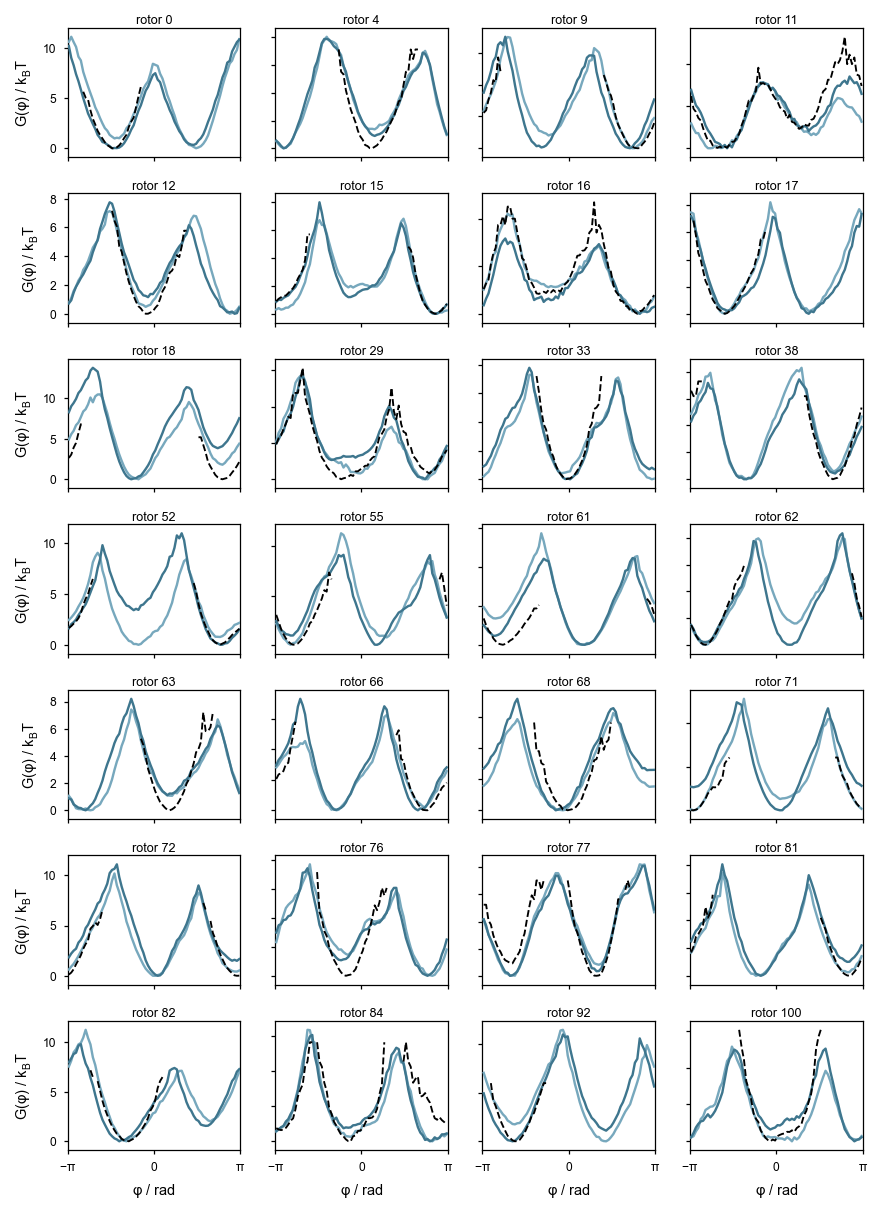

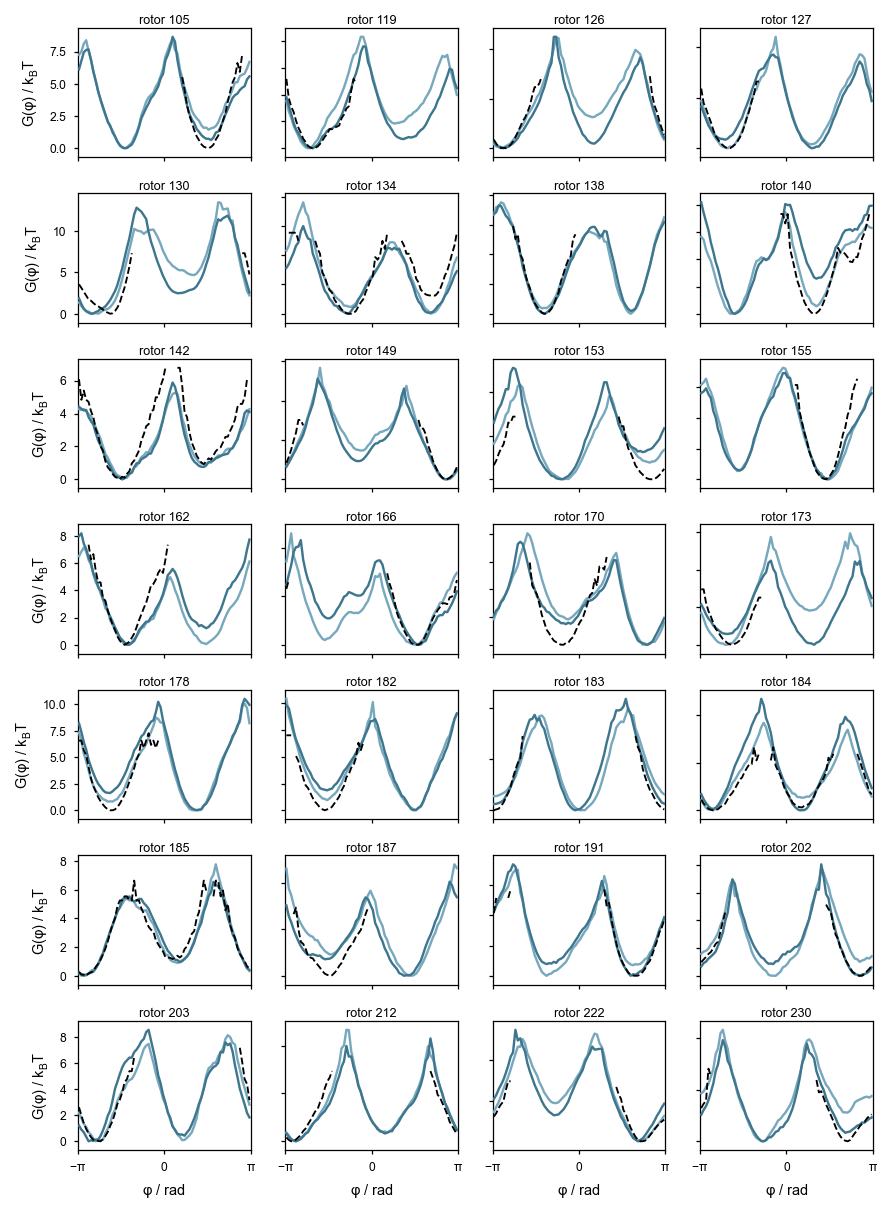

In [42]:
used_particles = [9,11,17,33,52,62,77,82,84,92,120,121,125,126,127,138,203,212,215]

particles = [0,4,9,11,12,15,16,17,18,29,33,38,52,55,61,62,63,66,68,71,72,76,77,81,82,84,92,100,105,119,126,127,130,134,
             138,140,142,149,153,155,162,166,170,173,178,182,183,184,185,187,191,202,203,212,222,230]

plot_MBAR_reconstruction_gallery(
    m_list=m_list,
    display_mode="point",
    particles=particles,
    split_target_other=True,
    show_diff=True,
    show_mean_across_measurements=False,
    ncols=4,
    nrows_per_page=7,
    shared_ylim=False,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__reconstruction_gallery",
)

## Figure 2d – MBAR-based reconstruction of exemplary target rotor energy landscapes

#### i. Run uncertainty analysis for selected rotors

In [43]:
def compute_MBAR_statistical_uncertainty_blocks(
    m_list,
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("target_only", "full"),
    nbins=72,
    pmin_nan=1e-12,
    n_bootstrap=500,
    block_s_target=0.25,
    block_s_calib=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=200,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Block-bootstrap uncertainty of target-rotor MBAR reconstructions.

    target_only:
        block-bootstrap target trajectories;
        keep the stored point-calibration fixed.

    full:
        block-bootstrap target trajectories;
        block-bootstrap trajectories of the fixed m.calibration_rotors;
        recompute ensemble centers and kappa.

    particles=None:
        analyze all m.target_rotors.

    m_list=m_list:
        analyze every UMB measurement.

    m_list=m_list[1]:
        analyze only the selected UMB measurement.

    Stores
    ------
    m.mbar_statistical_uncertainty_blocks = {
        "evals": evals,
        "summary_long": summary_long,
    }

    Nothing is returned.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    # ------------------------------------------------------------------
    # helpers
    # ------------------------------------------------------------------

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def measurement_name(m):
        return Path(str(getattr(m, "path", "UMB measurement"))).name

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)
        finite = np.isfinite(U) & np.isfinite(U_ref)

        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])
        else:
            U = zero_min(U)

        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))

        return np.squeeze(out) if axis is None else np.squeeze(out, axis=axis)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)
        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2
        out = np.full(values.size, np.nan)

        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]

            if local.size:
                out[i] = np.mean(local)

        return out

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(phase, str) and phase.startswith("deg-") for phase in m.protocol)
        )

        return "DIFF" not in name and ("UMB" in name or has_windows)

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get("start_time", value.get("t_start", value.get("t0"))),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get("t_end", value.get("t1", value.get("stop"))),
                ),
            )

            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt

        else:
            raise KeyError(
                "m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'."
            )

    def lag1(values):
        values = np.asarray(values, dtype=float)

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30

        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1(np.cos(phi)) + lag1(np.sin(phi)))

        return float(np.clip(rho, -0.99, 0.99))

    def collect_target_traces(m, particle, phases):
        ensure_time(m)

        if "group" not in m.locs.columns or "phi" not in m.locs.columns:
            raise KeyError("m.locs needs 'group' and 'phi'.")

        data = m.locs.loc[
            m.locs["group"].astype(int) == int(particle),
            ["phi", "t"],
        ].copy()

        if data.empty:
            raise ValueError(f"Particle {particle}: no localizations.")

        data = data.sort_values("t", kind="mergesort")
        data["phi"] = wrap_pi(data["phi"].to_numpy(float))

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        traces = []

        for phase in phases:
            start, stop = protocol_bounds(m.protocol[str(phase)])
            selected = (data["t"] >= start) & (data["t"] < stop)

            phi = data.loc[selected, "phi"].to_numpy(float)
            t = data.loc[selected, "t"].to_numpy(float)

            if phi.size < min_keep:
                traces.append(None)
                continue

            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
                t = t[n_trim:]

            if phi.size < min_keep:
                traces.append(None)
                continue

            finite = np.isfinite(phi) & np.isfinite(t)
            phi = wrap_pi(phi[finite])
            t = t[finite]

            rho = circular_lag1(phi)
            denominator = 1 + rho
            ess = phi.size * (1 - rho) / denominator if denominator > 1e-12 else float(phi.size)

            if ess < 10:
                traces.append(None)
                continue

            traces.append({
                "phase": str(phase),
                "phi": phi,
                "t": t,
            })

        return traces

    def collect_calibration_traces(m, calibration_rotors, phases):
        ensure_time(m)

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        cache = {}

        for particle in calibration_rotors:
            data = m.locs.loc[
                m.locs["group"].astype(int) == int(particle),
                ["phi", "t"],
            ].copy()

            if data.empty:
                continue

            data = data.sort_values("t", kind="mergesort")
            data["phi"] = wrap_pi(data["phi"].to_numpy(float))

            particle_traces = {}

            for phase in phases:
                start, stop = protocol_bounds(m.protocol[str(phase)])
                selected = (data["t"] >= start) & (data["t"] < stop)

                phi = data.loc[selected, "phi"].to_numpy(float)
                t = data.loc[selected, "t"].to_numpy(float)

                if phi.size > n_trim + 5:
                    phi = phi[n_trim:]
                    t = t[n_trim:]

                finite = np.isfinite(phi) & np.isfinite(t)
                phi = wrap_pi(phi[finite])
                t = t[finite]

                if phi.size >= min_calib_locs_per_window:
                    particle_traces[str(phase)] = {
                        "phi": phi,
                        "t": t,
                    }

            if particle_traces:
                cache[int(particle)] = particle_traces

        return cache

    def block_bootstrap(phi, t, block_s, rng):
        phi = np.asarray(phi, dtype=float)
        t = np.asarray(t, dtype=float)

        if phi.size == 0:
            return phi.copy()

        if phi.size < 3 or block_s is None or block_s <= 0:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        dt = np.nanmedian(np.diff(t)) if t.size > 1 else np.nan

        if not np.isfinite(dt) or dt <= 0:
            block_n = max(1, int(round(phi.size / 10)))
        else:
            block_n = max(1, int(round(float(block_s) / dt)))

        block_n = min(block_n, phi.size)

        starts = np.arange(0, phi.size, block_n, dtype=int)
        blocks = [phi[start:min(start + block_n, phi.size)] for start in starts]

        if len(blocks) == 1:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        n_blocks = int(np.ceil(phi.size / block_n))
        selected = rng.integers(0, len(blocks), size=n_blocks)

        return wrap_pi(np.concatenate([blocks[i] for i in selected])[:phi.size])

    def vm_kappa(phi, center):
        delta = wrap_pi(np.asarray(phi, dtype=float) - float(center))
        delta = delta[np.isfinite(delta)]

        if delta.size == 0:
            return np.nan

        R = np.hypot(np.mean(np.cos(delta)), np.mean(np.sin(delta)))

        if not np.isfinite(R) or R < 1e-8:
            return np.nan

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6

        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / max(1 - R, 1e-12)

        else:
            kappa = 1 / max(R**3 - 4 * R**2 + 3 * R, 1e-12)

        return float(max(kappa, 0))

    def run_mbar(samples, centers, kappa):
        counts = np.asarray([len(sample) for sample in samples], dtype=float)

        if len(samples) < 2:
            raise ValueError("MBAR needs at least two umbrella windows.")

        if np.any(counts <= 0):
            raise ValueError("Empty umbrella window encountered.")

        phi = wrap_pi(np.concatenate(samples))

        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)

        if centers.size != len(samples) or kappa.size != len(samples):
            raise ValueError(
                f"MBAR size mismatch: {len(samples)} samples, "
                f"{centers.size} centers, {kappa.size} kappa values."
            )

        if not np.all(np.isfinite(centers)):
            raise ValueError("Non-finite umbrella center encountered.")

        if not np.all(np.isfinite(kappa) & (kappa > 0)):
            raise ValueError("Non-finite or non-positive kappa encountered.")

        delta = wrap_pi(phi[None, :] - centers[:, None])

        if bias_potential == "cosine":
            u_kn = kappa[:, None] * (1 - np.cos(delta))

        elif bias_potential == "harmonic":
            u_kn = 0.5 * kappa[:, None] * delta**2

        else:
            raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

        log_counts = np.log(counts)
        f_k = np.zeros(len(samples))
        converged = False

        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(
                log_counts[:, None] + f_k[:, None] - u_kn,
                axis=0,
            )

            f_new = np.asarray([
                -logsumexp(-u_kn[i] - log_denominator)
                for i in range(len(f_k))
            ])

            f_new -= f_new[0]
            f_next = (1 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new

            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None] + f_k[:, None] - u_kn,
            axis=0,
        )

        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)

        weights = np.exp(log_weights)

        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        phi_grid = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])

        probability, _ = np.histogram(phi, bins=edges, weights=weights)
        probability = probability.astype(float) / dphi

        normalization = probability.sum() * dphi

        if normalization > 0:
            probability /= normalization

        energy = np.full(probability.size, np.nan)
        positive = probability > 0

        energy[positive] = -np.log(probability[positive])

        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan

        weight_square_sum = np.sum(weights**2)

        return {
            "phi": phi_grid,
            "P": probability,
            "U": zero_min(energy),
            "converged": converged,
            "n_iter": iteration + 1,
            "ess": 1 / weight_square_sum if weight_square_sum > 0 else np.nan,
        }

    def point_parameters(m, phases):
        center_df = m.center_bias["by_window"]
        kappa_df = m.kappa_bias["by_angle"]

        center_column = "ensemble_phi0" if center_mode == "ensemble" else "command_phi0"

        center_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df[center_column].astype(float),
            )
        )

        kappa_map = dict(
            zip(
                kappa_df["phase"].astype(str),
                kappa_df["kappa_mean_used_target"].astype(float),
            )
        )

        centers = np.asarray([center_map[str(phase)] for phase in phases], dtype=float)
        kappa = np.asarray([kappa_map[str(phase)] for phase in phases], dtype=float)

        if str(m.kappa_bias["mode"]) == "global":
            kappa[:] = float(m.kappa_bias["global_target"])

        return wrap_pi(centers), kappa

    def command_centers_for_phases(m, phases):
        center_df = m.center_bias["by_window"]

        command_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df["command_phi0"].astype(float),
            )
        )

        return np.asarray([command_map[str(phase)] for phase in phases], dtype=float)

    def bootstrap_calibration(
        calibration_cache,
        phases,
        command_centers,
        point_centers,
        point_kappa,
        kappa_mode_use,
        rng,
    ):
        n_windows = len(phases)

        centers = np.full(n_windows, np.nan)
        kappa_raw = np.full(n_windows, np.nan)

        for j, phase in enumerate(phases):
            rotor_centers = []
            rotor_kappas = []

            for traces in calibration_cache.values():
                trace = traces.get(str(phase))

                if trace is None:
                    continue

                phi = block_bootstrap(
                    trace["phi"],
                    trace["t"],
                    block_s_calib,
                    rng,
                )

                if phi.size < min_calib_locs_per_window:
                    continue

                rotor_center = circular_mean(phi)

                if not np.isfinite(rotor_center):
                    continue

                rotor_kappa = vm_kappa(phi, rotor_center)

                if np.isfinite(rotor_kappa) and rotor_kappa > 0:
                    rotor_centers.append(rotor_center)
                    rotor_kappas.append(rotor_kappa)

            if rotor_centers:
                centers[j] = circular_mean(rotor_centers)

            if rotor_kappas:
                kappa_raw[j] = np.mean(rotor_kappas)

        missing_center = ~np.isfinite(centers)
        centers[missing_center] = point_centers[missing_center]

        finite_kappa = np.isfinite(kappa_raw) & (kappa_raw > 0)

        if np.any(finite_kappa):
            fill_kappa = np.nanmedian(kappa_raw[finite_kappa])
        else:
            fill_kappa = np.nanmedian(point_kappa / float(kappa_rescale_target))

        kappa_raw[~finite_kappa] = fill_kappa

        if rolling_mean_kappa_ensemble:
            kappa_smoothed = periodic_mean(
                kappa_raw,
                rolling_mean_kappa_window,
            )

            missing = ~np.isfinite(kappa_smoothed) | (kappa_smoothed <= 0)
            kappa_smoothed[missing] = kappa_raw[missing]

            kappa_raw = kappa_smoothed

        if kappa_mode_use == "global":
            kappa_raw[:] = np.nanmean(kappa_raw)

        elif kappa_mode_use != "by_angle":
            raise ValueError(
                "m.kappa_bias['mode'] must be 'global' or 'by_angle'."
            )

        centers_used = centers if center_mode == "ensemble" else command_centers
        kappa_used = kappa_raw * float(kappa_rescale_target)

        return wrap_pi(centers_used), kappa_used

    # ------------------------------------------------------------------
    # modes
    # ------------------------------------------------------------------

    modes = [uncertainty_mode] if isinstance(uncertainty_mode, str) else list(uncertainty_mode)
    modes = [str(mode).lower().replace("-", "_").strip() for mode in modes]

    invalid_modes = [mode for mode in modes if mode not in {"target_only", "full"}]

    if invalid_modes:
        raise ValueError(
            f"Unknown uncertainty modes: {invalid_modes}. "
            "Use 'target_only' and/or 'full'."
        )

    # ------------------------------------------------------------------
    # measurements
    # ------------------------------------------------------------------

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for m in tqdm(
        measurements,
        desc="UMB measurements",
        total=len(measurements),
        dynamic_ncols=True,
    ):
        required = [
            "target_rotors",
            "calibration_rotors",
            "center_bias",
            "kappa_bias",
            "reconstructed_energy_landscapes_by_center",
        ]

        missing = [name for name in required if not hasattr(m, name)]

        if missing:
            raise AttributeError(
                f"{measurement_name(m)}: missing {missing}. "
                "Run run_MBAR_reconstruction(...) first."
            )

        try:
            point_landscapes = (
                m.reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception as error:
            raise KeyError(
                f"{measurement_name(m)}: no stored MBAR reconstruction for "
                f"center_mode={center_mode!r}, bias_potential={bias_potential!r}."
            ) from error

        target_rotors = list(map(int, m.target_rotors))

        if particles is None:
            particles_to_compute = target_rotors.copy()
        else:
            particles_to_compute = [
                int(particle)
                for particle in particles
                if int(particle) in target_rotors
            ]

        particles_to_compute = [
            particle
            for particle in particles_to_compute
            if particle in point_landscapes
        ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors "
                "have a stored point-MBAR reconstruction."
            )

        calibration_rotors = list(map(int, m.calibration_rotors))
        kappa_mode_use = str(m.kappa_bias["mode"])

        evals = {}
        summary_parts = []

        # --------------------------------------------------------------
        # modes
        # --------------------------------------------------------------

        for mode in modes:
            curves = {}
            rows = []

            for particle in tqdm(
                particles_to_compute,
                desc=f"{mode} | target rotors",
                total=len(particles_to_compute),
                leave=False,
                dynamic_ncols=True,
            ):
                try:
                    reference_df = point_landscapes[int(particle)]

                    phi_ref = reference_df["phi"].to_numpy(float)
                    U_ref = zero_min(reference_df["U_mbar"].to_numpy(float))
                    P_ref = reference_df["P_mbar"].to_numpy(float)

                    all_phases = m.center_bias["by_window"]["phase"].astype(str).tolist()

                    target_traces = collect_target_traces(
                        m,
                        particle,
                        all_phases,
                    )

                    keep = np.asarray(
                        [trace is not None for trace in target_traces],
                        dtype=bool,
                    )

                    if np.sum(keep) < 3:
                        raise ValueError(
                            "Fewer than three valid target umbrella windows."
                        )

                    phases = [
                        phase
                        for phase, keep_window in zip(all_phases, keep)
                        if keep_window
                    ]

                    target_traces = [
                        trace
                        for trace in target_traces
                        if trace is not None
                    ]

                    point_centers, point_kappa = point_parameters(
                        m,
                        phases,
                    )

                    command_centers = command_centers_for_phases(
                        m,
                        phases,
                    )

                    calibration_cache = {}

                    if mode == "full":
                        calibration_cache = collect_calibration_traces(
                            m,
                            calibration_rotors,
                            phases,
                        )

                        if not calibration_cache:
                            raise ValueError(
                                "No usable calibration trajectories."
                            )

                    U_boot = []
                    kappa_boot = []
                    phi0_boot = []
                    ess_boot = []
                    n_iter_boot = []

                    n_failed = 0
                    first_error = None

                    rng = np.random.default_rng(
                        seed
                        + 100000 * modes.index(mode)
                        + int(particle)
                    )

                    for _ in tqdm(
                        range(int(n_bootstrap)),
                        desc=f"particle {particle}",
                        total=int(n_bootstrap),
                        leave=False,
                        dynamic_ncols=True,
                    ):
                        try:
                            target_samples = [
                                block_bootstrap(
                                    trace["phi"],
                                    trace["t"],
                                    block_s_target,
                                    rng,
                                )
                                for trace in target_traces
                            ]

                            if mode == "full":
                                centers, kappa = bootstrap_calibration(
                                    calibration_cache=calibration_cache,
                                    phases=phases,
                                    command_centers=command_centers,
                                    point_centers=point_centers,
                                    point_kappa=point_kappa,
                                    kappa_mode_use=kappa_mode_use,
                                    rng=rng,
                                )

                            else:
                                centers = point_centers.copy()
                                kappa = point_kappa.copy()

                            result = run_mbar(
                                samples=target_samples,
                                centers=centers,
                                kappa=kappa,
                            )

                            U_boot.append(
                                align_to_reference(
                                    result["U"],
                                    U_ref,
                                )
                            )

                            kappa_boot.append(kappa.copy())
                            phi0_boot.append(centers.copy())
                            ess_boot.append(result["ess"])
                            n_iter_boot.append(result["n_iter"])

                        except Exception as error:
                            n_failed += 1

                            if first_error is None:
                                first_error = f"{type(error).__name__}: {error}"

                    if not U_boot:
                        raise RuntimeError(
                            f"All bootstrap replicates failed for particle "
                            f"{particle}, mode {mode}. "
                            f"First bootstrap error: {first_error}"
                        )

                    U_boot = np.asarray(U_boot, dtype=float)
                    kappa_boot = np.asarray(kappa_boot, dtype=float)
                    phi0_boot = np.asarray(phi0_boot, dtype=float)

                    q_low, q_high = map(float, ci)

                    U_median, U_low, U_high = np.nanpercentile(
                        U_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    U_std = np.nanstd(
                        U_boot,
                        axis=0,
                        ddof=1,
                    )

                    kappa_median, kappa_low, kappa_high = np.nanpercentile(
                        kappa_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    phi0_delta = wrap_pi(
                        phi0_boot
                        - point_centers[None, :]
                    )

                    phi0_median, phi0_low, phi0_high = np.nanpercentile(
                        phi0_delta,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    finite = np.isfinite(U_ref)

                    G_range = (
                        np.nanmax(U_ref[finite])
                        - np.nanmin(U_ref[finite])
                        if np.any(finite)
                        else np.nan
                    )

                    sigma_mean = float(np.nanmean(U_std))
                    sigma_p90 = float(np.nanpercentile(U_std, 90))
                    ci_width_mean = float(np.nanmean(U_high - U_low))

                    landscape_df = pd.DataFrame({
                        "particle": int(particle),
                        "phi": phi_ref,
                        "U_MBAR_point": U_ref,
                        "P_MBAR_point": P_ref,
                        "U_boot_median": U_median,
                        "U_boot_low": U_low,
                        "U_boot_high": U_high,
                        "U_boot_std": U_std,
                    })

                    calibration_df = pd.DataFrame({
                        "phase": phases,
                        "phi0_point": point_centers,
                        "phi0_delta_median": phi0_median,
                        "phi0_delta_low": phi0_low,
                        "phi0_delta_high": phi0_high,
                        "phi0_delta_median_deg": np.rad2deg(phi0_median),
                        "phi0_delta_low_deg": np.rad2deg(phi0_low),
                        "phi0_delta_high_deg": np.rad2deg(phi0_high),
                        "kappa_point": point_kappa,
                        "kappa_boot_median": kappa_median,
                        "kappa_boot_low": kappa_low,
                        "kappa_boot_high": kappa_high,
                    })

                    curves[int(particle)] = {
                        "landscape_df": landscape_df,
                        "calibration_df": calibration_df,
                        "U_boot_curves": U_boot,
                        "kappa_boot_curves": kappa_boot,
                        "phi0_boot_curves": phi0_boot,
                        "phase_list": phases,
                        "calib_particles": calibration_rotors,
                    }

                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "ok",
                        "error": "",
                        "n_bootstrap_requested": int(n_bootstrap),
                        "n_bootstrap_success": int(len(U_boot)),
                        "n_bootstrap_failed": int(n_failed),
                        "G_range_MBAR_kBT": float(G_range),
                        "sigma_G_mean_kBT": sigma_mean,
                        "sigma_G_p90_kBT": sigma_p90,
                        "CI_width_G_mean_kBT": ci_width_mean,
                        "relative_sigma_G_mean": (
                            sigma_mean / G_range
                            if np.isfinite(G_range) and G_range > 0
                            else np.nan
                        ),
                        "bootstrap_ESS_median": float(np.nanmedian(ess_boot)),
                        "bootstrap_n_iter_median": float(np.nanmedian(n_iter_boot)),
                        "n_target_locs_total": int(
                            sum(len(trace["phi"]) for trace in target_traces)
                        ),
                        "n_windows": int(len(phases)),
                        "n_calibration_rotors": int(len(calibration_rotors)),
                    })

                except Exception as error:
                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "failed",
                        "error": f"{type(error).__name__}: {error}",
                    })

            summary_df = pd.DataFrame(rows)

            evals[mode] = {
                "curves": curves,
                "summary_df": summary_df,
            }

            summary_parts.append(summary_df)

        m.mbar_statistical_uncertainty_blocks = {
            "evals": evals,
            "summary_long": pd.concat(
                summary_parts,
                ignore_index=True,
            ),
        }

    return None

In [44]:
# 99,11,17,33,52,62,77,82,84,92,120,121,125,126,127,138,203,212,215
showcase_particle = 17
gallery_particles = [77,9,138,62,33,127]
panel_particles = [showcase_particle,*gallery_particles,]

In [45]:
compute_MBAR_statistical_uncertainty_blocks(
    m_list=m_list,
    particles=panel_particles,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("full"),
    nbins=72,
    n_bootstrap=100,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388/1.14,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

UMB measurements:   0%|                                                                          | 0/2 [00:00<…

full | target rotors:   0%|                                                                      | 0/7 [00:00<…

particle 17:   0%|                                                                             | 0/100 [00:00<…

particle 77:   0%|                                                                             | 0/100 [00:00<…

particle 9:   0%|                                                                              | 0/100 [00:00<…

particle 138:   0%|                                                                            | 0/100 [00:00<…

... (7 outputs left out)

particle 138:   0%|                                                                            | 0/100 [00:00<…

particle 62:   0%|                                                                             | 0/100 [00:00<…

particle 33:   0%|                                                                             | 0/100 [00:00<…

particle 127:   0%|                                                                            | 0/100 [00:00<…

#### ii. Plot Figure 2d

In [46]:
def plot_MBAR_target_reconstruction_gallery(
    m_list,
    showcase_particle,
    gallery_particles,
    uncertainty_mode="full",
    uncertainty_interval=(2.5, 97.5),
    center_mode="ensemble",
    bias_potential="cosine",
    m_umb_primary=None,
    m_umb_secondary=None,
    overlay_second_umb_in_gallery=True,
    show_gallery_uncertainty=True,
    show_second_umb_uncertainty=False,
    particle_col="group",
    phi_col="phi",
    diff_pmin=1e-12,
    fig_width_mm=180,
    fig_height_mm=104,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    C=None,
    save_dir=None,
    save_prefix="Fig2d_energy_landscape_reconstruction_two_umbs",
):
    """
    Variant of the main reconstruction figure:
    - showcase panel uses the primary UMB measurement
    - gallery panels can additionally overlay the reconstruction from a second UMB measurement
    - DIFF reference is always computed from separate DIFF measurement(s)

    Parameters
    ----------
    uncertainty_mode : {"target_only", "full", None}
        Which stored bootstrap uncertainty to use.

    uncertainty_interval : tuple(float, float)
        Percentile interval shown for bootstrap bands, e.g. (2.5, 97.5) or (10, 90).

    m_umb_primary, m_umb_secondary : measurement or None
        Explicit primary / secondary UMB measurement. If None, they are auto-selected
        from the supplied non-DIFF measurements.

    overlay_second_umb_in_gallery : bool
        If True, overlay the second UMB reconstruction in the 6 gallery panels.

    show_gallery_uncertainty : bool
        If True, show the bootstrap uncertainty band in the small gallery panels.

    show_second_umb_uncertainty : bool
        If True, also show the bootstrap band of the second UMB reconstruction in the gallery.
        Usually False is visually cleaner.

    Nothing is returned.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    # ============================================================
    # helpers: basic
    # ============================================================

    def mm(x): return float(x) / 25.4

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            out = []
            for xx in x:
                out.extend(flatten(xx))
            return out
        return [x]

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def zero_min_preserve_nan(y):
        y = np.asarray(y, dtype=float).copy()
        ok = np.isfinite(y)
        if np.any(ok):
            y[ok] -= np.nanmin(y[ok])
        return y

    def finite_limits(arrs, pad=0.08):
        vals = []
        for a in arrs:
            a = np.asarray(a, dtype=float)
            a = a[np.isfinite(a)]
            if a.size:
                vals.append(a)
        if len(vals) == 0:
            return None
        vals = np.concatenate(vals)
        lo, hi = float(np.nanmin(vals)), float(np.nanmax(vals))
        span = hi - lo
        if not np.isfinite(span) or span == 0:
            span = 1.0
        return lo - pad * span, hi + pad * span

    def barrier(U):
        U = np.asarray(U, dtype=float)
        ok = np.isfinite(U)
        if not np.any(ok):
            return np.nan
        return float(np.nanmax(U[ok]) - np.nanmin(U[ok]))

    def percentile_axis0(values, percentile):
        values = np.asarray(values, dtype=float)
        out = np.full(values.shape[1], np.nan)
        for i in range(values.shape[1]):
            col = values[:, i]
            col = col[np.isfinite(col)]
            if col.size:
                out[i] = np.percentile(col, percentile)
        return out

    def interp_periodic(phi_src, y_src, phi_target):
        phi_src = wrap_pi(np.asarray(phi_src, dtype=float))
        y_src = np.asarray(y_src, dtype=float)
        phi_target = wrap_pi(np.asarray(phi_target, dtype=float))
        order = np.argsort(phi_src)
        x = phi_src[order]
        y = y_src[order]
        ok = np.isfinite(x) & np.isfinite(y)
        x = x[ok]
        y = y[ok]
        if x.size < 2:
            return np.full_like(phi_target, np.nan, dtype=float)
        x_ext = np.r_[x - 2 * np.pi, x, x + 2 * np.pi]
        y_ext = np.r_[y, y, y]
        return np.interp(phi_target, x_ext, y_ext)

    def plot_nanseg(ax, x, y, color, lw=1.0, ls="-", alpha=1.0, zorder=2, label=None):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        ok = np.isfinite(x) & np.isfinite(y)
        if not np.any(ok):
            return False
        idx = np.where(ok)[0]
        breaks = np.where(np.diff(idx) > 1)[0]
        starts = np.r_[0, breaks + 1]
        ends = np.r_[breaks + 1, len(idx)]
        did_label = False
        plotted = False
        for s, e in zip(starts, ends):
            seg = idx[s:e]
            if seg.size >= 2:
                ax.plot(x[seg], y[seg], color=color, lw=lw, ls=ls, alpha=alpha, zorder=zorder, label=label if not did_label else None)
                did_label = True
                plotted = True
        return plotted

    # ============================================================
    # helpers: colors / style
    # ============================================================

    if C is None:
        if "CK_colors" in globals() and callable(globals()["CK_colors"]):
            C = globals()["CK_colors"]()
        else:
            C = {}
    elif callable(C):
        C = C()
    C = dict(C)

    defaults = {
        "target_teal": (111/255, 166/255, 166/255),
        "darkblue": (46/255, 89/255, 108/255),
        "lightblue": (73/255, 139/255, 167/255),
        "palecyan": (167/255, 197/255, 197/255),
        "beige": (225/255, 209/255, 180/255),
        "offwhite": (222/255, 224/255, 213/255),
        "orange": (215/255, 131/255, 41/255),
        "warmgold": (226/255, 172/255, 72/255),
        "gold": (226/255, 172/255, 72/255),
        "darkred": (102/255, 27/255, 35/255),
        "grey": (0.25, 0.25, 0.25),
        "midgrey": (0.45, 0.45, 0.45),
        "lightgrey": (0.72, 0.72, 0.72),
        "verylightgrey": (0.86, 0.86, 0.86),
        "black": (0.0, 0.0, 0.0),
    }
    for k, v in defaults.items():
        C.setdefault(k, v)

    def blend(color, other, alpha):
        color = np.asarray(color, dtype=float)
        other = np.asarray(other, dtype=float)
        return tuple((1 - alpha) * color + alpha * other)

    primary_line_color = C["target_teal"]
    secondary_line_color = blend(C["target_teal"], (0, 0, 0), 0.30)
    primary_band_color = C["target_teal"]
    secondary_band_color = blend(C["target_teal"], (1, 1, 1), 0.15)

    GREY_TEXT = "black"
    axis_lw, tick_len, tick_w = 0.6, 2.0, 0.6
    showcase_tick_fs, showcase_label_fs, showcase_annot_fs = tick_label_size, axis_label_size, fontsize
    gallery_tick_fs, gallery_label_fs, gallery_annot_fs = tick_label_size, axis_label_size, fontsize
    gallery_primary_lw, gallery_secondary_lw, gallery_diff_lw = 1.0, 0.95, 0.85
    bias_lw, bias_alpha, hist_lw, hist_alpha = 0.65, 0.55, 0.85, 0.90

    def style_ax(ax, labelsize=7):
        for sp in ax.spines.values():
            sp.set_color(GREY_TEXT)
            sp.set_linewidth(axis_lw)
        ax.tick_params(axis="both", length=tick_len, width=tick_w, colors=GREY_TEXT, labelsize=labelsize, direction="out")
        ax.xaxis.label.set_color(GREY_TEXT)
        ax.yaxis.label.set_color(GREY_TEXT)
        ax.grid(False)

    def style_gallery_energy_ax(ax, show_xlabel=False):
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(GREY_TEXT)
        ax.spines["bottom"].set_linewidth(axis_lw)
        ax.tick_params(axis="x", length=tick_len, width=tick_w, colors=GREY_TEXT, labelsize=gallery_tick_fs, direction="out")
        ax.tick_params(axis="y", length=0.0, width=0.0, labelleft=False)
        ax.set_xticks([-np.pi, -np.pi/2, 0.0, np.pi/2, np.pi])
        if show_xlabel:
            ax.set_xticklabels(["−π", "", "0", "", "π"], fontsize=gallery_tick_fs)
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=gallery_label_fs, labelpad=2, color=GREY_TEXT)
        else:
            ax.set_xticklabels([])
        ax.set_ylabel("")
        ax.set_yticks([])
        ax.grid(False)

    def set_phi_ticks_simple(ax, show_ticklabels=True, labelsize=7):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"] if show_ticklabels else [])

    def set_phi_ticks_main_energy(ax, labelsize=7):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi/2, 0.0, np.pi/2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"], fontsize=labelsize)

    def histogram_window_colors(n):
        base = [(0.25,0.38,0.46), (0.32,0.50,0.60), (0.42,0.62,0.70), (0.55,0.72,0.77), (0.70,0.82,0.83), (0.82,0.88,0.87)]
        cmap = LinearSegmentedColormap.from_list("umbrella_hist_blue_teal", base, N=256)
        return [cmap(0.5)] if n <= 1 else [cmap(v) for v in np.linspace(0.0, 1.0, int(n))]

    def bias_window_colors(n):
        base = [(0.96,0.91,0.72), (0.91,0.82,0.56), (0.86,0.70,0.36), (0.78,0.56,0.25), (0.62,0.42,0.23)]
        cmap = LinearSegmentedColormap.from_list("umbrella_bias_yellow_gold", base, N=256)
        return [cmap(0.5)] if n <= 1 else [cmap(v) for v in np.linspace(0.0, 1.0, int(n))]

    def compute_bias_curves_harmonic(phi_grid, phi0_list, kappa_list):
        phi_grid = np.asarray(phi_grid, float)
        phi0_list = np.asarray(phi0_list, float)
        kappa_list = np.asarray(kappa_list, float)
        half_width = np.deg2rad(55.0)
        U_max_plot = 8.0
        curves = []
        for phi0, kappa in zip(phi0_list, kappa_list):
            dphi = (phi_grid - phi0 + np.pi) % (2.0 * np.pi) - np.pi
            U = 0.5 * float(kappa) * dphi**2
            U[np.abs(dphi) > half_width] = np.nan
            U[U > U_max_plot] = np.nan
            curves.append(U)
        return np.asarray(curves, dtype=float)

    def add_vertical_gallery_scalebar(ax, dU=5.0, label=r"$5\,k_\mathrm{B}T$"):
        xlim = ax.get_xlim()
        ylim = ax.get_ylim()
        x = xlim[0] + 0.08 * (xlim[1] - xlim[0])
        y0 = ylim[0] + 0.13 * (ylim[1] - ylim[0])
        y1 = y0 + float(dU)
        if y1 > ylim[1] - 0.06 * (ylim[1] - ylim[0]):
            y1 = ylim[1] - 0.06 * (ylim[1] - ylim[0])
            y0 = y1 - float(dU)
        ax.plot([x, x], [y0, y1], color=GREY_TEXT, lw=0.8, solid_capstyle="butt", clip_on=False, zorder=10)
        ax.text(x + 0.04 * (xlim[1] - xlim[0]), 0.5 * (y0 + y1), label, ha="left", va="center", fontsize=gallery_annot_fs, color=GREY_TEXT)

    # ============================================================
    # helpers: measurement / protocol
    # ============================================================

    def measurement_name(m):
        try:
            return Path(str(getattr(m, "path", ""))).name
        except Exception:
            return str(getattr(m, "path", ""))

    def is_diff_measurement(m):
        return "DIFF" in measurement_name(m).upper()

    def ensure_time_column(m):
        if "t" in m.locs.columns:
            return
        m.locs = m.locs.copy()
        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float); return
        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float); return
        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float); return
        if "frame" in m.locs.columns and hasattr(m, "_average_tpf"):
            m.locs["t"] = m.locs["frame"].astype(float) * float(m._average_tpf); return
        if "frame" in m.locs.columns:
            m.locs["t"] = m.locs["frame"].astype(float) * 0.005; return
        raise ValueError("Need one of t / averagetime / time / time_s / frame to build time axis.")

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]
        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", None))))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")
            return float(t0), float(t1)
        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])
        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def phase_to_bounds(m, phase):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or invalid.")
        if str(phase) not in m.protocol:
            raise KeyError(f"Phase {phase!r} not found in m.protocol.")
        return protocol_bounds(m.protocol[str(phase)])

    def use_time_bounds(m, start, stop):
        ensure_time_column(m)
        tmax = float(np.nanmax(m.locs["t"].to_numpy(float)))
        return float(stop) <= 1.25 * tmax

    def collect_phi_time_for_phases(m, particle, phase_list):
        ensure_time_column(m)
        if phi_col not in m.locs.columns:
            raise KeyError(f"{phi_col!r} missing in m.locs.")
        if particle_col not in m.locs.columns:
            if "group_int" in m.locs.columns:
                m.locs = m.locs.copy()
                m.locs[particle_col] = m.locs["group_int"].astype(int)
            else:
                raise KeyError(f"{particle_col!r} missing in m.locs.")
        trim_s = float(getattr(m, "wham_trim_s", 0.0))
        cols = [particle_col, phi_col, "t"] + (["frame"] if "frame" in m.locs.columns else [])
        dfp = m.locs.loc[m.locs[particle_col].astype(int) == int(particle), cols].copy()
        if dfp.empty:
            raise ValueError(f"No localizations for particle {particle}.")
        dfp[phi_col] = wrap_pi(dfp[phi_col].to_numpy(float))
        traces = []
        for phase in phase_list:
            start, stop = phase_to_bounds(m, phase)
            if use_time_bounds(m, start, stop):
                vals = dfp["t"].to_numpy(float)
                sel = (vals >= start + trim_s) & (vals < stop)
                t_sel = dfp.loc[sel, "t"].to_numpy(float)
            else:
                if "frame" not in dfp.columns:
                    raise ValueError("Frame-based protocol but frame column missing.")
                vals = dfp["frame"].to_numpy(float)
                dt = float(getattr(m, "_average_tpf", 1.0))
                n_trim = int(np.ceil(trim_s / dt))
                sel = (vals >= start + n_trim) & (vals < stop)
                t_sel = dfp.loc[sel, "frame"].to_numpy(float) * dt
            phi_sel = wrap_pi(dfp.loc[sel, phi_col].to_numpy(float))
            ok = np.isfinite(phi_sel) & np.isfinite(t_sel)
            phi_sel = phi_sel[ok]
            t_sel = t_sel[ok]
            order = np.argsort(t_sel)
            traces.append({"phase": str(phase), "phi": phi_sel[order], "t": t_sel[order]})
        return traces

    def hist_energy_on_edges(phi_samples, edges, pmin_nan=1e-12):
        phi_samples = wrap_pi(np.asarray(phi_samples, dtype=float))
        phi_samples = phi_samples[np.isfinite(phi_samples)]
        edges = np.asarray(edges, dtype=float)
        centers = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])
        if phi_samples.size == 0:
            P = np.zeros_like(centers, dtype=float)
            U = np.full_like(centers, np.nan, dtype=float)
            counts = np.zeros_like(centers, dtype=float)
            return centers, P, U, counts
        counts, _ = np.histogram(phi_samples, bins=edges, density=False)
        counts = counts.astype(float)
        P = counts / max(float(np.sum(counts)) * dphi, 1e-300)
        U = np.full_like(P, np.nan, dtype=float)
        ok = counts > 0
        U[ok] = -np.log(np.maximum(P[ok], 1e-300))
        if pmin_nan is not None and pmin_nan > 0:
            U[P < float(pmin_nan)] = np.nan
        U = zero_min_preserve_nan(U)
        return centers, P, U, counts

    def collect_diff_phi(diff_measurements, particle):
        phi_all = []
        for m in diff_measurements:
            if not hasattr(m, "locs") or not isinstance(m.locs, pd.DataFrame):
                continue
            if phi_col not in m.locs.columns:
                continue
            if particle_col not in m.locs.columns:
                if "group_int" in m.locs.columns:
                    m.locs = m.locs.copy()
                    m.locs[particle_col] = m.locs["group_int"].astype(int)
                else:
                    continue
            phi = m.locs.loc[m.locs[particle_col].astype(int) == int(particle), phi_col].to_numpy(float)
            phi = wrap_pi(phi)
            phi = phi[np.isfinite(phi)]
            if phi.size:
                phi_all.append(phi)
        return np.concatenate(phi_all) if phi_all else np.array([], dtype=float)

    # ============================================================
    # helpers: stored MBAR / uncertainty
    # ============================================================

    def pull_point_landscape(m, pid):
        if not hasattr(m, "reconstructed_energy_landscapes_by_center"):
            return None
        try:
            df = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential][int(pid)].copy()
        except Exception:
            return None
        if "U_mbar" in df.columns:
            U = df["U_mbar"].to_numpy(float)
        elif "U_MBAR" in df.columns:
            U = df["U_MBAR"].to_numpy(float)
        else:
            return None
        phi = df["phi"].to_numpy(float)
        return {"phi": phi, "U": zero_min_preserve_nan(U), "df": df}

    def pull_uncertainty_for_particle(m, pid, phi_target):
        if uncertainty_mode is None:
            return None, None, None

        qlow, qhigh = map(float, uncertainty_interval)

        if not 0 <= qlow < qhigh <= 100:
            raise ValueError("uncertainty_interval must contain two ordered percentiles between 0 and 100.")

        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)
        if not isinstance(stored, dict) or "evals" not in stored:
            return None, None, None

        mode = str(uncertainty_mode).lower().replace("-", "_").strip()
        if mode not in stored["evals"]:
            return None, None, None

        curves = stored["evals"][mode].get("curves", {})
        if int(pid) not in curves:
            return None, None, None

        entry = curves[int(pid)]

        U_boot = np.asarray(entry.get("U_boot_curves", []), dtype=float)

        if U_boot.ndim == 2 and U_boot.shape[0] >= 2:
            df = entry["landscape_df"]
            phi_source = df["phi"].to_numpy(float)
            U_low = percentile_axis0(U_boot, qlow)
            U_high = percentile_axis0(U_boot, qhigh)
            U_std = np.nanstd(U_boot, axis=0, ddof=1)
        else:
            df = entry["landscape_df"]
            required = {"phi", "U_boot_low", "U_boot_high", "U_boot_std"}
            if not required.issubset(df.columns):
                return None, None, None
            phi_source = df["phi"].to_numpy(float)
            U_low = df["U_boot_low"].to_numpy(float)
            U_high = df["U_boot_high"].to_numpy(float)
            U_std = df["U_boot_std"].to_numpy(float)

        if phi_source.size == phi_target.size and np.allclose(phi_source, phi_target, atol=1e-10, rtol=0.0):
            return U_low, U_high, U_std

        return (
            interp_periodic(phi_source, U_low, phi_target),
            interp_periodic(phi_source, U_high, phi_target),
            interp_periodic(phi_source, U_std, phi_target),
        )

    def score_measurement(m, particles_needed):
        score = 0
        for pid in particles_needed:
            if pull_point_landscape(m, pid) is not None:
                score += 1
        return score

    # ============================================================
    # select measurements
    # ============================================================

    m_flat = flatten(m_list)
    diff_measurements = [m for m in m_flat if is_diff_measurement(m)]
    umb_measurements = [m for m in m_flat if not is_diff_measurement(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No non-DIFF UMB measurement found in m_list.")

    showcase_particle = int(showcase_particle)
    gallery_particles = [int(p) for p in gallery_particles]
    particles_requested = [showcase_particle] + [p for p in gallery_particles if int(p) != showcase_particle]

    if m_umb_primary is None:
        ranked = sorted([(score_measurement(m, particles_requested), m) for m in umb_measurements], key=lambda x: x[0], reverse=True)
        if len(ranked) == 0 or ranked[0][0] == 0:
            raise ValueError("Could not auto-select a primary UMB measurement with stored MBAR results.")
        m_primary = ranked[0][1]
    else:
        m_primary = m_umb_primary

    if overlay_second_umb_in_gallery:
        if m_umb_secondary is not None:
            m_secondary = m_umb_secondary
        else:
            ranked2 = [(score_measurement(m, gallery_particles), m) for m in umb_measurements if m is not m_primary]
            ranked2 = sorted(ranked2, key=lambda x: x[0], reverse=True)
            m_secondary = ranked2[0][1] if len(ranked2) and ranked2[0][0] > 0 else None
    else:
        m_secondary = None

    if not hasattr(m_primary, "center_bias") or "by_window" not in m_primary.center_bias:
        raise AttributeError("Primary UMB measurement is missing m.center_bias['by_window'].")

    if not hasattr(m_primary, "kappa_bias") or "by_angle" not in m_primary.kappa_bias:
        raise AttributeError("Primary UMB measurement is missing m.kappa_bias['by_angle'].")

    bias_df = m_primary.center_bias["by_window"].copy()
    kappa_df = m_primary.kappa_bias["by_angle"].copy()
    phase_list_all = bias_df["phase"].astype(str).tolist()

    if str(center_mode) == "ensemble":
        phi0_lookup = dict(zip(bias_df["phase"].astype(str), bias_df["ensemble_phi0"].astype(float)))
    elif str(center_mode) == "command":
        phi0_lookup = dict(zip(bias_df["phase"].astype(str), bias_df["command_phi0"].astype(float)))
    else:
        raise ValueError("center_mode must be 'ensemble' or 'command'.")

    target_rotors = set(map(int, getattr(m_primary, "target_rotors", [])))

    def kappa_lookup_for_particle(pid):
        if int(pid) in target_rotors and "kappa_mean_used_target" in kappa_df.columns:
            return dict(zip(kappa_df["phase"].astype(str), kappa_df["kappa_mean_used_target"].astype(float)))
        if "kappa_mean_used_calibration" in kappa_df.columns:
            return dict(zip(kappa_df["phase"].astype(str), kappa_df["kappa_mean_used_calibration"].astype(float)))
        if "kappa_mean_used_raw" in kappa_df.columns:
            return dict(zip(kappa_df["phase"].astype(str), kappa_df["kappa_mean_used_raw"].astype(float)))
        raise KeyError("Could not find suitable kappa column in m_primary.kappa_bias['by_angle'].")

    # ============================================================
    # assemble particle data
    # ============================================================

    particle_data = {}

    for pid in particles_requested:
        primary_land = pull_point_landscape(m_primary, pid)
        if primary_land is None:
            continue

        traces = collect_phi_time_for_phases(m_primary, int(pid), phase_list_all)
        keep = np.asarray([tr["phi"].size > 0 for tr in traces], dtype=bool)
        traces = [tr for tr, kk in zip(traces, keep) if kk]
        if len(traces) == 0:
            continue

        phase_keep = [ph for ph, kk in zip(phase_list_all, keep) if kk]
        phi0_use = np.asarray([phi0_lookup[str(ph)] for ph in phase_keep], dtype=float)
        kappa_map = kappa_lookup_for_particle(int(pid))
        kappa_use = np.asarray([kappa_map[str(ph)] for ph in phase_keep], dtype=float)

        phi_samples_list = [tr["phi"] for tr in traces]
        all_umb_phi = np.concatenate(phi_samples_list) if len(phi_samples_list) else np.array([], dtype=float)

        phi_primary = primary_land["phi"].astype(float)
        U_primary = primary_land["U"].astype(float)

        n_bins = int(phi_primary.size)
        edges = np.linspace(-np.pi, np.pi, n_bins + 1)

        _, P_pool, U_pool, counts_pool = hist_energy_on_edges(all_umb_phi, edges=edges, pmin_nan=diff_pmin)
        diff_phi_samples = collect_diff_phi(diff_measurements, int(pid))
        _, P_diff, U_diff, counts_diff = hist_energy_on_edges(diff_phi_samples, edges=edges, pmin_nan=diff_pmin)

        hist_centers = 0.5 * (edges[:-1] + edges[1:])
        H_density, H_counts = [], []
        for arr in phi_samples_list:
            cnt, _ = np.histogram(wrap_pi(arr), bins=edges, density=False)
            cnt = cnt.astype(float)
            H_counts.append(cnt)
            den = cnt / (np.sum(cnt) * float(edges[1] - edges[0])) if np.sum(cnt) > 0 else np.zeros_like(hist_centers)
            H_density.append(den)
        H_density = np.asarray(H_density, float)
        H_counts = np.asarray(H_counts, float)

        U1_low, U1_high, U1_std = pull_uncertainty_for_particle(m_primary, int(pid), phi_primary)
        if U1_low is None:
            U1_low = np.full_like(phi_primary, np.nan, dtype=float)
            U1_high = np.full_like(phi_primary, np.nan, dtype=float)
            U1_std = np.full_like(phi_primary, np.nan, dtype=float)

        secondary_info = None

        if m_secondary is not None and overlay_second_umb_in_gallery:
            second_land = pull_point_landscape(m_secondary, pid)
            if second_land is not None:
                phi2_raw = second_land["phi"].astype(float)
                U2_raw = second_land["U"].astype(float)
                U2 = interp_periodic(phi2_raw, U2_raw, phi_primary)

                U2_low, U2_high, U2_std = pull_uncertainty_for_particle(m_secondary, int(pid), phi2_raw)
                if U2_low is not None:
                    U2_low = interp_periodic(phi2_raw, U2_low, phi_primary)
                    U2_high = interp_periodic(phi2_raw, U2_high, phi_primary)
                    U2_std = interp_periodic(phi2_raw, U2_std, phi_primary)
                else:
                    U2_low = np.full_like(phi_primary, np.nan, dtype=float)
                    U2_high = np.full_like(phi_primary, np.nan, dtype=float)
                    U2_std = np.full_like(phi_primary, np.nan, dtype=float)

                secondary_info = {
                    "phi": phi_primary.copy(),
                    "U_MBAR": U2,
                    "U_low": U2_low,
                    "U_high": U2_high,
                    "U_std": U2_std,
                }

        landscape_df = pd.DataFrame({
            "particle": int(pid),
            "phi": phi_primary,
            "U_MBAR": U_primary,
            "U_MBAR_boot_low": U1_low,
            "U_MBAR_boot_high": U1_high,
            "U_MBAR_boot_std": U1_std,
            "U_pooled": U_pool,
            "P_pooled": P_pool,
            "counts_pooled": counts_pool,
            "U_DIFF": U_diff,
            "P_DIFF": P_diff,
            "counts_DIFF": counts_diff,
        })

        particle_data[int(pid)] = {
            "particle": int(pid),
            "phase_list": phase_keep,
            "phi0": phi0_use,
            "kappa": kappa_use,
            "hist_phi": hist_centers,
            "hist_density": H_density,
            "hist_counts": H_counts,
            "landscape_df": landscape_df,
            "secondary": secondary_info,
        }

    # ============================================================
    # validate particles
    # ============================================================

    if showcase_particle not in particle_data:
        raise ValueError(f"showcase_particle={showcase_particle} is not available in the selected primary UMB measurement.")

    gallery_particles_valid = []
    missing_gallery = []

    for p in gallery_particles:
        if p in particle_data and p != showcase_particle:
            gallery_particles_valid.append(p)
        else:
            missing_gallery.append(p)

    if len(missing_gallery) > 0:
        print("Warning: these gallery particles are missing and will be skipped:", missing_gallery)

    if len(gallery_particles_valid) == 0:
        raise ValueError("No valid gallery particles found in the selected primary UMB measurement.")

    if len(gallery_particles_valid) > 6:
        gallery_particles_valid = gallery_particles_valid[:6]

    gallery_particles = gallery_particles_valid

    # ============================================================
    # showcase data
    # ============================================================

    pdata_show = particle_data[showcase_particle]
    df_show = pdata_show["landscape_df"]

    phi_show = df_show["phi"].to_numpy(float)
    U_mbar_show = zero_min_preserve_nan(df_show["U_MBAR"].to_numpy(float))
    U_low_show = df_show["U_MBAR_boot_low"].to_numpy(float)
    U_high_show = df_show["U_MBAR_boot_high"].to_numpy(float)
    U_pool_show = zero_min_preserve_nan(df_show["U_pooled"].to_numpy(float))
    U_diff_show = zero_min_preserve_nan(df_show["U_DIFF"].to_numpy(float))
    dG_show = barrier(U_mbar_show)

    phi_hist = np.asarray(pdata_show["hist_phi"], dtype=float)
    H = np.asarray(pdata_show["hist_density"], dtype=float)
    phi0_show = np.asarray(pdata_show["phi0"], dtype=float)
    kappa_show = np.asarray(pdata_show["kappa"], dtype=float)

    U_bias_curves = compute_bias_curves_harmonic(phi_hist, phi0_show, kappa_show)
    colors_hist = histogram_window_colors(H.shape[0])
    colors_bias = bias_window_colors(U_bias_curves.shape[0])

    # ============================================================
    # y limits
    # ============================================================

    showcase_energy_ylim = finite_limits([U_mbar_show, U_low_show, U_high_show, U_pool_show, U_diff_show], pad=0.08)

    gallery_energy_arrays = []
    for pid in gallery_particles:
        df = particle_data[pid]["landscape_df"]
        gallery_energy_arrays.append(zero_min_preserve_nan(df["U_MBAR"].to_numpy(float)))
        gallery_energy_arrays.append(zero_min_preserve_nan(df["U_DIFF"].to_numpy(float)))
        if show_gallery_uncertainty:
            gallery_energy_arrays.append(df["U_MBAR_boot_low"].to_numpy(float))
            gallery_energy_arrays.append(df["U_MBAR_boot_high"].to_numpy(float))
        if particle_data[pid]["secondary"] is not None:
            gallery_energy_arrays.append(particle_data[pid]["secondary"]["U_MBAR"])
            if show_gallery_uncertainty and show_second_umb_uncertainty:
                gallery_energy_arrays.append(particle_data[pid]["secondary"]["U_low"])
                gallery_energy_arrays.append(particle_data[pid]["secondary"]["U_high"])

    gallery_energy_ylim = finite_limits(gallery_energy_arrays, pad=0.08)
    H_ylim = finite_limits(H, pad=0.08)

    # ============================================================
    # layout
    # ============================================================

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))
    outer = gridspec.GridSpec(1, 2, figure=fig, left=0.060, right=0.985, bottom=0.105, top=0.985, width_ratios=[1.20, 1.10], wspace=0.10)
    left = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=outer[0, 0], height_ratios=[0.45, 1.00, 1.45], hspace=0.15)
    right = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=outer[0, 1], hspace=0.35, wspace=0.10)

    axU = fig.add_subplot(left[0, 0])
    axP = fig.add_subplot(left[1, 0])
    axG = fig.add_subplot(left[2, 0])

    # ============================================================
    # top: harmonic umbrella bias potentials
    # ============================================================

    for i in range(U_bias_curves.shape[0]):
        plot_nanseg(axU, phi_hist, U_bias_curves[i], color=colors_bias[i], lw=bias_lw, ls="-", alpha=bias_alpha, zorder=2)

    axU.set_ylim(0, 8)
    set_phi_ticks_simple(axU, show_ticklabels=False, labelsize=showcase_tick_fs)
    axU.set_ylabel(r"$U_i(\varphi)$ / $k_\mathrm{B}T$", fontsize=axis_label_size, labelpad=2)
    style_ax(axU, labelsize=showcase_tick_fs)
    axU.tick_params(axis="x", labelbottom=False)

    # ============================================================
    # middle: biased localization distributions
    # ============================================================

    for i in range(H.shape[0]):
        plot_nanseg(axP, phi_hist, H[i], color=colors_hist[i], lw=hist_lw, ls="-", alpha=hist_alpha, zorder=2)

    if H_ylim is not None:
        axP.set_ylim(H_ylim[0], H_ylim[1])

    set_phi_ticks_simple(axP, show_ticklabels=False, labelsize=showcase_tick_fs)
    axP.set_ylabel(r"$p_i(\varphi)$", fontsize=showcase_label_fs, labelpad=2)
    style_ax(axP, labelsize=showcase_tick_fs)
    axP.tick_params(axis="x", labelbottom=False)

    # ============================================================
    # bottom: showcase reconstruction from primary UMB only
    # ============================================================

    axG.axhline(0, color=C["lightgrey"], lw=0.55, zorder=0)

    if np.any(np.isfinite(U_low_show)) and np.any(np.isfinite(U_high_show)):
        axG.fill_between(phi_show, U_low_show, U_high_show, color=primary_band_color, alpha=0.22, linewidth=0, zorder=1)

    plot_nanseg(axG, phi_show, U_mbar_show, color=primary_line_color, lw=1.65, ls="-", alpha=1.0, zorder=3)
    plot_nanseg(axG, phi_show, U_pool_show, color=C["lightgrey"], lw=1.00, ls=":", alpha=0.88, zorder=0)
    plot_nanseg(axG, phi_show, U_diff_show, color=C["grey"], lw=0.95, ls="--", alpha=0.92, zorder=4)

    if np.isfinite(dG_show):
        axG.text(0.03, 0.95, rf"$\Delta G={dG_show:.1f}\,k_\mathrm{{B}}T$", transform=axG.transAxes, ha="left", va="top", fontsize=showcase_annot_fs, color=C["grey"])

    if showcase_energy_ylim is not None:
        axG.set_ylim(*showcase_energy_ylim)

    set_phi_ticks_main_energy(axG, labelsize=showcase_tick_fs)
    axG.set_xlabel(r"$\varphi$ / rad", fontsize=showcase_label_fs)
    axG.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$", fontsize=showcase_label_fs)
    style_ax(axG, labelsize=showcase_tick_fs)

    # ============================================================
    # gallery: primary + second UMB overlay
    # ============================================================

    for slot in range(6):
        r = slot // 2
        c = slot % 2
        ax = fig.add_subplot(right[r, c])

        if slot >= len(gallery_particles):
            ax.axis("off")
            continue

        pid = gallery_particles[slot]
        pdata = particle_data[pid]
        df = pdata["landscape_df"]

        phi_i = df["phi"].to_numpy(float)
        U_mbar_i = zero_min_preserve_nan(df["U_MBAR"].to_numpy(float))
        U_diff_i = zero_min_preserve_nan(df["U_DIFF"].to_numpy(float))
        U_low_i = df["U_MBAR_boot_low"].to_numpy(float)
        U_high_i = df["U_MBAR_boot_high"].to_numpy(float)
        dG_i = barrier(U_mbar_i)

        # primary uncertainty
        if show_gallery_uncertainty and np.any(np.isfinite(U_low_i)) and np.any(np.isfinite(U_high_i)):
            ax.fill_between(phi_i, U_low_i, U_high_i, color=primary_band_color, alpha=0.18, linewidth=0, zorder=0)

        # second UMB
        secondary = pdata["secondary"]
        if secondary is not None and overlay_second_umb_in_gallery:
            if show_gallery_uncertainty and show_second_umb_uncertainty and np.any(np.isfinite(secondary["U_low"])) and np.any(np.isfinite(secondary["U_high"])):
                ax.fill_between(secondary["phi"], secondary["U_low"], secondary["U_high"], color=secondary_band_color, alpha=0.10, linewidth=0, zorder=0)

            plot_nanseg(ax, secondary["phi"], secondary["U_MBAR"], color=secondary_line_color, lw=gallery_secondary_lw, ls="-", alpha=0.95, zorder=2)

        # diff and primary
        if overlay_second_umb_in_gallery:
            plot_nanseg(ax, phi_i, U_diff_i, color=C["black"], lw=gallery_diff_lw, ls="--", alpha=0.88, zorder=6)
        else:
            plot_nanseg(ax, phi_i, U_diff_i, color=C["grey"], lw=gallery_diff_lw, ls="--", alpha=0.88, zorder=6)
            
        plot_nanseg(ax, phi_i, U_mbar_i, color=primary_line_color, lw=gallery_primary_lw, ls="-", alpha=1.0, zorder=3)

        ax.set_xlim(-np.pi, np.pi)
        if gallery_energy_ylim is not None:
            ax.set_ylim(*gallery_energy_ylim)

        bottom_row = r == 2
        style_gallery_energy_ax(ax, show_xlabel=bottom_row)

        if np.isfinite(dG_i):
            ax.text(0.03, 0.94, rf"$\Delta G={dG_i:.1f}\,k_\mathrm{{B}}T$", transform=ax.transAxes, ha="left", va="top", fontsize=gallery_annot_fs, color=primary_line_color)

        if slot == 0:
            add_vertical_gallery_scalebar(ax, dU=5.0, label=r"$5\,k_\mathrm{B}T$")

    # ============================================================
    # save
    # ============================================================

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        png_path = save_dir / f"{save_prefix}.png"
        svg_path = save_dir / f"{save_prefix}.svg"
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        fig.savefig(svg_path, bbox_inches="tight")
        print("Saved:")
        print(" ", png_path)
        print(" ", svg_path)

    plt.show()
    plt.close(fig)

Saved:
  R:\_06_Umbrella_Sampling\02_Figures\Figure_2\Fig2d_energy_landscape_reconstruction.png
  R:\_06_Umbrella_Sampling\02_Figures\Figure_2\Fig2d_energy_landscape_reconstruction.svg


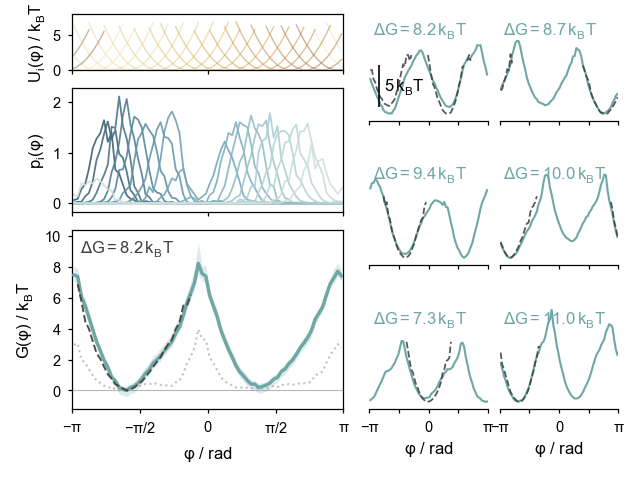

In [47]:
plot_MBAR_target_reconstruction_gallery(
    m_list=m_list,
    showcase_particle=showcase_particle,
    gallery_particles=gallery_particles,
    uncertainty_mode="full",
    uncertainty_interval=(2.5, 97.5),
    center_mode="ensemble",
    bias_potential="cosine",
    overlay_second_umb_in_gallery=False,
    show_gallery_uncertainty=False,
    show_second_umb_uncertainty=False,
    fig_width_mm=100,
    fig_height_mm=76,
    save_dir=save_dir,
    save_prefix="Fig2d_energy_landscape_reconstruction",
)

Saved:
  R:\_06_Umbrella_Sampling\02_Figures\Figure_2\Fig2d_energy_landscape_reconstruction_two_umb.png
  R:\_06_Umbrella_Sampling\02_Figures\Figure_2\Fig2d_energy_landscape_reconstruction_two_umb.svg


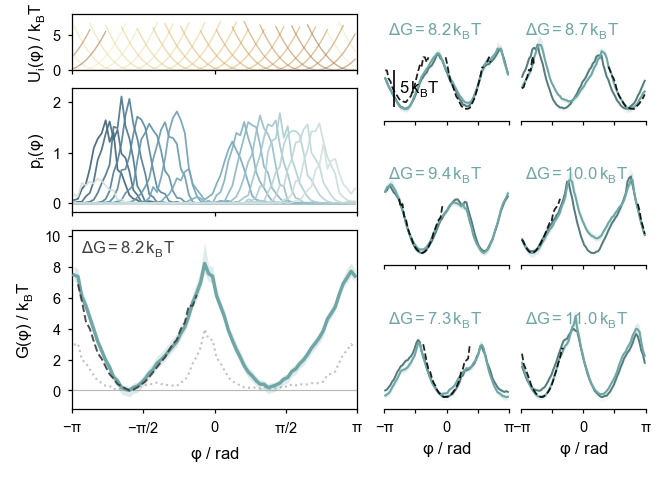

In [48]:
plot_MBAR_target_reconstruction_gallery(
    m_list=m_list,
    showcase_particle=showcase_particle,
    gallery_particles=gallery_particles,
    uncertainty_mode="full",
    uncertainty_interval=(2.5, 97.5),
    center_mode="ensemble",
    bias_potential="cosine",
    overlay_second_umb_in_gallery=True,
    show_gallery_uncertainty=True,
    show_second_umb_uncertainty=True,
    fig_width_mm=105,
    fig_height_mm=76,
    save_dir=r"R:\_06_Umbrella_Sampling\02_Figures\Figure_2",
    save_prefix="Fig2d_energy_landscape_reconstruction_two_umb",
)

## SI | Statistical uncertainty of free-energy landscape reconstruction from finite trajectories

In [49]:
def compute_MBAR_statistical_uncertainty_blocks(
    m_list,
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("target_only", "full"),
    nbins=72,
    pmin_nan=1e-12,
    n_bootstrap=500,
    block_s_target=0.25,
    block_s_calib=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=200,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388/1.14,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Block-bootstrap uncertainty of target-rotor MBAR reconstructions.

    target_only:
        block-bootstrap target trajectories;
        keep the stored point-calibration fixed.

    full:
        block-bootstrap target trajectories;
        block-bootstrap trajectories of the fixed m.calibration_rotors;
        recompute ensemble centers and kappa.

    particles=None:
        analyze all m.target_rotors.

    m_list=m_list:
        analyze every UMB measurement.

    m_list=m_list[1]:
        analyze only the selected UMB measurement.

    Stores
    ------
    m.mbar_statistical_uncertainty_blocks = {
        "evals": evals,
        "summary_long": summary_long,
    }

    Nothing is returned.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    # ------------------------------------------------------------------
    # helpers
    # ------------------------------------------------------------------

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def measurement_name(m):
        return Path(str(getattr(m, "path", "UMB measurement"))).name

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)
        finite = np.isfinite(U) & np.isfinite(U_ref)

        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])
        else:
            U = zero_min(U)

        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))

        return np.squeeze(out) if axis is None else np.squeeze(out, axis=axis)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)
        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2
        out = np.full(values.size, np.nan)

        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]

            if local.size:
                out[i] = np.mean(local)

        return out

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(phase, str) and phase.startswith("deg-") for phase in m.protocol)
        )

        return "DIFF" not in name and ("UMB" in name or has_windows)

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get("start_time", value.get("t_start", value.get("t0"))),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get("t_end", value.get("t1", value.get("stop"))),
                ),
            )

            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt

        else:
            raise KeyError(
                "m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'."
            )

    def lag1(values):
        values = np.asarray(values, dtype=float)

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30

        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1(np.cos(phi)) + lag1(np.sin(phi)))

        return float(np.clip(rho, -0.99, 0.99))

    def collect_target_traces(m, particle, phases):
        ensure_time(m)

        if "group" not in m.locs.columns or "phi" not in m.locs.columns:
            raise KeyError("m.locs needs 'group' and 'phi'.")

        data = m.locs.loc[
            m.locs["group"].astype(int) == int(particle),
            ["phi", "t"],
        ].copy()

        if data.empty:
            raise ValueError(f"Particle {particle}: no localizations.")

        data = data.sort_values("t", kind="mergesort")
        data["phi"] = wrap_pi(data["phi"].to_numpy(float))

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        traces = []

        for phase in phases:
            start, stop = protocol_bounds(m.protocol[str(phase)])
            selected = (data["t"] >= start) & (data["t"] < stop)

            phi = data.loc[selected, "phi"].to_numpy(float)
            t = data.loc[selected, "t"].to_numpy(float)

            if phi.size < min_keep:
                traces.append(None)
                continue

            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
                t = t[n_trim:]

            if phi.size < min_keep:
                traces.append(None)
                continue

            finite = np.isfinite(phi) & np.isfinite(t)
            phi = wrap_pi(phi[finite])
            t = t[finite]

            rho = circular_lag1(phi)
            denominator = 1 + rho
            ess = phi.size * (1 - rho) / denominator if denominator > 1e-12 else float(phi.size)

            if ess < 10:
                traces.append(None)
                continue

            traces.append({
                "phase": str(phase),
                "phi": phi,
                "t": t,
            })

        return traces

    def collect_calibration_traces(m, calibration_rotors, phases):
        ensure_time(m)

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        cache = {}

        for particle in calibration_rotors:
            data = m.locs.loc[
                m.locs["group"].astype(int) == int(particle),
                ["phi", "t"],
            ].copy()

            if data.empty:
                continue

            data = data.sort_values("t", kind="mergesort")
            data["phi"] = wrap_pi(data["phi"].to_numpy(float))

            particle_traces = {}

            for phase in phases:
                start, stop = protocol_bounds(m.protocol[str(phase)])
                selected = (data["t"] >= start) & (data["t"] < stop)

                phi = data.loc[selected, "phi"].to_numpy(float)
                t = data.loc[selected, "t"].to_numpy(float)

                if phi.size > n_trim + 5:
                    phi = phi[n_trim:]
                    t = t[n_trim:]

                finite = np.isfinite(phi) & np.isfinite(t)
                phi = wrap_pi(phi[finite])
                t = t[finite]

                if phi.size >= min_calib_locs_per_window:
                    particle_traces[str(phase)] = {
                        "phi": phi,
                        "t": t,
                    }

            if particle_traces:
                cache[int(particle)] = particle_traces

        return cache

    def block_bootstrap(phi, t, block_s, rng):
        phi = np.asarray(phi, dtype=float)
        t = np.asarray(t, dtype=float)

        if phi.size == 0:
            return phi.copy()

        if phi.size < 3 or block_s is None or block_s <= 0:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        dt = np.nanmedian(np.diff(t)) if t.size > 1 else np.nan

        if not np.isfinite(dt) or dt <= 0:
            block_n = max(1, int(round(phi.size / 10)))
        else:
            block_n = max(1, int(round(float(block_s) / dt)))

        block_n = min(block_n, phi.size)

        starts = np.arange(0, phi.size, block_n, dtype=int)
        blocks = [phi[start:min(start + block_n, phi.size)] for start in starts]

        if len(blocks) == 1:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        n_blocks = int(np.ceil(phi.size / block_n))
        selected = rng.integers(0, len(blocks), size=n_blocks)

        return wrap_pi(np.concatenate([blocks[i] for i in selected])[:phi.size])

    def vm_kappa(phi, center):
        delta = wrap_pi(np.asarray(phi, dtype=float) - float(center))
        delta = delta[np.isfinite(delta)]

        if delta.size == 0:
            return np.nan

        R = np.hypot(np.mean(np.cos(delta)), np.mean(np.sin(delta)))

        if not np.isfinite(R) or R < 1e-8:
            return np.nan

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6

        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / max(1 - R, 1e-12)

        else:
            kappa = 1 / max(R**3 - 4 * R**2 + 3 * R, 1e-12)

        return float(max(kappa, 0))

    def run_mbar(samples, centers, kappa):
        counts = np.asarray([len(sample) for sample in samples], dtype=float)

        if len(samples) < 2:
            raise ValueError("MBAR needs at least two umbrella windows.")

        if np.any(counts <= 0):
            raise ValueError("Empty umbrella window encountered.")

        phi = wrap_pi(np.concatenate(samples))

        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)

        if centers.size != len(samples) or kappa.size != len(samples):
            raise ValueError(
                f"MBAR size mismatch: {len(samples)} samples, "
                f"{centers.size} centers, {kappa.size} kappa values."
            )

        if not np.all(np.isfinite(centers)):
            raise ValueError("Non-finite umbrella center encountered.")

        if not np.all(np.isfinite(kappa) & (kappa > 0)):
            raise ValueError("Non-finite or non-positive kappa encountered.")

        delta = wrap_pi(phi[None, :] - centers[:, None])

        if bias_potential == "cosine":
            u_kn = kappa[:, None] * (1 - np.cos(delta))

        elif bias_potential == "harmonic":
            u_kn = 0.5 * kappa[:, None] * delta**2

        else:
            raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

        log_counts = np.log(counts)
        f_k = np.zeros(len(samples))
        converged = False

        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(
                log_counts[:, None] + f_k[:, None] - u_kn,
                axis=0,
            )

            f_new = np.asarray([
                -logsumexp(-u_kn[i] - log_denominator)
                for i in range(len(f_k))
            ])

            f_new -= f_new[0]
            f_next = (1 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new

            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None] + f_k[:, None] - u_kn,
            axis=0,
        )

        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)

        weights = np.exp(log_weights)

        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        phi_grid = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])

        probability, _ = np.histogram(phi, bins=edges, weights=weights)
        probability = probability.astype(float) / dphi

        normalization = probability.sum() * dphi

        if normalization > 0:
            probability /= normalization

        energy = np.full(probability.size, np.nan)
        positive = probability > 0

        energy[positive] = -np.log(probability[positive])

        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan

        weight_square_sum = np.sum(weights**2)

        return {
            "phi": phi_grid,
            "P": probability,
            "U": zero_min(energy),
            "converged": converged,
            "n_iter": iteration + 1,
            "ess": 1 / weight_square_sum if weight_square_sum > 0 else np.nan,
        }

    def point_parameters(m, phases):
        center_df = m.center_bias["by_window"]
        kappa_df = m.kappa_bias["by_angle"]

        center_column = "ensemble_phi0" if center_mode == "ensemble" else "command_phi0"

        center_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df[center_column].astype(float),
            )
        )

        kappa_map = dict(
            zip(
                kappa_df["phase"].astype(str),
                kappa_df["kappa_mean_used_target"].astype(float),
            )
        )

        centers = np.asarray([center_map[str(phase)] for phase in phases], dtype=float)
        kappa = np.asarray([kappa_map[str(phase)] for phase in phases], dtype=float)

        if str(m.kappa_bias["mode"]) == "global":
            kappa[:] = float(m.kappa_bias["global_target"])

        return wrap_pi(centers), kappa

    def command_centers_for_phases(m, phases):
        center_df = m.center_bias["by_window"]

        command_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df["command_phi0"].astype(float),
            )
        )

        return np.asarray([command_map[str(phase)] for phase in phases], dtype=float)

    def bootstrap_calibration(
        calibration_cache,
        phases,
        command_centers,
        point_centers,
        point_kappa,
        kappa_mode_use,
        rng,
    ):
        n_windows = len(phases)

        centers = np.full(n_windows, np.nan)
        kappa_raw = np.full(n_windows, np.nan)

        for j, phase in enumerate(phases):
            rotor_centers = []
            rotor_kappas = []

            for traces in calibration_cache.values():
                trace = traces.get(str(phase))

                if trace is None:
                    continue

                phi = block_bootstrap(
                    trace["phi"],
                    trace["t"],
                    block_s_calib,
                    rng,
                )

                if phi.size < min_calib_locs_per_window:
                    continue

                rotor_center = circular_mean(phi)

                if not np.isfinite(rotor_center):
                    continue

                rotor_kappa = vm_kappa(phi, rotor_center)

                if np.isfinite(rotor_kappa) and rotor_kappa > 0:
                    rotor_centers.append(rotor_center)
                    rotor_kappas.append(rotor_kappa)

            if rotor_centers:
                centers[j] = circular_mean(rotor_centers)

            if rotor_kappas:
                kappa_raw[j] = np.mean(rotor_kappas)

        missing_center = ~np.isfinite(centers)
        centers[missing_center] = point_centers[missing_center]

        finite_kappa = np.isfinite(kappa_raw) & (kappa_raw > 0)

        if np.any(finite_kappa):
            fill_kappa = np.nanmedian(kappa_raw[finite_kappa])
        else:
            fill_kappa = np.nanmedian(point_kappa / float(kappa_rescale_target))

        kappa_raw[~finite_kappa] = fill_kappa

        if rolling_mean_kappa_ensemble:
            kappa_smoothed = periodic_mean(
                kappa_raw,
                rolling_mean_kappa_window,
            )

            missing = ~np.isfinite(kappa_smoothed) | (kappa_smoothed <= 0)
            kappa_smoothed[missing] = kappa_raw[missing]

            kappa_raw = kappa_smoothed

        if kappa_mode_use == "global":
            kappa_raw[:] = np.nanmean(kappa_raw)

        elif kappa_mode_use != "by_angle":
            raise ValueError(
                "m.kappa_bias['mode'] must be 'global' or 'by_angle'."
            )

        centers_used = centers if center_mode == "ensemble" else command_centers
        kappa_used = kappa_raw * float(kappa_rescale_target)

        return wrap_pi(centers_used), kappa_used

    # ------------------------------------------------------------------
    # modes
    # ------------------------------------------------------------------

    modes = [uncertainty_mode] if isinstance(uncertainty_mode, str) else list(uncertainty_mode)
    modes = [str(mode).lower().replace("-", "_").strip() for mode in modes]

    invalid_modes = [mode for mode in modes if mode not in {"target_only", "full"}]

    if invalid_modes:
        raise ValueError(
            f"Unknown uncertainty modes: {invalid_modes}. "
            "Use 'target_only' and/or 'full'."
        )

    # ------------------------------------------------------------------
    # measurements
    # ------------------------------------------------------------------

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for m in tqdm(
        measurements,
        desc="UMB measurements",
        total=len(measurements),
        dynamic_ncols=True,
    ):
        required = [
            "target_rotors",
            "calibration_rotors",
            "center_bias",
            "kappa_bias",
            "reconstructed_energy_landscapes_by_center",
        ]

        missing = [name for name in required if not hasattr(m, name)]

        if missing:
            raise AttributeError(
                f"{measurement_name(m)}: missing {missing}. "
                "Run run_MBAR_reconstruction(...) first."
            )

        try:
            point_landscapes = (
                m.reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception as error:
            raise KeyError(
                f"{measurement_name(m)}: no stored MBAR reconstruction for "
                f"center_mode={center_mode!r}, bias_potential={bias_potential!r}."
            ) from error

        target_rotors = list(map(int, m.target_rotors))

        if particles is None:
            particles_to_compute = target_rotors.copy()
        else:
            particles_to_compute = [
                int(particle)
                for particle in particles
                if int(particle) in target_rotors
            ]

        particles_to_compute = [
            particle
            for particle in particles_to_compute
            if particle in point_landscapes
        ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors "
                "have a stored point-MBAR reconstruction."
            )

        calibration_rotors = list(map(int, m.calibration_rotors))
        kappa_mode_use = str(m.kappa_bias["mode"])

        evals = {}
        summary_parts = []

        # --------------------------------------------------------------
        # modes
        # --------------------------------------------------------------

        for mode in modes:
            curves = {}
            rows = []

            for particle in tqdm(
                particles_to_compute,
                desc=f"{mode} | target rotors",
                total=len(particles_to_compute),
                leave=False,
                dynamic_ncols=True,
            ):
                try:
                    reference_df = point_landscapes[int(particle)]

                    phi_ref = reference_df["phi"].to_numpy(float)
                    U_ref = zero_min(reference_df["U_mbar"].to_numpy(float))
                    P_ref = reference_df["P_mbar"].to_numpy(float)

                    all_phases = m.center_bias["by_window"]["phase"].astype(str).tolist()

                    target_traces = collect_target_traces(
                        m,
                        particle,
                        all_phases,
                    )

                    keep = np.asarray(
                        [trace is not None for trace in target_traces],
                        dtype=bool,
                    )

                    if np.sum(keep) < 3:
                        raise ValueError(
                            "Fewer than three valid target umbrella windows."
                        )

                    phases = [
                        phase
                        for phase, keep_window in zip(all_phases, keep)
                        if keep_window
                    ]

                    target_traces = [
                        trace
                        for trace in target_traces
                        if trace is not None
                    ]

                    point_centers, point_kappa = point_parameters(
                        m,
                        phases,
                    )

                    command_centers = command_centers_for_phases(
                        m,
                        phases,
                    )

                    calibration_cache = {}

                    if mode == "full":
                        calibration_cache = collect_calibration_traces(
                            m,
                            calibration_rotors,
                            phases,
                        )

                        if not calibration_cache:
                            raise ValueError(
                                "No usable calibration trajectories."
                            )

                    U_boot = []
                    kappa_boot = []
                    phi0_boot = []
                    ess_boot = []
                    n_iter_boot = []

                    n_failed = 0
                    first_error = None

                    rng = np.random.default_rng(
                        seed
                        + 100000 * modes.index(mode)
                        + int(particle)
                    )

                    for _ in tqdm(
                        range(int(n_bootstrap)),
                        desc=f"particle {particle}",
                        total=int(n_bootstrap),
                        leave=False,
                        dynamic_ncols=True,
                    ):
                        try:
                            target_samples = [
                                block_bootstrap(
                                    trace["phi"],
                                    trace["t"],
                                    block_s_target,
                                    rng,
                                )
                                for trace in target_traces
                            ]

                            if mode == "full":
                                centers, kappa = bootstrap_calibration(
                                    calibration_cache=calibration_cache,
                                    phases=phases,
                                    command_centers=command_centers,
                                    point_centers=point_centers,
                                    point_kappa=point_kappa,
                                    kappa_mode_use=kappa_mode_use,
                                    rng=rng,
                                )

                            else:
                                centers = point_centers.copy()
                                kappa = point_kappa.copy()

                            result = run_mbar(
                                samples=target_samples,
                                centers=centers,
                                kappa=kappa,
                            )

                            U_boot.append(
                                align_to_reference(
                                    result["U"],
                                    U_ref,
                                )
                            )

                            kappa_boot.append(kappa.copy())
                            phi0_boot.append(centers.copy())
                            ess_boot.append(result["ess"])
                            n_iter_boot.append(result["n_iter"])

                        except Exception as error:
                            n_failed += 1

                            if first_error is None:
                                first_error = f"{type(error).__name__}: {error}"

                    if not U_boot:
                        raise RuntimeError(
                            f"All bootstrap replicates failed for particle "
                            f"{particle}, mode {mode}. "
                            f"First bootstrap error: {first_error}"
                        )

                    U_boot = np.asarray(U_boot, dtype=float)
                    kappa_boot = np.asarray(kappa_boot, dtype=float)
                    phi0_boot = np.asarray(phi0_boot, dtype=float)

                    q_low, q_high = map(float, ci)

                    U_median, U_low, U_high = np.nanpercentile(
                        U_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    U_std = np.nanstd(
                        U_boot,
                        axis=0,
                        ddof=1,
                    )

                    kappa_median, kappa_low, kappa_high = np.nanpercentile(
                        kappa_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    phi0_delta = wrap_pi(
                        phi0_boot
                        - point_centers[None, :]
                    )

                    phi0_median, phi0_low, phi0_high = np.nanpercentile(
                        phi0_delta,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    finite = np.isfinite(U_ref)

                    G_range = (
                        np.nanmax(U_ref[finite])
                        - np.nanmin(U_ref[finite])
                        if np.any(finite)
                        else np.nan
                    )

                    sigma_mean = float(np.nanmean(U_std))
                    sigma_p90 = float(np.nanpercentile(U_std, 90))
                    ci_width_mean = float(np.nanmean(U_high - U_low))

                    landscape_df = pd.DataFrame({
                        "particle": int(particle),
                        "phi": phi_ref,
                        "U_MBAR_point": U_ref,
                        "P_MBAR_point": P_ref,
                        "U_boot_median": U_median,
                        "U_boot_low": U_low,
                        "U_boot_high": U_high,
                        "U_boot_std": U_std,
                    })

                    calibration_df = pd.DataFrame({
                        "phase": phases,
                        "phi0_point": point_centers,
                        "phi0_delta_median": phi0_median,
                        "phi0_delta_low": phi0_low,
                        "phi0_delta_high": phi0_high,
                        "phi0_delta_median_deg": np.rad2deg(phi0_median),
                        "phi0_delta_low_deg": np.rad2deg(phi0_low),
                        "phi0_delta_high_deg": np.rad2deg(phi0_high),
                        "kappa_point": point_kappa,
                        "kappa_boot_median": kappa_median,
                        "kappa_boot_low": kappa_low,
                        "kappa_boot_high": kappa_high,
                    })

                    curves[int(particle)] = {
                        "landscape_df": landscape_df,
                        "calibration_df": calibration_df,
                        "U_boot_curves": U_boot,
                        "kappa_boot_curves": kappa_boot,
                        "phi0_boot_curves": phi0_boot,
                        "phase_list": phases,
                        "calib_particles": calibration_rotors,
                    }

                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "ok",
                        "error": "",
                        "n_bootstrap_requested": int(n_bootstrap),
                        "n_bootstrap_success": int(len(U_boot)),
                        "n_bootstrap_failed": int(n_failed),
                        "G_range_MBAR_kBT": float(G_range),
                        "sigma_G_mean_kBT": sigma_mean,
                        "sigma_G_p90_kBT": sigma_p90,
                        "CI_width_G_mean_kBT": ci_width_mean,
                        "relative_sigma_G_mean": (
                            sigma_mean / G_range
                            if np.isfinite(G_range) and G_range > 0
                            else np.nan
                        ),
                        "bootstrap_ESS_median": float(np.nanmedian(ess_boot)),
                        "bootstrap_n_iter_median": float(np.nanmedian(n_iter_boot)),
                        "n_target_locs_total": int(
                            sum(len(trace["phi"]) for trace in target_traces)
                        ),
                        "n_windows": int(len(phases)),
                        "n_calibration_rotors": int(len(calibration_rotors)),
                    })

                except Exception as error:
                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "failed",
                        "error": f"{type(error).__name__}: {error}",
                    })

            summary_df = pd.DataFrame(rows)

            evals[mode] = {
                "curves": curves,
                "summary_df": summary_df,
            }

            summary_parts.append(summary_df)

        m.mbar_statistical_uncertainty_blocks = {
            "evals": evals,
            "summary_long": pd.concat(
                summary_parts,
                ignore_index=True,
            ),
        }

    return None

In [50]:
compute_MBAR_statistical_uncertainty_blocks(
    m_list=m_list[1],
    particles=particles,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("target_only", "full"),
    nbins=72,
    n_bootstrap=2,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388/1.14,
    mbar_tol=1e-5,
    mbar_max_iter=300,

)

UMB measurements:   0%|                                                                          | 0/1 [00:00<…

target_only | target rotors:   0%|                                                              | 0/56 [00:00<…

particle 0:   0%|                                                                                | 0/2 [00:00<…

particle 4:   0%|                                                                                | 0/2 [00:00<…

particle 9:   0%|                                                                                | 0/2 [00:00<…

particle 11:   0%|                                                                               | 0/2 [00:00<…

... (126 outputs left out)

particle 222:   0%|                                                                              | 0/2 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 230:   0%|                                                                              | 0/2 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


#### iii. Plot reconstruction gallery

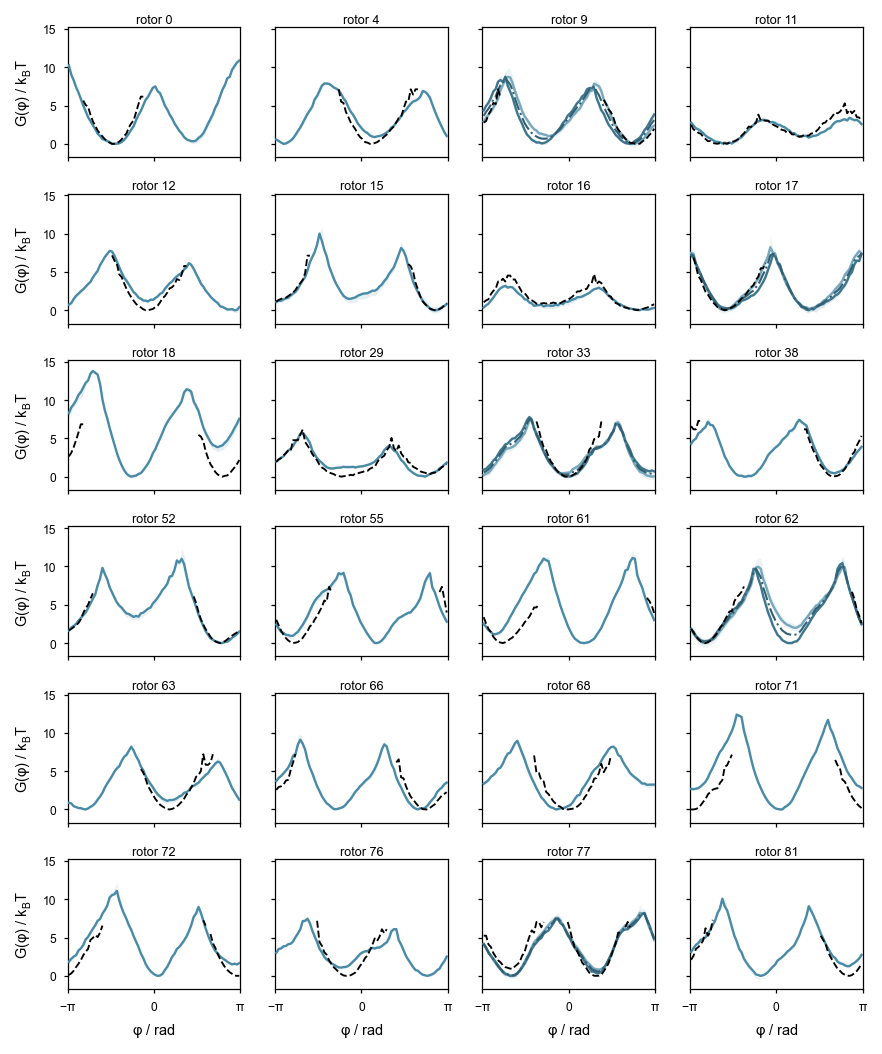

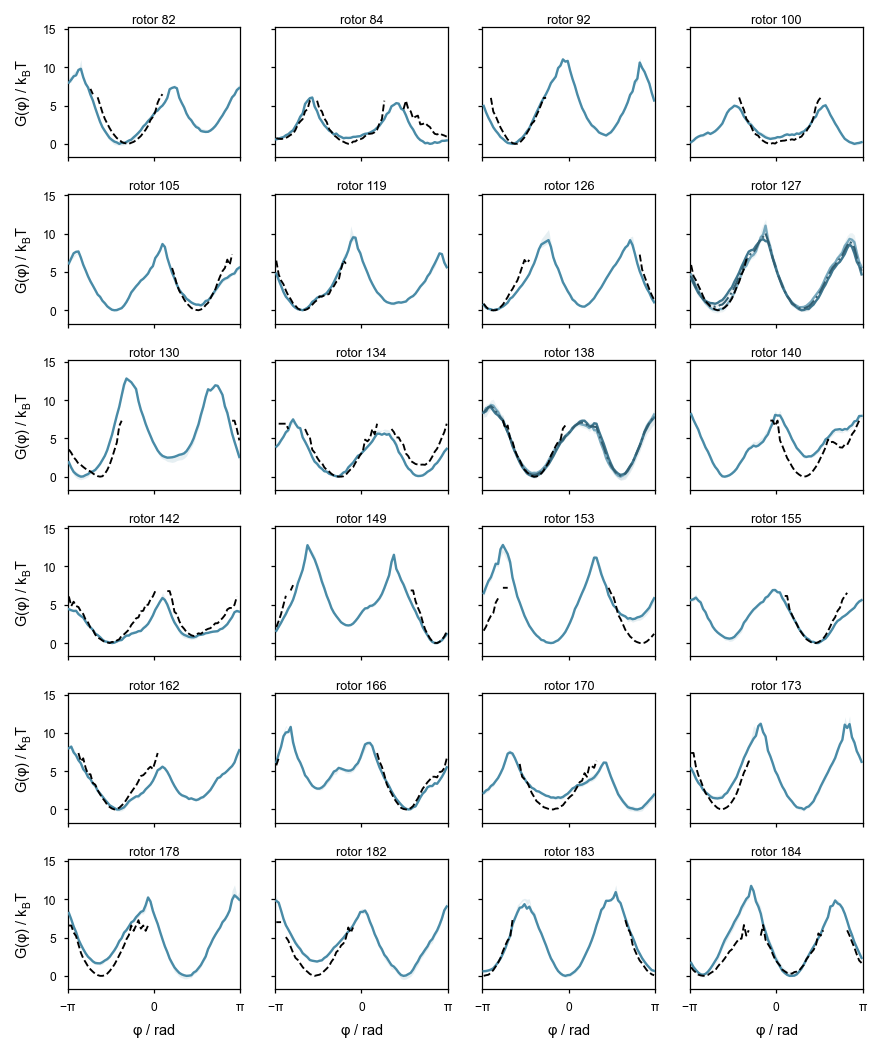

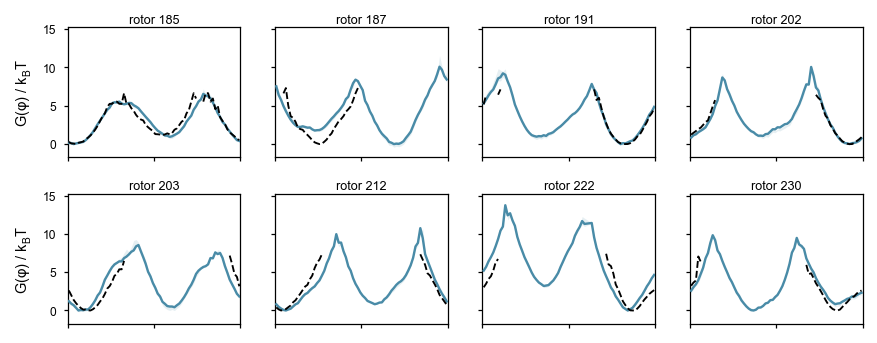

In [51]:
# # 3. Target-trajectory block-bootstrap uncertainty
# plot_MBAR_reconstruction_gallery(
#     m_list=m_list,
#     display_mode="bootstrap_target",
#     particles=None,
#     split_target_other=True,
#     show_diff=True,
#     show_mean_across_measurements=True,
#     ncols=4,
#     nrows_per_page=6,
#     shared_ylim=True,
# )

# 4. Full block-bootstrap uncertainty
plot_MBAR_reconstruction_gallery(
    m_list=m_list,
    display_mode="bootstrap_full",
    particles=particles,
    split_target_other=True,
    show_diff=True,
    show_mean_across_measurements=True,
    ncols=4,
    nrows_per_page=6,
    shared_ylim=True,
)

#### iii. SI | Statistical uncertainty from finite sampling

In [52]:
def plot_MBAR_statistical_uncertainty_SI(
    m_list,
    measurement_indices=(0, 1),
    particles=None,
    example_particles=None,
    example_indices=(0, 1),
    uncertainty_modes=("target_only", "full"),
    landscape_uncertainty_mode="full",
    z_uncertainty_mode="full",
    ci=(2.5, 97.5),
    particle_col="group",
    phi_col="phi",
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    diff_pmin=1e-12,
    metric_ylims=((0, 0.60), (0, 0.65), (0, 5.0)),
    local_uncertainty_ylim=None,
    panel_labels=("a", "b", "c", "d", "e"),
    fig_width_mm=180,
    fig_height_mm=78,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=10,
    point_lw=1.10,
    diff_lw=0.85,
    target_band_alpha=0.33,
    full_band_alpha=0.33,
    target_uncertainty_lw=0.90,
    full_uncertainty_lw=1.05,
    marker_size=2.6,
    strip_jitter=0.085,
    box_width=0.38,
    box_alpha=0.48,
    n_y_ticks=(5, 5, 5),
    row_hspace=0.10,
    outer_wspace=0.46,
    save_dir=None,
    save_prefix="SI_MBAR_statistical_uncertainty",
    stator_variant=None,
    C=None,
    dpi=300,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator, FuncFormatter, NullLocator

    def flatten(x):
        if x is None: return []
        return [v for y in x for v in flatten(y)] if isinstance(x, (list, tuple)) else [x]

    def wrap_pi(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def rgb(x):
        x = np.asarray(x, float).ravel()[:3]
        return tuple(x / 255 if np.nanmax(x) > 1 else x)

    def mm(x):
        return float(x) / 25.4

    def is_diff(m):
        return "DIFF" in str(getattr(m, "path", "")).upper()

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def get_particle(mapping, particle):
        if not isinstance(mapping, dict): return None
        return mapping.get(int(particle), mapping.get(str(int(particle))))

    def zero_min(y):
        y = np.asarray(y, float).copy()
        finite = np.isfinite(y)
        if np.any(finite): y[finite] -= np.nanmin(y[finite])
        return y

    def compact_tick(value, _):
        if not np.isfinite(value): return ""
        if abs(value) < 1e-12: return "0"
        if abs(value - round(value)) < 1e-10: return str(int(round(value)))
        return f"{value:.2f}".rstrip("0").rstrip(".")

    def find_extrema(phi, energy, minimum=True):
        phi, energy = np.asarray(phi, float), np.asarray(energy, float)
        if len(energy) < 3: return np.array([], dtype=int)

        left, right = np.roll(energy, 1), np.roll(energy, -1)
        idx = np.where((energy <= left) & (energy <= right))[0] if minimum else np.where(
            (energy >= left) & (energy >= right)
        )[0]

        if not idx.size: idx = np.arange(len(energy))
        idx = idx[np.argsort(energy[idx] if minimum else -energy[idx])]

        chosen, min_sep = [], np.deg2rad(float(min_extrema_separation_deg))
        for j in idx:
            if all(abs(wrap_pi(phi[j] - phi[k])) >= min_sep for k in chosen):
                chosen.append(int(j))
            if len(chosen) == 2: break

        return np.asarray(chosen, dtype=int)

    def region_mask(phi, center):
        return np.abs(wrap_pi(np.asarray(phi, float) - float(center))) <= np.deg2rad(
            float(angular_cutoff_deg)
        )

    def identify_regions(phi, point_energy):
        phi, point_energy = np.asarray(phi, float), np.asarray(point_energy, float)
        finite = np.isfinite(phi) & np.isfinite(point_energy)
        if np.sum(finite) < 5: return None

        valid_idx = np.where(finite)[0]
        well_local = find_extrema(phi[finite], point_energy[finite], minimum=True)
        barrier_local = find_extrema(phi[finite], point_energy[finite], minimum=False)

        if len(well_local) < 2 or len(barrier_local) < 2: return None

        well_idx, barrier_idx = valid_idx[well_local], valid_idx[barrier_local]
        well_idx, barrier_idx = well_idx[np.argsort(phi[well_idx])], barrier_idx[np.argsort(phi[barrier_idx])]

        well_masks = [finite & region_mask(phi, phi[j]) for j in well_idx]
        barrier_masks = [finite & region_mask(phi, phi[j]) for j in barrier_idx]

        return {
            "well_indices": well_idx,
            "barrier_indices": barrier_idx,
            "well_centers": phi[well_idx],
            "barrier_centers": phi[barrier_idx],
            "well_masks": well_masks,
            "barrier_masks": barrier_masks,
            "combined_well_mask": well_masks[0] | well_masks[1],
        }

    def barrier_heights(curves, regions):
        curves = np.asarray(curves, float)
        if curves.ndim == 1: curves = curves[None, :]

        heights = np.full((curves.shape[0], 2), np.nan)
        well_region = regions["combined_well_mask"]

        for i, energy in enumerate(curves):
            valid_well = well_region & np.isfinite(energy)
            if not np.any(valid_well): continue

            well_reference = np.nanmean(energy[valid_well])

            for j, barrier_region in enumerate(regions["barrier_masks"]):
                valid_barrier = barrier_region & np.isfinite(energy)
                if np.any(valid_barrier):
                    heights[i, j] = np.nanmean(energy[valid_barrier]) - well_reference

        return heights

    def match_two_barriers(centers1, centers2):
        centers1, centers2 = np.asarray(centers1, float), np.asarray(centers2, float)

        same = (
            abs(wrap_pi(centers1[0] - centers2[0]))
            + abs(wrap_pi(centers1[1] - centers2[1]))
        )
        swapped = (
            abs(wrap_pi(centers1[0] - centers2[1]))
            + abs(wrap_pi(centers1[1] - centers2[0]))
        )

        return np.array([0, 1], int) if same <= swapped else np.array([1, 0], int)

    def collect_diff_phi(diff_measurements, particle):
        values = []

        for m in diff_measurements:
            if not hasattr(m, "locs") or not isinstance(m.locs, pd.DataFrame):
                continue
            if phi_col not in m.locs.columns:
                continue

            group_col = particle_col if particle_col in m.locs.columns else (
                "group_int" if "group_int" in m.locs.columns else None
            )
            if group_col is None:
                continue

            phi = m.locs.loc[
                m.locs[group_col].astype(int) == int(particle),
                phi_col,
            ].to_numpy(float)

            phi = wrap_pi(phi[np.isfinite(phi)])
            if phi.size: values.append(phi)

        return np.concatenate(values) if values else np.array([], float)

    def diff_energy(diff_measurements, particle, phi_grid):
        samples = collect_diff_phi(diff_measurements, particle)
        if not samples.size: return np.full_like(phi_grid, np.nan, dtype=float)

        edges = np.linspace(-np.pi, np.pi, len(phi_grid) + 1)
        counts, _ = np.histogram(samples, bins=edges)
        probability = counts.astype(float) / max(
            np.sum(counts) * (edges[1] - edges[0]),
            1e-300,
        )

        energy = np.full(len(phi_grid), np.nan)
        keep = counts > 0
        energy[keep] = -np.log(np.maximum(probability[keep], 1e-300))
        energy[probability < float(diff_pmin)] = np.nan

        return zero_min(energy)

    def pull_entry(m, mode, particle):
        stored = getattr(m, "mbar_statistical_uncertainty_blocks", None)
        if not isinstance(stored, dict): return None

        evals = stored.get("evals", {})
        if not isinstance(evals, dict): return None

        mode_data = evals.get(str(mode), {})
        if not isinstance(mode_data, dict): return None

        return get_particle(mode_data.get("curves", {}), particle)

    def extract_entry(entry):
        if not isinstance(entry, dict) or "landscape_df" not in entry: return None

        df = entry["landscape_df"]
        if not isinstance(df, pd.DataFrame): return None
        if not {"phi", "U_MBAR_point"}.issubset(df.columns): return None

        phi = df["phi"].to_numpy(float)
        point = df["U_MBAR_point"].to_numpy(float)
        boot = np.asarray(entry.get("U_boot_curves", []), float)

        if boot.ndim != 2 or boot.shape[0] < 2 or boot.shape[1] != len(phi):
            return None

        return {"phi": phi, "point": point, "boot": boot}

    def percentile_band(boot):
        boot = np.asarray(boot, float)
        low = np.full(boot.shape[1], np.nan)
        high = np.full(boot.shape[1], np.nan)

        valid_bins = np.any(np.isfinite(boot), axis=0)
        if np.any(valid_bins):
            low[valid_bins], high[valid_bins] = np.nanpercentile(
                boot[:, valid_bins],
                [q_low, q_high],
                axis=0,
            )

        return low, high

    def style_energy_axis(ax, bottom=False):
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)

        ax.spines["bottom"].set_linewidth(0.6)
        ax.spines["bottom"].set_color(black)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])

        if bottom:
            ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
            ax.set_xlabel(r"$\varphi$ / rad", labelpad=1)
        else:
            ax.set_xticklabels([])

        ax.set_yticks([])
        ax.set_ylabel("")
        ax.tick_params(axis="x", length=2, width=0.6, colors=black, labelsize=tick_label_size, pad=1.5)
        ax.tick_params(axis="y", length=0, width=0, labelleft=False)
        ax.grid(False)

    def style_uncertainty_axis(ax, bottom=False):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])

        if bottom:
            ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
            ax.set_xlabel(r"$\varphi$ / rad", labelpad=1)
        else:
            ax.set_xticklabels([])

        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3))
        ax.yaxis.set_major_formatter(FuncFormatter(compact_tick))
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.tick_params(length=2, width=0.6, colors=black, labelsize=tick_label_size, pad=1.5)
        ax.grid(False)

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

    def style_summary_axis(ax, ylim, n_ticks):
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_locator(MaxNLocator(nbins=int(n_ticks), min_n_ticks=4))
        ax.yaxis.set_major_formatter(FuncFormatter(compact_tick))
        ax.tick_params(length=2, width=0.6, colors=black, labelsize=tick_label_size, pad=1.5)

        if ylim is not None:
            ax.set_ylim(*ylim)

        ax.grid(False)

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

    def add_scalebar(ax, height=5):
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()

        x = x0 + 0.06 * (x1 - x0)
        bottom = y0 + 0.14 * (y1 - y0)
        top = min(bottom + height, y1 - 0.05 * (y1 - y0))
        bottom = top - height

        ax.plot([x, x], [bottom, top], color=black, lw=0.8, clip_on=False, zorder=10)
        ax.text(
            x + 0.035 * (x1 - x0),
            0.5 * (bottom + top),
            rf"${height:g}\,k_\mathrm{{B}}T$",
            ha="left",
            va="center",
            fontsize=annotation_size,
            color=black,
        )

    def paired_mode_values(frame, value_column, include_barrier=False):
        keys = ["measurement", "particle"]
        if include_barrier:
            keys.append("barrier")

        target = frame.loc[
            frame["uncertainty_mode"].eq("target_only"),
            keys + [value_column],
        ].rename(columns={value_column: "target"})

        full = frame.loc[
            frame["uncertainty_mode"].eq("full"),
            keys + [value_column],
        ].rename(columns={value_column: "full"})

        paired = target.merge(full, on=keys, how="inner")
        target_values = paired["target"].to_numpy(float)
        full_values = paired["full"].to_numpy(float)

        finite = np.isfinite(target_values) & np.isfinite(full_values)
        return target_values[finite], full_values[finite]

    def add_box_strip(ax, target_values, full_values, rng):
        target_values = np.asarray(target_values, float)
        full_values = np.asarray(full_values, float)

        jitter_target = rng.uniform(-strip_jitter, strip_jitter, len(target_values))
        jitter_full = rng.uniform(-strip_jitter, strip_jitter, len(full_values))

        ax.scatter(
            jitter_target,
            target_values,
            s=marker_size**2,
            color=target_box_color,
            edgecolor=black,
            linewidth=0.35,
            alpha=0.75,
            zorder=2,
        )

        ax.scatter(
            1 + jitter_full,
            full_values,
            s=marker_size**2,
            color=full_box_color,
            edgecolor=black,
            linewidth=0.35,
            alpha=0.75,
            zorder=2,
        )

        if not len(target_values):
            return

        box = ax.boxplot(
            [target_values, full_values],
            positions=[0, 1],
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": black, "linewidth": 1.0},
            whiskerprops={"color": black, "linewidth": 0.7},
            capprops={"color": black, "linewidth": 0.7},
            boxprops={"color": black, "linewidth": 0.7},
            zorder=4,
        )

        box["boxes"][0].set_facecolor(target_box_color)
        box["boxes"][1].set_facecolor(full_box_color)

        for patch in box["boxes"]:
            patch.set_alpha(box_alpha)

        for item in box["whiskers"] + box["caps"] + box["medians"]:
            item.set_zorder(5)

    modes = tuple(str(mode).lower().replace("-", "_").strip() for mode in uncertainty_modes)

    if "target_only" not in modes or "full" not in modes:
        raise ValueError("uncertainty_modes must contain 'target_only' and 'full'.")

    landscape_uncertainty_mode = str(landscape_uncertainty_mode).lower().replace("-", "_").strip()
    z_uncertainty_mode = str(z_uncertainty_mode).lower().replace("-", "_").strip()

    if landscape_uncertainty_mode not in modes:
        raise ValueError("landscape_uncertainty_mode must be included in uncertainty_modes.")

    if z_uncertainty_mode not in modes:
        raise ValueError("z_uncertainty_mode must be included in uncertainty_modes.")

    if metric_ylims is None:
        metric_ylims = (None, None, None)

    if len(metric_ylims) != 3:
        raise ValueError("metric_ylims must contain three entries.")

    if np.isscalar(n_y_ticks):
        n_y_ticks = (int(n_y_ticks),) * 3

    q_low, q_high = map(float, ci)

    C = {} if C is None else (C() if callable(C) else dict(C))
    black = rgb(C.get("black", (0, 0, 0)))
    grey = rgb(C.get("midgrey", (0.45, 0.45, 0.45)))

    point_color = (46 / 255, 89 / 255, 108 / 255)
    target_color = (111 / 255, 166 / 255, 166 / 255)
    full_color = (46 / 255, 89 / 255, 108 / 255)
    target_box_color = (167 / 255, 197 / 255, 197 / 255)
    full_box_color = (46 / 255, 89 / 255, 108 / 255)

    measurements = flatten(m_list)
    umb_measurements = [m for m in measurements if is_umb(m)]
    diff_measurements = [m for m in measurements if is_diff(m)]

    i1, i2 = map(int, measurement_indices)

    if not (0 <= i1 < len(umb_measurements) and 0 <= i2 < len(umb_measurements)):
        raise IndexError(
            f"measurement_indices={measurement_indices} are invalid for "
            f"{len(umb_measurements)} UMB measurements."
        )

    selected_measurements = [umb_measurements[i1], umb_measurements[i2]]
    requested_particles = None if particles is None else {int(p) for p in particles}

    available_by_measurement = []

    for m in selected_measurements:
        available_modes = []

        for mode in modes:
            stored = getattr(m, "mbar_statistical_uncertainty_blocks", {})
            evals = stored.get("evals", {}) if isinstance(stored, dict) else {}
            curves = evals.get(mode, {}).get("curves", {}) if isinstance(evals, dict) else {}
            available_modes.append({int(p) for p in curves.keys()})

        available_by_measurement.append(
            set.intersection(*available_modes) if available_modes else set()
        )

    common_particles = sorted(
        set.intersection(*available_by_measurement)
        if available_by_measurement else set()
    )

    if requested_particles is not None:
        common_particles = [p for p in common_particles if p in requested_particles]

    if not common_particles:
        availability = []

        for measurement_number, m in enumerate(selected_measurements, start=1):
            stored = getattr(m, "mbar_statistical_uncertainty_blocks", {})
            evals = stored.get("evals", {}) if isinstance(stored, dict) else {}

            counts = {
                mode: len(evals.get(mode, {}).get("curves", {}))
                for mode in modes
            }

            availability.append(f"replica {measurement_number}: {counts}")

        raise ValueError(
            "No particles have usable target_only and full bootstrap results "
            "in both selected replicas.\n" + "\n".join(availability)
        )

    landscape_rows = []
    barrier_rows = []
    particle_data = {}

    for measurement_number, m in enumerate(selected_measurements, start=1):
        for particle in common_particles:
            entries = {}

            for mode in modes:
                entry = extract_entry(pull_entry(m, mode, particle))
                if entry is not None:
                    entries[mode] = entry

            if not all(mode in entries for mode in modes):
                continue

            regions = identify_regions(
                entries["full"]["phi"],
                entries["full"]["point"],
            )

            if regions is None:
                continue

            mode_results = {}

            for mode in modes:
                data = entries[mode]
                low, high = percentile_band(data["boot"])
                half_width_phi = 0.5 * (high - low)

                barrier_boot = barrier_heights(data["boot"], regions)
                barrier_point = barrier_heights(data["point"], regions)[0]

                mode_results[mode] = {
                    **data,
                    "low": low,
                    "high": high,
                    "half_width_phi": half_width_phi,
                    "barrier_boot": barrier_boot,
                    "barrier_point": barrier_point,
                    "regions": regions,
                }

                landscape_rows.append({
                    "measurement": measurement_number,
                    "particle": int(particle),
                    "uncertainty_mode": mode,
                    "mean_CI_half_width_kBT": float(np.nanmean(half_width_phi)),
                })

                for barrier_index in range(2):
                    values = barrier_boot[:, barrier_index]
                    values = values[np.isfinite(values)]

                    if len(values):
                        b_low, b_high = np.percentile(values, [q_low, q_high])
                        b_std = np.std(values, ddof=1) if len(values) > 1 else np.nan
                    else:
                        b_low = b_high = b_std = np.nan

                    barrier_rows.append({
                        "measurement": measurement_number,
                        "particle": int(particle),
                        "barrier": barrier_index + 1,
                        "uncertainty_mode": mode,
                        "barrier_CI_half_width_kBT": float(0.5 * (b_high - b_low)),
                        "barrier_boot_std_kBT": float(b_std),
                    })

            particle_data[(measurement_number, int(particle))] = mode_results

    if not landscape_rows:
        raise ValueError("No usable uncertainty landscapes could be assembled.")

    landscape_df = pd.DataFrame(landscape_rows)
    barrier_df = pd.DataFrame(barrier_rows)

    valid_particles = sorted(
        set(
            landscape_df.loc[
                landscape_df["measurement"].eq(1),
                "particle",
            ].astype(int)
        )
        & set(
            landscape_df.loc[
                landscape_df["measurement"].eq(2),
                "particle",
            ].astype(int)
        )
    )

    valid_particles = [
        p for p in valid_particles
        if (1, p) in particle_data
        and (2, p) in particle_data
        and all(mode in particle_data[(1, p)] for mode in modes)
        and all(mode in particle_data[(2, p)] for mode in modes)
    ]

    if not valid_particles:
        raise ValueError("No particle has valid uncertainty results in both replicas.")

    replica_z_values = []

    for particle in valid_particles:
        data1 = particle_data[(1, particle)][z_uncertainty_mode]
        data2 = particle_data[(2, particle)][z_uncertainty_mode]

        order2 = match_two_barriers(
            data1["regions"]["barrier_centers"],
            data2["regions"]["barrier_centers"],
        )

        point1 = data1["barrier_point"]
        point2 = data2["barrier_point"][order2]
        boot1 = data1["barrier_boot"]
        boot2 = data2["barrier_boot"][:, order2]

        for barrier_index in range(2):
            values1 = boot1[:, barrier_index]
            values2 = boot2[:, barrier_index]

            values1 = values1[np.isfinite(values1)]
            values2 = values2[np.isfinite(values2)]

            if len(values1) < 2 or len(values2) < 2:
                continue

            std1 = np.std(values1, ddof=1)
            std2 = np.std(values2, ddof=1)
            combined_std = np.sqrt(std1**2 + std2**2)

            if (
                np.isfinite(combined_std)
                and combined_std > 0
                and np.isfinite(point1[barrier_index])
                and np.isfinite(point2[barrier_index])
            ):
                replica_z_values.append(
                    abs(point1[barrier_index] - point2[barrier_index]) / combined_std
                )

    available_examples = [
        p for p in valid_particles
        if (1, p) in particle_data
        and "target_only" in particle_data[(1, p)]
        and "full" in particle_data[(1, p)]
    ]

    if example_particles is None:
        example_particles = [
            available_examples[int(i)]
            for i in example_indices
            if 0 <= int(i) < len(available_examples)
        ]
    else:
        example_particles = [
            int(p) for p in example_particles
            if int(p) in available_examples
        ]

    if len(example_particles) < 2:
        example_particles += [
            p for p in available_examples
            if p not in example_particles
        ][:2 - len(example_particles)]

    example_particles = example_particles[:2]

    if len(example_particles) != 2:
        raise ValueError("Two valid exemplary particles are required.")

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = gridspec.GridSpec(
        1,
        5,
        figure=fig,
        left=0.045,
        right=0.995,
        bottom=0.13,
        top=0.965,
        width_ratios=(1.2, 1.2, 0.54, 0.54, 0.58),
        wspace=outer_wspace,
    )

    landscape_grid = gridspec.GridSpecFromSubplotSpec(
        2,
        1,
        subplot_spec=outer[0],
        hspace=row_hspace,
    )

    uncertainty_grid = gridspec.GridSpecFromSubplotSpec(
        2,
        1,
        subplot_spec=outer[1],
        hspace=row_hspace,
    )

    ax_landscape = [
        fig.add_subplot(landscape_grid[0]),
        fig.add_subplot(landscape_grid[1]),
    ]

    ax_uncertainty = [
        fig.add_subplot(uncertainty_grid[0]),
        fig.add_subplot(uncertainty_grid[1]),
    ]

    ax_landscape_summary = fig.add_subplot(outer[2])
    ax_barrier_summary = fig.add_subplot(outer[3])
    ax_zscore = fig.add_subplot(outer[4])

    landscape_arrays = []
    uncertainty_arrays = []

    for particle in example_particles:
        data = particle_data[(1, int(particle))]
        landscape = data[landscape_uncertainty_mode]
        full = data["full"]
        target = data["target_only"]
        Gdiff = diff_energy(diff_measurements, particle, landscape["phi"])

        landscape_arrays.extend([
            np.asarray(landscape["point"], float),
            np.asarray(landscape["low"], float),
            np.asarray(landscape["high"], float),
            np.asarray(Gdiff, float),
        ])

        uncertainty_arrays.extend([
            np.asarray(target["half_width_phi"], float),
            np.asarray(full["half_width_phi"], float),
        ])

    finite_landscape = [
        values[np.isfinite(values)]
        for values in landscape_arrays
        if values.size and np.any(np.isfinite(values))
    ]

    if not finite_landscape:
        raise ValueError("No finite exemplary landscape values are available.")

    finite_landscape = np.concatenate(finite_landscape)
    landscape_span = max(
        float(np.nanmax(finite_landscape) - np.nanmin(finite_landscape)),
        1.0,
    )

    landscape_ylim = (
        float(np.nanmin(finite_landscape) - 0.03 * landscape_span),
        float(np.nanmax(finite_landscape) + 0.04 * landscape_span),
    )

    if local_uncertainty_ylim is None:
        finite_uncertainty = [
            values[np.isfinite(values)]
            for values in uncertainty_arrays
            if values.size and np.any(np.isfinite(values))
        ]

        if finite_uncertainty:
            finite_uncertainty = np.concatenate(finite_uncertainty)
            local_uncertainty_ylim = (
                0,
                max(0.1, 1.05 * float(np.nanmax(finite_uncertainty))),
            )
        else:
            local_uncertainty_ylim = (0, 1)

    roman_labels = ("i", "ii")

    for row, particle in enumerate(example_particles):
        data = particle_data[(1, int(particle))]
        landscape = data[landscape_uncertainty_mode]
        full = data["full"]
        target = data["target_only"]
        phi = landscape["phi"]
        Gdiff = diff_energy(diff_measurements, particle, phi)

        ax = ax_landscape[row]
        landscape_color = full_color if landscape_uncertainty_mode == "full" else target_color
        landscape_band_alpha = full_band_alpha if landscape_uncertainty_mode == "full" else target_band_alpha
        landscape_label = "full 95% CI" if landscape_uncertainty_mode == "full" else "target-only 95% CI"

        ax.fill_between(
            phi,
            landscape["low"],
            landscape["high"],
            color=landscape_color,
            alpha=landscape_band_alpha,
            linewidth=0,
            label=landscape_label if row == 0 else None,
            zorder=1,
        )

        ax.plot(
            phi,
            landscape["point"],
            color=point_color,
            lw=point_lw,
            label="MBAR" if row == 0 else None,
            zorder=4,
        )

        ax.plot(
            phi,
            Gdiff,
            color=black,
            lw=diff_lw,
            ls="--",
            label="bias-free" if row == 0 else None,
            zorder=3,
        )

        ax.set_ylim(*landscape_ylim)
        style_energy_axis(ax, bottom=row == 1)

        ax.text(
            0.025,
            0.93,
            f"rotor {roman_labels[row]}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=annotation_size,
            color=black,
        )

        if row == 0:
            add_scalebar(ax, height=5)

            ax.legend(
                frameon=False,
                fontsize=annotation_size,
                loc="upper right",
                handlelength=1.35,
                labelspacing=0.18,
                handletextpad=0.35,
                borderaxespad=0.25,
            )

        ax = ax_uncertainty[row]

        ax.plot(
            phi,
            target["half_width_phi"],
            color=target_color,
            lw=target_uncertainty_lw,
            label="target only" if row == 0 else None,
            zorder=2,
        )

        ax.plot(
            phi,
            full["half_width_phi"],
            color=black,
            lw=full_uncertainty_lw,
            label="full" if row == 0 else None,
            zorder=3,
        )

        ax.set_ylim(*local_uncertainty_ylim)
        style_uncertainty_axis(ax, bottom=row == 1)

        ax.set_ylabel(
            r"$\delta G_{95}(\varphi)$ / $k_\mathrm{B}T$"
        )

        if row == 0:
            ax.legend(
                frameon=False,
                fontsize=annotation_size,
                loc="upper right",
                handlelength=1.30,
                labelspacing=0.18,
                handletextpad=0.35,
                borderaxespad=0.25,
            )

    rng = np.random.default_rng(4)

    landscape_target, landscape_full = paired_mode_values(
        landscape_df,
        "mean_CI_half_width_kBT",
        include_barrier=False,
    )

    add_box_strip(
        ax_landscape_summary,
        landscape_target,
        landscape_full,
        rng,
    )

    ax_landscape_summary.set_xlim(-0.42, 1.42)
    ax_landscape_summary.set_xticks([0, 1], ["target\nonly", "full"])
    ax_landscape_summary.set_ylabel(
        r"$\langle\delta G_{95}\rangle_\varphi$ / $k_\mathrm{B}T$"
    )

    style_summary_axis(
        ax_landscape_summary,
        metric_ylims[0],
        n_y_ticks[0],
    )

    barrier_target, barrier_full = paired_mode_values(
        barrier_df,
        "barrier_CI_half_width_kBT",
        include_barrier=True,
    )

    add_box_strip(
        ax_barrier_summary,
        barrier_target,
        barrier_full,
        rng,
    )

    ax_barrier_summary.set_xlim(-0.42, 1.42)
    ax_barrier_summary.set_xticks([0, 1], ["target\nonly", "full"])
    ax_barrier_summary.set_ylabel(
        r"$\delta\Delta G_{\mathrm{b},95}$ / $k_\mathrm{B}T$"
    )

    style_summary_axis(
        ax_barrier_summary,
        metric_ylims[1],
        n_y_ticks[1],
    )

    replica_z_values = np.asarray(replica_z_values, float)
    replica_z_values = replica_z_values[np.isfinite(replica_z_values)]

    z_jitter = rng.uniform(
        -strip_jitter,
        strip_jitter,
        len(replica_z_values),
    )

    ax_zscore.scatter(
        z_jitter,
        replica_z_values,
        s=marker_size**2,
        color=full_box_color,
        edgecolor=black,
        linewidth=0.35,
        alpha=0.78,
        zorder=2,
    )

    if len(replica_z_values):
        box = ax_zscore.boxplot(
            [replica_z_values],
            positions=[0],
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": black, "linewidth": 1.0},
            whiskerprops={"color": black, "linewidth": 0.7},
            capprops={"color": black, "linewidth": 0.7},
            boxprops={"color": black, "linewidth": 0.7},
            zorder=4,
        )

        box["boxes"][0].set_facecolor(full_box_color)
        box["boxes"][0].set_alpha(box_alpha)

    ax_zscore.axhline(1, color=grey, lw=0.65, ls="--", zorder=0)
    ax_zscore.axhline(2, color=grey, lw=0.65, ls=":", zorder=0)

    ax_zscore.text(
        0.96,
        1,
        r"$1\sigma$",
        transform=ax_zscore.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=annotation_size,
        color=grey,
    )

    ax_zscore.text(
        0.96,
        2,
        r"$2\sigma$",
        transform=ax_zscore.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=annotation_size,
        color=grey,
    )

    ax_zscore.set_xlim(-0.55, 0.55)
    ax_zscore.set_xticks([0], ["both\nbarriers"])
    ax_zscore.set_ylabel("replica $\Delta G_b$ z-score")

    style_summary_axis(
        ax_zscore,
        metric_ylims[2],
        n_y_ticks[2],
    )

    panel_axes = [
        ax_landscape[0],
        ax_uncertainty[0],
        ax_landscape_summary,
        ax_barrier_summary,
        ax_zscore,
    ]

    if panel_labels is not None:
        for ax, label in zip(panel_axes, panel_labels):
            ax.text(
                -0.16,
                1.06,
                label,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=panel_label_size,
                fontweight="bold",
                color=black,
            )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__"
            if stator_variant is not None and str(stator_variant).strip()
            else ""
        )

        fig.savefig(
            save_dir / f"{prefix}{save_prefix}.png",
            dpi=dpi,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir / f"{prefix}{save_prefix}.svg",
            bbox_inches="tight",
        )

    plt.close(fig)
    return fig

In [53]:
fig_uncertainty = plot_MBAR_statistical_uncertainty_SI(
    m_list=m_list,
    measurement_indices=(0, 1),
    particles=particles,
    example_particles=(9, 17),
    uncertainty_modes=("target_only", "full"),
    z_uncertainty_mode="full",
    ci=(2.5, 97.5),
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    metric_ylims=((0, 0.6), (0, 0.7), (0, 5)),
    fig_width_mm=160,
    fig_height_mm=40,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__statistical_uncertainty_stats",
    stator_variant=None,
    C=CK_colors,
)

fig_uncertainty

ValueError: No particles have usable target_only and full bootstrap results in both selected replicas.
replica 1: {'target_only': 0, 'full': 7}
replica 2: {'target_only': 56, 'full': 56}

## SI | Consistency of reconstruction results accross different runs

In [54]:
def plot_MBAR_run_reproducibility_SI(
    m_list,
    measurement_indices=(0, 1),
    particles=None,
    example_particles=None,
    example_indices=(0, 1, 2, 3),
    center_mode="ensemble",
    bias_potential="cosine",
    max_shift_deg=15,
    diff_pmin=1e-12,
    particle_col="group",
    phi_col="phi",
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    metric_ylims=(None, None, None),
    panel_labels=("a", "b", "c", "d"),
    fig_width_mm=180,
    fig_height_mm=72,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=8,
    panel_label_x=-0.20,
    panel_label_y=1.05,
    line_lw=1.0,
    diff_lw=0.85,
    marker_size=3.0,
    strip_jitter=0.10,
    box_width=0.42,
    box_alpha=0.55,
    n_y_ticks=(5, 5, 5),
    example_hspace=0.08,
    example_wspace=0.06,
    outer_wspace=0.32,
    save_dir=None,
    save_prefix="SI_MBAR_run_reproducibility",
    stator_variant=None,
    C=None,
    dpi=300,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator, FuncFormatter, NullLocator

    def flatten(x):
        if x is None: return []
        return [v for y in x for v in flatten(y)] if isinstance(x, (list, tuple)) else [x]

    def wrap_pi(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def rgb(x):
        x = np.asarray(x, float).ravel()[:3]
        return tuple(x / 255 if np.nanmax(x) > 1 else x)

    def mm(x):
        return float(x) / 25.4

    def is_diff(m):
        return "DIFF" in str(getattr(m, "path", "")).upper()

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def get_item(mapping, particle):
        if not isinstance(mapping, dict): return None
        return mapping.get(int(particle), mapping.get(str(int(particle))))

    def zero_min(y):
        y = np.asarray(y, float).copy()
        finite = np.isfinite(y)
        if np.any(finite): y[finite] -= np.nanmin(y[finite])
        return y

    def point_curves(m):
        raw = None
        try:
            raw = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception:
            pass
        if not isinstance(raw, dict): raw = getattr(m, "reconstructed_energy_landscapes", None)
        if not isinstance(raw, dict): raw = getattr(m, "energy_landscapes", None)
        return raw if isinstance(raw, dict) else {}

    def extract_curve(table):
        if table is None: return None

        if hasattr(table, "columns"):
            phi_key = next((k for k in ("phi", "phi_rad") if k in table.columns), None)
            energy_key = next((k for k in ("U_mbar", "U_MBAR_point", "energy_kBT", "energy", "G") if k in table.columns), None)
            if phi_key is None or energy_key is None: return None
            phi, energy = table[phi_key].to_numpy(float), table[energy_key].to_numpy(float)

        elif isinstance(table, dict):
            phi_key = next((k for k in ("phi", "phi_rad") if k in table), None)
            energy_key = next((k for k in ("U_mbar", "U_MBAR_point", "energy_kBT", "energy", "G") if k in table), None)
            if phi_key is None or energy_key is None: return None
            phi, energy = np.asarray(table[phi_key], float), np.asarray(table[energy_key], float)

        else:
            return None

        finite = np.isfinite(phi) & np.isfinite(energy)
        if np.sum(finite) < 3: return None

        phi, energy = wrap_pi(phi[finite]), zero_min(energy[finite])
        order = np.argsort(phi)
        return {"phi": phi[order], "energy": energy[order]}

    def periodic_interp(curve, phi_target):
        phi, energy = curve["phi"], curve["energy"]
        return np.interp(
            phi_target,
            np.r_[phi - 2*np.pi, phi, phi + 2*np.pi],
            np.r_[energy, energy, energy],
        )

    def vertical_align(values, reference):
        values = np.asarray(values, float).copy()
        reference = np.asarray(reference, float)
        finite = np.isfinite(values) & np.isfinite(reference)
        if np.sum(finite) >= 3:
            values -= np.nanmedian(values[finite] - reference[finite])
        return values

    def compare_runs(curve1, curve2, allow_shift):
        phi, G1 = curve1["phi"], curve1["energy"]
        step = float(np.nanmedian(np.diff(phi)))
        max_bins = int(np.floor(np.deg2rad(max_shift_deg) / abs(step))) if allow_shift else 0
        best = None

        for shift_bins in range(-max_bins, max_bins + 1):
            shift = shift_bins * step
            G2 = vertical_align(periodic_interp(curve2, wrap_pi(phi - shift)), G1)
            finite = np.isfinite(G1) & np.isfinite(G2)
            if np.sum(finite) < 3: continue

            rmse = float(np.sqrt(np.mean((G1[finite] - G2[finite])**2)))
            if best is None or rmse < best["rmse"]:
                best = {
                    "phi": phi, "G1": G1, "G2": G2, "finite": finite,
                    "rmse": rmse, "shift_rad": float(shift),
                }

        return best

    def correlation(G1, G2, finite):
        x, y = G1[finite], G2[finite]
        if len(x) < 3 or np.nanstd(x) <= 0 or np.nanstd(y) <= 0:
            return np.nan
        return float(np.corrcoef(x, y)[0, 1])

    def find_extrema(phi, energy, minimum=True):
        left, right = np.roll(energy, 1), np.roll(energy, -1)
        idx = np.where((energy <= left) & (energy <= right))[0] if minimum else np.where(
            (energy >= left) & (energy >= right)
        )[0]

        if not idx.size: idx = np.arange(len(energy))
        idx = idx[np.argsort(energy[idx] if minimum else -energy[idx])]
        chosen, min_sep = [], np.deg2rad(min_extrema_separation_deg)

        for i in idx:
            if all(abs(wrap_pi(phi[i] - phi[j])) >= min_sep for j in chosen):
                chosen.append(int(i))
            if len(chosen) == 2: break

        return phi[np.asarray(chosen, int)]

    def region_mask(phi, positions):
        positions = np.asarray(positions, float)
        if not positions.size: return np.zeros(len(phi), bool)
        distance = np.abs(wrap_pi(phi[:, None] - positions[None, :]))
        return np.any(distance <= np.deg2rad(angular_cutoff_deg), axis=1)

    def barrier_height_from_curve(curve):
        phi, energy = curve["phi"], curve["energy"]
        finite = np.isfinite(phi) & np.isfinite(energy)
        if np.sum(finite) < 3: return np.nan

        phi_f, energy_f = phi[finite], energy[finite]
        wells = find_extrema(phi_f, energy_f, minimum=True)
        barriers = find_extrema(phi_f, energy_f, minimum=False)

        if len(wells) < 2 or len(barriers) < 2:
            return np.nan

        well_mask = finite & region_mask(phi, wells)
        barrier_mask = finite & region_mask(phi, barriers)

        if not np.any(well_mask) or not np.any(barrier_mask):
            return np.nan

        return float(np.mean(energy[barrier_mask]) - np.mean(energy[well_mask]))

    def collect_diff_phi(diff_measurements, particle):
        values = []

        for m in diff_measurements:
            if not hasattr(m, "locs") or not isinstance(m.locs, pd.DataFrame): continue
            if phi_col not in m.locs.columns: continue

            group_col = particle_col if particle_col in m.locs.columns else (
                "group_int" if "group_int" in m.locs.columns else None
            )
            if group_col is None: continue

            phi = m.locs.loc[m.locs[group_col].astype(int) == int(particle), phi_col].to_numpy(float)
            phi = wrap_pi(phi[np.isfinite(phi)])
            if phi.size: values.append(phi)

        return np.concatenate(values) if values else np.array([], float)

    def diff_energy(diff_measurements, particle, phi_grid):
        phi = collect_diff_phi(diff_measurements, particle)
        if not phi.size: return np.full_like(phi_grid, np.nan)

        edges = np.linspace(-np.pi, np.pi, len(phi_grid) + 1)
        counts, _ = np.histogram(phi, bins=edges)
        probability = counts.astype(float) / max(np.sum(counts) * (edges[1] - edges[0]), 1e-300)

        energy = np.full(len(phi_grid), np.nan)
        keep = counts > 0
        energy[keep] = -np.log(np.maximum(probability[keep], 1e-300))
        energy[probability < diff_pmin] = np.nan
        return zero_min(energy)

    def compact_tick(value, _):
        if abs(value) < 1e-12: return "0"
        if abs(value - round(value)) < 1e-10: return str(int(round(value)))
        return f"{value:.2f}".rstrip("0").rstrip(".")

    def style_landscape(ax, show_xlabel):
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)

        ax.spines["bottom"].set_linewidth(0.6)
        ax.spines["bottom"].set_color(black)
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])

        if show_xlabel:
            ax.set_xticklabels([r"$-\pi$", "", "0", "", r"$\pi$"])
            ax.set_xlabel(r"$\varphi$ / rad", labelpad=1)
        else:
            ax.set_xticklabels([])

        ax.set_yticks([])
        ax.set_ylabel("")
        ax.tick_params(axis="x", length=2, width=0.6, colors=black, labelsize=tick_label_size, pad=1.5)
        ax.tick_params(axis="y", length=0, width=0, labelleft=False)
        ax.grid(False)

    def add_scalebar(ax, height=5):
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()
        x = x0 + 0.07 * (x1 - x0)
        bottom = y0 + 0.14 * (y1 - y0)
        top = min(bottom + height, y1 - 0.06 * (y1 - y0))
        bottom = top - height

        ax.plot([x, x], [bottom, top], color=black, lw=0.8, clip_on=False, zorder=10)
        ax.text(
            x + 0.04 * (x1 - x0), 0.5 * (bottom + top),
            rf"${height:g}\,k_\mathrm{{B}}T$",
            ha="left", va="center", fontsize=annotation_size, color=black,
        )

    def style_metric(ax, n_ticks, ylim):
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_locator(MaxNLocator(nbins=int(n_ticks), min_n_ticks=4))
        ax.yaxis.set_major_formatter(FuncFormatter(compact_tick))
        ax.tick_params(length=2, width=0.6, colors=black, labelsize=tick_label_size, pad=1.5)
        if ylim is not None: ax.set_ylim(*ylim)
        ax.grid(False)

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

    def add_box_strip(ax, groups, positions, colors, rng):
        for values, position, color in zip(groups, positions, colors):
            values = np.asarray(values, float)
            values = values[np.isfinite(values)]
            jitter = rng.uniform(-strip_jitter, strip_jitter, len(values))

            ax.scatter(
                position + jitter, values, s=marker_size**2,
                color=color, edgecolor=black, linewidth=0.4,
                alpha=0.85, zorder=2,
            )

        box = ax.boxplot(
            groups,
            positions=positions,
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": black, "linewidth": 1.0},
            whiskerprops={"color": black, "linewidth": 0.75},
            capprops={"color": black, "linewidth": 0.75},
            boxprops={"color": black, "linewidth": 0.75},
            zorder=4,
        )

        for patch, color in zip(box["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(box_alpha)

        for item in box["whiskers"] + box["caps"] + box["medians"]:
            item.set_zorder(5)

    C = {} if C is None else (C() if callable(C) else dict(C))
    black = rgb(C.get("black", (0, 0, 0)))
    grey = rgb(C.get("midgrey", (0.45, 0.45, 0.45)))

    umb1_color = (111/255, 166/255, 166/255)
    umb2_raw_color = (167/255, 197/255, 197/255)
    umb2_aligned_color = (46/255, 89/255, 108/255)

    measurements = flatten(m_list)
    umb_measurements = [m for m in measurements if is_umb(m)]
    diff_measurements = [m for m in measurements if is_diff(m)]

    i1, i2 = map(int, measurement_indices)
    if not (0 <= i1 < len(umb_measurements) and 0 <= i2 < len(umb_measurements)):
        raise IndexError("Invalid measurement_indices.")

    curves1 = point_curves(umb_measurements[i1])
    curves2 = point_curves(umb_measurements[i2])
    common = sorted(set(map(int, curves1)) & set(map(int, curves2)))

    if particles is not None:
        selected = {int(p) for p in particles}
        common = [p for p in common if p in selected]

    if not common:
        raise ValueError("No common target rotors found in the two UMB runs.")

    rows, particle_data = [], {}

    for particle in common:
        curve1 = extract_curve(get_item(curves1, particle))
        curve2 = extract_curve(get_item(curves2, particle))
        if curve1 is None or curve2 is None: continue

        raw = compare_runs(curve1, curve2, allow_shift=False)
        aligned = compare_runs(curve1, curve2, allow_shift=True)
        if raw is None or aligned is None: continue

        barrier_run1 = barrier_height_from_curve(curve1)
        barrier_run2 = barrier_height_from_curve(curve2)

        rows.append({
            "particle": int(particle),
            "shift_deg": float(np.rad2deg(aligned["shift_rad"])),
            "rmse_unshifted_kBT": raw["rmse"],
            "rmse_aligned_kBT": aligned["rmse"],
            "correlation_unshifted": correlation(raw["G1"], raw["G2"], raw["finite"]),
            "correlation_aligned": correlation(aligned["G1"], aligned["G2"], aligned["finite"]),
            "barrier_height_run1_kBT": barrier_run1,
            "barrier_height_run2_kBT": barrier_run2,
            "delta_barrier_height_run1_minus_run2_kBT": (
                barrier_run1 - barrier_run2
                if np.isfinite(barrier_run1) and np.isfinite(barrier_run2)
                else np.nan
            ),
        })

        particle_data[int(particle)] = {
            "raw": raw,
            "aligned": aligned,
            "Gdiff": diff_energy(diff_measurements, particle, aligned["phi"]),
        }

    reproducibility_df = pd.DataFrame(rows)
    if reproducibility_df.empty:
        raise RuntimeError("No reproducibility metrics could be calculated.")

    available = reproducibility_df["particle"].astype(int).tolist()

    if example_particles is None:
        example_particles = [available[int(i)] for i in example_indices if 0 <= int(i) < len(available)]
    else:
        example_particles = [int(p) for p in example_particles if int(p) in particle_data]

    if len(example_particles) < 4:
        example_particles += [p for p in available if p not in example_particles][:4-len(example_particles)]

    example_particles = example_particles[:4]

    if np.isscalar(n_y_ticks): n_y_ticks = (int(n_y_ticks),) * 3
    if metric_ylims is None: metric_ylims = (None, None, None)
    if len(metric_ylims) != 3: raise ValueError("metric_ylims must contain three entries.")

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = gridspec.GridSpec(
        1, 4, figure=fig,
        left=0.045, right=0.995, bottom=0.14, top=0.97,
        width_ratios=(2.10, 0.62, 0.62, 0.62),
        wspace=outer_wspace,
    )

    examples = gridspec.GridSpecFromSubplotSpec(
        2, 2, subplot_spec=outer[0],
        hspace=example_hspace, wspace=example_wspace,
    )

    example_axes = [
        fig.add_subplot(examples[0, 0]),
        fig.add_subplot(examples[0, 1]),
        fig.add_subplot(examples[1, 0]),
        fig.add_subplot(examples[1, 1]),
    ]

    metric_axes = [
        fig.add_subplot(outer[1]),
        fig.add_subplot(outer[2]),
        fig.add_subplot(outer[3]),
    ]

    y_arrays = []
    for particle in example_particles:
        data = particle_data[particle]
        y_arrays.extend([
            data["aligned"]["G1"],
            data["raw"]["G2"],
            data["aligned"]["G2"],
            data["Gdiff"],
        ])

    finite_y = np.concatenate([
        y[np.isfinite(y)] for y in y_arrays if np.any(np.isfinite(y))
    ])

    span = max(np.nanmax(finite_y) - np.nanmin(finite_y), 1)
    shared_ylim = (
        np.nanmin(finite_y) - 0.04 * span,
        np.nanmax(finite_y) + 0.05 * span,
    )

    roman_labels = ("i", "ii", "iii", "iv")

    for i, (ax, particle) in enumerate(zip(example_axes, example_particles)):
        data = particle_data[particle]
        raw, aligned, Gdiff = data["raw"], data["aligned"], data["Gdiff"]

        ax.plot(
            aligned["phi"], Gdiff, color=black, lw=diff_lw,
            ls="--", alpha=0.90, label="bias-free", zorder=1,
        )
        ax.plot(
            aligned["phi"], aligned["G1"], color=umb1_color,
            lw=line_lw, label="replica 1", zorder=3,
        )
        ax.plot(
            aligned["phi"], raw["G2"], color=umb2_raw_color,
            lw=0.85, ls=":", label="replica 2, no shift", zorder=2,
        )
        ax.plot(
            aligned["phi"], aligned["G2"], color=umb2_aligned_color,
            lw=line_lw, label="replica 2, aligned", zorder=4,
        )

        ax.set_ylim(shared_ylim)
        style_landscape(ax, show_xlabel=i >= 2)
        ax.text(
            0.03, 0.94, f"rotor {roman_labels[i]}",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=annotation_size, color=black,
        )

        if i == 0:
            add_scalebar(ax, height=5)
            ax.legend(
                frameon=False, fontsize=annotation_size, loc="upper right",
                handlelength=1.45, labelspacing=0.20, handletextpad=0.40,
            )

    rng = np.random.default_rng(4)

    # RMSE: unshifted versus aligned
    raw = reproducibility_df["rmse_unshifted_kBT"].to_numpy(float)
    aligned = reproducibility_df["rmse_aligned_kBT"].to_numpy(float)
    raw, aligned = raw[np.isfinite(raw)], aligned[np.isfinite(aligned)]

    add_box_strip(
        metric_axes[0],
        groups=[raw, aligned],
        positions=[0, 1],
        colors=[umb2_raw_color, umb2_aligned_color],
        rng=rng,
    )

    metric_axes[0].set_xlim(-0.42, 1.42)
    metric_axes[0].set_xticks([0, 1], ["no\nshift", "aligned"])
    metric_axes[0].set_ylabel(r"run-to-run RMSE / $k_\mathrm{B}T$")
    style_metric(metric_axes[0], n_y_ticks[0], metric_ylims[0])

    # Correlation: unshifted versus aligned
    raw = reproducibility_df["correlation_unshifted"].to_numpy(float)
    aligned = reproducibility_df["correlation_aligned"].to_numpy(float)
    raw, aligned = raw[np.isfinite(raw)], aligned[np.isfinite(aligned)]

    add_box_strip(
        metric_axes[1],
        groups=[raw, aligned],
        positions=[0, 1],
        colors=[umb2_raw_color, umb2_aligned_color],
        rng=rng,
    )

    metric_axes[1].set_xlim(-0.42, 1.42)
    metric_axes[1].set_xticks([0, 1], ["no\nshift", "aligned"])
    metric_axes[1].set_ylabel(r"$\rho_{1,2}$")
    style_metric(metric_axes[1], n_y_ticks[1], metric_ylims[1])

    # Barrier-height difference: one value per rotor, independent of alignment
    barrier_difference = reproducibility_df[
        "delta_barrier_height_run1_minus_run2_kBT"
    ].to_numpy(float)
    barrier_difference = barrier_difference[np.isfinite(barrier_difference)]

    add_box_strip(
        metric_axes[2],
        groups=[barrier_difference],
        positions=[0],
        colors=[umb1_color],
        rng=rng,
    )

    metric_axes[2].axhline(0, color=grey, lw=0.55, zorder=0)
    metric_axes[2].set_xlim(-0.55, 0.55)
    metric_axes[2].set_xticks([0], ["replica\n1−2"])
    metric_axes[2].set_ylabel(
        r"$\Delta G_{\mathrm{b},1}-\Delta G_{\mathrm{b},2}$ / $k_\mathrm{B}T$"
    )
    style_metric(metric_axes[2], n_y_ticks[2], metric_ylims[2])

    if panel_labels is not None and len(panel_labels):
        example_axes[0].text(
            panel_label_x, panel_label_y, panel_labels[0],
            transform=example_axes[0].transAxes, ha="left", va="top",
            fontsize=panel_label_size, fontweight="bold", color=black,
        )

    for ax, label in zip(metric_axes, panel_labels[1:4]):
        ax.text(
            panel_label_x, panel_label_y, label,
            transform=ax.transAxes, ha="left", va="top",
            fontsize=panel_label_size, fontweight="bold", color=black,
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__" if stator_variant is not None and str(stator_variant).strip() else ""
        fig.savefig(save_dir / f"{prefix}{save_prefix}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}{save_prefix}.svg", bbox_inches="tight")

    plt.close(fig)
    return fig, reproducibility_df

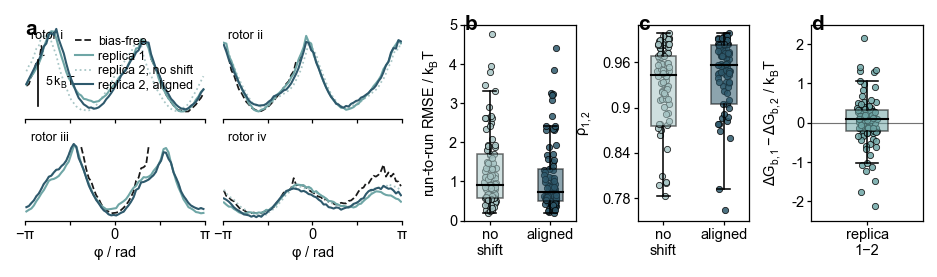

In [55]:
fig_run_reproducibility, run_reproducibility_df = plot_MBAR_run_reproducibility_SI(
    m_list=m_list,
    measurement_indices=(0, 1),
    particles=m.target_rotors,
    example_particles=(9, 17, 33, 11),
    max_shift_deg=15,
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    metric_ylims=(
        (0, 5),       # RMSE
        (0.75, 1.01), # correlation
        (-2.5, 2.5),      # barrier-height difference
    ),
    fig_width_mm=160,
    fig_height_mm=40,
    example_hspace=0.08,
    example_wspace=0.1,
    outer_wspace=0.35,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=10,
    panel_label_x=-0.00,

    box_width=0.42,
    box_alpha=0.55,
    strip_jitter=0.10,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__reproducibility_independent_runs",
    stator_variant=None,
    C=CK_colors,
)

fig_run_reproducibility

## SI | Convergence of reconstruction results

#### i. Compute convergence of metrics

In [56]:
def compute_target_region_duration_metrics(
    m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=None,
    center_mode="ensemble",
    angular_cutoff_deg=40.0,
    smooth_nbins=3,
    min_extrema_separation_deg=60.0,
    min_locs_per_window=20,
    min_locs_per_overlap_window=20,
    overlap_bins=72,
    apply_autocorrelation_trim=False,
):
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def unique_ints(x):
        if x is None:
            return []
        try:
            x = list(x)
        except TypeError:
            x = [x]
        return list(dict.fromkeys(int(v) for v in x))

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(k, str) and k.startswith("deg-")
                for k in m.protocol
            )
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def wrap_pi(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def circ_mean(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]

        if x.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * x))
        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def kappa_vm(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]

        if x.size < 3:
            return np.nan

        R = float(np.clip(np.abs(np.mean(np.exp(1j * x))), 0, 0.999999))

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6
        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            kappa = 1 / (R**3 - 4 * R**2 + 3 * R)

        n = x.size

        if n <= 15:
            if kappa < 2:
                kappa = max(
                    kappa - 2 / (n * max(kappa, 1e-12)),
                    0,
                )
            else:
                kappa = (
                    (n - 1) ** 3
                    * kappa
                    / (n**3 + n)
                )

        return float(kappa)

    def overlap(a, b):
        a = wrap_pi(a)
        b = wrap_pi(b)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if a.size < 5 or b.size < 5:
            return np.nan

        edges = np.linspace(
            -np.pi,
            np.pi,
            int(overlap_bins) + 1,
        )

        ha, _ = np.histogram(
            a,
            bins=edges,
            density=True,
        )

        hb, _ = np.histogram(
            b,
            bins=edges,
            density=True,
        )

        return float(
            np.sum(
                np.minimum(ha, hb)
                * np.diff(edges)
            )
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(
                value[0],
                (list, tuple, dict),
            )
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get(
                    "start_time",
                    value.get(
                        "t_start",
                        value.get("t0"),
                    ),
                ),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get(
                        "t_end",
                        value.get(
                            "t1",
                            value.get("stop"),
                        ),
                    ),
                ),
            )

            if start is None or stop is None:
                raise ValueError(
                    f"Cannot parse protocol bounds: {value}"
                )

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(
            f"Cannot parse protocol bounds: {value}"
        )

    def get_windows(protocol):
        rows = []

        for phase, value in protocol.items():
            if not (
                isinstance(phase, str)
                and phase.startswith("deg-")
            ):
                continue

            start, stop = protocol_bounds(value)

            rows.append({
                "phase": str(phase),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError(
                "No deg-* umbrella windows found."
            )

        return (
            pd.DataFrame(rows)
            .sort_values("start")
            .reset_index(drop=True)
        )

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        for col in (
            "averagetime",
            "time",
            "time_s",
        ):
            if col in m.locs.columns:
                m.locs["t"] = m.locs[col].astype(float)
                return

        if "frame" not in m.locs.columns:
            raise KeyError(
                "m.locs requires t, averagetime, "
                "time, time_s, or frame."
            )

        dt = float(
            getattr(
                m,
                "_average_tpf",
                getattr(m, "average_tpf", 0.005),
            )
        )

        m.locs["t"] = (
            m.locs["frame"].astype(float)
            * dt
        )

    def smooth_periodic(y, n):
        y = np.asarray(y, float)

        if n is None or int(n) <= 1:
            return y.copy()

        n = int(n)
        pad = n // 2

        extended = np.r_[
            y[-pad:],
            y,
            y[:pad],
        ]

        return np.convolve(
            extended,
            np.ones(n) / n,
            mode="same",
        )[pad:pad + len(y)]

    def find_extrema(phi, energy, minimum=True):
        left = np.roll(energy, 1)
        right = np.roll(energy, -1)

        if minimum:
            candidates = np.where(
                (energy <= left)
                & (energy <= right)
            )[0]
        else:
            candidates = np.where(
                (energy >= left)
                & (energy >= right)
            )[0]

        if candidates.size == 0:
            candidates = np.arange(len(energy))

        order = np.argsort(
            energy[candidates]
            if minimum
            else -energy[candidates]
        )

        candidates = candidates[order]
        chosen = []
        min_separation = np.deg2rad(
            float(min_extrema_separation_deg)
        )

        for index in candidates:
            if all(
                np.abs(
                    wrap_pi(
                        phi[index] - phi[previous]
                    )
                )
                >= min_separation
                for previous in chosen
            ):
                chosen.append(int(index))

            if len(chosen) == 2:
                break

        return phi[np.asarray(chosen, int)]

    def classify_position(position, wells, barriers):
        well_distance = (
            float(
                np.min(
                    np.abs(
                        wrap_pi(position - wells)
                    )
                )
            )
            if len(wells)
            else np.inf
        )

        barrier_distance = (
            float(
                np.min(
                    np.abs(
                        wrap_pi(position - barriers)
                    )
                )
            )
            if len(barriers)
            else np.inf
        )

        if min(
            well_distance,
            barrier_distance,
        ) > np.deg2rad(float(angular_cutoff_deg)):
            return None

        return (
            "well"
            if well_distance <= barrier_distance
            else "barrier"
        )

    def get_item(mapping, particle):
        if not isinstance(mapping, dict):
            return None

        if int(particle) in mapping:
            return mapping[int(particle)]

        if str(int(particle)) in mapping:
            return mapping[str(int(particle))]

        return None

    def first_existing(container, candidates):
        return next(
            (
                key
                for key in candidates
                if key in container
            ),
            None,
        )

    def extract_point_curve(table, particle):
        if hasattr(table, "columns"):
            phi_key = first_existing(
                table.columns,
                (
                    "phi",
                    "phi_rad",
                    "angle",
                    "angle_rad",
                ),
            )

            energy_key = first_existing(
                table.columns,
                (
                    "U_mbar",
                    "U_MBAR",
                    "energy_kBT",
                    "energy",
                    "G",
                ),
            )

            if phi_key is None or energy_key is None:
                raise KeyError(
                    f"Could not extract point-MBAR curve "
                    f"for particle {particle}."
                )

            phi = table[phi_key].to_numpy(float)
            energy = table[energy_key].to_numpy(float)

        elif isinstance(table, dict):
            phi_key = first_existing(
                table,
                (
                    "phi",
                    "phi_rad",
                    "angle",
                    "angle_rad",
                    "centers",
                ),
            )

            energy_key = first_existing(
                table,
                (
                    "U_mbar",
                    "U_MBAR",
                    "energy_kBT",
                    "energy",
                    "G",
                    "E",
                ),
            )

            if phi_key is None or energy_key is None:
                raise KeyError(
                    f"Could not extract point-MBAR curve "
                    f"for particle {particle}."
                )

            phi = np.asarray(
                table[phi_key],
                float,
            )

            energy = np.asarray(
                table[energy_key],
                float,
            )

        else:
            raise TypeError(
                f"Unsupported point-MBAR format "
                f"for particle {particle}."
            )

        if len(phi) != len(energy):
            raise ValueError(
                f"Point-MBAR phi and energy lengths differ "
                f"for particle {particle}."
            )

        finite = (
            np.isfinite(phi)
            & np.isfinite(energy)
        )

        phi = wrap_pi(phi[finite])
        energy = energy[finite]

        if len(phi) < 3:
            raise ValueError(
                f"Too few finite point-MBAR bins "
                f"for particle {particle}."
            )

        order = np.argsort(phi)

        return {
            "phi": phi[order],
            "energy": energy[order],
        }

    def get_reference_curve(m, particle):
        raw = getattr(
            m,
            "energy_landscapes",
            None,
        )

        if not isinstance(raw, dict):
            raise AttributeError(
                "m.energy_landscapes is missing. "
                "Run the ordinary full point-MBAR "
                "reconstruction first."
            )

        table = get_item(
            raw,
            particle,
        )

        if table is None:
            raise KeyError(
                f"Particle {particle} is missing from "
                "m.energy_landscapes."
            )

        return extract_point_curve(
            table,
            particle,
        )

    def get_full_window_centers(m):
        if not hasattr(m, "center_bias"):
            raise AttributeError(
                "m.center_bias is missing. "
                "Run the ordinary full point-MBAR "
                "reconstruction first."
            )

        by_window = m.center_bias["by_window"].copy()

        center_column = (
            "ensemble_phi0"
            if center_mode == "ensemble"
            else "command_phi0"
        )

        if center_column not in by_window.columns:
            raise KeyError(
                f"{center_column!r} is missing from "
                "m.center_bias['by_window']."
            )

        return by_window[
            ["phase", center_column]
        ].rename(
            columns={
                center_column: "window_center"
            }
        )

    measurements = [
        m
        for m in flatten(m_list)
        if is_umb(m)
    ]

    if not measurements:
        raise ValueError(
            "No UMB measurements found."
        )

    durations = tuple(
        sorted(
            set(
                float(value)
                for value in durations_s
            )
        )
    )

    if (
        not durations
        or any(value <= 0 for value in durations)
    ):
        raise ValueError(
            "durations_s must contain positive values."
        )

    for measurement_index, m in enumerate(
        tqdm(
            measurements,
            desc="Target well/barrier metrics",
            dynamic_ncols=True,
        )
    ):
        ensure_time(m)

        if "group" not in m.locs.columns:
            if "group_int" in m.locs.columns:
                m.locs = m.locs.copy()
                m.locs["group"] = (
                    m.locs["group_int"].astype(int)
                )
            else:
                raise KeyError(
                    "m.locs requires 'group' or 'group_int'."
                )

        if "phi" not in m.locs.columns:
            raise KeyError(
                "m.locs requires column 'phi'."
            )

        target_rotors = unique_ints(
            getattr(
                m,
                "target_rotors",
                None,
            )
        )

        requested_particles = (
            unique_ints(particles)
            if particles is not None
            else target_rotors
        )

        target_set = set(target_rotors)

        selected_particles = [
            particle
            for particle in requested_particles
            if particle in target_set
        ]

        if not selected_particles:
            raise ValueError(
                f"UMB {measurement_index}: "
                "no target rotors selected."
            )

        missing_from_target = [
            particle
            for particle in requested_particles
            if particle not in target_set
        ]

        if missing_from_target:
            print(
                f"UMB {measurement_index}: skipped non-target "
                f"particles {missing_from_target}"
            )

        phase_df = get_windows(
            m.protocol
        )

        window_centers = get_full_window_centers(
            m
        )

        trim_s = (
            float(
                getattr(
                    m,
                    "autocorrelation_trim_s",
                    0.0,
                )
            )
            if apply_autocorrelation_trim
            else 0.0
        )

        region_info = {}

        for particle in selected_particles:
            curve = get_reference_curve(
                m,
                particle,
            )

            phi = curve["phi"]
            energy = curve["energy"]

            smoothed_energy = smooth_periodic(
                energy,
                smooth_nbins,
            )

            wells = find_extrema(
                phi,
                smoothed_energy,
                minimum=True,
            )

            barriers = find_extrema(
                phi,
                smoothed_energy,
                minimum=False,
            )

            if len(wells) < 2 or len(barriers) < 2:
                raise RuntimeError(
                    f"Particle {particle}: could not identify "
                    "two wells and two barriers."
                )

            window_info = phase_df.merge(
                window_centers,
                on="phase",
                how="left",
            )

            if window_info[
                "window_center"
            ].isna().any():
                missing_phases = window_info.loc[
                    window_info[
                        "window_center"
                    ].isna(),
                    "phase",
                ].tolist()

                raise ValueError(
                    f"Particle {particle}: missing window "
                    f"centers for {missing_phases}."
                )

            window_info["window_center"] = wrap_pi(
                window_info[
                    "window_center"
                ].to_numpy(float)
            )

            window_info["region"] = [
                classify_position(
                    position,
                    wells,
                    barriers,
                )
                for position in window_info[
                    "window_center"
                ]
            ]

            ordered_windows = (
                window_info
                .sort_values("window_center")
                .reset_index(drop=True)
            )

            pair_rows = []

            for i in range(len(ordered_windows)):
                j = (
                    i + 1
                ) % len(ordered_windows)

                midpoint = circ_mean([
                    ordered_windows.loc[
                        i,
                        "window_center",
                    ],
                    ordered_windows.loc[
                        j,
                        "window_center",
                    ],
                ])

                pair_rows.append({
                    "phase_a": ordered_windows.loc[
                        i,
                        "phase",
                    ],
                    "phase_b": ordered_windows.loc[
                        j,
                        "phase",
                    ],
                    "midpoint": float(midpoint),
                    "region": classify_position(
                        midpoint,
                        wells,
                        barriers,
                    ),
                })

            region_info[int(particle)] = {
                "wells": np.asarray(
                    wells,
                    float,
                ),
                "barriers": np.asarray(
                    barriers,
                    float,
                ),
                "windows": window_info.copy(),
                "pairs": pd.DataFrame(pair_rows),
            }

        groups = m.locs[
            "group"
        ].astype(int).to_numpy()

        times = m.locs[
            "t"
        ].astype(float).to_numpy()

        phi_all = m.locs[
            "phi"
        ].astype(float).to_numpy()

        rotor_rows = []

        for duration in tqdm(
            durations,
            desc="Time per window",
            leave=False,
            dynamic_ncols=True,
        ):
            for particle in selected_particles:
                info = region_info[
                    int(particle)
                ]

                phase_phi = {}
                phase_metrics = {}

                for _, window in info[
                    "windows"
                ].iterrows():
                    start = (
                        float(window["start"])
                        + trim_s
                    )

                    stop = min(
                        float(window["stop"]),
                        float(window["start"])
                        + float(duration),
                    )

                    mask = (
                        (groups == int(particle))
                        & (times >= start)
                        & (times < stop)
                    )

                    values = wrap_pi(
                        phi_all[mask]
                    )

                    values = values[
                        np.isfinite(values)
                    ]

                    phase = window["phase"]
                    phase_phi[phase] = values

                    if values.size < int(
                        min_locs_per_window
                    ):
                        phase_metrics[phase] = {
                            "center_error": np.nan,
                            "kappa": np.nan,
                            "half_overlap": np.nan,
                        }
                        continue

                    mean_angle = circ_mean(
                        values
                    )

                    centered = wrap_pi(
                        values - mean_angle
                    )

                    half = values.size // 2

                    phase_metrics[phase] = {
                        "center_error": float(
                            np.abs(
                                np.rad2deg(
                                    wrap_pi(
                                        mean_angle
                                        - float(
                                            window[
                                                "window_center"
                                            ]
                                        )
                                    )
                                )
                            )
                        ),
                        "kappa": kappa_vm(
                            centered
                        ),
                        "half_overlap": (
                            overlap(
                                centered[:half],
                                centered[half:],
                            )
                            if (
                                half >= 5
                                and values.size - half >= 5
                            )
                            else np.nan
                        ),
                    }

                collected = {
                    region: {
                        metric: []
                        for metric in (
                            "center_error",
                            "kappa",
                            "half_overlap",
                            "neighbor_overlap",
                        )
                    }
                    for region in (
                        "well",
                        "barrier",
                    )
                }

                for _, window in info[
                    "windows"
                ].iterrows():
                    region = window["region"]

                    if region not in collected:
                        continue

                    values = phase_metrics[
                        window["phase"]
                    ]

                    for metric in (
                        "center_error",
                        "kappa",
                        "half_overlap",
                    ):
                        if np.isfinite(
                            values[metric]
                        ):
                            collected[
                                region
                            ][metric].append(
                                float(values[metric])
                            )

                for _, pair in info[
                    "pairs"
                ].iterrows():
                    region = pair["region"]

                    if region not in collected:
                        continue

                    a = phase_phi[
                        pair["phase_a"]
                    ]

                    b = phase_phi[
                        pair["phase_b"]
                    ]

                    if (
                        a.size
                        < int(
                            min_locs_per_overlap_window
                        )
                        or b.size
                        < int(
                            min_locs_per_overlap_window
                        )
                    ):
                        continue

                    value = overlap(
                        a,
                        b,
                    )

                    if np.isfinite(value):
                        collected[
                            region
                        ][
                            "neighbor_overlap"
                        ].append(
                            float(value)
                        )

                output = {
                    "measurement_index": int(
                        measurement_index
                    ),
                    "particle": int(
                        particle
                    ),
                    "duration_s": float(
                        duration
                    ),
                }

                for region in (
                    "well",
                    "barrier",
                ):
                    for metric in (
                        "center_error",
                        "kappa",
                        "half_overlap",
                        "neighbor_overlap",
                    ):
                        values = collected[
                            region
                        ][metric]

                        output[
                            f"{metric}_{region}"
                        ] = (
                            float(
                                np.nanmedian(values)
                            )
                            if values
                            else np.nan
                        )

                        output[
                            f"n_{metric}_{region}"
                        ] = int(
                            len(values)
                        )

                rotor_rows.append(
                    output
                )

        rotor_df = pd.DataFrame(
            rotor_rows
        )

        m.target_region_duration_metrics = {
            "durations_s": tuple(
                durations
            ),
            "particles": tuple(
                selected_particles
            ),
            "reference_region_info": region_info,
            "rotor_df": rotor_df,
            "settings": {
                "reference_source": (
                    "ordinary point MBAR: "
                    "m.energy_landscapes"
                ),
                "center_mode": str(
                    center_mode
                ),
                "angular_cutoff_deg": float(
                    angular_cutoff_deg
                ),
                "smooth_nbins": int(
                    smooth_nbins
                ),
                "min_extrema_separation_deg": float(
                    min_extrema_separation_deg
                ),
                "min_locs_per_window": int(
                    min_locs_per_window
                ),
                "min_locs_per_overlap_window": int(
                    min_locs_per_overlap_window
                ),
                "overlap_bins": int(
                    overlap_bins
                ),
                "apply_autocorrelation_trim": bool(
                    apply_autocorrelation_trim
                ),
            },
        }

    return None

In [ ]:
compute_target_region_duration_metrics(
    m_list=m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=particles, #panel_particles,
    center_mode="ensemble",
    angular_cutoff_deg=40,
    smooth_nbins=1,
    min_extrema_separation_deg=60,
    min_locs_per_window=20,
    min_locs_per_overlap_window=20,
    overlap_bins=72,
)

Target well/barrier metrics:   0%|                                                               | 0/2 [00:00<…

Time per window:   0%|                                                                           | 0/9 [00:00<…

Time per window:   0%|                                                                           | 0/9 [00:00<…

#### ii. Plot convergence of metrics for target rotors

In [ ]:
def plot_target_region_metric_convergence(
    m_list,
    measurement_index=0,
    region_labels=("well", "barrier"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.22,
    panel_label_y=1.05,
    panel_label_fontsize=10,
    fig_width_mm=180,
    fig_height_mm=52,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    target_colors=None,
    line_lw=1.05,
    marker_size=3.2,
    band_alpha=0.12,
    n_y_ticks=(5, 5, 5, 5),
    save_dir=None,
    save_prefix="target_region_metric_convergence",
    stator_variant=None,
    C=None,
    dpi=300,
):
    import numpy as np
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator, FormatStrFormatter

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def rgb(x):
        x = np.asarray(x, float).ravel()[:3]
        if np.nanmax(x) > 1:
            x = x / 255
        return tuple(map(float, x))

    def mm(x):
        return float(x) / 25.4

    if C is None:
        C = {"black": (0, 0, 0)}

    C = C() if callable(C) else dict(C)
    black = rgb(C.get("black", (0, 0, 0)))

    if target_colors is None:
        target_colors = {
            "well": (111 / 255, 166 / 255, 166 / 255),
            "barrier": (46 / 255, 89 / 255, 108 / 255),
        }

    styles = {
        "well": {
            "color": rgb(target_colors["well"]),
            "marker": "o",
            "linestyle": "-",
        },
        "barrier": {
            "color": rgb(target_colors["barrier"]),
            "marker": "s",
            "linestyle": "--",
        },
    }

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not 0 <= int(measurement_index) < len(measurements):
        raise IndexError(
            f"measurement_index={measurement_index} is invalid. "
            f"Available indices: {list(range(len(measurements)))}"
        )

    m = measurements[int(measurement_index)]

    if not hasattr(m, "target_region_duration_metrics"):
        raise AttributeError(
            "m.target_region_duration_metrics is missing. "
            "Run compute_target_region_duration_metrics(...) first."
        )

    df = m.target_region_duration_metrics["rotor_df"].copy()

    if df.empty:
        raise ValueError(
            "target_region_duration_metrics['rotor_df'] is empty."
        )

    durations = np.asarray(
        sorted(df["duration_s"].dropna().astype(float).unique()),
        float,
    )

    metrics = [
        (
            "center_error",
            r"$\langle|\Delta\varphi|\rangle$ / °",
            "%.0f",
        ),
        (
            "kappa",
            r"$\langle\kappa\rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
            "%.0f",
        ),
        (
            "half_overlap",
            r"$\langle O_{1/2}\rangle$",
            "%.2f",
        ),
        (
            "neighbor_overlap",
            r"$\langle O_{i,i+1}\rangle$",
            "%.2f",
        ),
    ]

    if np.isscalar(n_y_ticks):
        n_y_ticks = (int(n_y_ticks),) * 4
    else:
        n_y_ticks = tuple(map(int, n_y_ticks))

    if len(n_y_ticks) != 4:
        raise ValueError("n_y_ticks must contain four values.")

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(mm(fig_width_mm), mm(fig_height_mm)),
    )

    legend_handles = []

    for ai, (ax, (metric, ylabel, y_format)) in enumerate(zip(axes, metrics)):
        for region, label in zip(("well", "barrier"), region_labels):
            column = f"{metric}_{region}"
            rows = []

            for duration in durations:
                values = df.loc[
                    np.isclose(
                        df["duration_s"].to_numpy(float),
                        float(duration),
                    ),
                    column,
                ].to_numpy(float)

                values = values[np.isfinite(values)]

                if values.size:
                    rows.append((
                        float(duration),
                        float(np.mean(values)),
                        float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
                    ))

            if not rows:
                continue

            x, mean, std = [np.asarray(v, float) for v in zip(*rows)]
            lower, upper = mean - std, mean + std

            if metric in {"half_overlap", "neighbor_overlap"}:
                lower = np.clip(lower, 0, 1)
                upper = np.clip(upper, 0, 1)

            style = styles[region]

            ax.fill_between(
                x,
                lower,
                upper,
                color=style["color"],
                alpha=band_alpha,
                linewidth=0,
                zorder=1,
            )

            line, = ax.plot(
                x,
                mean,
                color=style["color"],
                marker=style["marker"],
                linestyle=style["linestyle"],
                lw=line_lw,
                ms=marker_size,
                markerfacecolor=style["color"],
                markeredgecolor=black,
                markeredgewidth=0.45,
                alpha=0.98,
                zorder=5,
                label=str(label),
            )

            if ai == 0:
                legend_handles.append(line)

        ax.set_xlabel("time / s", fontsize=axis_label_size)
        ax.set_ylabel(ylabel, fontsize=axis_label_size)

        ax.set_xlim(
            np.floor(durations.min()) - 0.15,
            np.ceil(durations.max()) + 0.15,
        )

        integer_xticks = np.arange(
            int(np.ceil(durations.min())),
            int(np.floor(durations.max())) + 1,
        )

        ax.set_xticks(integer_xticks)
        ax.set_xticklabels([str(int(x)) for x in integer_xticks])

        # Keep half-second positions as short unlabeled x ticks.
        half_xticks = durations[
            ~np.isclose(durations, np.round(durations))
        ]
        ax.set_xticks(half_xticks, minor=True)

        ax.tick_params(
            axis="x",
            which="minor",
            length=1.4,
            width=0.5,
        )

        # Every visible y tick is a labeled major tick.
        ax.yaxis.set_major_locator(
            MaxNLocator(
                nbins=n_y_ticks[ai],
                min_n_ticks=4,
            )
        )
        ax.yaxis.set_major_formatter(
            FormatStrFormatter(y_format)
        )
        ax.yaxis.set_minor_locator(
            plt.NullLocator()
        )

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            which="major",
            length=2.0,
            width=0.6,
            labelsize=tick_label_size,
            color=black,
            labelcolor=black,
            pad=1.5,
        )

        ax.grid(False)

        if panel_labels is not None and ai < len(panel_labels):
            ax.text(
                panel_label_x,
                panel_label_y,
                str(panel_labels[ai]),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=panel_label_fontsize,
                fontname="Arial",
                fontweight="bold",
                color=black,
            )

    axes[0].legend(
        handles=legend_handles,
        labels=[str(handle.get_label()) for handle in legend_handles],
        loc="upper right",
        frameon=False,
        fontsize=annotation_size,
        handlelength=1.8,
        borderaxespad=0.2,
        labelspacing=0.25,
        handletextpad=0.4,
    )

    fig.subplots_adjust(
        left=0.065,
        right=0.99,
        bottom=0.20,
        top=0.97,
        wspace=0.48,
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__"
            if stator_variant is not None and str(stator_variant).strip()
            else ""
        )
        filename = f"{prefix}{save_prefix}"

        fig.savefig(
            save_dir / f"{filename}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        fig.savefig(
            save_dir / f"{filename}.svg",
            bbox_inches="tight",
        )

    return fig

In [ ]:
fig_target_region_convergence = plot_target_region_metric_convergence(
    m_list=m_list,
    measurement_index=0,
    region_labels=("well", "barrier"),
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.3,
    panel_label_y=1.05,
    panel_label_fontsize=10,
    fig_width_mm=160,
    fig_height_mm=45,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    target_colors={
        "well": (111 / 255, 166 / 255, 166 / 255),
        "barrier": (46 / 255, 89 / 255, 108 / 255),
    },
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__convergence_target_metric_stats",
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    C=CK_colors,
)



#### iii. Compute convergence of reconstruction

In [ ]:
def compute_MBAR_regional_duration_convergence(
    m_list,
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    nbins=72,
    pmin_nan=1e-12,
    min_keep=50,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    import copy
    import inspect
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    if "run_MBAR_reconstruction" not in globals():
        raise NameError("run_MBAR_reconstruction(...) must be defined.")

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [v for y in x for v in flatten(y)]
        return [x]

    def unique_ints(x):
        if x is None:
            return []
        try:
            x = list(x)
        except TypeError:
            x = [x]
        return list(dict.fromkeys(int(v) for v in x))

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def wrap_pi(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def circular_mean(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if not x.size:
            return np.nan
        z = np.mean(np.exp(1j * x))
        return float(np.angle(z)) if abs(z) > 1e-15 else np.nan

    def von_mises_kappa(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if x.size < 3:
            return np.nan

        R = float(np.clip(abs(np.mean(np.exp(1j * x))), 0, 0.999999))
        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6
        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            kappa = 1 / (R**3 - 4 * R**2 + 3 * R)

        n = x.size
        if n <= 15:
            kappa = max(kappa - 2 / (n * max(kappa, 1e-12)), 0) if kappa < 2 else (n - 1)**3 * kappa / (n**3 + n)

        return float(kappa)

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]

        if isinstance(value, dict):
            start = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            stop = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))))
            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")
            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def shortened_protocol(protocol, duration_s):
        short = copy.deepcopy(protocol)
        umbrella_bounds = []

        for phase, value in protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            start, stop = protocol_bounds(value)
            stop = min(stop, start + float(duration_s))
            short[phase] = (start, stop)
            umbrella_bounds.append((start, stop))

        if not umbrella_bounds:
            raise ValueError("No deg-* umbrella windows found.")

        if "umbrella" in short:
            short["umbrella"] = (
                min(start for start, _ in umbrella_bounds),
                max(stop for _, stop in umbrella_bounds),
            )

        return short

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()
        for col in ("averagetime", "time", "time_s"):
            if col in m.locs.columns:
                m.locs["t"] = m.locs[col].astype(float)
                return

        if "frame" not in m.locs.columns:
            raise KeyError("m.locs requires a time or frame column.")

        dt = float(getattr(m, "_average_tpf", getattr(m, "average_tpf", 0.005)))
        m.locs["t"] = m.locs["frame"].astype(float) * dt

    def build_duration_calibration(m, calibration_rotors):
        trim_s = max(float(getattr(m, "autocorrelation_trim_s", 0.0)), 0.0)
        groups = m.locs["group"].astype(int).to_numpy()
        times = m.locs["t"].astype(float).to_numpy()
        angles = m.locs["phi"].astype(float).to_numpy()
        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            start, stop = protocol_bounds(value)
            start += trim_s

            if stop <= start:
                continue

            for particle in calibration_rotors:
                phi = wrap_pi(angles[(groups == particle) & (times >= start) & (times < stop)])
                phi = phi[np.isfinite(phi)]

                if phi.size < int(min_calib_locs_per_window):
                    continue

                mu_fit = circular_mean(phi)
                kappa = von_mises_kappa(phi)

                if np.isfinite(mu_fit) and np.isfinite(kappa) and kappa > 0:
                    rows.append({
                        "particle": int(particle),
                        "phase": str(phase),
                        "mu_fit": float(mu_fit),
                        "kappa": float(kappa),
                    })

        table = pd.DataFrame(rows)
        if table.empty:
            raise RuntimeError("No duration-specific calibration values could be calculated.")

        return table

    def get_item(mapping, particle):
        if not isinstance(mapping, dict):
            return None
        return mapping.get(int(particle), mapping.get(str(int(particle))))

    def extract_curve(table):
        if table is None:
            return None

        if hasattr(table, "columns"):
            phi_key = next((k for k in ("phi", "phi_rad", "angle_rad") if k in table.columns), None)
            energy_key = next((k for k in ("U_mbar", "energy_kBT", "energy", "G") if k in table.columns), None)
            if phi_key is None or energy_key is None:
                return None
            phi = table[phi_key].to_numpy(float)
            energy = table[energy_key].to_numpy(float)

        elif isinstance(table, dict):
            phi_key = next((k for k in ("phi", "phi_rad", "angle_rad") if k in table), None)
            energy_key = next((k for k in ("U_mbar", "energy_kBT", "energy", "G") if k in table), None)
            if phi_key is None or energy_key is None:
                return None
            phi = np.asarray(table[phi_key], float)
            energy = np.asarray(table[energy_key], float)

        else:
            return None

        finite = np.isfinite(phi) & np.isfinite(energy)
        if np.sum(finite) < 3:
            return None

        phi = wrap_pi(phi[finite])
        energy = energy[finite]
        order = np.argsort(phi)

        return {"phi": phi[order].copy(), "energy": energy[order].copy()}

    def extract_current_curves(m, particles_use):
        try:
            raw = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception:
            raw = getattr(m, "reconstructed_energy_landscapes", None)

        if not isinstance(raw, dict):
            raw = getattr(m, "energy_landscapes", None)

        curves = {}
        for particle in particles_use:
            curve = extract_curve(get_item(raw, particle))
            if curve is not None:
                curves[int(particle)] = curve

        return curves

    def call_point_mbar(m):
        kwargs = {
            "m_list": m,
            "nbins": int(nbins),
            "kappa_mode": "by_angle",
            "bias_potential": str(bias_potential),
            "center_mode": str(center_mode),
            "kappa_rescale_calibration": float(kappa_rescale_calibration),
            "kappa_rescale_target": float(kappa_rescale_target),
            "pmin_nan": float(pmin_nan),
            "min_keep": int(min_keep),
            "rolling_mean_kappa_ensemble": bool(rolling_mean_kappa_ensemble),
            "rolling_mean_kappa_window": int(rolling_mean_kappa_window),
            "mbar_tol": float(mbar_tol),
            "mbar_max_iter": int(mbar_max_iter),
            "mbar_damp": float(mbar_damp),
        }

        function = globals()["run_MBAR_reconstruction"]
        signature = inspect.signature(function)
        function(**{key: value for key, value in kwargs.items() if key in signature.parameters})

    def periodic_interp(curve, phi_target):
        phi = curve["phi"]
        energy = curve["energy"]

        return np.interp(
            phi_target,
            np.r_[phi - 2 * np.pi, phi, phi + 2 * np.pi],
            np.r_[energy, energy, energy],
        )

    def find_extrema(phi, energy, minimum):
        left, right = np.roll(energy, 1), np.roll(energy, -1)
        candidates = np.where((energy <= left) & (energy <= right))[0] if minimum else np.where((energy >= left) & (energy >= right))[0]

        if not candidates.size:
            candidates = np.arange(len(energy))

        candidates = candidates[np.argsort(energy[candidates] if minimum else -energy[candidates])]
        separation = np.deg2rad(float(min_extrema_separation_deg))
        chosen = []

        for index in candidates:
            if all(abs(wrap_pi(phi[index] - phi[previous])) >= separation for previous in chosen):
                chosen.append(int(index))
            if len(chosen) == 2:
                break

        return phi[np.asarray(chosen, int)]

    def region_mask(phi, positions):
        positions = np.asarray(positions, float)
        if not positions.size:
            return np.zeros(len(phi), bool)

        distances = np.abs(wrap_pi(np.asarray(phi)[:, None] - positions[None, :]))
        return np.any(distances <= np.deg2rad(float(angular_cutoff_deg)), axis=1)

    durations = tuple(sorted(set(float(value) for value in durations_s)))
    if not durations or any(value <= 0 for value in durations):
        raise ValueError("durations_s must contain positive values.")

    full_duration = max(durations)
    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    output_attributes = (
        "reconstructed_energy_landscapes_by_center",
        "reconstructed_energy_landscapes_by_bias",
        "reconstructed_energy_landscapes",
        "energy_landscapes",
        "energy_landscapes_meta",
        "center_bias",
        "kappa_bias",
    )

    for measurement_index, m in enumerate(tqdm(measurements, desc="Regional MBAR convergence", dynamic_ncols=True)):
        ensure_time(m)

        calibration_rotors = unique_ints(getattr(m, "calibration_rotors", None))
        target_rotors = unique_ints(getattr(m, "target_rotors", None))
        requested = unique_ints(particles) if particles is not None else target_rotors
        particles_use = [particle for particle in requested if particle in target_rotors]

        if not calibration_rotors:
            raise ValueError(f"UMB {measurement_index}: no calibration rotors.")
        if not particles_use:
            raise ValueError(f"UMB {measurement_index}: no target rotors selected.")

        # The currently stored point-MBAR reconstruction is the full-time reference.
        full_curves = extract_current_curves(m, particles_use)
        missing_full = [particle for particle in particles_use if particle not in full_curves]

        if missing_full:
            raise KeyError(
                f"UMB {measurement_index}: full point-MBAR curves missing for particles {missing_full}."
            )

        region_info = {}
        for particle, curve in full_curves.items():
            wells = find_extrema(curve["phi"], curve["energy"], minimum=True)
            barriers = find_extrema(curve["phi"], curve["energy"], minimum=False)

            if len(wells) < 2 or len(barriers) < 2:
                raise RuntimeError(f"UMB {measurement_index}, particle {particle}: could not find two wells and two barriers.")

            region_info[particle] = {
                "well_mask": region_mask(curve["phi"], wells),
                "barrier_mask": region_mask(curve["phi"], barriers),
            }

        original_protocol = copy.deepcopy(m.protocol)
        original_kappa_table = copy.deepcopy(getattr(m, "kappa_calibration_by_window", None))
        original_calibration_rotors = copy.deepcopy(getattr(m, "calibration_rotors", None))
        original_target_rotors = copy.deepcopy(getattr(m, "target_rotors", None))

        missing = object()
        original_outputs = {name: getattr(m, name, missing) for name in output_attributes}
        rows, previous_curves, failed_durations = [], None, {}

        try:
            for duration in tqdm(durations, desc="Time per window", leave=False, dynamic_ncols=True):
                try:
                    if np.isclose(duration, full_duration):
                        current_curves = full_curves
                    else:
                        m.protocol = shortened_protocol(original_protocol, duration)
                        m.kappa_calibration_by_window = build_duration_calibration(m, calibration_rotors)
                        m.calibration_rotors = list(calibration_rotors)
                        m.target_rotors = list(particles_use)

                        call_point_mbar(m)
                        current_curves = extract_current_curves(m, particles_use)

                    for particle in particles_use:
                        if particle not in current_curves:
                            continue

                        reference = full_curves[particle]
                        current = current_curves[particle]
                        phi_ref = reference["phi"]
                        G_ref = reference["energy"]
                        G_current = periodic_interp(current, phi_ref)
                        finite = np.isfinite(G_ref) & np.isfinite(G_current)

                        if np.sum(finite) < 3:
                            continue

                        offset = np.nanmedian(G_current[finite] - G_ref[finite])
                        residual = G_current - offset - G_ref
                        well_mask = finite & region_info[particle]["well_mask"]
                        barrier_mask = finite & region_info[particle]["barrier_mask"]

                        rmse_previous = np.nan
                        if previous_curves is not None and particle in previous_curves:
                            G_previous = periodic_interp(previous_curves[particle], phi_ref)
                            keep = np.isfinite(G_previous) & np.isfinite(G_current)

                            if np.sum(keep) >= 3:
                                previous_offset = np.nanmedian(G_current[keep] - G_previous[keep])
                                rmse_previous = float(np.sqrt(np.mean((G_current[keep] - previous_offset - G_previous[keep])**2)))

                        rows.append({
                            "particle": int(particle),
                            "duration_s": float(duration),
                            "rmse_to_full_kBT": float(np.sqrt(np.mean(residual[finite]**2))),
                            "rmse_to_previous_kBT": rmse_previous,
                            "deltaG_well_to_full_kBT": float(np.mean(residual[well_mask])) if np.any(well_mask) else np.nan,
                            "deltaG_barrier_to_full_kBT": float(np.mean(residual[barrier_mask])) if np.any(barrier_mask) else np.nan,
                        })

                    previous_curves = current_curves

                except Exception as exc:
                    failed_durations[float(duration)] = f"{type(exc).__name__}: {exc}"
                    print(f"UMB {measurement_index} | {duration:g} s skipped: {type(exc).__name__}: {exc}")

        finally:
            m.protocol = original_protocol
            m.calibration_rotors = original_calibration_rotors
            m.target_rotors = original_target_rotors

            if original_kappa_table is None:
                if hasattr(m, "kappa_calibration_by_window"):
                    delattr(m, "kappa_calibration_by_window")
            else:
                m.kappa_calibration_by_window = original_kappa_table

            for name, value in original_outputs.items():
                if value is missing:
                    if hasattr(m, name):
                        delattr(m, name)
                else:
                    setattr(m, name, value)

        rotor_df = pd.DataFrame(rows)

        if rotor_df.empty:
            raise RuntimeError(
                f"UMB {measurement_index}: no regional convergence metrics calculated. "
                f"Failures: {failed_durations}"
            )

        m.mbar_regional_duration_convergence = {
            "rotor_df": rotor_df,
            "settings": {
                "durations_s": durations,
                "full_duration_s": float(full_duration),
                "angular_cutoff_deg": float(angular_cutoff_deg),
                "min_extrema_separation_deg": float(min_extrema_separation_deg),
                "center_mode": str(center_mode),
                "bias_potential": str(bias_potential),
                "failed_durations": failed_durations,
            },
        }

    return None

In [ ]:
compute_MBAR_regional_duration_convergence(
    m_list=m_list[0],
    durations_s=(1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5),
    particles=used_particles,
    center_mode="ensemble",
    bias_potential="cosine",
    angular_cutoff_deg=40,
    min_extrema_separation_deg=60,
    nbins=72,
    min_keep=50,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
)

#### iv. Plot convergence reconstruction results

In [ ]:
def plot_MBAR_regional_duration_convergence(
    m_list,
    measurement_index=0,
    panel_labels=("a", "b", "c", "d"),
    fig_width_mm=180,
    fig_height_mm=52,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    panel_label_size=8,
    panel_label_x=-0.22,
    panel_label_y=1.05,
    line_lw=1.05,
    marker_size=3.2,
    band_alpha=0.12,
    n_y_ticks=(5, 5, 5, 5),
    save_dir=None,
    save_prefix="MBAR_regional_duration_convergence",
    stator_variant=None,
    C=None,
    dpi=300,
):
    import numpy as np
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator, FormatStrFormatter, NullLocator

    def flatten(x):
        if x is None: return []
        return [v for y in x for v in flatten(y)] if isinstance(x, (list, tuple)) else [x]

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def rgb(value):
        value = np.asarray(value, float).ravel()[:3]
        return tuple(value / 255 if np.nanmax(value) > 1 else value)

    mm = lambda value: float(value) / 25.4

    C = {} if C is None else (C() if callable(C) else dict(C))
    black = rgb(C.get("black", (0, 0, 0)))

    
    colors = {
        "rmse_full": (46 / 255, 89 / 255, 108 / 255),
        "rmse_prev": (46 / 255, 89 / 255, 108 / 255),
        "well": (111 / 255, 166 / 255, 166 / 255),
        "barrier": (46 / 255, 89 / 255, 108 / 255),
    }

    measurements = [m for m in flatten(m_list) if is_umb(m)]
    if not 0 <= int(measurement_index) < len(measurements):
        raise IndexError(f"measurement_index must be between 0 and {len(measurements) - 1}.")

    m = measurements[int(measurement_index)]
    if not hasattr(m, "mbar_regional_duration_convergence"):
        raise AttributeError("Run compute_MBAR_regional_duration_convergence(...) first.")

    df = m.mbar_regional_duration_convergence["rotor_df"].copy()
    if df.empty:
        raise ValueError("m.mbar_regional_duration_convergence['rotor_df'] is empty.")

    durations = np.sort(df["duration_s"].dropna().unique().astype(float))
    integer_ticks = np.arange(int(np.ceil(durations.min())), int(np.floor(durations.max())) + 1)

    metrics = [
        ("rmse_to_full_kBT", r"$\mathrm{RMSE}_{\mathrm{full}}$ / $k_\mathrm{B}T$", "rmse_full", "o", "-", False),
        ("rmse_to_previous_kBT", r"$\mathrm{RMSE}_{t,t-\Delta t}$ / $k_\mathrm{B}T$", "rmse_prev", "o", "-", False),
        ("deltaG_well_to_full_kBT", r"$\Delta G_\mathrm{w}$ / $k_\mathrm{B}T$", "well", "o", "-", True),
        ("deltaG_barrier_to_full_kBT", r"$\Delta G_\mathrm{b}$ / $k_\mathrm{B}T$", "barrier", "s", "--", True),
    ]

    if np.isscalar(n_y_ticks): n_y_ticks = (int(n_y_ticks),) * len(metrics)

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(1, 4, figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    for i, (ax, (metric, ylabel, color_key, marker, linestyle, zero_line)) in enumerate(zip(axes, metrics)):
        summary = (
            df.groupby("duration_s", sort=True)[metric]
            .agg(["mean", "std"])
            .reset_index()
            .replace([np.inf, -np.inf], np.nan)
            .dropna(subset=["mean"])
        )

        x = summary["duration_s"].to_numpy(float)
        mean = summary["mean"].to_numpy(float)
        std = summary["std"].fillna(0).to_numpy(float)
        color = rgb(colors[color_key])

        if x.size:
            ax.fill_between(x, mean - std, mean + std, color=color, alpha=band_alpha, linewidth=0)
            ax.plot(
                x, mean,
                color=color, lw=line_lw, linestyle=linestyle, marker=marker, ms=marker_size,
                markerfacecolor=color, markeredgecolor=black, markeredgewidth=0.45,
            )

        if zero_line:
            ax.axhline(0, color=black, lw=0.55, alpha=0.55, zorder=0)

        ax.set_xlabel("time / s")
        ax.set_ylabel(ylabel)
        ax.set_xlim(durations.min() - 0.15, durations.max() + 0.15)
        ax.set_xticks(integer_ticks)
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_locator(MaxNLocator(nbins=int(n_y_ticks[i]), min_n_ticks=4))
        ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        ax.tick_params(which="major", length=2, width=0.6, pad=1.5, colors=black)
        ax.grid(False)

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        if panel_labels is not None and i < len(panel_labels):
            ax.text(
                panel_label_x, panel_label_y, panel_labels[i],
                transform=ax.transAxes, ha="left", va="top",
                fontsize=panel_label_size, fontname="Arial", fontweight="bold", color=black,
            )

    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.20, top=0.97, wspace=0.48)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__" if stator_variant is not None and str(stator_variant).strip() else ""
        fig.savefig(save_dir / f"{prefix}{save_prefix}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}{save_prefix}.svg", bbox_inches="tight")

    plt.close(fig)
    return fig

In [ ]:
fig_regional = plot_MBAR_regional_duration_convergence(
    m_list=m_list,
    measurement_index=0,
    panel_labels=("a", "b", "c", "d"),
    panel_label_x=-0.3,
    # panel_label_y=1.05,
    fig_width_mm=160,
    fig_height_mm=45,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    panel_label_size = 10,
    n_y_ticks=(5, 5, 5, 5),
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__convergence_reconstruction_metrics",
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    C=CK_colors,
)
fig_regional

## SI | Sensitivity of reconstruction with different calibration rotors subsets

#### i. Perform reconstruction based on bias from different calibration rotor subsets

In [ ]:
def compute_MBAR_calibration_subset_size_sensitivity(
    m_list,
    particles=None,
    measurement_indices=(0,),
    subset_sizes=(1, 2, 5, 10, 15, 20, 25, 30),
    n_subsets_per_size=15,
    duration_s=5.0,
    center_mode="ensemble",
    bias_potential="cosine",
    nbins=72,
    pmin_nan=1e-12,
    min_keep=200,
    kappa_mode="by_angle",
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
    random_seed=3,
    bias_grid_n=72,
):
    """
    Test sensitivity to calibration-rotor selection and subset size.

    For each random calibration subset, the function stores only:

      1. mean absolute calibration-center change across umbrella windows

             mean_i |wrap(phi0_subset,i - phi0_full,i)|

      2. mean absolute stiffness change across umbrella windows

             mean_i |kappa_subset,i - kappa_full,i|

      3. mean RMSE of the restraint potentials across umbrella windows

             mean_i RMSE[W_subset,i(phi), W_full,i(phi)]

      4. target-specific reconstruction RMSE

             RMSE[G_subset,p(phi), G_full,p(phi)]

    Random selection is without replacement within each subset. For every
    repetition, increasing subset sizes are nested prefixes of one random
    permutation of the full calibration ensemble.

    Stored on each processed UMB measurement
    -----------------------------------------
    m.mbar_calibration_subset_size_sensitivity = {
        "calibration_subset_df": ...,
        "calibration_summary_df": ...,
        "reconstruction_df": ...,
        "reconstruction_summary_df": ...,
        "target_summary_df": ...,
        "failed_runs": ...,
        "settings": ...,
    }

    Returns None.
    """

    import copy
    import inspect
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    if "run_MBAR_reconstruction" not in globals():
        raise NameError("run_MBAR_reconstruction(...) is not defined.")

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def as_int_list(values):
        if values is None:
            return []
        try:
            return sorted(set(map(int, values)))
        except TypeError:
            return [int(values)]

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()
        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(phase, str) and phase.startswith("deg-") for phase in m.protocol)
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def wrap_pi(values):
        values = np.asarray(values, dtype=float)
        return (values + np.pi) % (2.0 * np.pi) - np.pi

    def circular_mean(values):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        if values.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * values))
        return float(np.angle(z)) if abs(z) > 1e-15 else np.nan

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)
        window = int(window)

        if window <= 1:
            return values.copy()
        if window % 2 == 0:
            window += 1

        half = window // 2
        out = np.full(values.size, np.nan)

        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]
            if local.size:
                out[i] = np.mean(local)

        return out

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            stop = value.get(
                "end",
                value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))),
            )
            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")
            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def shortened_protocol(protocol_original):
        protocol = copy.deepcopy(protocol_original)
        bounds = []

        for phase, value in protocol_original.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            start, stop = protocol_bounds(value)
            stop = min(float(stop), float(start) + float(duration_s))
            protocol[phase] = (float(start), float(stop))
            bounds.append((float(start), float(stop)))

        if not bounds:
            raise ValueError("No deg-* umbrella windows found.")

        if "umbrella" in protocol:
            protocol["umbrella"] = (
                min(start for start, _ in bounds),
                max(stop for _, stop in bounds),
            )

        return protocol

    def first_existing(columns, candidates):
        return next((column for column in candidates if column in columns), None)

    def load_calibration_table(m):
        table = None

        for attr in (
            "kappa_calibration_by_window",
            "calibration_kappa_by_window_reliable",
            "calibration_kappa_by_window",
        ):
            candidate = getattr(m, attr, None)
            if isinstance(candidate, pd.DataFrame) and len(candidate):
                table = candidate.copy()
                break

        if table is None:
            raise AttributeError(
                "No calibration-window table found. Expected one of "
                "kappa_calibration_by_window, calibration_kappa_by_window_reliable, "
                "or calibration_kappa_by_window."
            )

        particle_col = first_existing(table.columns, ("particle", "group", "rotor"))
        phase_col = first_existing(table.columns, ("phase", "window", "window_name"))
        kappa_col = first_existing(
            table.columns,
            ("kappa", "kappa_vm", "kappa_fit", "kappa_theta_over_kBT_rad2"),
        )
        center_col = first_existing(
            table.columns,
            ("mu_fit", "mu_fit_rad", "mu_display_rad", "phi0", "phi_ens", "center_rad"),
        )

        missing = [
            name
            for name, column in {
                "particle": particle_col,
                "phase": phase_col,
                "kappa": kappa_col,
                "center": center_col,
            }.items()
            if column is None
        ]

        if missing:
            raise KeyError(
                f"Could not identify calibration-table columns for {missing}. "
                f"Available columns: {list(table.columns)}"
            )

        out = pd.DataFrame({
            "particle": pd.to_numeric(table[particle_col], errors="coerce"),
            "phase": table[phase_col].astype(str),
            "kappa": pd.to_numeric(table[kappa_col], errors="coerce"),
            "center": pd.to_numeric(table[center_col], errors="coerce"),
        })

        out = out[
            np.isfinite(out["particle"])
            & np.isfinite(out["kappa"])
            & (out["kappa"] > 0)
            & np.isfinite(out["center"])
        ].copy()

        out["particle"] = out["particle"].astype(int)
        out["center"] = wrap_pi(out["center"].to_numpy(float))

        return out

    def calibration_parameters(table, subset, phase_order):
        selected = table[table["particle"].isin(subset)]
        rows = []

        for phase in phase_order:
            group = selected[selected["phase"].eq(str(phase))]
            if group.empty:
                continue

            kappas = group["kappa"].to_numpy(float)
            centers = group["center"].to_numpy(float)
            kappas = kappas[np.isfinite(kappas) & (kappas > 0)]
            centers = centers[np.isfinite(centers)]

            if kappas.size == 0 or centers.size == 0:
                continue

            rows.append({
                "phase": str(phase),
                "center": circular_mean(centers),
                "kappa_raw": float(np.mean(kappas)),
            })

        parameters = pd.DataFrame(rows)

        if parameters.empty:
            return parameters

        phase_rank = {phase: index for index, phase in enumerate(phase_order)}
        parameters["_order"] = parameters["phase"].map(phase_rank)
        parameters = parameters.sort_values("_order").reset_index(drop=True)

        kappa = parameters["kappa_raw"].to_numpy(float)

        if rolling_mean_kappa_ensemble:
            kappa = periodic_mean(kappa, rolling_mean_kappa_window)

        finite = np.isfinite(kappa) & (kappa > 0)

        if not np.any(finite):
            return pd.DataFrame()

        global_kappa = float(np.mean(kappa[finite]))

        if str(kappa_mode) == "global":
            kappa = np.full(len(parameters), global_kappa)
        elif str(kappa_mode) == "by_angle":
            kappa[~finite] = global_kappa
        else:
            raise ValueError("kappa_mode must be 'global' or 'by_angle'.")

        parameters["kappa"] = kappa * float(kappa_rescale_calibration)

        return parameters[["phase", "center", "kappa"]]

    def restraint_potential(phi, center, kappa):
        delta = wrap_pi(phi - float(center))

        if str(bias_potential) == "cosine":
            return float(kappa) * (1.0 - np.cos(delta))
        if str(bias_potential) == "harmonic":
            return 0.5 * float(kappa) * delta**2

        raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

    def compare_calibration(subset_parameters, full_parameters):
        merged = subset_parameters.merge(
            full_parameters,
            on="phase",
            how="inner",
            suffixes=("_subset", "_full"),
        )

        if merged.empty:
            return None

        delta_phi_deg = np.abs(
            np.rad2deg(
                wrap_pi(
                    merged["center_subset"].to_numpy(float)
                    - merged["center_full"].to_numpy(float)
                )
            )
        )

        delta_kappa = np.abs(
            merged["kappa_subset"].to_numpy(float)
            - merged["kappa_full"].to_numpy(float)
        )

        phi_grid = np.linspace(-np.pi, np.pi, int(bias_grid_n), endpoint=False)
        bias_rmse = []

        for row in merged.itertuples(index=False):
            W_subset = restraint_potential(phi_grid, row.center_subset, row.kappa_subset)
            W_full = restraint_potential(phi_grid, row.center_full, row.kappa_full)
            bias_rmse.append(np.sqrt(np.mean((W_subset - W_full) ** 2)))

        return {
            "n_common_windows": int(len(merged)),
            "mean_abs_delta_phi_deg": float(np.mean(delta_phi_deg)),
            "mean_abs_delta_kappa_kBT_rad2": float(np.mean(delta_kappa)),
            "mean_restraint_rmse_kBT": float(np.mean(bias_rmse)),
        }

    def extract_curve(table):
        if hasattr(table, "columns"):
            phi_col = first_existing(table.columns, ("phi", "phi_rad", "angle", "angle_rad"))
            energy_col = first_existing(
                table.columns,
                ("U_mbar", "U_MBAR", "energy_kBT", "energy", "G"),
            )

            if phi_col is None or energy_col is None:
                return None

            phi = table[phi_col].to_numpy(float)
            energy = table[energy_col].to_numpy(float)

        elif isinstance(table, dict):
            phi_col = first_existing(table, ("phi", "phi_rad", "angle", "angle_rad"))
            energy_col = first_existing(
                table,
                ("U_mbar", "U_MBAR", "energy_kBT", "energy", "G"),
            )

            if phi_col is None or energy_col is None:
                return None

            phi = np.asarray(table[phi_col], dtype=float)
            energy = np.asarray(table[energy_col], dtype=float)

        else:
            return None

        keep = np.isfinite(phi)
        phi = wrap_pi(phi[keep])
        energy = energy[keep]

        if len(phi) < 3 or len(phi) != len(energy):
            return None

        order = np.argsort(phi)

        return {
            "phi": phi[order],
            "energy": energy[order],
        }

    def get_curves(m, selected_particles):
        try:
            raw = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception:
            raw = getattr(m, "energy_landscapes", None)

        if not isinstance(raw, dict):
            raise ValueError("Point-MBAR output was not found.")

        selected_particles = set(map(int, selected_particles))
        curves = {}

        for particle, table in raw.items():
            try:
                particle = int(particle)
            except Exception:
                continue

            if particle not in selected_particles:
                continue

            curve = extract_curve(table)

            if curve is not None:
                curves[particle] = curve

        return curves

    def call_point_mbar(m, selected_particles):
        m.target_rotors = list(map(int, selected_particles))

        kwargs = {
            "m_list": m,
            "particles": list(map(int, selected_particles)),
            "nbins": int(nbins),
            "pmin_nan": float(pmin_nan),
            "min_keep": int(min_keep),
            "center_mode": str(center_mode),
            "bias_potential": str(bias_potential),
            "kappa_mode": str(kappa_mode),
            "kappa_rescale_calibration": float(kappa_rescale_calibration),
            "kappa_rescale_target": float(kappa_rescale_target),
            "rolling_mean_kappa_ensemble": bool(rolling_mean_kappa_ensemble),
            "rolling_mean_kappa_window": int(rolling_mean_kappa_window),
            "mbar_tol": float(mbar_tol),
            "mbar_max_iter": int(mbar_max_iter),
            "mbar_damp": float(mbar_damp),
        }

        function = globals()["run_MBAR_reconstruction"]
        signature = inspect.signature(function)
        accepts_kwargs = any(
            parameter.kind == inspect.Parameter.VAR_KEYWORD
            for parameter in signature.parameters.values()
        )

        if accepts_kwargs:
            function(**kwargs)
            return

        supported = {
            key: value
            for key, value in kwargs.items()
            if key in signature.parameters
        }

        if "m_list" in signature.parameters:
            function(**supported)
        else:
            supported.pop("m_list", None)
            function(m, **supported)

    def periodic_interpolate(phi_source, values_source, phi_target):
        phi_source = np.asarray(phi_source, dtype=float)
        values_source = np.asarray(values_source, dtype=float)
        phi_target = np.asarray(phi_target, dtype=float)

        finite = np.isfinite(phi_source) & np.isfinite(values_source)

        if np.sum(finite) < 3:
            return np.full_like(phi_target, np.nan)

        phi_source = phi_source[finite]
        values_source = values_source[finite]
        order = np.argsort(phi_source)
        phi_source = phi_source[order]
        values_source = values_source[order]

        return np.interp(
            phi_target,
            np.r_[phi_source - 2 * np.pi, phi_source, phi_source + 2 * np.pi],
            np.r_[values_source, values_source, values_source],
        )

    def reconstruction_rmse(full_curve, subset_curve):
        phi = np.asarray(full_curve["phi"], dtype=float)
        full_energy = np.asarray(full_curve["energy"], dtype=float)

        subset_energy = periodic_interpolate(
            subset_curve["phi"],
            subset_curve["energy"],
            phi,
        )

        finite = np.isfinite(full_energy) & np.isfinite(subset_energy)

        if np.sum(finite) < max(8, int(0.5 * len(phi))):
            return np.nan

        offset = np.nanmedian(subset_energy[finite] - full_energy[finite])
        residual = subset_energy - offset - full_energy

        return float(np.sqrt(np.nanmean(residual[finite] ** 2)))

    def summarize(table, value_column, group_columns):
        rows = []

        for keys, group in table.groupby(group_columns, sort=True):
            keys = keys if isinstance(keys, tuple) else (keys,)
            values = pd.to_numeric(group[value_column], errors="coerce").to_numpy(float)
            values = values[np.isfinite(values)]

            if values.size == 0:
                continue

            row = dict(zip(group_columns, keys))
            row.update({
                "mean": float(np.mean(values)),
                "q025": float(np.percentile(values, 2.5)),
                "q975": float(np.percentile(values, 97.5)),
                "n": int(values.size),
            })
            rows.append(row)

        return pd.DataFrame(rows)

    all_umb = [m for m in flatten(m_list) if is_umb(m)]

    if not all_umb:
        raise ValueError("No UMB measurements found.")

    indices = (
        list(range(len(all_umb)))
        if measurement_indices is None
        else list(map(int, measurement_indices))
    )

    invalid = [index for index in indices if index < 0 or index >= len(all_umb)]

    if invalid:
        raise IndexError(
            f"Invalid UMB measurement indices: {invalid}. "
            f"Available indices: {list(range(len(all_umb)))}"
        )

    for umb_index in tqdm(
        indices,
        desc="Calibration subset sensitivity",
        dynamic_ncols=True,
    ):
        m = all_umb[umb_index]
        calibration_full = as_int_list(getattr(m, "calibration_rotors", None))
        targets = (
            as_int_list(particles)
            if particles is not None
            else as_int_list(getattr(m, "target_rotors", None))
        )

        if len(calibration_full) < 2:
            print(f"UMB {umb_index}: fewer than two calibration rotors; skipped.")
            continue

        if not targets:
            print(f"UMB {umb_index}: no selected target rotors; skipped.")
            continue

        full_size = len(calibration_full)
        sizes = sorted({
            int(size)
            for size in subset_sizes
            if 1 <= int(size) < full_size
        })
        sizes_with_full = sizes + [full_size]

        original_protocol = copy.deepcopy(m.protocol)
        original_calibration_rotors = getattr(m, "calibration_rotors", None)
        original_target_rotors = getattr(m, "target_rotors", None)

        had_reconstruction = hasattr(m, "reconstructed_energy_landscapes_by_center")
        original_reconstruction = getattr(
            m,
            "reconstructed_energy_landscapes_by_center",
            None,
        )

        had_energy_landscapes = hasattr(m, "energy_landscapes")
        original_energy_landscapes = getattr(m, "energy_landscapes", None)

        calibration_rows = []
        reconstruction_rows = []
        failed_runs = []

        rng = np.random.default_rng(
            int(random_seed) + 100000 * int(umb_index)
        )

        try:
            m.protocol = shortened_protocol(original_protocol)

            phase_order = sorted(
                phase
                for phase in m.protocol
                if isinstance(phase, str) and phase.startswith("deg-")
            )

            calibration_table = load_calibration_table(m)

            full_parameters = calibration_parameters(
                calibration_table,
                calibration_full,
                phase_order,
            )

            if full_parameters.empty:
                raise RuntimeError(
                    "Full calibration parameters could not be calculated."
                )

            m.calibration_rotors = list(calibration_full)
            m.target_rotors = list(targets)

            call_point_mbar(m, targets)
            full_curves = get_curves(m, targets)
            available_targets = sorted(set(targets) & set(full_curves))

            if not available_targets:
                raise RuntimeError(
                    "Full calibration reconstruction produced no target curves."
                )

            calibration_rows.append({
                "subset_size": int(full_size),
                "subset_index": 0,
                "calibration_subset": tuple(calibration_full),
                "n_common_windows": int(len(full_parameters)),
                "mean_abs_delta_phi_deg": 0.0,
                "mean_abs_delta_kappa_kBT_rad2": 0.0,
                "mean_restraint_rmse_kBT": 0.0,
            })

            for particle in available_targets:
                reconstruction_rows.append({
                    "subset_size": int(full_size),
                    "subset_index": 0,
                    "particle": int(particle),
                    "calibration_subset": tuple(calibration_full),
                    "rmse_kBT": 0.0,
                })

            for repetition in tqdm(
                range(int(n_subsets_per_size)),
                desc=f"UMB {umb_index} | random subsets",
                leave=False,
                dynamic_ncols=True,
            ):
                permutation = rng.permutation(
                    np.asarray(calibration_full, dtype=int)
                )

                for subset_size in sizes:
                    calibration_subset = tuple(
                        sorted(permutation[:int(subset_size)].tolist())
                    )

                    subset_parameters = calibration_parameters(
                        calibration_table,
                        calibration_subset,
                        phase_order,
                    )

                    calibration_metrics = compare_calibration(
                        subset_parameters,
                        full_parameters,
                    )

                    if calibration_metrics is None:
                        failed_runs.append({
                            "subset_size": int(subset_size),
                            "subset_index": int(repetition),
                            "calibration_subset": calibration_subset,
                            "error": "Calibration parameters could not be compared.",
                        })
                        continue

                    calibration_rows.append({
                        "subset_size": int(subset_size),
                        "subset_index": int(repetition),
                        "calibration_subset": calibration_subset,
                        **calibration_metrics,
                    })

                    m.calibration_rotors = list(calibration_subset)
                    m.target_rotors = list(available_targets)

                    try:
                        call_point_mbar(m, available_targets)
                        subset_curves = get_curves(m, available_targets)

                    except Exception as exc:
                        failed_runs.append({
                            "subset_size": int(subset_size),
                            "subset_index": int(repetition),
                            "calibration_subset": calibration_subset,
                            "error": f"{type(exc).__name__}: {exc}",
                        })
                        continue

                    for particle in available_targets:
                        rmse = (
                            reconstruction_rmse(
                                full_curves[particle],
                                subset_curves[particle],
                            )
                            if particle in subset_curves
                            else np.nan
                        )

                        reconstruction_rows.append({
                            "subset_size": int(subset_size),
                            "subset_index": int(repetition),
                            "particle": int(particle),
                            "calibration_subset": calibration_subset,
                            "rmse_kBT": rmse,
                        })

        finally:
            m.protocol = original_protocol
            m.calibration_rotors = original_calibration_rotors
            m.target_rotors = original_target_rotors

            if had_reconstruction:
                m.reconstructed_energy_landscapes_by_center = original_reconstruction
            elif hasattr(m, "reconstructed_energy_landscapes_by_center"):
                delattr(m, "reconstructed_energy_landscapes_by_center")

            if had_energy_landscapes:
                m.energy_landscapes = original_energy_landscapes
            elif hasattr(m, "energy_landscapes"):
                delattr(m, "energy_landscapes")

        calibration_subset_df = pd.DataFrame(calibration_rows)
        reconstruction_df = pd.DataFrame(reconstruction_rows)

        calibration_summary_parts = []

        for metric in (
            "mean_abs_delta_phi_deg",
            "mean_abs_delta_kappa_kBT_rad2",
            "mean_restraint_rmse_kBT",
        ):
            current = summarize(
                calibration_subset_df,
                metric,
                ["subset_size"],
            ).rename(columns={
                "mean": f"{metric}_mean",
                "q025": f"{metric}_q025",
                "q975": f"{metric}_q975",
                "n": f"{metric}_n",
            })

            calibration_summary_parts.append(current)

        calibration_summary_df = calibration_summary_parts[0]

        for current in calibration_summary_parts[1:]:
            calibration_summary_df = calibration_summary_df.merge(
                current,
                on="subset_size",
                how="outer",
            )

        calibration_summary_df = calibration_summary_df.sort_values(
            "subset_size"
        ).reset_index(drop=True)

        reconstruction_summary_df = summarize(
            reconstruction_df,
            "rmse_kBT",
            ["subset_size"],
        ).rename(columns={
            "mean": "rmse_mean_kBT",
            "q025": "rmse_q025_kBT",
            "q975": "rmse_q975_kBT",
            "n": "n_comparisons",
        })

        target_summary_df = summarize(
            reconstruction_df,
            "rmse_kBT",
            ["particle", "subset_size"],
        ).rename(columns={
            "mean": "rmse_mean_kBT",
            "q025": "rmse_q025_kBT",
            "q975": "rmse_q975_kBT",
            "n": "n_subsets",
        })

        m.mbar_calibration_subset_size_sensitivity = {
            "calibration_subset_df": calibration_subset_df,
            "calibration_summary_df": calibration_summary_df,
            "reconstruction_df": reconstruction_df,
            "reconstruction_summary_df": reconstruction_summary_df,
            "target_summary_df": target_summary_df,
            "failed_runs": failed_runs,
            "settings": {
                "measurement_index": int(umb_index),
                "duration_s": float(duration_s),
                "subset_sizes": tuple(map(int, sizes_with_full)),
                "n_subsets_per_size": int(n_subsets_per_size),
                "full_calibration_rotors": tuple(map(int, calibration_full)),
                "target_particles": tuple(map(int, available_targets)),
                "center_mode": str(center_mode),
                "bias_potential": str(bias_potential),
                "kappa_mode": str(kappa_mode),
                "random_seed": int(random_seed),
            },
        }

    return None

In [ ]:
compute_MBAR_calibration_subset_size_sensitivity(
    m_list=m_list,
    particles=particles,
    measurement_indices=(0,),

    subset_sizes=(1, 2, 3, 4, 5, 6, 7, 10, 12, 15, 20, 25, 30, 33),
    n_subsets_per_size=20,
    duration_s=5.0,

    center_mode="ensemble",
    bias_potential="cosine",
    nbins=72,
    pmin_nan=1e-12,
    min_keep=200,

    kappa_mode="by_angle",
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388/1.14,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,

    mbar_tol=1e-5,
    mbar_max_iter=200,
    mbar_damp=0.8,
    random_seed=3,

    bias_grid_n=72,
)

#### ii. SI | Plot sensitivity of reconstruction towards calibration rotor subsets

In [ ]:
def plot_MBAR_calibration_subset_size_sensitivity(
    m_list,
    measurement_index=0,
    x_ticks=(5, 10, 15, 20, 25, 30),
    x_padding_fraction=0.035,
    y_padding_fraction=0.06,
    delta_phi_ylim=None,
    delta_kappa_ylim=None,
    rmse_ylim=None,
    per_target_rmse_ylim=None,
    fig_width_mm=180,
    fig_height_mm=62,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    panel_label_x=-0.18,
    panel_label_y=1.08,
    panel_label_fontsize=10,
    outer_width_ratios=(1.00, 1.05, 1.25),
    outer_wspace=0.36,
    calibration_hspace=0.12,
    stator_variant=None,
    save_dir=None,
    save_prefix="SI_MBAR_calibration_subset_size_sensitivity",
    C=CK_colors,
    dpi=300,
):
    """
    Three-panel calibration-subset sensitivity figure.

    a) Calibration-center and absolute stiffness changes relative to the
       full calibration ensemble.

    b) Restraint-potential RMSE and reconstructed-landscape RMSE.

    c) Reconstruction stabilization for every target rotor separately.

    Panel c contains no uncertainty shading.

    Returns None.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from matplotlib.ticker import FuncFormatter
    from pathlib import Path

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def mm(value):
        return float(value) / 25.4

    def clean_number(value, _position=None):
        if not np.isfinite(value):
            return ""
        if abs(float(value)) < 1e-12:
            return "0"
        return f"{float(value):g}"

    formatter = FuncFormatter(clean_number)

    C = C() if callable(C) else dict(C)

    defaults = {
        "target_teal": (73 / 255, 139 / 255, 167 / 255),
        "darkblue": (46 / 255, 89 / 255, 108 / 255),
        "palecyan": (167 / 255, 197 / 255, 197 / 255),
        "warmgold": (226 / 255, 172 / 255, 72 / 255),
        "darkgold": (198 / 255, 131 / 255, 41 / 255),
        "beige": (225 / 255, 209 / 255, 180 / 255),
        "grey": (0.25, 0.25, 0.25),
        "lightgrey": (0.72, 0.72, 0.72),
        "black": (0.0, 0.0, 0.0),
        "white": (1.0, 1.0, 1.0),
    }

    for key, value in defaults.items():
        C.setdefault(key, value)

    plt.rcParams.update({
        "font.size": float(fontsize),
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": float(axis_label_size),
        "xtick.labelsize": float(tick_label_size),
        "ytick.labelsize": float(tick_label_size),
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=float(tick_label_size),
            direction="out",
            color=C["black"],
            labelcolor=C["black"],
            pad=1.4,
        )

        ax.xaxis.set_major_formatter(formatter)
        ax.yaxis.set_major_formatter(formatter)
        ax.grid(False)

    def add_panel_label(ax, label):
        ax.text(
            float(panel_label_x),
            float(panel_label_y),
            str(label),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=float(panel_label_fontsize),
            fontweight="bold",
            fontfamily="Arial",
            color=C["black"],
            clip_on=False,
        )

    def set_ylim(ax, requested, arrays):
        if requested is not None:
            low, high = map(float, requested)
        else:
            values = [
                np.asarray(array, dtype=float)[np.isfinite(array)]
                for array in arrays
            ]
            values = [value for value in values if value.size]

            if not values:
                return

            values = np.concatenate(values)
            low = 0.0
            high = float(np.max(values))

        span = max(high - low, 1e-12)
        ax.set_ylim(low, high + float(y_padding_fraction) * span)

    def plot_interval(ax, table, mean_col, low_col, high_col, line_color, band_color, label=None, marker="o"):
        x = table["subset_size"].to_numpy(float)
        mean = table[mean_col].to_numpy(float)
        low = table[low_col].to_numpy(float)
        high = table[high_col].to_numpy(float)

        ax.fill_between(x, low, high, color=band_color, alpha=0.30, linewidth=0)
        ax.plot(
            x,
            mean,
            color=line_color,
            lw=1.25,
            marker=marker,
            ms=3.4,
            mfc=C["white"],
            mec=line_color,
            mew=0.65,
            label=label,
        )

        return mean, low, high

    measurements = flatten(m_list)

    if not measurements:
        raise ValueError("m_list is empty.")

    m = measurements[int(measurement_index)]
    result = getattr(m, "mbar_calibration_subset_size_sensitivity", None)

    if not isinstance(result, dict):
        raise AttributeError(
            "m.mbar_calibration_subset_size_sensitivity is missing."
        )

    required = {
        "calibration_summary_df",
        "reconstruction_summary_df",
        "target_summary_df",
        "settings",
    }

    missing = sorted(required - set(result))

    if missing:
        raise KeyError(
            f"Stored result is missing {missing}. Run the updated computation first."
        )

    calibration = result["calibration_summary_df"].copy().sort_values("subset_size")
    reconstruction = result["reconstruction_summary_df"].copy().sort_values("subset_size")
    targets = result["target_summary_df"].copy().sort_values(["particle", "subset_size"])
    settings = result["settings"]

    subset_sizes = sorted(
        set(calibration["subset_size"].astype(int))
        | set(reconstruction["subset_size"].astype(int))
    )

    x_min, x_max = float(min(subset_sizes)), float(max(subset_sizes))
    x_pad = float(x_padding_fraction) * max(x_max - x_min, 1.0)
    x_limits = (x_min - x_pad, x_max + x_pad)
    shown_ticks = [int(tick) for tick in x_ticks if x_min <= int(tick) <= x_max]

    def configure_x(ax, show_label=True):
        ax.set_xlim(*x_limits)
        ax.set_xticks(shown_ticks)

        if show_label:
            ax.set_xlabel(r"$n_\mathrm{c,sub}$", fontsize=float(axis_label_size))

    figure = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = gridspec.GridSpec(
        1,
        3,
        figure=figure,
        left=0.070,
        right=0.985,
        bottom=0.145,
        top=0.950,
        width_ratios=list(outer_width_ratios),
        wspace=float(outer_wspace),
    )

    calibration_grid = outer[0].subgridspec(
        2,
        1,
        hspace=float(calibration_hspace),
    )

    ax_phi = figure.add_subplot(calibration_grid[0, 0])
    ax_kappa = figure.add_subplot(calibration_grid[1, 0])
    ax_rmse = figure.add_subplot(outer[1])
    ax_targets = figure.add_subplot(outer[2])

    phi_mean, phi_low, phi_high = plot_interval(
        ax_phi,
        calibration,
        "mean_abs_delta_phi_deg_mean",
        "mean_abs_delta_phi_deg_q025",
        "mean_abs_delta_phi_deg_q975",
        C["darkgold"],
        C["beige"],
    )

    configure_x(ax_phi, show_label=False)
    ax_phi.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    set_ylim(ax_phi, delta_phi_ylim, [phi_mean, phi_low, phi_high])
    ax_phi.set_ylabel(
        r"$\delta_{\mathrm{sub}} \langle |\Delta\varphi_i| \rangle $ / $^\circ$",
        fontsize=float(axis_label_size),
    )
    style_axis(ax_phi)
    ax_phi.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
    add_panel_label(ax_phi, "b")

    kappa_mean, kappa_low, kappa_high = plot_interval(
        ax_kappa,
        calibration,
        "mean_abs_delta_kappa_kBT_rad2_mean",
        "mean_abs_delta_kappa_kBT_rad2_q025",
        "mean_abs_delta_kappa_kBT_rad2_q975",
        C["darkgold"],
        C["beige"],
    )

    configure_x(ax_kappa)
    set_ylim(ax_kappa, delta_kappa_ylim, [kappa_mean, kappa_low, kappa_high])
    ax_kappa.set_ylabel(
        r"$\delta_{\mathrm{sub}}\langle \kappa_i \rangle $ / "
        r"$k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
        fontsize=float(axis_label_size),
    )
    style_axis(ax_kappa)

    W_mean, W_low, W_high = plot_interval(
        ax_rmse,
        calibration,
        "mean_restraint_rmse_kBT_mean",
        "mean_restraint_rmse_kBT_q025",
        "mean_restraint_rmse_kBT_q975",
        C["darkgold"],
        C["beige"],
        label=r"$\mathrm{RMSE}_{U_i(\varphi)}$",
        marker="s",
    )

    G_mean, G_low, G_high = plot_interval(
        ax_rmse,
        reconstruction,
        "rmse_mean_kBT",
        "rmse_q025_kBT",
        "rmse_q975_kBT",
        C["darkblue"],
        C["palecyan"],
        label=r"$\mathrm{RMSE}_{G(\varphi)}$",
    )

    configure_x(ax_rmse)
    set_ylim(
        ax_rmse,
        rmse_ylim,
        [W_mean, W_low, W_high, G_mean, G_low, G_high],
    )
    ax_rmse.set_ylim(0,1.2)
    ax_rmse.set_ylabel(r"$\mathrm{RMSE}_{G(\varphi)}$ / $k_\mathrm{B}T$", fontsize=float(axis_label_size))
    ax_rmse.legend(
        frameon=False,
        fontsize=float(annotation_size),
        handlelength=1.5,
        loc="upper right",
    )
    style_axis(ax_rmse)
    add_panel_label(ax_rmse, "c")

    for particle, group in targets.groupby("particle", sort=True):
        group = group.sort_values("subset_size")

        ax_targets.plot(
            group["subset_size"].to_numpy(float),
            group["rmse_mean_kBT"].to_numpy(float),
            color=C["target_teal"],
            lw=0.70,
            alpha=0.45,
            marker="o",
            ms=2.1,
            mec="none",
        )

    target_population = (
        targets.groupby("subset_size", as_index=False)
        .agg(rmse_mean_kBT=("rmse_mean_kBT", "mean"))
        .sort_values("subset_size")
    )

    ax_targets.plot(
        target_population["subset_size"].to_numpy(float),
        target_population["rmse_mean_kBT"].to_numpy(float),
        color=C["darkblue"],
        lw=1.35,
        marker="o",
        ms=3.5,
        mfc=C["white"],
        mec=C["darkblue"],
        mew=0.65,
        zorder=4,
    )

    configure_x(ax_targets)
    set_ylim(
        ax_targets,
        per_target_rmse_ylim,
        [targets["rmse_mean_kBT"], target_population["rmse_mean_kBT"]],
    )
    ax_targets.set_ylabel(
        r"$\mathrm{RMSE}_{G(\varphi)}$ / $k_\mathrm{B}T$",
        fontsize=float(axis_label_size),
    )

    n_targets = targets["particle"].nunique()

    ax_targets.text(
        0.97,
        0.96,
        rf"$n_\mathrm{{t}}={n_targets}$",
        transform=ax_targets.transAxes,
        ha="right",
        va="top",
        fontsize=float(annotation_size),
        color=C["black"],
    )

    style_axis(ax_targets)
    add_panel_label(ax_targets, "d")

    for ax in [ax_phi, ax_kappa, ax_rmse, ax_targets]:
        _, upper = ax.get_ylim()
        ax.set_ylim(-0.05, upper)
    # ax_targets.set_ylim(-0.01, upper)
        
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__"
            if stator_variant is not None and str(stator_variant).strip()
            else ""
        )

        filename = f"{prefix}{save_prefix}"

        figure.savefig(
            save_dir / f"{filename}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        figure.savefig(
            save_dir / f"{filename}.svg",
            dpi=int(dpi),
            bbox_inches="tight",
        )


    
    plt.show()
    plt.close(figure)

    return None

In [ ]:
plot_MBAR_calibration_subset_size_sensitivity(
    m_list=m_list,
    measurement_index=0,
    x_ticks=(5, 10, 15, 20, 25, 30),

    delta_phi_ylim=None,
    delta_kappa_ylim=None,
    rmse_ylim=None,
    per_target_rmse_ylim=None,

    fig_width_mm=160,
    fig_height_mm=50,

    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,

    panel_label_x=-0.2,
    panel_label_y=1.08,
    panel_label_fontsize=10,

    outer_width_ratios=(1.00, 1.35, 1.0),
    outer_wspace=0.36,
    calibration_hspace=0.12,

    stator_variant=stator_variant,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__sensitivity_calibration_rotor_subsets",
    C=CK_colors,
)

#### _[iii. Plot reconstruction gallery]_

In [ ]:
# plot_MBAR_reconstruction_gallery(
#     m_list=m_list,
#     display_mode="calibration_sensitivity",
#     particles=particles,
#     split_target_other=True,
#     show_diff=True,
#     show_mean_across_measurements=True,
#     calibration_interval=(2.5, 97.5),
#     ncols=5,
#     nrows_per_page=6,
#     shared_ylim=True,
#     sort_by="particle",
#     save_dir=None,
# )

#### iv. Plot reconstruction gallery and effects on landscape

In [ ]:
def compute_MBAR_calibration_subset_curves(
    m_list,
    measurement_index=0,
    second_measurement_index=1,
    target_particles=None,
    n_target_show=6,
    subset_sizes=(1, 2),
    n_subsets_per_size=3,
    center_mode="ensemble",
    bias_potential="cosine",
    nbins=72,
    pmin_nan=1e-12,
    min_keep=200,
    kappa_mode="by_angle",
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388/1.14,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
    random_seed=3,
):
    import copy
    import inspect
    import numpy as np

    if "run_MBAR_reconstruction" not in globals():
        raise NameError("run_MBAR_reconstruction(...) must be defined.")

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def unique_ints(values):
        if values is None:
            return []
        if isinstance(values, (str, bytes)):
            return []

        try:
            values = list(values)
        except TypeError:
            values = [values]

        out = []
        seen = set()

        for value in values:
            try:
                value = int(value)
            except Exception:
                continue

            if value not in seen:
                seen.add(value)
                out.append(value)

        return out

    def is_umb(measurement):
        name = str(getattr(measurement, "path", "")).upper()
        has_windows = (
            hasattr(measurement, "protocol")
            and isinstance(measurement.protocol, dict)
            and any(
                isinstance(phase, str) and phase.startswith("deg-")
                for phase in measurement.protocol
            )
        )
        return "DIFF" not in name and ("UMB" in name or has_windows)

    def wrap_pi(values):
        values = np.asarray(values, dtype=float)
        return (values + np.pi) % (2.0 * np.pi) - np.pi

    def first_existing(columns, candidates):
        return next((name for name in candidates if name in columns), None)

    def extract_curve(table):
        if hasattr(table, "columns"):
            phi_col = first_existing(
                table.columns,
                ("phi", "phi_rad", "angle", "angle_rad"),
            )
            energy_col = first_existing(
                table.columns,
                ("U_mbar", "U_MBAR", "energy_kBT", "energy", "G"),
            )

            if phi_col is None or energy_col is None:
                return None

            phi = table[phi_col].to_numpy(float)
            energy = table[energy_col].to_numpy(float)

        elif isinstance(table, dict):
            phi_col = first_existing(
                table.keys(),
                ("phi", "phi_rad", "angle", "angle_rad", "centers"),
            )
            energy_col = first_existing(
                table.keys(),
                ("U_mbar", "U_MBAR", "energy_kBT", "energy", "G", "E"),
            )

            if phi_col is None or energy_col is None:
                return None

            phi = np.asarray(table[phi_col], dtype=float)
            energy = np.asarray(table[energy_col], dtype=float)

        else:
            return None

        if len(phi) != len(energy):
            return None

        keep = np.isfinite(phi)
        phi = wrap_pi(phi[keep])
        energy = energy[keep]

        if len(phi) < 3:
            return None

        order = np.argsort(phi)
        phi = phi[order]
        energy = energy[order]

        finite = np.isfinite(energy)
        if np.any(finite):
            energy = energy - np.nanmin(energy[finite])

        return {
            "phi": phi.copy(),
            "energy": energy.copy(),
        }

    def read_stored_curves(measurement, particles):
        raw = None

        try:
            raw = measurement.reconstructed_energy_landscapes_by_center[
                center_mode
            ][bias_potential]
        except Exception:
            pass

        if not isinstance(raw, dict):
            raw = getattr(measurement, "energy_landscapes", None)

        if not isinstance(raw, dict):
            raise ValueError(
                "No stored point-MBAR reconstruction was found. "
                "Run run_MBAR_reconstruction(...) first."
            )

        curves = {}

        for particle in particles:
            table = raw.get(int(particle), raw.get(str(int(particle))))

            if table is None:
                continue

            curve = extract_curve(table)

            if curve is not None:
                curves[int(particle)] = curve

        return curves

    def call_subset_mbar(measurement, particles):
        particles = list(map(int, particles))
        measurement.target_rotors = particles

        kwargs = {
            "m_list": measurement,
            "nbins": int(nbins),
            "pmin_nan": float(pmin_nan),
            "min_keep": int(min_keep),
            "center_mode": str(center_mode),
            "bias_potential": str(bias_potential),
            "kappa_mode": str(kappa_mode),
            "kappa_rescale_calibration": float(kappa_rescale_calibration),
            "kappa_rescale_target": float(kappa_rescale_target),
            "rolling_mean_kappa_ensemble": bool(rolling_mean_kappa_ensemble),
            "rolling_mean_kappa_window": int(rolling_mean_kappa_window),
            "mbar_tol": float(mbar_tol),
            "mbar_max_iter": int(mbar_max_iter),
            "mbar_damp": float(mbar_damp),
        }

        function = globals()["run_MBAR_reconstruction"]
        signature = inspect.signature(function)

        accepts_kwargs = any(
            parameter.kind == inspect.Parameter.VAR_KEYWORD
            for parameter in signature.parameters.values()
        )

        if accepts_kwargs:
            function(**kwargs)
            return

        supported = {
            key: value
            for key, value in kwargs.items()
            if key in signature.parameters
        }

        if "m_list" in signature.parameters:
            function(**supported)
        else:
            supported.pop("m_list", None)
            function(measurement, **supported)

    measurements = [
        measurement
        for measurement in flatten(m_list)
        if is_umb(measurement)
    ]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for index in (measurement_index, second_measurement_index):
        if not 0 <= int(index) < len(measurements):
            raise IndexError(
                f"Measurement index {index} is invalid. "
                f"Available indices: {list(range(len(measurements)))}"
            )

    m_primary = measurements[int(measurement_index)]
    m_second = measurements[int(second_measurement_index)]

    calibration_full = unique_ints(
        getattr(m_primary, "calibration_rotors", None)
    )
    calibration_second = unique_ints(
        getattr(m_second, "calibration_rotors", None)
    )

    if not calibration_full:
        raise ValueError("The primary measurement has no calibration rotors.")

    if not calibration_second:
        raise ValueError("The second measurement has no calibration rotors.")

    subset_sizes = unique_ints(subset_sizes)

    if not subset_sizes or min(subset_sizes) < 1:
        raise ValueError("All subset sizes must be at least 1.")

    if max(subset_sizes) > len(calibration_full):
        raise ValueError(
            f"Only {len(calibration_full)} calibration rotors are available, "
            f"but subset size {max(subset_sizes)} was requested."
        )

    if target_particles is not None:
        target_pool = unique_ints(target_particles)
        selected_targets = target_pool[:int(n_target_show)]

    else:
        target_pool = unique_ints(
            getattr(m_primary, "target_rotors", None)
        )

        if not target_pool:
            raise ValueError("No target rotors are available.")

        rng_targets = np.random.default_rng(
            int(random_seed) + 200000 * int(measurement_index)
        )

        n_select = min(int(n_target_show), len(target_pool))
        selected_indices = rng_targets.choice(
            len(target_pool),
            size=n_select,
            replace=False,
        )

        selected_targets = [
            target_pool[int(index)]
            for index in selected_indices
        ]

    if not selected_targets:
        raise ValueError("No target rotors were selected.")

    primary_full_curves = read_stored_curves(
        m_primary,
        selected_targets,
    )
    second_full_curves = read_stored_curves(
        m_second,
        selected_targets,
    )

    # Preserve the exact requested target order.
    selected_targets = [
        particle
        for particle in selected_targets
        if (
            particle in primary_full_curves
            and particle in second_full_curves
        )
    ]

    if not selected_targets:
        raise RuntimeError(
            "None of the selected targets have stored full-calibration "
            "point-MBAR curves in both measurements."
        )

    original_calibration_rotors = copy.deepcopy(
        getattr(m_primary, "calibration_rotors", None)
    )
    original_target_rotors = copy.deepcopy(
        getattr(m_primary, "target_rotors", None)
    )

    output_attributes = (
        "reconstructed_energy_landscapes_by_center",
        "reconstructed_energy_landscapes_by_bias",
        "reconstructed_energy_landscapes",
        "energy_landscapes",
        "energy_landscapes_meta",
        "center_bias",
        "kappa_bias",
    )

    missing_marker = object()
    stored_outputs = {
        attribute: getattr(m_primary, attribute, missing_marker)
        for attribute in output_attributes
    }

    rng_subsets = np.random.default_rng(
        int(random_seed) + 100000 * int(measurement_index)
    )

    subset_runs = []

    try:
        for subset_size in subset_sizes:
            for subset_index in range(1, int(n_subsets_per_size) + 1):
                calibration_subset = rng_subsets.choice(
                    np.asarray(calibration_full, dtype=int),
                    size=int(subset_size),
                    replace=False,
                ).tolist()

                m_primary.calibration_rotors = list(
                    map(int, calibration_subset)
                )
                m_primary.target_rotors = list(
                    map(int, selected_targets)
                )

                call_subset_mbar(
                    m_primary,
                    selected_targets,
                )

                curves = read_stored_curves(
                    m_primary,
                    selected_targets,
                )

                subset_runs.append({
                    "subset_size": int(subset_size),
                    "subset_index": int(subset_index),
                    "calibration_subset": tuple(
                        map(int, calibration_subset)
                    ),
                    "curves": copy.deepcopy(curves),
                })

        return {
            "selected_targets": tuple(selected_targets),
            "primary_measurement_index": int(measurement_index),
            "second_measurement_index": int(second_measurement_index),
            "primary_full_calibration_rotors": tuple(calibration_full),
            "second_full_calibration_rotors": tuple(calibration_second),
            "primary_full_curves": {
                particle: copy.deepcopy(primary_full_curves[particle])
                for particle in selected_targets
            },
            "second_full_curves": {
                particle: copy.deepcopy(second_full_curves[particle])
                for particle in selected_targets
            },
            "subset_runs": subset_runs,
            "settings": {
                "subset_sizes": tuple(subset_sizes),
                "n_subsets_per_size": int(n_subsets_per_size),
                "random_seed": int(random_seed),
                "center_mode": str(center_mode),
                "bias_potential": str(bias_potential),
            },
        }

    finally:
        m_primary.calibration_rotors = original_calibration_rotors
        m_primary.target_rotors = original_target_rotors

        for attribute, original_value in stored_outputs.items():
            if original_value is missing_marker:
                if hasattr(m_primary, attribute):
                    delattr(m_primary, attribute)
            else:
                setattr(m_primary, attribute, original_value)

In [ ]:
# showcase_particle = 17
# gallery_particles = [17, 77,9,138,62,33,127]

subset_gallery_result = compute_MBAR_calibration_subset_curves(
    m_list=m_list,
    measurement_index=0,
    second_measurement_index=1,
    target_particles=[17, 77,9,138,62,33,127],#panel_particles,
    n_target_show=6,
    subset_sizes=(1, 2),
    n_subsets_per_size=2,
    center_mode="ensemble",
    bias_potential="cosine",
    kappa_rescale_target=1.388/1.14,
    nbins=72,
    pmin_nan=1e-12,
    min_keep=200,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
    random_seed=np.random.default_rng().integers(0, 1_00),
)

In [ ]:
def plot_MBAR_calibration_subset_gallery(
    result,
    subset_colors=None,
    primary_full_color="black",
    second_full_color=(226 / 255, 172 / 255, 72 / 255),
    markers=("o", "s", "^"),
    marker_every=7,
    marker_size=2.4,
    align_vertical=True,
    shared_ylim=True,
    ylim=None,
    fig_width_mm=180,
    fig_height_mm=76,
    ncols=3,
    gallery_wspace=0.18,
    gallery_hspace=0.22,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=7,
    legend_fontsize=5.6,
    legend_loc="upper right",
    legend_bbox_to_anchor=(0.98, 0.98),
    primary_full_lw=0.90,
    primary_full_alpha=0.72,
    second_full_lw=0.90,
    second_full_alpha=0.65,
    subset_lw=0.95,
    subset_alpha=0.62,
    save_dir=None,
    save_prefix="SI_MBAR_calibration_subset_gallery",
    stator_variant=None,
    dpi=300,
):
    import numpy as np
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.lines import Line2D

    selected_targets = list(map(int, result["selected_targets"]))
    primary_full = result["primary_full_curves"]
    second_full = result["second_full_curves"]
    subset_runs = result["subset_runs"]

    subset_sizes = sorted({int(run["subset_size"]) for run in subset_runs})
    default_teals = [
        (111 / 255, 166 / 255, 166 / 255),
        (46 / 255, 89 / 255, 108 / 255),
    ]

    if subset_colors is None:
        subset_colors = {
            size: default_teals[i % len(default_teals)]
            for i, size in enumerate(subset_sizes)
        }

    missing_colors = [size for size in subset_sizes if size not in subset_colors]
    if missing_colors:
        raise KeyError(f"subset_colors is missing entries for {missing_colors}.")

    def periodic_interp(phi_source, values_source, phi_target):
        phi_source = np.asarray(phi_source, float)
        values_source = np.asarray(values_source, float)
        phi_target = np.asarray(phi_target, float)

        finite = np.isfinite(phi_source) & np.isfinite(values_source)
        if np.sum(finite) < 3:
            return np.full_like(phi_target, np.nan)

        phi_source = phi_source[finite]
        values_source = values_source[finite]
        order = np.argsort(phi_source)
        phi_source = phi_source[order]
        values_source = values_source[order]

        return np.interp(
            phi_target,
            np.r_[phi_source - 2 * np.pi, phi_source, phi_source + 2 * np.pi],
            np.r_[values_source, values_source, values_source],
        )

    def align_to_primary(primary_curve, other_curve):
        phi = np.asarray(primary_curve["phi"], float)
        primary_G = np.asarray(primary_curve["energy"], float)
        other_G = periodic_interp(other_curve["phi"], other_curve["energy"], phi)

        finite = np.isfinite(primary_G) & np.isfinite(other_G)
        if align_vertical and np.any(finite):
            other_G -= np.nanmedian(other_G[finite] - primary_G[finite])

        return {"phi": phi, "energy": other_G}

    def roman(index):
        labels = ("i", "ii", "iii", "iv", "v", "vi")
        return labels[index] if index < len(labels) else str(index + 1)

    def style_axis(ax):
        ax.tick_params(
            direction="out",
            length=2.0,
            width=0.60,
            labelsize=tick_label_size,
            pad=1.5,
        )
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    prepared_second = {
        particle: align_to_primary(primary_full[particle], second_full[particle])
        for particle in selected_targets
        if particle in primary_full and particle in second_full
    }

    prepared_subsets = []
    for run in subset_runs:
        curves = {
            particle: align_to_primary(primary_full[particle], run["curves"][particle])
            for particle in selected_targets
            if particle in primary_full and particle in run["curves"]
        }
        prepared_subsets.append({
            "subset_size": int(run["subset_size"]),
            "subset_index": int(run["subset_index"]),
            "calibration_subset": run["calibration_subset"],
            "curves": curves,
        })

    ncols = int(ncols)
    nrows = int(np.ceil(len(selected_targets) / ncols))

    fig = plt.figure(figsize=(fig_width_mm / 25.4, fig_height_mm / 25.4))
    grid = fig.add_gridspec(
        nrows,
        ncols,
        left=0.075,
        right=0.985,
        bottom=0.12,
        top=0.94,
        wspace=gallery_wspace,
        hspace=gallery_hspace,
    )
    axes = [
        fig.add_subplot(grid[i // ncols, i % ncols])
        for i in range(nrows * ncols)
    ]

    if ylim is not None:
        common_ylim = tuple(map(float, ylim))

    elif shared_ylim:
        values = []

        for particle in selected_targets:
            for curves in (primary_full, prepared_second):
                curve = curves.get(particle)
                if curve is not None:
                    G = np.asarray(curve["energy"], float)
                    values.extend(G[np.isfinite(G)])

            for run in prepared_subsets:
                curve = run["curves"].get(particle)
                if curve is not None:
                    G = np.asarray(curve["energy"], float)
                    values.extend(G[np.isfinite(G)])

        if values:
            y_min = float(np.min(values))
            y_max = float(np.max(values))
            span = max(y_max - y_min, 1e-12)
            common_ylim = (
                y_min - 0.03 * span,
                y_max + 0.05 * span,
            )
        else:
            common_ylim = (-0.1, 1.0)

    else:
        common_ylim = None

    for target_index, particle in enumerate(selected_targets):
        ax = axes[target_index]

        if particle not in primary_full:
            ax.axis("off")
            continue

        second_curve = prepared_second.get(particle)
        if second_curve is not None:
            ax.plot(
                second_curve["phi"],
                second_curve["energy"],
                color=second_full_color,
                lw=second_full_lw,
                ls="-",
                alpha=second_full_alpha,
                zorder=1,
            )

        for run in prepared_subsets:
            curve = run["curves"].get(particle)
            if curve is None:
                continue

            subset_size = run["subset_size"]
            subset_index = run["subset_index"]
            color = subset_colors[subset_size]
            marker = markers[(subset_index - 1) % len(markers)]

            ax.plot(
                curve["phi"],
                curve["energy"],
                color=color,
                lw=subset_lw,
                ls="-",
                marker=marker,
                markevery=marker_every,
                ms=marker_size,
                mfc="white",
                mec=color,
                mew=0.65,
                alpha=subset_alpha,
                zorder=2,
            )

        primary_curve = primary_full[particle]
        ax.plot(
            primary_curve["phi"],
            primary_curve["energy"],
            color=primary_full_color,
            lw=primary_full_lw,
            ls="-",
            alpha=primary_full_alpha,
            zorder=4,
        )

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

        if common_ylim is not None:
            ax.set_ylim(*common_ylim)

        row = target_index // ncols
        col = target_index % ncols

        if row == nrows - 1:
            ax.set_xlabel(r"$\varphi$", fontsize=axis_label_size)
        else:
            ax.tick_params(axis="x", labelbottom=False)

        if col == 0:
            ax.set_ylabel(
                r"$G(\varphi)$ / $k_\mathrm{B}T$",
                fontsize=axis_label_size,
            )
        else:
            ax.tick_params(axis="y", labelleft=False)

        ax.text(
            0.04,
            0.95,
            rf"rotor {roman(target_index)}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=annotation_size,
            color="black",
        )

        style_axis(ax)

    for ax in axes[len(selected_targets):]:
        ax.axis("off")

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=primary_full_color,
            lw=primary_full_lw,
            alpha=primary_full_alpha,
            label="replica 1",
        ),
        Line2D(
            [0],
            [0],
            color=second_full_color,
            lw=second_full_lw,
            alpha=second_full_alpha,
            label="replica 2",
        ),
    ]

    for subset_size in subset_sizes:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=subset_colors[subset_size],
                lw=subset_lw,
                alpha=subset_alpha,
                label=rf"$n_{{\mathrm{{c,sub}}}}={subset_size}$",
            )
        )

    axes[0].legend(
        handles=legend_handles,
        frameon=True,
        facecolor="white",
        framealpha=0.72,
        edgecolor="none",
        fontsize=legend_fontsize,
        loc=legend_loc,
        bbox_to_anchor=legend_bbox_to_anchor,
        handlelength=1.7,
        borderpad=0.25,
        labelspacing=0.22,
        handletextpad=0.40,
    )

    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__"
            if stator_variant is not None and str(stator_variant).strip()
            else ""
        )
        filename = f"{prefix}{save_prefix}"

        fig.savefig(
            save_path / f"{filename}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        fig.savefig(
            save_path / f"{filename}.svg",
            dpi=int(dpi),
            bbox_inches="tight",
        )

    return fig

In [ ]:
fig_subset_gallery = plot_MBAR_calibration_subset_gallery(
    result=subset_gallery_result,
    subset_colors={
        1: (111 / 255, 166 / 255, 166 / 255),
        2: (46 / 255, 89 / 255, 108 / 255),
    },
    primary_full_color="black",
    second_full_color=(226 / 255, 172 / 255, 72 / 255),
    markers=("v", "^"),
    marker_every=7,
    marker_size=2.4,
    align_vertical=True,
    shared_ylim=True,
    ylim=None,
    fig_width_mm=160,
    fig_height_mm=80,
    ncols=3,
    gallery_wspace=0.1,
    gallery_hspace=0.07,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=7,
    legend_fontsize=5.6,
    legend_loc="upper right",
    legend_bbox_to_anchor=(0.98, 0.98),
    primary_full_lw=0.90,
    primary_full_alpha=0.8,
    second_full_lw=0.90,
    second_full_alpha=0.8,
    subset_lw=0.95,
    subset_alpha=0.6,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig2d__gallery_sensitivity_to_calibration_rotors",
    stator_variant=stator_variant,
)

fig_subset_gallery;